# All sMRI analysis

## Import libraries

In [1]:
import ipykernel
import nilearn 
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from nilearn import datasets
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_rel
from scipy.stats import ttest_ind
from collections import defaultdict
from nilearn.image import load_img, math_img, resample_to_img
import re
from nilearn.plotting import plot_stat_map, find_xyz_cut_coords
import re
import pandas as pd
import numpy as np
import nibabel as nib
from nilearn import image
from nilearn import plotting
import pingouin as pg
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
from nilearn import plotting
from scipy.stats import norm
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table
from nilearn.masking import apply_mask
import sys
import xml.etree.ElementTree as ET
import nibabel.freesurfer.io as fsio
import glob
import os
import utils_smri 
from pathlib import Path
from nilearn import plotting, datasets
from nilearn.image import mean_img, math_img
print(sys.executable)

/home/imabrain/pyvenv/remano_vbm/bin/python


In [2]:
import sys
sys.path.append("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis")
import importlib
import utils_smri

importlib.reload(utils_smri)

<module 'utils_smri' from '/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/utils_smri.py'>

In [3]:
from importlib.metadata import version

packages = ["numpy","pandas","scipy","statsmodels","scikit-learn","nilearn","nibabel","matplotlib","seaborn",]

for pkg in packages:print(f"{pkg}: {version(pkg)}")

numpy: 2.4.2
pandas: 3.0.0
scipy: 1.17.0
statsmodels: 0.14.6
scikit-learn: 1.8.0
nilearn: 0.13.1
nibabel: 5.3.3
matplotlib: 3.10.8
seaborn: 0.13.2


In [4]:
import sys

print("Python version:", sys.version)

Python version: 3.12.3 (main, Aug 31 2026, 10:18:26) [GCC 13.3.0]


In [5]:
pd.reset_option("display.max_colwidth")
pd.reset_option("display.max_rows")

In [351]:
tsv_path = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/codes/remano_pipeline/participants_paper.tsv"

scan_inf = pd.read_csv(tsv_path, sep="\t").rename(columns={"participant_id": "subject", "REMANO_ID": "study_id"})

for col in ["subject", "study_id"]:scan_inf[col] = scan_inf[col].astype(str).str.extract(r"(\d+)").astype(int)

scan_inf["session"] = scan_inf["session"].astype(str).str.extract(r"V(\d+)").astype(int)
scan_inf["group"] = scan_inf["group"].replace({"anorexia": "AN", "control": "HC"})
scan_inf["age"] = scan_inf.groupby("subject")["age"].transform(lambda s: s.ffill().bfill())
scan_inf["scan_date"] = pd.to_datetime(scan_inf["scan_date"], errors="coerce")
scan_inf=scan_inf.drop(columns=["CIREN_ID"])
scan_inf = scan_inf.sort_values(["subject", "session", "scan_date"]).reset_index(drop=True)
scan_inf

,subject,age,BMI,gender,group,study_id,session,scan_date,comments
0,1,33.0,NaN,F,HC,13,1,2021-07-08,Nb image ok
1,1,33.0,NaN,F,HC,13,2,2021-12-15,Nb image ok
2,2,47.0,NaN,F,HC,17,1,2021-08-04,Nb image ok
3,2,47.0,NaN,F,HC,17,2,2022-01-25,Nb image ok – DTI problem → exclusion
4,3,27.0,NaN,F,HC,50,1,2022-02-16,Nb image ok – DTI problem → exclusion
...,...,...,...,...,...,...,...,...,...
166,98,NaN,NaN,F,AN,241,1,2026-01-12,NaN
167,99,NaN,NaN,F,AN,242,1,2026-01-19,NaN
168,100,NaN,NaN,F,AN,244,1,2026-02-02,NaN
169,101,NaN,NaN,F,AN,87,1,2022-10-03,NaN


In [8]:
scan_inf.groupby(['session','group'])['study_id'].nunique()

session  group
1        AN       71
         HC       30
2        AN       41
         HC       28
Name: study_id, dtype: int64

 ## REDcap data

In [10]:
csv_path = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/codes/remano_pipeline/REMANO-AllTestPhilibertQ_DATA_2026-08-26_1502.csv"

cols = [
    "study_id","redcap_event_name","age","soustype","date_enrolled","datefin",
    "imc_inclusion","imc","duree_troubles","hads_anxiete","hads_depression","hads",
    "edi2_minceur","edi2_boulimie","edi2_insatisfaction","edi2_inefficacite","edi2_perfectionnisme",
    "edi2_interoceptive","edi2_mefiance","edi2_maturite","edi2_ascetisme","edi2_impulsions","edi2_insecurite",
    "ybs_obs","ybs_comp","raads_score","raads_hypersens","raads_anxsoc","raads_mental",
    "ctq_score","ctq_emotionnel","ctq_physique","ctq_sexuel","ctq_negemo","ctq_negphy",
    "brixton_score","tmt_b_moins_a_score","irm_yn","ddt_yn","ddt_p1_k","ddt_p1_m","ddt_p2_k","ddt_p2_m","indif_d1","indif_d2","indif_d3","indif_d4","indif_d5","delay_discounting_complete","habits_yn"]

events = ["visite_1_arm_1","visite_1_arm_2","visite_2_arm_1","visite_2_arm_2","visite_3_arm_1"]

redcap_data = pd.read_csv(csv_path)[cols].copy()

for col in ["date_enrolled", "datefin", "age", "duree_troubles"]:
    ref = redcap_data.dropna(subset=[col]).drop_duplicates("study_id").set_index("study_id")[col]
    redcap_data[col] = redcap_data[col].fillna(redcap_data["study_id"].map(ref))

redcap_data_filtered = (redcap_data[redcap_data["redcap_event_name"].isin(events)].drop_duplicates(subset=["redcap_event_name", "study_id"]).copy())

redcap_data_filtered[["age", "imc_inclusion", "imc", "duree_troubles"]] = (redcap_data_filtered[["age", "imc_inclusion", "imc", "duree_troubles"]].apply(pd.to_numeric, errors="coerce"))

redcap_data_filtered["group"] = np.where(redcap_data_filtered["redcap_event_name"].str.contains("arm_1", na=False), "AN", "HC")

redcap_data_filtered["session"] = pd.Series(np.select([redcap_data_filtered["redcap_event_name"].str.contains("visite_1", na=False),redcap_data_filtered["redcap_event_name"].str.contains("visite_2", na=False),redcap_data_filtered["redcap_event_name"].str.contains("visite_3", na=False),],[1, 2, 3],default=np.nan),index=redcap_data_filtered.index).astype("Int64")

redcap_data_filtered["BMI"] = np.where(redcap_data_filtered["session"].eq(1),redcap_data_filtered["imc_inclusion"],redcap_data_filtered["imc"])

age_s1 = (redcap_data_filtered.loc[redcap_data_filtered["session"].eq(1), ["study_id", "age"]].dropna(subset=["age"]).drop_duplicates("study_id").set_index("study_id")["age"])
redcap_data_filtered["age"] = redcap_data_filtered["age"].fillna(redcap_data_filtered["study_id"].map(age_s1))

v3 = (redcap_data_filtered.loc[redcap_data_filtered["group"].eq("AN") & redcap_data_filtered["session"].eq(3),["study_id", "BMI"]].drop_duplicates("study_id").assign(remission_v3=lambda d: np.where(d["BMI"] >= 18.5, "stable", "relapsed"))[["study_id", "remission_v3"]])

redcap_data_filtered = redcap_data_filtered.merge(v3, on="study_id", how="left")

redcap_data_filtered["remission"] = np.where(redcap_data_filtered["session"].eq(3),(redcap_data_filtered["BMI"] >= 18.5).astype(int),np.nan)

redcap_data_filtered["duree_years"] = redcap_data_filtered["duree_troubles"] / 12
redcap_data_filtered["age_at_onset"] = redcap_data_filtered["age"] - redcap_data_filtered["duree_years"]

#redcap_data_filtered = redcap_data_filtered.drop(columns=["imc_inclusion", "imc"])
redcap_data_filtered['edi2_total']=redcap_data_filtered[["edi2_minceur","edi2_boulimie","edi2_insatisfaction","edi2_inefficacite","edi2_perfectionnisme","edi2_interoceptive","edi2_mefiance","edi2_maturite","edi2_ascetisme","edi2_impulsions","edi2_insecurite"]].sum(axis=1)
redcap_data_filtered


/tmp/ipykernel_185855/1772623028.py:14: DtypeWarning: Columns (0: justif_abs_tgrossesse, 1: date_test_grossesse_2, 2: justif_abs_tgrossesse_2, 3: ttt_frequnit_autre, 4: atcd_autresys, 5: date_test_grossesse_3, 6: datedernierenouv, 7: autrefin, 8: commentaires_fin) have mixed types. Specify dtype option on import or set low_memory=False.
  redcap_data = pd.read_csv(csv_path)[cols].copy()


,study_id,redcap_event_name,age,soustype,date_enrolled,datefin,imc_inclusion,imc,duree_troubles,hads_anxiete,...,delay_discounting_complete,habits_yn,group,session,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total
0,1,visite_1_arm_2,31.0,NaN,2021-04-06,2021-04-06,18.7,NaN,NaN,4.0,...,2.0,1.0,HC,1,18.7,NaN,NaN,NaN,NaN,11.0
1,1,visite_2_arm_2,31.0,NaN,2021-04-06,2021-04-06,NaN,NaN,NaN,NaN,...,NaN,NaN,HC,2,NaN,NaN,NaN,NaN,NaN,0.0
2,2,visite_1_arm_1,18.0,1.0,2021-04-12,2021-12-21,17.6,NaN,17.0,8.0,...,2.0,1.0,AN,1,17.6,relapsed,NaN,1.416667,16.583333,32.0
3,2,visite_2_arm_1,18.0,NaN,2021-04-12,2021-12-21,NaN,21.9,17.0,3.0,...,2.0,1.0,AN,2,21.9,relapsed,NaN,1.416667,16.583333,10.0
4,2,visite_3_arm_1,18.0,NaN,2021-04-12,2021-12-21,NaN,17.5,17.0,11.0,...,2.0,1.0,AN,3,17.5,relapsed,0.0,1.416667,16.583333,48.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
516,256,visite_1_arm_1,55.0,1.0,2026-07-24,NaN,14.8,NaN,76.0,17.0,...,2.0,1.0,AN,1,14.8,NaN,NaN,6.333333,48.666667,104.0
517,257,visite_1_arm_1,24.0,1.0,2026-07-24,NaN,15.0,NaN,175.0,17.0,...,2.0,1.0,AN,1,15.0,NaN,NaN,14.583333,9.416667,157.0
518,258,visite_1_arm_1,19.0,1.0,2026-08-07,NaN,13.6,NaN,67.0,12.0,...,2.0,1.0,AN,1,13.6,NaN,NaN,5.583333,13.416667,90.0
519,259,visite_1_arm_1,25.0,1.0,2026-08-19,NaN,16.0,NaN,80.0,15.0,...,2.0,NaN,AN,1,16.0,NaN,NaN,6.666667,18.333333,5.0


In [11]:
scan_unique = (scan_inf[["study_id", "subject"]].drop_duplicates(subset="study_id"))
redcap_data_filtered = redcap_data_filtered.merge(scan_unique,on="study_id",how="left")
redcap_data_filtered

,study_id,redcap_event_name,age,soustype,date_enrolled,datefin,imc_inclusion,imc,duree_troubles,hads_anxiete,...,habits_yn,group,session,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total,subject
0,1,visite_1_arm_2,31.0,NaN,2021-04-06,2021-04-06,18.7,NaN,NaN,4.0,...,1.0,HC,1,18.7,NaN,NaN,NaN,NaN,11.0,NaN
1,1,visite_2_arm_2,31.0,NaN,2021-04-06,2021-04-06,NaN,NaN,NaN,NaN,...,NaN,HC,2,NaN,NaN,NaN,NaN,NaN,0.0,NaN
2,2,visite_1_arm_1,18.0,1.0,2021-04-12,2021-12-21,17.6,NaN,17.0,8.0,...,1.0,AN,1,17.6,relapsed,NaN,1.416667,16.583333,32.0,NaN
3,2,visite_2_arm_1,18.0,NaN,2021-04-12,2021-12-21,NaN,21.9,17.0,3.0,...,1.0,AN,2,21.9,relapsed,NaN,1.416667,16.583333,10.0,NaN
4,2,visite_3_arm_1,18.0,NaN,2021-04-12,2021-12-21,NaN,17.5,17.0,11.0,...,1.0,AN,3,17.5,relapsed,0.0,1.416667,16.583333,48.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
516,256,visite_1_arm_1,55.0,1.0,2026-07-24,NaN,14.8,NaN,76.0,17.0,...,1.0,AN,1,14.8,NaN,NaN,6.333333,48.666667,104.0,NaN
517,257,visite_1_arm_1,24.0,1.0,2026-07-24,NaN,15.0,NaN,175.0,17.0,...,1.0,AN,1,15.0,NaN,NaN,14.583333,9.416667,157.0,NaN
518,258,visite_1_arm_1,19.0,1.0,2026-08-07,NaN,13.6,NaN,67.0,12.0,...,1.0,AN,1,13.6,NaN,NaN,5.583333,13.416667,90.0,NaN
519,259,visite_1_arm_1,25.0,1.0,2026-08-19,NaN,16.0,NaN,80.0,15.0,...,NaN,AN,1,16.0,NaN,NaN,6.666667,18.333333,5.0,NaN


In [20]:
from scipy.stats import ttest_ind, mannwhitneyu
import statsmodels.formula.api as smf

df = redcap_data_filtered[(redcap_data_filtered["group"] == "AN") &(redcap_data_filtered["irm_yn"] == 1) &(redcap_data_filtered["remission_v3"].notna())].copy()

subjects_both = (df.groupby("subject")["session"].apply(lambda x: {1, 2}.issubset(set(x.astype(int)))))

subjects_both = subjects_both[subjects_both].index
df = df[df["subject"].isin(subjects_both)]

print(df.groupby(["session", "remission_v3"])["subject"].nunique())

session  remission_v3
1        relapsed        18
         stable          22
2        relapsed        18
         stable          22
Name: subject, dtype: int64


## TIV

In [24]:
def _to_float_or_none(x):
    try: return float(str(x).strip())
    except: return None

def extract_tiv_from_cat12_xml(xml_path):
    root=ET.parse(xml_path).getroot()
    for sm in root.findall(".//subjectmeasures"):
        for elem in sm.findall(".//vol_TIV"):
            val=_to_float_or_none(elem.text)
            if val is not None: return val
    for elem in root.findall(".//vol_TIV"):
        val=_to_float_or_none(elem.text)
        if val is not None: return val
    return None

def build_cat12_tiv_table(base_dir):
    rows=[]
    for sub_dir in sorted(glob.glob(os.path.join(base_dir,"sub-*"))):
        subject_str=os.path.basename(sub_dir).replace("sub-","")
        try: subject=int(subject_str)
        except: print(f"[WARN] Cannot parse subject from {sub_dir}"); continue
        for ses_dir in sorted(glob.glob(os.path.join(sub_dir,"ses-*"))):
            session_str=os.path.basename(ses_dir).replace("ses-","").replace("V","")
            try: session=int(session_str)
            except: print(f"[WARN] Cannot parse session from {ses_dir}"); continue
            report_dir=os.path.join(ses_dir,"anat","report"); xml_files=sorted(glob.glob(os.path.join(report_dir,"cat_*.xml")))
            if not xml_files: continue
            preferred=next((x for x in xml_files if f"sub-{subject:02d}" in os.path.basename(x) and f"ses-V{session}" in os.path.basename(x)),None); xml_path=preferred if preferred is not None else xml_files[0]
            try:
                tiv_value=extract_tiv_from_cat12_xml(xml_path)
                if tiv_value is None: print(f"[WARN] No numeric TIV found in: {xml_path}"); continue
                rows.append({"subject":subject,"session":session,"TIV_ml":tiv_value})
            except Exception as e: print(f"[ERROR] {xml_path}: {e}")
    return pd.DataFrame(rows).sort_values(["subject","session"]).reset_index(drop=True)

In [25]:
df_tiv = build_cat12_tiv_table("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm")

df_tiv_long = build_cat12_tiv_table("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long")

[WARN] Cannot parse subject from /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm/sub-41.excl


In [26]:
df_tiv.to_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/tiv_cat12.csv", sep="\t", index=False)
df_tiv_long.to_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/tiv_cat12_long.csv", sep="\t", index=False)

In [27]:
df_tiv = pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/tiv_cat12.csv", sep="\t")
df_tiv_long = pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/tiv_cat12_long.csv", sep="\t")

In [28]:
df_tiv_long

,subject,session,TIV_ml
0,1,1,1278.788153
1,1,2,1278.465869
2,2,1,1146.977361
3,2,2,1146.627369
4,3,1,1532.262295
...,...,...,...
133,89,2,1334.196348
134,92,1,1229.516935
135,92,2,1228.221326
136,94,1,1364.826348


## Merge

In [29]:
def merge_volume(scan_df, volume_df):
    return volume_df.merge(scan_df,on=["subject","session"],how="left",suffixes=("", "_scan"))

In [30]:
df_merged_all=merge_volume(redcap_data_filtered, df_tiv)
df_merged_all

,subject,session,TIV_ml,study_id,redcap_event_name,age,soustype,date_enrolled,datefin,duree_troubles,...,indif_d5,delay_discounting_complete,habits_yn,group,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total
0,1,1,1271.689995,13,visite_1_arm_2,33.0,NaN,2021-06-07,2021-12-15,NaN,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
1,1,2,1270.504271,13,visite_2_arm_2,33.0,NaN,2021-06-07,2021-12-15,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
2,2,1,1137.927202,17,visite_1_arm_2,47.0,NaN,2021-06-15,2022-01-25,NaN,...,77.0,2.0,1.0,HC,19.8,NaN,NaN,NaN,NaN,6.0
3,2,2,1135.262778,17,visite_2_arm_2,47.0,NaN,2021-06-15,2022-01-25,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
4,3,1,1529.817586,50,visite_1_arm_2,27.0,NaN,2022-02-14,2022-07-05,NaN,...,69.0,2.0,1.0,HC,22.9,NaN,NaN,NaN,NaN,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
165,98,1,1434.672818,241,visite_1_arm_1,24.0,1.0,2025-12-31,NaN,144.0,...,80.0,2.0,1.0,AN,14.0,NaN,NaN,12.000000,12.000000,103.0
166,99,1,1214.810478,242,visite_1_arm_1,32.0,1.0,2026-01-12,NaN,132.0,...,21.0,2.0,1.0,AN,16.2,NaN,NaN,11.000000,21.000000,22.0
167,100,1,1314.652412,244,visite_1_arm_1,54.0,1.0,2026-01-30,NaN,421.0,...,43.0,2.0,1.0,AN,14.0,NaN,NaN,35.083333,18.916667,114.0
168,101,1,1278.231633,87,visite_1_arm_1,31.0,1.0,2022-09-23,2022-12-01,69.0,...,62.0,2.0,1.0,AN,12.9,NaN,NaN,5.750000,25.250000,63.0


In [31]:
df_merged_long=merge_volume(redcap_data_filtered, df_tiv_long)
df_merged_long

,subject,session,TIV_ml,study_id,redcap_event_name,age,soustype,date_enrolled,datefin,duree_troubles,...,indif_d5,delay_discounting_complete,habits_yn,group,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total
0,1,1,1278.788153,13,visite_1_arm_2,33.0,NaN,2021-06-07,2021-12-15,NaN,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
1,1,2,1278.465869,13,visite_2_arm_2,33.0,NaN,2021-06-07,2021-12-15,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
2,2,1,1146.977361,17,visite_1_arm_2,47.0,NaN,2021-06-15,2022-01-25,NaN,...,77.0,2.0,1.0,HC,19.8,NaN,NaN,NaN,NaN,6.0
3,2,2,1146.627369,17,visite_2_arm_2,47.0,NaN,2021-06-15,2022-01-25,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
4,3,1,1532.262295,50,visite_1_arm_2,27.0,NaN,2022-02-14,2022-07-05,NaN,...,69.0,2.0,1.0,HC,22.9,NaN,NaN,NaN,NaN,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,89,2,1334.196348,220,visite_2_arm_1,19.0,NaN,2025-06-11,NaN,65.0,...,21.0,2.0,1.0,AN,20.7,NaN,NaN,5.416667,13.583333,109.0
134,92,1,1229.516935,225,visite_1_arm_1,45.0,1.0,2025-07-25,2026-06-02,31.0,...,43.0,2.0,1.0,AN,16.2,relapsed,NaN,2.583333,42.416667,16.0
135,92,2,1228.221326,225,visite_2_arm_1,45.0,NaN,2025-07-25,2026-06-02,31.0,...,39.0,2.0,1.0,AN,20.1,relapsed,NaN,2.583333,42.416667,11.0
136,94,1,1364.826348,233,visite_1_arm_1,33.0,2.0,2025-09-25,NaN,165.0,...,34.0,2.0,1.0,AN,14.4,NaN,NaN,13.750000,19.250000,88.0


In [32]:
df_merged_all.to_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/merged_clinical_tiv.csv", sep="\t", index=False)

In [33]:
df_merged_all=pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/merged_clinical_tiv.csv", sep="\t")

In [34]:
from scipy.stats import shapiro,ttest_rel,wilcoxon
import pandas as pd

df_an=df_merged_long[(df_merged_long["group"]=="AN")&(df_merged_long["irm_yn"]==1)].copy()
bmi_wide=df_an.pivot_table(index="subject",columns="session",values="BMI",aggfunc="first").dropna(subset=[1,2])
bmi_wide.columns=["BMI_V1","BMI_V2"]
bmi_wide["delta_BMI"]=bmi_wide["BMI_V2"]-bmi_wide["BMI_V1"]
sh=shapiro(bmi_wide["delta_BMI"]); paired_t=ttest_rel(bmi_wide["BMI_V2"],bmi_wide["BMI_V1"]); wilc=wilcoxon(bmi_wide["BMI_V2"],bmi_wide["BMI_V1"])
results={"n_AN":len(bmi_wide),"BMI_V1_mean":bmi_wide["BMI_V1"].mean(),"BMI_V2_mean":bmi_wide["BMI_V2"].mean(),"delta_mean":bmi_wide["delta_BMI"].mean(),"BMI_V1_median":bmi_wide["BMI_V1"].median(),"BMI_V2_median":bmi_wide["BMI_V2"].median(),"delta_median":bmi_wide["delta_BMI"].median(),"shapiro_delta_p":sh.pvalue,"paired_t_p":paired_t.pvalue,"wilcoxon_p":wilc.pvalue}
pd.DataFrame([results])

,n_AN,BMI_V1_mean,BMI_V2_mean,delta_mean,BMI_V1_median,BMI_V2_median,delta_median,shapiro_delta_p,paired_t_p,wilcoxon_p
0,41,14.397561,20.197561,5.8,14.0,20.2,6.2,0.010445,8.965220e-27,2.415215e-08


In [35]:
from scipy.stats import shapiro,levene,ttest_ind,mannwhitneyu
import pandas as pd

results=[]
for ses in [1,2]:
    df_ses=df_an[df_an["session"].astype(int)==ses].copy()
    stable=df_ses.loc[df_ses["remission_v3"]=="stable","BMI"].dropna(); relapsed=df_ses.loc[df_ses["remission_v3"]=="relapsed","BMI"].dropna()
    sh_stable=shapiro(stable); sh_relapsed=shapiro(relapsed); lev=levene(stable,relapsed); welch=ttest_ind(stable,relapsed,equal_var=False); student=ttest_ind(stable,relapsed,equal_var=True); mw=mannwhitneyu(stable,relapsed,alternative="two-sided")
    results.append({"session":ses,"n_stable":len(stable),"n_relapsed":len(relapsed),"stable_mean":stable.mean(),"relapsed_mean":relapsed.mean(),"stable_median":stable.median(),"relapsed_median":relapsed.median(),"shapiro_stable_p":sh_stable.pvalue,"shapiro_relapsed_p":sh_relapsed.pvalue,"levene_p":lev.pvalue,"student_t_p":student.pvalue,"welch_t_p":welch.pvalue,"mannwhitney_p":mw.pvalue})
results_df=pd.DataFrame(results)
results_df

,session,n_stable,n_relapsed,stable_mean,relapsed_mean,stable_median,relapsed_median,shapiro_stable_p,shapiro_relapsed_p,levene_p,student_t_p,welch_t_p,mannwhitney_p
0,1,21,18,14.828571,14.016667,14.3,13.65,0.133059,0.003785,0.437404,0.074284,0.072751,0.028688
1,2,21,18,20.309524,20.066667,20.3,20.10,0.431366,0.153472,0.366460,0.029742,0.031930,0.042658


### NMH1

In [306]:
from scipy.stats import shapiro, levene, ttest_ind, mannwhitneyu
import pandas as pd
import numpy as np

variables = ["age", "duree_troubles", "BMI", "edi2_total", "hads_depression", "hads_anxiete"]
results = []

df_test = df_merged_long[(df_merged_long["group"].isin(["AN", "HC"])) & (df_merged_long["irm_yn"] == 1)].copy()

for ses in [1, 2]:
    df_ses = df_test[df_test["session"].astype(int) == ses].copy()

    for var in variables:
        an = df_ses.loc[df_ses["group"] == "AN", var].dropna()
        hc = df_ses.loc[df_ses["group"] == "HC", var].dropna()

        if var in (["duree_troubles","hads_depression", "hads_anxiete"]):
            results.append({
                "session": ses,
                "variable": var,
                "n_AN": len(an),
                "n_HC": 0,
                "AN_mean": an.mean(),
                "AN_sd": an.std(ddof=1),
                "HC_mean": np.nan,
                "HC_sd": np.nan,
                "AN_median": an.median(),
                "HC_median": np.nan,
                "recommended_test": "Not applicable",
                "statistic": np.nan,
                "p_value": np.nan
            })
            continue

        if len(an) < 3 or len(hc) < 3:
            continue

        sh_an = shapiro(an)
        sh_hc = shapiro(hc)
        lev = levene(an, hc)
        student = ttest_ind(an, hc, equal_var=True)
        welch = ttest_ind(an, hc, equal_var=False)
        mw = mannwhitneyu(an, hc, alternative="two-sided")

        normal = (sh_an.pvalue > 0.05) and (sh_hc.pvalue > 0.05)
        equal_var = lev.pvalue > 0.05

        if normal and equal_var:
            recommended_test = "Student t-test"
            stat = student.statistic
            p = student.pvalue
        elif normal and not equal_var:
            recommended_test = "Welch t-test"
            stat = welch.statistic
            p = welch.pvalue
        else:
            recommended_test = "Mann-Whitney"
            stat = mw.statistic
            p = mw.pvalue

        results.append({
            "session": ses,
            "variable": var,
            "n_AN": len(an),
            "n_HC": len(hc),
            "AN_mean": an.mean(),
            "AN_sd": an.std(ddof=1),
            "HC_mean": hc.mean(),
            "HC_sd": hc.std(ddof=1),
            "AN_median": an.median(),
            "HC_median": hc.median(),
            "shapiro_AN_p": sh_an.pvalue,
            "shapiro_HC_p": sh_hc.pvalue,
            "levene_p": lev.pvalue,
            "student_t": student.statistic,
            "student_p": student.pvalue,
            "welch_t": welch.statistic,
            "welch_p": welch.pvalue,
            "mannwhitney_U": mw.statistic,
            "mannwhitney_p": mw.pvalue,
            "recommended_test": recommended_test,
            "statistic": stat,
            "p_value": p
        })

results_df = pd.DataFrame(results)
results_df

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


,session,variable,n_AN,n_HC,AN_mean,AN_sd,HC_mean,HC_sd,AN_median,HC_median,...,levene_p,student_t,student_p,welch_t,welch_p,mannwhitney_U,mannwhitney_p,recommended_test,statistic,p_value
0,1,age,41,28,28.731707,10.885827,26.785714,7.083403,24.0,23.5,...,6.763006e-02,0.832236,4.082322e-01,0.899322,3.717076e-01,558.0,8.492319e-01,Mann-Whitney,558.000000,8.492319e-01
1,1,duree_troubles,41,0,116.926829,121.161749,NaN,NaN,62.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not applicable,NaN,NaN
2,1,BMI,41,28,14.397561,1.426620,21.535714,1.893500,14.0,21.5,...,4.872067e-02,-17.852486,3.640147e-27,-16.933889,1.095101e-21,0.0,2.362222e-12,Mann-Whitney,0.000000,2.362222e-12
3,1,edi2_total,41,28,93.926829,41.694958,20.214286,13.747342,92.0,15.5,...,4.297116e-06,9.008138,3.700647e-13,10.514141,1.873620e-14,1088.5,3.337724e-10,Mann-Whitney,1088.500000,3.337724e-10
4,1,hads_depression,41,0,9.390244,4.110219,NaN,NaN,8.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not applicable,NaN,NaN
5,1,hads_anxiete,41,0,13.000000,4.098780,NaN,NaN,13.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not applicable,NaN,NaN
6,2,age,41,28,28.731707,10.885827,26.785714,7.083403,24.0,23.5,...,6.763006e-02,0.832236,4.082322e-01,0.899322,3.717076e-01,558.0,8.492319e-01,Mann-Whitney,558.000000,8.492319e-01
7,2,duree_troubles,41,0,116.926829,121.161749,NaN,NaN,62.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not applicable,NaN,NaN
8,2,edi2_total,41,28,73.902439,42.045692,0.000000,0.000000,69.0,0.0,...,1.345942e-09,9.278784,1.215443e-13,11.254577,5.739386e-14,1148.0,4.011356e-13,Welch t-test,11.254577,5.739386e-14
9,2,hads_depression,41,0,4.658537,2.946267,NaN,NaN,4.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Not applicable,NaN,NaN


In [304]:
from scipy.stats import shapiro,levene,ttest_ind,mannwhitneyu
import pandas as pd
import numpy as np

variables=["age","duree_troubles","BMI","edi2_total","hads_depression","hads_anxiete"]
results=[]
df_test=df_merged_long[(df_merged_long["remission_v3"].isin(["stable","relapsed"]))&(df_merged_long["irm_yn"]==1)].copy()
for ses in [1,2]:
    df_ses=df_test[df_test["session"].astype(int)==ses].copy()
    for var in variables:
        an=df_ses.loc[df_ses["remission_v3"]=="stable",var].dropna(); hc=df_ses.loc[df_ses["remission_v3"]=="relapsed",var].dropna()
        if len(an)<3 or len(hc)<3: continue
        sh_an=shapiro(an); sh_hc=shapiro(hc); lev=levene(an,hc); student=ttest_ind(an,hc,equal_var=True); welch=ttest_ind(an,hc,equal_var=False); mw=mannwhitneyu(an,hc,alternative="two-sided"); normal=(sh_an.pvalue>0.05) and (sh_hc.pvalue>0.05); equal_var=lev.pvalue>0.05
        if normal and equal_var: recommended_test="Student t-test"; stat=student.statistic; p=student.pvalue
        elif normal and not equal_var: recommended_test="Welch t-test"; stat=welch.statistic; p=welch.pvalue
        else: recommended_test="Mann-Whitney"; stat=mw.statistic; p=mw.pvalue
        results.append({"session":ses,"variable":var,"n_stable":len(an),"n_relapsed":len(hc),"AN_mean":an.mean(),"AN_sd":an.std(ddof=1),"HC_mean":hc.mean(),"HC_sd":hc.std(ddof=1),"AN_median":an.median(),"HC_median":hc.median(),"shapiro_AN_p":sh_an.pvalue,"shapiro_HC_p":sh_hc.pvalue,"levene_p":lev.pvalue,"student_t":student.statistic,"student_p":student.pvalue,"welch_t":welch.statistic,"welch_p":welch.pvalue,"mannwhitney_U":mw.statistic,"mannwhitney_p":mw.pvalue,"recommended_test":recommended_test,"statistic":stat,"p_value":p})
results_df=pd.DataFrame(results)
results_df

,session,variable,n_stable,n_relapsed,AN_mean,AN_sd,HC_mean,HC_sd,AN_median,HC_median,...,levene_p,student_t,student_p,welch_t,welch_p,mannwhitney_U,mannwhitney_p,recommended_test,statistic,p_value
0,1,age,21,18,27.761905,10.634401,30.166667,11.653073,22.0,24.50,...,0.655319,-0.673618,0.504741,-0.668780,0.508043,161.5,0.445047,Mann-Whitney,161.500000,0.445047
1,1,duree_troubles,21,18,114.047619,123.090404,120.500000,128.055709,55.0,59.50,...,0.897654,-0.160195,0.873599,-0.159696,0.874023,165.5,0.516931,Mann-Whitney,165.500000,0.516931
2,1,BMI,21,18,14.828571,1.421317,14.016667,1.320984,14.3,13.65,...,0.437404,1.836793,0.074284,1.847426,0.072751,267.0,0.028688,Mann-Whitney,267.000000,0.028688
3,1,edi2_total,21,18,99.761905,39.449848,85.444444,45.417310,102.0,82.00,...,0.508176,1.053845,0.298787,1.042255,0.304646,236.0,0.190042,Student t-test,1.053845,0.298787
4,1,hads_depression,21,18,9.095238,3.590331,9.222222,4.672266,9.0,7.50,...,0.386996,-0.095888,0.924127,-0.093956,0.925736,200.5,0.755371,Mann-Whitney,200.500000,0.755371
5,1,hads_anxiete,21,18,13.428571,4.019595,12.444444,4.382079,14.0,11.00,...,0.529797,0.731218,0.469252,0.726258,0.472520,213.0,0.506459,Student t-test,0.731218,0.469252
6,2,age,21,18,27.761905,10.634401,30.166667,11.653073,22.0,24.50,...,0.655319,-0.673618,0.504741,-0.668780,0.508043,161.5,0.445047,Mann-Whitney,161.500000,0.445047
7,2,duree_troubles,21,18,114.047619,123.090404,120.500000,128.055709,55.0,59.50,...,0.897654,-0.160195,0.873599,-0.159696,0.874023,165.5,0.516931,Mann-Whitney,165.500000,0.516931
8,2,BMI,21,18,20.309524,0.312897,20.066667,0.358100,20.3,20.10,...,0.366460,2.260815,0.029742,2.236979,0.031930,261.0,0.042658,Student t-test,2.260815,0.029742
9,2,edi2_total,21,18,73.857143,42.791688,68.833333,41.399417,73.0,65.50,...,0.650260,0.370996,0.712756,0.371967,0.712073,201.0,0.745832,Student t-test,0.370996,0.712756


In [37]:
from scipy.stats import shapiro,levene,ttest_ind,mannwhitneyu
import pandas as pd
import numpy as np

variables=["edi2_minceur","edi2_boulimie","edi2_insatisfaction","edi2_inefficacite","edi2_perfectionnisme","edi2_interoceptive","edi2_mefiance","edi2_maturite","edi2_ascetisme","edi2_impulsions","edi2_insecurite","ybs_obs","ybs_comp","raads_score","raads_hypersens","raads_anxsoc","raads_mental","ctq_score","ctq_emotionnel","ctq_physique","ctq_sexuel","ctq_negemo","ctq_negphy","brixton_score","tmt_b_moins_a_score"]

results=[]
df_test=df_merged_long[(df_merged_long["group"].isin(["AN","HC"]))&(df_merged_long["irm_yn"]==1)].copy()

for ses in [1,2]:
    df_ses=df_test[df_test["session"].astype(int)==ses].copy()
    for var in variables:
        if var not in df_ses.columns: continue
        an=df_ses.loc[df_ses["group"]=="AN",var].dropna(); hc=df_ses.loc[df_ses["group"]=="HC",var].dropna()
        if len(an)<3 or len(hc)<3: continue
        sh_an=shapiro(an); sh_hc=shapiro(hc); lev=levene(an,hc); student=ttest_ind(an,hc,equal_var=True); welch=ttest_ind(an,hc,equal_var=False); mw=mannwhitneyu(an,hc,alternative="two-sided"); normal=(sh_an.pvalue>0.05) and (sh_hc.pvalue>0.05); equal_var=lev.pvalue>0.05
        if normal and equal_var: recommended_test="Student t-test"; stat=student.statistic; p=student.pvalue
        elif normal and not equal_var: recommended_test="Welch t-test"; stat=welch.statistic; p=welch.pvalue
        else: recommended_test="Mann-Whitney"; stat=mw.statistic; p=mw.pvalue
        results.append({"session":ses,"variable":var,"n_AN":len(an),"n_HC":len(hc),"AN_mean":an.mean(),"AN_sd":an.std(ddof=1),"HC_mean":hc.mean(),"HC_sd":hc.std(ddof=1),"AN_median":an.median(),"HC_median":hc.median(),"shapiro_AN_p":sh_an.pvalue,"shapiro_HC_p":sh_hc.pvalue,"levene_p":lev.pvalue,"student_t":student.statistic,"student_p":student.pvalue,"welch_t":welch.statistic,"welch_p":welch.pvalue,"mannwhitney_U":mw.statistic,"mannwhitney_p":mw.pvalue,"recommended_test":recommended_test,"statistic":stat,"p_value":p})

results_df=pd.DataFrame(results)
results_df

,session,variable,n_AN,n_HC,AN_mean,AN_sd,HC_mean,HC_sd,AN_median,HC_median,...,levene_p,student_t,student_p,welch_t,welch_p,mannwhitney_U,mannwhitney_p,recommended_test,statistic,p_value
0,1,edi2_minceur,41,28,9.975610,7.153628,0.392857,0.831745,10.00,0.000,...,1.676898e-15,7.039556,1.286887e-09,8.493750,1.256055e-10,1078.0,2.800340e-10,Mann-Whitney,1078.0,2.800340e-10
1,1,edi2_boulimie,41,28,1.487805,4.019465,0.464286,1.137969,0.00,0.000,...,1.949045e-01,1.309302,1.949045e-01,1.542487,1.293971e-01,618.0,4.818610e-01,Mann-Whitney,618.0,4.818610e-01
2,1,edi2_insatisfaction,41,28,13.731707,6.975043,2.392857,3.154530,13.00,0.500,...,1.092691e-03,8.044382,2.001496e-11,9.131149,6.286504e-13,1081.0,4.648503e-10,Mann-Whitney,1081.0,4.648503e-10
3,1,edi2_inefficacite,41,28,13.463415,7.466919,2.000000,2.567604,14.00,0.500,...,5.090918e-06,7.799234,5.538457e-11,9.075895,2.344466e-12,1057.5,2.668809e-09,Mann-Whitney,1057.5,2.668809e-09
4,1,edi2_perfectionnisme,41,28,7.731707,4.312913,4.714286,3.759995,7.00,3.500,...,5.203585e-01,3.002592,3.760019e-03,3.081889,3.049584e-03,802.5,5.203531e-03,Mann-Whitney,802.5,5.203531e-03
5,1,edi2_interoceptive,41,28,11.268293,7.218117,1.428571,1.834415,10.00,1.000,...,5.606465e-08,7.044438,1.261241e-09,8.343113,7.502513e-11,1066.5,1.433088e-09,Mann-Whitney,1066.5,1.433088e-09
6,1,edi2_mefiance,41,28,6.780488,4.132264,1.571429,2.515560,7.00,0.500,...,6.528777e-04,5.951745,1.075939e-07,6.498746,1.229608e-08,1005.5,1.112904e-07,Mann-Whitney,1005.5,1.112904e-07
7,1,edi2_maturite,41,28,6.634146,6.151244,2.321429,2.625425,5.00,1.000,...,2.916606e-03,3.492682,8.517840e-04,3.988734,1.884232e-04,835.5,1.290628e-03,Mann-Whitney,835.5,1.290628e-03
8,1,edi2_ascetisme,41,28,8.756098,5.078290,1.535714,1.452511,9.00,1.000,...,1.151154e-06,7.306759,4.267296e-10,8.603317,2.275065e-11,1051.0,4.959625e-09,Mann-Whitney,1051.0,4.959625e-09
9,1,edi2_impulsions,41,28,4.829268,3.917285,1.178571,1.700840,4.00,0.500,...,1.831458e-04,4.633766,1.707847e-05,5.282619,1.963226e-06,930.5,1.023411e-05,Mann-Whitney,930.5,1.023411e-05


In [38]:
from scipy.stats import shapiro, ttest_rel, wilcoxon
import pandas as pd
import numpy as np

variables = [
    "edi2_minceur","edi2_boulimie","edi2_insatisfaction","edi2_inefficacite",
    "edi2_perfectionnisme","edi2_interoceptive","edi2_mefiance","edi2_maturite",
    "edi2_ascetisme","edi2_impulsions","edi2_insecurite",
    "ybs_obs","ybs_comp",
    "raads_score","raads_hypersens","raads_anxsoc","raads_mental",
    "ctq_score","ctq_emotionnel","ctq_physique","ctq_sexuel","ctq_negemo","ctq_negphy",
    "brixton_score","tmt_b_moins_a_score"
]

results = []

df_test = df_merged_long[
    (df_merged_long["group"] == "AN") &
    (df_merged_long["irm_yn"] == 1) &
    (df_merged_long["session"].astype(int).isin([1, 2]))
].copy()

for var in variables:

    if var not in df_test.columns:
        continue

    # one row per subject, V1 and V2 side by side
    paired = (
        df_test[["study_id", "session", var]]
        .dropna(subset=[var])
        .pivot_table(
            index="study_id",
            columns="session",
            values=var,
            aggfunc="first"
        )
    )

    # keep only subjects having BOTH V1 and V2
    if 1 not in paired.columns or 2 not in paired.columns:
        continue

    paired = paired[[1, 2]].dropna()

    if len(paired) < 3:
        continue

    v1 = paired[1].astype(float)
    v2 = paired[2].astype(float)
    delta = v2 - v1

    # normality should be tested on the paired differences
    sh = shapiro(delta)

    paired_t = ttest_rel(v2, v1)

    try:
        wilc = wilcoxon(v2, v1, alternative="two-sided")
        wilc_stat = wilc.statistic
        wilc_p = wilc.pvalue
    except ValueError:
        wilc_stat = np.nan
        wilc_p = np.nan

    if sh.pvalue > 0.05:
        recommended_test = "Paired t-test"
        stat = paired_t.statistic
        p = paired_t.pvalue
    else:
        recommended_test = "Wilcoxon signed-rank"
        stat = wilc_stat
        p = wilc_p

    results.append({
        "variable": var,
        "n_pairs": len(paired),

        "V1_mean": v1.mean(),
        "V1_sd": v1.std(ddof=1),
        "V2_mean": v2.mean(),
        "V2_sd": v2.std(ddof=1),

        "V1_median": v1.median(),
        "V2_median": v2.median(),

        "delta_mean": delta.mean(),
        "delta_sd": delta.std(ddof=1),
        "delta_median": delta.median(),

        "shapiro_delta_p": sh.pvalue,

        "paired_t": paired_t.statistic,
        "paired_t_p": paired_t.pvalue,

        "wilcoxon_W": wilc_stat,
        "wilcoxon_p": wilc_p,

        "recommended_test": recommended_test,
        "statistic": stat,
        "p_value": p
    })

results_df = pd.DataFrame(results)

results_df

,variable,n_pairs,V1_mean,V1_sd,V2_mean,V2_sd,V1_median,V2_median,delta_mean,delta_sd,delta_median,shapiro_delta_p,paired_t,paired_t_p,wilcoxon_W,wilcoxon_p,recommended_test,statistic,p_value
0,edi2_minceur,41,9.975610,7.153628,8.195122,7.301437,10.00,5.00,-1.780488,5.027485,-2.00,2.657434e-01,-2.267671,0.028823,205.0,0.026593,Paired t-test,-2.267671,0.028823
1,edi2_boulimie,41,1.487805,4.019465,0.780488,3.595220,0.00,0.00,-0.707317,2.786072,0.00,2.081517e-10,-1.625600,0.111889,8.0,0.045998,Wilcoxon signed-rank,8.000000,0.045998
2,edi2_insatisfaction,41,13.731707,6.975043,12.560976,9.549997,13.00,15.00,-1.170732,7.892726,-1.00,5.870958e-01,-0.949778,0.347928,275.5,0.251207,Paired t-test,-0.949778,0.347928
3,edi2_inefficacite,41,13.463415,7.466919,9.585366,7.496585,14.00,8.00,-3.878049,5.870243,-4.00,4.135031e-01,-4.230085,0.000132,116.0,0.000220,Paired t-test,-4.230085,0.000132
4,edi2_perfectionnisme,41,7.731707,4.312913,6.780488,4.798501,7.00,6.00,-0.951220,2.418173,-1.00,2.650374e-01,-2.518751,0.015878,153.0,0.021459,Paired t-test,-2.518751,0.015878
5,edi2_interoceptive,41,11.268293,7.218117,7.804878,5.980048,10.00,7.00,-3.463415,5.167676,-3.00,1.543373e-01,-4.291421,0.000109,84.5,0.000262,Paired t-test,-4.291421,0.000109
6,edi2_mefiance,41,6.780488,4.132264,5.390244,3.826735,7.00,4.00,-1.390244,4.067420,-1.00,8.027749e-01,-2.188588,0.034526,196.0,0.050556,Paired t-test,-2.188588,0.034526
7,edi2_maturite,41,6.634146,6.151244,5.926829,6.462934,5.00,4.00,-0.707317,3.925837,0.00,4.652702e-03,-1.153649,0.255491,157.5,0.297890,Wilcoxon signed-rank,157.500000,0.297890
8,edi2_ascetisme,41,8.756098,5.078290,6.073171,4.676485,9.00,4.00,-2.682927,5.488347,-2.00,3.854128e-01,-3.130107,0.003259,165.0,0.004794,Paired t-test,-3.130107,0.003259
9,edi2_impulsions,41,4.829268,3.917285,3.756098,4.646399,4.00,3.00,-1.073171,3.737581,-2.00,4.368088e-02,-1.838527,0.073418,167.0,0.024990,Wilcoxon signed-rank,167.000000,0.024990


In [39]:
from scipy.stats import shapiro,levene,ttest_ind,mannwhitneyu
import pandas as pd

variables=["age","BMI","edi2_total","duree_troubles","hads_depression","hads_anxiete"]
results=[]
df_test=df_merged_long[(df_merged_long["group"]=="AN")&(df_merged_long["irm_yn"]==1)&(df_merged_long["remission_v3"].isin(["stable","relapsed"]))].copy()
for ses in [1,2]:
    df_ses=df_test[df_test["session"].astype(int)==ses].copy()
    for var in variables:
        stable=df_ses.loc[df_ses["remission_v3"]=="stable",var].dropna(); relapsed=df_ses.loc[df_ses["remission_v3"]=="relapsed",var].dropna()
        if len(stable)<3 or len(relapsed)<3: continue
        sh_stable=shapiro(stable); sh_relapsed=shapiro(relapsed); lev=levene(stable,relapsed); student=ttest_ind(stable,relapsed,equal_var=True); welch=ttest_ind(stable,relapsed,equal_var=False); mw=mannwhitneyu(stable,relapsed,alternative="two-sided"); normal=sh_stable.pvalue>0.05 and sh_relapsed.pvalue>0.05; equal_var=lev.pvalue>0.05
        if normal and equal_var: recommended_test="Student t-test"; stat=student.statistic; p=student.pvalue
        elif normal and not equal_var: recommended_test="Welch t-test"; stat=welch.statistic; p=welch.pvalue
        else: recommended_test="Mann-Whitney"; stat=mw.statistic; p=mw.pvalue
        results.append({"session":ses,"variable":var,"n_stable":len(stable),"n_relapsed":len(relapsed),"stable_mean":stable.mean(),"stable_sd":stable.std(ddof=1),"relapsed_mean":relapsed.mean(),"relapsed_sd":relapsed.std(ddof=1),"stable_median":stable.median(),"relapsed_median":relapsed.median(),"recommended_test":recommended_test,"statistic":stat,"p_value":p})
results_df=pd.DataFrame(results)
results_df

,session,variable,n_stable,n_relapsed,stable_mean,stable_sd,relapsed_mean,relapsed_sd,stable_median,relapsed_median,recommended_test,statistic,p_value
0,1,age,21,18,27.761905,10.634401,30.166667,11.653073,22.0,24.50,Mann-Whitney,161.500000,0.445047
1,1,BMI,21,18,14.828571,1.421317,14.016667,1.320984,14.3,13.65,Mann-Whitney,267.000000,0.028688
2,1,edi2_total,21,18,99.761905,39.449848,85.444444,45.417310,102.0,82.00,Student t-test,1.053845,0.298787
3,1,duree_troubles,21,18,114.047619,123.090404,120.500000,128.055709,55.0,59.50,Mann-Whitney,165.500000,0.516931
4,1,hads_depression,21,18,9.095238,3.590331,9.222222,4.672266,9.0,7.50,Mann-Whitney,200.500000,0.755371
5,1,hads_anxiete,21,18,13.428571,4.019595,12.444444,4.382079,14.0,11.00,Student t-test,0.731218,0.469252
6,2,age,21,18,27.761905,10.634401,30.166667,11.653073,22.0,24.50,Mann-Whitney,161.500000,0.445047
7,2,BMI,21,18,20.309524,0.312897,20.066667,0.358100,20.3,20.10,Student t-test,2.260815,0.029742
8,2,edi2_total,21,18,73.857143,42.791688,68.833333,41.399417,73.0,65.50,Student t-test,0.370996,0.712756
9,2,duree_troubles,21,18,114.047619,123.090404,120.500000,128.055709,55.0,59.50,Mann-Whitney,165.500000,0.516931


In [40]:
from scipy.stats import shapiro,levene,ttest_ind,mannwhitneyu
import pandas as pd

variables=["edi2_minceur","edi2_boulimie","edi2_insatisfaction","edi2_inefficacite","edi2_perfectionnisme","edi2_interoceptive","edi2_mefiance","edi2_maturite","edi2_ascetisme","edi2_impulsions","edi2_insecurite","ybs_obs","ybs_comp","raads_score","raads_hypersens","raads_anxsoc","raads_mental","ctq_score","ctq_emotionnel","ctq_physique","ctq_sexuel","ctq_negemo","ctq_negphy","brixton_score","tmt_b_moins_a_score"]
results=[]
df_test=df_merged_long[(df_merged_long["group"]=="AN")&(df_merged_long["irm_yn"]==1)&(df_merged_long["remission_v3"].isin(["stable","relapsed"]))].copy()
for ses in [1,2]:
    df_ses=df_test[df_test["session"].astype(int)==ses].copy()
    for var in variables:
        stable=df_ses.loc[df_ses["remission_v3"]=="stable",var].dropna(); relapsed=df_ses.loc[df_ses["remission_v3"]=="relapsed",var].dropna()
        if len(stable)<3 or len(relapsed)<3: continue
        sh_stable=shapiro(stable); sh_relapsed=shapiro(relapsed); lev=levene(stable,relapsed); student=ttest_ind(stable,relapsed,equal_var=True); welch=ttest_ind(stable,relapsed,equal_var=False); mw=mannwhitneyu(stable,relapsed,alternative="two-sided"); normal=sh_stable.pvalue>0.05 and sh_relapsed.pvalue>0.05; equal_var=lev.pvalue>0.05
        if normal and equal_var: recommended_test="Student t-test"; stat=student.statistic; p=student.pvalue
        elif normal and not equal_var: recommended_test="Welch t-test"; stat=welch.statistic; p=welch.pvalue
        else: recommended_test="Mann-Whitney"; stat=mw.statistic; p=mw.pvalue
        results.append({"session":ses,"variable":var,"n_stable":len(stable),"n_relapsed":len(relapsed),"stable_mean":stable.mean(),"stable_sd":stable.std(ddof=1),"relapsed_mean":relapsed.mean(),"relapsed_sd":relapsed.std(ddof=1),"stable_median":stable.median(),"relapsed_median":relapsed.median(),"recommended_test":recommended_test,"statistic":stat,"p_value":p})
results_df=pd.DataFrame(results)
results_df

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:592: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)


,session,variable,n_stable,n_relapsed,stable_mean,stable_sd,relapsed_mean,relapsed_sd,stable_median,relapsed_median,recommended_test,statistic,p_value
0,1,edi2_minceur,21,18,10.857143,7.545102,8.722222,7.061124,10.00,6.000,Mann-Whitney,222.000000,0.358862
1,1,edi2_boulimie,21,18,1.571429,4.566962,1.222222,3.622731,0.00,0.000,Mann-Whitney,226.000000,0.163559
2,1,edi2_insatisfaction,21,18,14.857143,7.136426,12.222222,6.983641,13.00,11.500,Student t-test,1.160829,0.253146
3,1,edi2_inefficacite,21,18,14.571429,6.896169,12.055556,8.242446,16.00,11.000,Student t-test,1.038162,0.305932
4,1,edi2_perfectionnisme,21,18,8.285714,4.595028,7.388889,4.060410,8.00,7.000,Student t-test,0.640737,0.525643
5,1,edi2_interoceptive,21,18,11.571429,7.352356,10.777778,7.408704,12.00,7.500,Mann-Whitney,203.000000,0.702948
6,1,edi2_mefiance,21,18,6.857143,3.965926,6.333333,4.498366,7.00,5.000,Mann-Whitney,206.000000,0.640762
7,1,edi2_maturite,21,18,6.619048,5.554063,6.722222,7.052789,6.00,4.500,Mann-Whitney,200.500000,0.755673
8,1,edi2_ascetisme,21,18,9.428571,5.371884,7.500000,4.259936,10.00,7.500,Student t-test,1.227216,0.227493
9,1,edi2_impulsions,21,18,5.142857,4.198639,4.222222,3.781620,4.00,3.000,Mann-Whitney,214.000000,0.488030


/tmp/ipykernel_185855/4043573412.py:5: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=df_merged_long,x="session",y="BMI",hue="remission_v3",dodge=True,color="black",alpha=0.4)


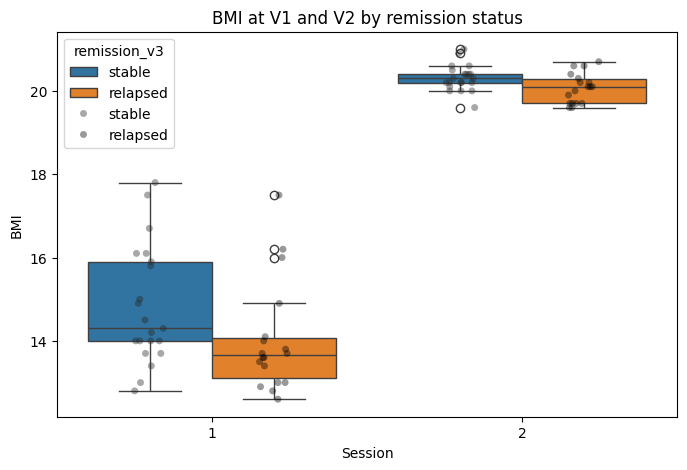

In [41]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df_merged_long,x="session",y="BMI",hue="remission_v3",)

sns.stripplot(data=df_merged_long,x="session",y="BMI",hue="remission_v3",dodge=True,color="black",alpha=0.4)

plt.ylabel("BMI")
plt.xlabel("Session")
plt.title("BMI at V1 and V2 by remission status")
plt.show()

In [42]:
from scipy.stats import shapiro,levene,ttest_ind,mannwhitneyu
import pandas as pd

results=[]
for ses in [1,2]:
    df_ses=df_merged_long[(df_merged_long["session"].astype(int)==ses)&(df_merged_long["irm_yn"]==1)].copy()
    stable=df_ses.loc[df_ses["remission_v3"]=="stable","BMI"].dropna(); relapsed=df_ses.loc[df_ses["remission_v3"]=="relapsed","BMI"].dropna()
    sh_stable=shapiro(stable); sh_relapsed=shapiro(relapsed); lev=levene(stable,relapsed); welch=ttest_ind(stable,relapsed,equal_var=False); student=ttest_ind(stable,relapsed,equal_var=True); mw=mannwhitneyu(stable,relapsed,alternative="two-sided")
    results.append({"session":ses,"n_stable":len(stable),"n_relapsed":len(relapsed),"stable_mean":stable.mean(),"relapsed_mean":relapsed.mean(),"stable_median":stable.median(),"relapsed_median":relapsed.median(),"shapiro_stable_p":sh_stable.pvalue,"shapiro_relapsed_p":sh_relapsed.pvalue,"levene_p":lev.pvalue,"student_t_p":student.pvalue,"welch_t_p":welch.pvalue,"mannwhitney_p":mw.pvalue})
results_df=pd.DataFrame(results)
results_df

,session,n_stable,n_relapsed,stable_mean,relapsed_mean,stable_median,relapsed_median,shapiro_stable_p,shapiro_relapsed_p,levene_p,student_t_p,welch_t_p,mannwhitney_p
0,1,21,18,14.828571,14.016667,14.3,13.65,0.133059,0.003785,0.437404,0.074284,0.072751,0.028688
1,2,21,18,20.309524,20.066667,20.3,20.10,0.431366,0.153472,0.366460,0.029742,0.031930,0.042658


## Calculate tissues globalV all

In [43]:
base_dir=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm")
rows=[]
xml_files=sorted(base_dir.glob("sub-*/ses-*/anat/report/cat_*.xml"))
for xml_file in xml_files:
    try:
        subject=int(re.search(r"sub-(\d+)",str(xml_file)).group(1)); session=1 if "ses-V1" in str(xml_file) else 2
        root=ET.parse(xml_file).getroot(); elem=root.find(".//subjectmeasures/vol_abs_CGW")
        if elem is None or elem.text is None: print(f"[MISS] vol_abs_CGW not found in {xml_file}"); continue
        vals=[float(x) for x in elem.text.strip().strip("[]").split()]
        rows.append({"subject":subject,"session":session,"CSF_ml":vals[0],"GM_ml":vals[1],"WM_ml":vals[2]})
    except Exception as e: print(f"[ERROR] {xml_file}: {e}")
df_global_tissues=pd.DataFrame(rows).sort_values(["subject","session"]).reset_index(drop=True)
print(df_global_tissues.head())
print("Shape:",df_global_tissues.shape)

   subject  session      CSF_ml       GM_ml       WM_ml
0        1        1  203.250991  599.516662  468.922343
1        1        2  207.223019  597.081626  466.199626
2        2        1  155.220826  610.410991  372.295385
3        2        2  158.262878  605.630362  371.369538
4        3        1  169.517172  751.483589  608.816824
Shape: (171, 5)


In [46]:
df_merged_tissues_all=merge_volume(df_merged_all, df_global_tissues)
df_merged_tissues_all

,subject,session,CSF_ml,GM_ml,WM_ml,TIV_ml,study_id,redcap_event_name,age,soustype,...,indif_d5,delay_discounting_complete,habits_yn,group,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total
0,1,1,203.250991,599.516662,468.922343,1271.689995,13.0,visite_1_arm_2,33.0,NaN,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
1,1,2,207.223019,597.081626,466.199626,1270.504271,13.0,visite_2_arm_2,33.0,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
2,2,1,155.220826,610.410991,372.295385,1137.927202,17.0,visite_1_arm_2,47.0,NaN,...,77.0,2.0,1.0,HC,19.8,NaN,NaN,NaN,NaN,6.0
3,2,2,158.262878,605.630362,371.369538,1135.262778,17.0,visite_2_arm_2,47.0,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
4,3,1,169.517172,751.483589,608.816824,1529.817586,50.0,visite_1_arm_2,27.0,NaN,...,69.0,2.0,1.0,HC,22.9,NaN,NaN,NaN,NaN,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
166,98,1,244.871290,665.477616,524.323912,1434.672818,241.0,visite_1_arm_1,24.0,1.0,...,80.0,2.0,1.0,AN,14.0,NaN,NaN,12.000000,12.000000,103.0
167,99,1,234.592633,575.479884,404.737961,1214.810478,242.0,visite_1_arm_1,32.0,1.0,...,21.0,2.0,1.0,AN,16.2,NaN,NaN,11.000000,21.000000,22.0
168,100,1,259.145488,584.002217,471.504707,1314.652412,244.0,visite_1_arm_1,54.0,1.0,...,43.0,2.0,1.0,AN,14.0,NaN,NaN,35.083333,18.916667,114.0
169,101,1,261.082695,584.264491,432.884447,1278.231633,87.0,visite_1_arm_1,31.0,1.0,...,62.0,2.0,1.0,AN,12.9,NaN,NaN,5.750000,25.250000,63.0


## outlier checking

In [47]:
columns_to_check = ['CSF_ml', 'GM_ml', 'WM_ml', 'TIV_ml']

z_scores = np.abs(stats.zscore(df_merged_tissues_all[columns_to_check]))

outlier_mask = (z_scores > 3).any(axis=1)

outliers = df_merged_tissues_all.loc[outlier_mask, 'subject'].unique().tolist()

print(f"Subjects with outlier global volumes: {outliers}")

Subjects with outlier global volumes: [28]


## Calculate tissues globalV long

In [48]:
base_dir=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long")
rows=[]
xml_files=sorted(base_dir.glob("sub-*/ses-*/anat/report/cat_*.xml"))
for xml_file in xml_files:
    try:
        subject=int(re.search(r"sub-(\d+)",str(xml_file)).group(1)); session=1 if "ses-V1" in str(xml_file) else 2
        root=ET.parse(xml_file).getroot(); elem=root.find(".//subjectmeasures/vol_abs_CGW")
        if elem is None or elem.text is None: print(f"[MISS] vol_abs_CGW not found in {xml_file}"); continue
        vals=[float(x) for x in elem.text.strip().strip("[]").split()]
        rows.append({"subject":subject,"session":session,"CSF_ml":vals[0],"GM_ml":vals[1],"WM_ml":vals[2]})
    except Exception as e: print(f"[ERROR] {xml_file}: {e}")
df_global_tissues_long=pd.DataFrame(rows).sort_values(["subject","session"]).reset_index(drop=True)
print(df_global_tissues_long.head())
print("Shape:",df_global_tissues_long.shape)

   subject  session      CSF_ml       GM_ml       WM_ml
0        1        1  242.798179  572.301277  463.688696
1        1        2  243.392746  574.564435  460.508688
2        2        1  201.144663  573.150014  372.682683
3        2        2  206.104801  572.062011  368.460557
4        3        1  222.624583  706.287440  603.350272
Shape: (138, 5)


In [51]:
df_merged_tissues_long=merge_volume(df_merged_all, df_global_tissues_long)
df_merged_tissues_long

,subject,session,CSF_ml,GM_ml,WM_ml,TIV_ml,study_id,redcap_event_name,age,soustype,...,indif_d5,delay_discounting_complete,habits_yn,group,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total
0,1,1,242.798179,572.301277,463.688696,1271.689995,13,visite_1_arm_2,33.0,NaN,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
1,1,2,243.392746,574.564435,460.508688,1270.504271,13,visite_2_arm_2,33.0,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
2,2,1,201.144663,573.150014,372.682683,1137.927202,17,visite_1_arm_2,47.0,NaN,...,77.0,2.0,1.0,HC,19.8,NaN,NaN,NaN,NaN,6.0
3,2,2,206.104801,572.062011,368.460557,1135.262778,17,visite_2_arm_2,47.0,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
4,3,1,222.624583,706.287440,603.350272,1529.817586,50,visite_1_arm_2,27.0,NaN,...,69.0,2.0,1.0,HC,22.9,NaN,NaN,NaN,NaN,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
133,89,2,258.243619,621.644646,454.308083,1354.162630,220,visite_2_arm_1,19.0,NaN,...,21.0,2.0,1.0,AN,20.7,NaN,NaN,5.416667,13.583333,109.0
134,92,1,289.626701,523.604683,416.285551,1213.193735,225,visite_1_arm_1,45.0,1.0,...,43.0,2.0,1.0,AN,16.2,relapsed,NaN,2.583333,42.416667,16.0
135,92,2,280.447541,535.344583,412.429201,1225.036111,225,visite_2_arm_1,45.0,NaN,...,39.0,2.0,1.0,AN,20.1,relapsed,NaN,2.583333,42.416667,11.0
136,94,1,288.847824,585.881952,490.096572,1336.099685,233,visite_1_arm_1,33.0,2.0,...,34.0,2.0,1.0,AN,14.4,NaN,NaN,13.750000,19.250000,88.0


## Calculate ROI-based all

In [67]:
base_dir=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm")
xml_files=sorted(base_dir.glob("sub-*/ses-*/anat/label/catROI_*.xml"))
rows=[]
for xml_file in xml_files:
    try:
        subject=int(re.search(r"sub-(\d+)",str(xml_file)).group(1)); session=1 if "ses-V1" in str(xml_file) else 2; root=ET.parse(xml_file).getroot()
        for atlas in root:
            atlas_name=atlas.tag; names_elem=atlas.find("names"); data_elem=atlas.find("data")
            if names_elem is None or data_elem is None: continue
            roi_names=[item.text for item in names_elem.findall("item")]; metrics={}
            for child in data_elem:
                metric_name=child.tag; txt=child.text.strip().strip("[]"); vals=[float(x) for x in re.split(r"[;\s]+",txt) if x]; metrics[metric_name]=vals
            n_roi=len(roi_names)
            for i,roi_name in enumerate(roi_names):
                row={"subject":subject,"session":session,"atlas":atlas_name,"roi":roi_name}
                for metric_name,vals in metrics.items(): row[metric_name]=vals[i] if i<len(vals) else None
                rows.append(row)
    except Exception as e: print(f"[ERROR] {xml_file}: {e}")
df_catroi=pd.DataFrame(rows).sort_values(["subject","session","atlas","roi"]).reset_index(drop=True)
print(df_catroi.head())
print("Shape:",df_catroi.shape)

   subject  session  atlas             roi       Vgm       Vwm  Vcsf
0        1        1  cobra         lAlveus  0.311448  0.007667   NaN
1        1        1  cobra            lAmy  1.140959  0.007082   NaN
2        1        1  cobra   lAntCerebLIII  0.712609  0.092847   NaN
3        1        1  cobra    lAntCerebLIV  1.804611  0.493930   NaN
4        1        1  cobra  lAntCerebLI_II  0.072757  0.006380   NaN
Shape: (52668, 7)


In [70]:
df_roi_wide=df_catroi.pivot_table(index=["subject","session"],columns="roi",values="Vgm").reset_index()
roi_cols=df_roi_wide.columns.difference(["subject","session"])
z_scores=np.abs(stats.zscore(df_roi_wide[roi_cols],nan_policy="omit"))
outlier_mask=(z_scores>3).any(axis=1)
outliers=df_roi_wide.loc[outlier_mask,["subject","session"]]
outlier_info=[]
for col in roi_cols:
    z=(df_roi_wide[col]-df_roi_wide[col].mean())/df_roi_wide[col].std()
    mask=np.abs(z)>3
    for idx in df_roi_wide[mask].index: outlier_info.append({"subject":df_roi_wide.loc[idx,"subject"],"session":df_roi_wide.loc[idx,"session"],"roi":col,"z_score":z.loc[idx]})
outlier_df=pd.DataFrame(outlier_info)
outlier_df.roi.value_counts().head(60)

roi
Left Cerebellum White Matter           3
Left CrusII                            3
Left SOG superior occipital gyrus      3
Right Ventral DC                       3
lSupPostCerebCII                       3
rAlveus                                3
rAntCerebWM                            3
rCA2_3                                 3
rHCA1                                  3
Left Amygdala                          2
Left CO central operculum              2
Left OFuG occipital fusiform gyrus     2
Left PO parietal operculum             2
Left PT planum temporale               2
Left Pallidum                          2
Left SFG superior frontal gyrus        2
Left TTG transverse temporal gyrus     2
Right Cerebellum White Matter          2
Right ITG inferior temporal gyrus      2
Right PO parietal operculum            2
Right Pallidum                         2
Right PoG postcentral gyrus            2
Right SFG superior frontal gyrus       2
Right TTG transverse temporal gyrus    2
Right VIIb  

In [71]:
df_merged_roi_all=merge_volume(df_merged_all, df_catroi)
df_merged_roi_all

,subject,session,atlas,roi,Vgm,Vwm,Vcsf,TIV_ml,study_id,redcap_event_name,...,indif_d5,delay_discounting_complete,habits_yn,group,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total
0,1,1,cobra,lAlveus,0.311448,0.007667,NaN,1271.689995,13.0,visite_1_arm_2,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
1,1,1,cobra,lAmy,1.140959,0.007082,NaN,1271.689995,13.0,visite_1_arm_2,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
2,1,1,cobra,lAntCerebLIII,0.712609,0.092847,NaN,1271.689995,13.0,visite_1_arm_2,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
3,1,1,cobra,lAntCerebLIV,1.804611,0.493930,NaN,1271.689995,13.0,visite_1_arm_2,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
4,1,1,cobra,lAntCerebLI_II,0.072757,0.006380,NaN,1271.689995,13.0,visite_1_arm_2,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52663,102,1,thalamus,rMedio_Dorsal,0.674801,NaN,NaN,1376.544389,246.0,visite_1_arm_1,...,0.0,2.0,1.0,AN,15.2,NaN,NaN,12.166667,35.833333,125.0
52664,102,1,thalamus,rPulvinar,0.788465,NaN,NaN,1376.544389,246.0,visite_1_arm_1,...,0.0,2.0,1.0,AN,15.2,NaN,NaN,12.166667,35.833333,125.0
52665,102,1,thalamus,rVentral_Anterior,0.594710,NaN,NaN,1376.544389,246.0,visite_1_arm_1,...,0.0,2.0,1.0,AN,15.2,NaN,NaN,12.166667,35.833333,125.0
52666,102,1,thalamus,rVentral_Latero_Dorsal,0.690496,NaN,NaN,1376.544389,246.0,visite_1_arm_1,...,0.0,2.0,1.0,AN,15.2,NaN,NaN,12.166667,35.833333,125.0


## Calculate ROI-based long

In [72]:
base_dir=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long")
xml_files=sorted(base_dir.glob("sub-*/ses-*/anat/label/catROI_*.xml"))
rows=[]
for xml_file in xml_files:
    try:
        subject=int(re.search(r"sub-(\d+)",str(xml_file)).group(1)); session=int(re.search(r"ses-V(\d+)",str(xml_file)).group(1)); root=ET.parse(xml_file).getroot()
        for atlas in root:
            atlas_name=atlas.tag; names_elem=atlas.find("names"); data_elem=atlas.find("data")
            if names_elem is None or data_elem is None: continue
            roi_names=[item.text for item in names_elem.findall("item")]; metrics={}
            for child in data_elem:
                metric_name=child.tag; txt=child.text.strip().strip("[]"); vals=[float(x) for x in re.split(r"[;\s]+",txt) if x]; metrics[metric_name]=vals
            for i,roi_name in enumerate(roi_names):
                row={"subject":subject,"session":session,"atlas":atlas_name,"roi":roi_name}
                for metric_name,vals in metrics.items(): row[metric_name]=vals[i] if i<len(vals) else None
                rows.append(row)
    except Exception as e: print(f"[ERROR] {xml_file}: {e}")
df_catroi_long=pd.DataFrame(rows).sort_values(["subject","session","atlas","roi"]).reset_index(drop=True)
print(df_catroi_long.head())
print("Shape:",df_catroi_long.shape)

   subject  session  atlas             roi       Vgm       Vwm  Vcsf
0        1        1  cobra         lAlveus  0.310233  0.016373   NaN
1        1        1  cobra            lAmy  1.117585  0.005310   NaN
2        1        1  cobra   lAntCerebLIII  0.679912  0.130499   NaN
3        1        1  cobra    lAntCerebLIV  1.750038  0.537477   NaN
4        1        1  cobra  lAntCerebLI_II  0.058636  0.009369   NaN
Shape: (42504, 7)


In [75]:
df_merged_roi_long=merge_volume(redcap_data_filtered, df_catroi_long)
df_merged_roi_long

,subject,session,atlas,roi,Vgm,Vwm,Vcsf,study_id,redcap_event_name,age,...,indif_d5,delay_discounting_complete,habits_yn,group,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total
0,1,1,cobra,lAlveus,0.310233,0.016373,NaN,13,visite_1_arm_2,33.0,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
1,1,1,cobra,lAmy,1.117585,0.005310,NaN,13,visite_1_arm_2,33.0,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
2,1,1,cobra,lAntCerebLIII,0.679912,0.130499,NaN,13,visite_1_arm_2,33.0,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
3,1,1,cobra,lAntCerebLIV,1.750038,0.537477,NaN,13,visite_1_arm_2,33.0,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
4,1,1,cobra,lAntCerebLI_II,0.058636,0.009369,NaN,13,visite_1_arm_2,33.0,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42499,94,2,thalamus,rMedio_Dorsal,0.933173,NaN,NaN,233,visite_2_arm_1,33.0,...,21.0,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0
42500,94,2,thalamus,rPulvinar,0.866891,NaN,NaN,233,visite_2_arm_1,33.0,...,21.0,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0
42501,94,2,thalamus,rVentral_Anterior,0.956511,NaN,NaN,233,visite_2_arm_1,33.0,...,21.0,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0
42502,94,2,thalamus,rVentral_Latero_Dorsal,0.770055,NaN,NaN,233,visite_2_arm_1,33.0,...,21.0,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0


In [76]:
df_merged_roi_long=merge_volume(df_tiv_long, df_merged_roi_long)
df_merged_roi_long

,subject,session,atlas,roi,Vgm,Vwm,Vcsf,study_id,redcap_event_name,age,...,delay_discounting_complete,habits_yn,group,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total,TIV_ml
0,1,1,cobra,lAlveus,0.310233,0.016373,NaN,13,visite_1_arm_2,33.0,...,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0,1278.788153
1,1,1,cobra,lAmy,1.117585,0.005310,NaN,13,visite_1_arm_2,33.0,...,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0,1278.788153
2,1,1,cobra,lAntCerebLIII,0.679912,0.130499,NaN,13,visite_1_arm_2,33.0,...,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0,1278.788153
3,1,1,cobra,lAntCerebLIV,1.750038,0.537477,NaN,13,visite_1_arm_2,33.0,...,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0,1278.788153
4,1,1,cobra,lAntCerebLI_II,0.058636,0.009369,NaN,13,visite_1_arm_2,33.0,...,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0,1278.788153
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42499,94,2,thalamus,rMedio_Dorsal,0.933173,NaN,NaN,233,visite_2_arm_1,33.0,...,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0,1362.329347
42500,94,2,thalamus,rPulvinar,0.866891,NaN,NaN,233,visite_2_arm_1,33.0,...,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0,1362.329347
42501,94,2,thalamus,rVentral_Anterior,0.956511,NaN,NaN,233,visite_2_arm_1,33.0,...,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0,1362.329347
42502,94,2,thalamus,rVentral_Latero_Dorsal,0.770055,NaN,NaN,233,visite_2_arm_1,33.0,...,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0,1362.329347


#### NMH16

In [82]:
from scipy.stats import shapiro,levene,ttest_ind,mannwhitneyu
import pandas as pd

variables=["GM_ml","WM_ml","CSF_ml","TIV_ml"]
results=[]
for ses in [1,2]:
    df_ses=df_merged_tissues_long[df_merged_tissues_long["session"].astype(int)==ses].copy()
    for var in variables:
        an=df_ses.loc[df_ses["group"]=="AN",var].dropna(); hc=df_ses.loc[df_ses["group"]=="HC",var].dropna()
        if len(an)<3 or len(hc)<3: continue
        sh_an=shapiro(an); sh_hc=shapiro(hc); lev=levene(an,hc); student=ttest_ind(an,hc,equal_var=True); welch=ttest_ind(an,hc,equal_var=False); mw=mannwhitneyu(an,hc,alternative="two-sided"); normal=(sh_an.pvalue>0.05) and (sh_hc.pvalue>0.05); equal_var=lev.pvalue>0.05
        if normal and equal_var: recommended_test="Student t-test"; stat=student.statistic; p=student.pvalue
        elif normal and not equal_var: recommended_test="Welch t-test"; stat=welch.statistic; p=welch.pvalue
        else: recommended_test="Mann-Whitney"; stat=mw.statistic; p=mw.pvalue
        results.append({"session":ses,"variable":var,"n_AN":len(an),"n_HC":len(hc),"AN_mean":an.mean(),"AN_sd":an.std(ddof=1),"HC_mean":hc.mean(),"HC_sd":hc.std(ddof=1),"AN_median":an.median(),"HC_median":hc.median(),"recommended_test":recommended_test,"statistic":stat,"p_value":p,"shapiro_AN_p":sh_an.pvalue,"shapiro_HC_p":sh_hc.pvalue,"levene_p":lev.pvalue,"student_t":student.statistic,"student_p":student.pvalue,"welch_t":welch.statistic,"welch_p":welch.pvalue,"mannwhitney_U":mw.statistic,"mannwhitney_p":mw.pvalue})
results_tissue=pd.DataFrame(results)
results_tissue

,session,variable,n_AN,n_HC,AN_mean,AN_sd,HC_mean,HC_sd,AN_median,HC_median,...,p_value,shapiro_AN_p,shapiro_HC_p,levene_p,student_t,student_p,welch_t,welch_p,mannwhitney_U,mannwhitney_p
0,1,GM_ml,41,28,602.306651,39.743866,637.125870,54.833794,602.363282,633.539928,...,3.185261e-03,0.696590,0.753858,0.167711,-3.059650,3.185261e-03,-2.882548,5.984753e-03,346.0,5.435112e-03
1,1,WM_ml,41,28,491.588192,41.504641,485.894749,49.814017,490.096572,490.476803,...,6.078068e-01,0.556308,0.064844,0.627818,0.515635,6.078068e-01,0.498127,6.205386e-01,622.0,5.616117e-01
2,1,CSF_ml,41,28,299.284964,40.674370,245.099661,29.379968,298.075088,242.310401,...,7.324735e-08,0.488873,0.405595,0.109140,6.047797,7.324735e-08,6.422509,1.633660e-08,1012.0,8.979850e-08
3,1,TIV_ml,41,28,1379.327936,96.957054,1365.784290,104.926101,1365.624327,1355.884675,...,5.834068e-01,0.475184,0.962344,0.779831,0.551088,5.834068e-01,0.542841,5.894309e-01,621.0,5.698793e-01
4,2,GM_ml,41,28,625.048595,41.086240,640.592477,53.884224,620.227186,632.887043,...,1.788327e-01,0.675529,0.742875,0.190202,-1.358592,1.788327e-01,-1.291431,2.027868e-01,467.0,1.931119e-01
5,2,WM_ml,41,28,491.726573,43.012103,485.265995,50.743944,488.646838,488.920914,...,5.710122e-01,0.606534,0.081893,0.771121,0.569365,5.710122e-01,0.551793,5.834720e-01,623.0,5.534025e-01
6,2,CSF_ml,41,28,270.487342,38.590004,242.723054,24.584626,265.672662,243.517456,...,5.182300e-04,0.430597,0.711323,0.046974,3.365025,1.270068e-03,3.648540,5.182300e-04,852.0,6.962648e-04
7,2,TIV_ml,41,28,1398.645909,96.917842,1364.562582,103.687244,1378.504036,1358.036670,...,1.678026e-01,0.325480,0.969152,0.817858,1.394403,1.678026e-01,1.376540,1.741833e-01,687.0,1.692095e-01


In [83]:
from scipy.stats import shapiro,levene,ttest_ind,mannwhitneyu
import pandas as pd

variables=["GM_ml","WM_ml","CSF_ml","TIV_ml"]
results=[]
df_test=df_merged_tissues_long[(df_merged_tissues_long["group"]=="AN")&(df_merged_tissues_long["remission_v3"].isin(["stable","relapsed"]))].copy()
for ses in [1,2]:
    df_ses=df_test[df_test["session"].astype(int)==ses].copy()
    for var in variables:
        stable=df_ses.loc[df_ses["remission_v3"]=="stable",var].dropna(); relapsed=df_ses.loc[df_ses["remission_v3"]=="relapsed",var].dropna()
        if len(stable)<3 or len(relapsed)<3: continue
        sh_stable=shapiro(stable); sh_relapsed=shapiro(relapsed); lev=levene(stable,relapsed); student=ttest_ind(stable,relapsed,equal_var=True); welch=ttest_ind(stable,relapsed,equal_var=False); mw=mannwhitneyu(stable,relapsed,alternative="two-sided"); normal=sh_stable.pvalue>0.05 and sh_relapsed.pvalue>0.05; equal_var=lev.pvalue>0.05
        if normal and equal_var: recommended_test="Student t-test"; stat=student.statistic; p=student.pvalue
        elif normal and not equal_var: recommended_test="Welch t-test"; stat=welch.statistic; p=welch.pvalue
        else: recommended_test="Mann-Whitney"; stat=mw.statistic; p=mw.pvalue
        results.append({"session":ses,"variable":var,"n_stable":len(stable),"n_relapsed":len(relapsed),"stable_mean":stable.mean(),"stable_sd":stable.std(ddof=1),"relapsed_mean":relapsed.mean(),"relapsed_sd":relapsed.std(ddof=1),"stable_median":stable.median(),"relapsed_median":relapsed.median(),"recommended_test":recommended_test,"statistic":stat,"p_value":p,"student_p":student.pvalue,"welch_p":welch.pvalue,"mannwhitney_p":mw.pvalue})
results_tissue_remission=pd.DataFrame(results)
results_tissue_remission

,session,variable,n_stable,n_relapsed,stable_mean,stable_sd,relapsed_mean,relapsed_sd,stable_median,relapsed_median,recommended_test,statistic,p_value,student_p,welch_p,mannwhitney_p
0,1,GM_ml,21,18,608.133912,36.085179,599.151568,44.432237,607.845762,597.413029,Student t-test,0.696730,0.490327,0.490327,0.497837,0.507947
1,1,WM_ml,21,18,490.158966,33.666995,495.254306,51.312097,480.984830,494.923253,Student t-test,-0.371590,0.712318,0.712318,0.721443,0.745956
2,1,CSF_ml,21,18,292.001591,47.653027,306.159121,31.728701,292.104083,303.757675,Student t-test,-1.072153,0.290595,0.290595,0.276563,0.199907
3,1,TIV_ml,21,18,1384.226158,92.745014,1378.426296,108.390068,1364.566910,1380.102977,Student t-test,0.180137,0.858028,0.858028,0.859827,0.966293
4,2,GM_ml,21,18,626.233496,33.138529,625.849951,51.000716,617.780083,627.915636,Welch t-test,0.027340,0.978380,0.977628,0.978380,0.988761
5,2,WM_ml,21,18,489.710455,36.362267,496.328611,51.837499,477.852370,492.220735,Student t-test,-0.466667,0.643474,0.643474,0.652919,0.682913
6,2,CSF_ml,21,18,269.389080,48.567606,271.668301,26.561301,262.442718,266.605628,Welch t-test,-0.185162,0.854276,0.860131,0.854276,0.622008
7,2,TIV_ml,21,18,1397.468842,90.501258,1405.118376,110.324040,1378.504036,1398.887451,Student t-test,-0.237916,0.813259,0.813259,0.816226,0.745956


#### NMH18

In [85]:
exclude_cols = ["subject", "study_id", "session","irm_yn","soustype"]
clinical_cols = [c for c in df_merged_long.select_dtypes(include=[np.number]).columns if c not in exclude_cols]

rows = []
for var in clinical_cols:
    for grp in sorted(df_merged_long["group"].dropna().unique()):
        for ses in sorted(df_merged_long["session"].dropna().unique()):
            sub = df_merged_long.loc[(df_merged_long["group"] == grp) &(df_merged_long["session"] == ses),var].dropna()
            rows.append({"variable": var,"group": grp,"session": ses,"mean_sd": f"{sub.mean():.2f} ± {sub.std():.2f}" if len(sub) > 0 else np.nan})

desc_table = pd.DataFrame(rows).pivot_table(index="variable",columns=["group", "session"],values="mean_sd",aggfunc="first")

desc_table.columns = [f"{grp}_V{ses}" for grp, ses in desc_table.columns]
desc_table

,AN_V1,AN_V2,HC_V1,HC_V2
variable,,,,
BMI,14.40 ± 1.43,20.20 ± 0.36,21.54 ± 1.89,NaN
TIV_ml,1393.18 ± 89.81,1387.26 ± 88.35,1368.12 ± 102.52,1368.58 ± 103.31
age,28.73 ± 10.89,28.73 ± 10.89,26.79 ± 7.08,26.79 ± 7.08
age_at_onset,18.99 ± 8.26,18.99 ± 8.26,NaN,NaN
brixton_score,12.22 ± 7.09,10.20 ± 6.67,12.50 ± 5.12,NaN
ctq_emotionnel,10.05 ± 4.59,9.98 ± 4.67,8.43 ± 3.65,NaN
ctq_negemo,11.37 ± 5.01,11.15 ± 4.81,9.57 ± 4.07,NaN
ctq_negphy,8.10 ± 2.69,7.76 ± 2.74,6.29 ± 1.90,NaN
ctq_physique,5.76 ± 1.76,5.63 ± 1.83,6.14 ± 2.01,NaN


#### NMH19

In [86]:
exclude_cols = ["subject", "study_id", "session","irm_yn","soustype"]
clinical_cols = [c for c in df_merged_long.select_dtypes(include=[np.number]).columns if c not in exclude_cols]

rows = []
for var in clinical_cols:
    for grp in sorted(df_merged_long["remission_v3"].dropna().unique()):
        for ses in sorted(df_merged_long["session"].dropna().unique()):
            sub = df_merged_long.loc[(df_merged_long["remission_v3"] == grp) &(df_merged_long["session"] == ses),var].dropna()

            rows.append({"variable": var,"remission_v3": grp,"session": ses,"mean_sd": f"{sub.mean():.2f} ± {sub.std():.2f}" if len(sub) > 0 else np.nan})

desc_table = pd.DataFrame(rows).pivot_table(index="variable",columns=["remission_v3", "session"], values="mean_sd",aggfunc="first")

desc_table.columns = [f"{grp}_V{ses}" for grp, ses in desc_table.columns]
desc_table

,relapsed_V1,relapsed_V2,stable_V1,stable_V2
variable,,,,
BMI,14.02 ± 1.32,20.07 ± 0.36,14.83 ± 1.42,20.31 ± 0.31
TIV_ml,1400.56 ± 109.88,1393.85 ± 107.33,1390.29 ± 75.33,1385.33 ± 74.87
age,30.17 ± 11.65,30.17 ± 11.65,27.76 ± 10.63,27.76 ± 10.63
age_at_onset,20.12 ± 9.29,20.12 ± 9.29,18.26 ± 7.73,18.26 ± 7.73
brixton_score,12.28 ± 7.89,10.22 ± 6.93,12.29 ± 6.89,10.38 ± 6.87
ctq_emotionnel,10.17 ± 4.66,10.00 ± 5.01,10.10 ± 4.78,10.05 ± 4.71
ctq_negemo,11.56 ± 5.34,11.61 ± 5.47,11.29 ± 4.97,10.81 ± 4.40
ctq_negphy,7.50 ± 2.55,7.78 ± 2.67,8.76 ± 2.77,7.57 ± 2.56
ctq_physique,6.00 ± 2.28,5.78 ± 2.58,5.62 ± 1.28,5.52 ± 0.98


## Calculate GM voxel-wise all

In [94]:
root_AN_all_s=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_AN/GM/smooth")
root_HC_all_s=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_HC/GM/smooth")
def global_gm_volume_ml(nifti_path:Path)->float:
    img=nib.load(str(nifti_path)); data=img.get_fdata(); voxel_vol_mm3=np.prod(img.header.get_zooms()[:3]); gm_total_mm3=np.nansum(data)*voxel_vol_mm3; return float(gm_total_mm3/1000.0)
def parse_sub_ses(fname:str):
    sub=re.search(r"r?sub-(\d+)",fname); ses=re.search(r"ses-(V\d+)",fname)
    if sub is None or ses is None: raise ValueError(f"Could not parse subject/session from: {fname}")
    subject=int(sub.group(1)); session=1 if ses.group(1)=="V1" else 2; return subject,session
def build_df_from_root(root:Path,group_label:str):
    imgs=sorted(root.rglob("s8mwp1*.nii")); print(f"{group_label}: found {len(imgs)} images"); rows=[]
    for p in imgs:
        subject,session=parse_sub_ses(p.name); rows.append({"subject":subject,"session":session,"group":group_label,"GM_total_ml":global_gm_volume_ml(p)})
    return pd.DataFrame(rows)

In [95]:
df_AN_all_s = build_df_from_root(root_AN_all_s, "AN")
df_HC_all_s = build_df_from_root(root_HC_all_s, "HC")

df_all_voxels_GMs = pd.concat([df_AN_all_s, df_HC_all_s], ignore_index=True)
df_all_voxels_GMs = df_all_voxels_GMs.sort_values(["group", "subject", "session"]).reset_index(drop=True)
df_all_voxels_GMs.head()

AN: found 111 images
HC: found 58 images


,subject,session,group,GM_total_ml
0,5,1,AN,675.429782
1,6,1,AN,624.740206
2,6,2,AN,642.605519
3,7,1,AN,632.554105
4,7,2,AN,634.832962


In [96]:
root_AN_all_s=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_AN/GM/smooth")
root_HC_all_s=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_HC/GM/smooth")
from nilearn.image import load_img,math_img
from nilearn.glm.second_level import SecondLevelModel
def collect_images(root,group_label):
    rows=[]
    for p in sorted(root.glob("s8mwp1sub-*_ses-*_T1w.nii*")):
        subject,session=parse_sub_ses(p.name); rows.append({"subject":subject,"session":session,"group":group_label,"path":str(p)})
    return pd.DataFrame(rows)
df_AN_all_sv=collect_images(root_AN_all_s,"AN")
df_HC_all_sv=collect_images(root_HC_all_s,"HC")
df_whole_sv=pd.concat([df_AN_all_sv,df_HC_all_sv],ignore_index=True)
print(df_whole_sv.head())

   subject  session group                                               path
0        5        1    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
1        6        1    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
2        6        2    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
3        7        1    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
4        7        2    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...


In [97]:
df_all_voxels_GMs.to_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/cat12_gm_voxel_total.csv", index=False)

In [98]:
df_all_voxels_GMs=pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/cat12_gm_voxel_total.csv")

## Calculate GM voxel-wise long

In [99]:
root_AN_s=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long_AN/GM/smooth")
root_HC_s=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long_HC/GM/smooth")
def global_gm_volume_ml(nifti_path:Path)->float:
    img=nib.load(str(nifti_path)); data=img.get_fdata(); voxel_vol_mm3=np.prod(img.header.get_zooms()[:3]); gm_total_mm3=np.nansum(data)*voxel_vol_mm3; return float(gm_total_mm3/1000.0)
def parse_sub_ses(fname:str):
    sub=re.search(r"r?sub-(\d+)",fname); ses=re.search(r"ses-(V\d+)",fname)
    if sub is None or ses is None: raise ValueError(f"Could not parse subject/session from: {fname}")
    subject=int(sub.group(1)); session=1 if ses.group(1)=="V1" else 2; return subject,session
def build_df_from_root(root:Path,group_label:str):
    imgs=sorted(root.rglob("s8mwp1*.nii")); print(f"{group_label}: found {len(imgs)} images"); rows=[]
    for p in imgs:
        subject,session=parse_sub_ses(p.name); rows.append({"subject":subject,"session":session,"group":group_label,"GM_total_ml":global_gm_volume_ml(p)})
    return pd.DataFrame(rows)
df_AN_s=build_df_from_root(root_AN_s,"AN")
df_HC_s=build_df_from_root(root_HC_s,"HC")
df_long_s=pd.concat([df_AN_s,df_HC_s],ignore_index=True)
df_long_s=df_long_s.sort_values(["group","subject","session"]).reset_index(drop=True)
df_long_s.head()

AN: found 82 images
HC: found 56 images


,subject,session,group,GM_total_ml
0,6,1,AN,601.813599
1,6,2,AN,607.505343
2,7,1,AN,602.512958
3,7,2,AN,609.319323
4,10,1,AN,677.802840


In [100]:
df_long_s.to_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/cat12_gm_voxel_long.csv", index=False)

In [101]:
df_long_s=pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/cat12_gm_voxel_long.csv")

In [102]:
def parse_sub_ses(fname:str):
    m_sub=re.search(r"sub-([A-Za-z0-9]+)",fname)
    if not m_sub: raise ValueError(f"Could not parse subject from: {fname}")
    subject=int(m_sub.group(1)); m_ses=re.search(r"ses-([A-Za-z0-9]+)",fname)
    if not m_ses: raise ValueError(f"Could not parse session from: {fname}")
    ses_raw=m_ses.group(1); ses_map={"V1":1,"V2":2,"v1":1,"v2":2}
    if ses_raw in ses_map: session=ses_map[ses_raw]
    else:
        try: session=int(ses_raw)
        except ValueError: raise ValueError(f"Unknown session label '{ses_raw}' in: {fname}")
    return subject,session

In [103]:
root_AN_s=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long_AN/GM/smooth")
root_HC_s=Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long_HC/GM/smooth")
from nilearn.image import load_img,math_img
from nilearn.glm.second_level import SecondLevelModel
def collect_images(root,group_label):
    rows=[]
    for p in sorted(root.glob("s8mwp1rsub-*_ses-*_T1w.nii*")):
        subject,session=parse_sub_ses(p.name); rows.append({"subject":subject,"session":session,"group":group_label,"path":str(p)})
    return pd.DataFrame(rows)
df_AN_sv=collect_images(root_AN_s,"AN")
df_HC_sv=collect_images(root_HC_s,"HC")
df_all_sv=pd.concat([df_AN_sv,df_HC_sv],ignore_index=True)
print(df_all_sv.head())

   subject  session group                                               path
0        6        1    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
1        6        2    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
2        7        1    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
3        7        2    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
4       10        1    AN  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...


## Tests global

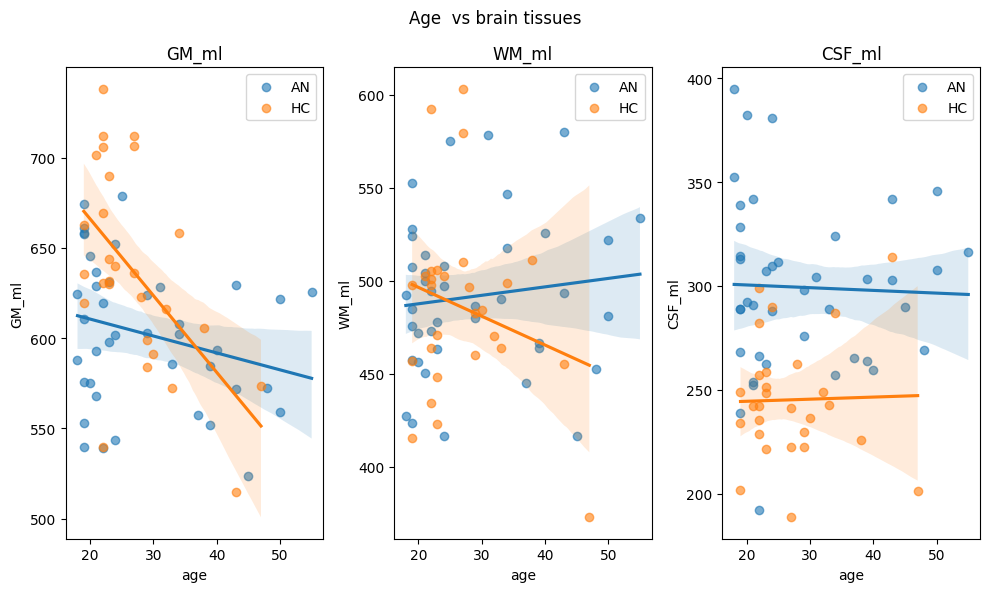

In [104]:
df_v1 = df_merged_tissues_long[df_merged_tissues_long["session"] == 1]

tissues = ["GM_ml", "WM_ml", "CSF_ml"]
fig, axes = plt.subplots(1, 3, figsize=(10,6))

for ax, tissue in zip(axes, tissues):

    sns.regplot(
        data=df_v1[df_v1.group=="AN"],
        x="age",
        y=tissue,
        ax=ax,
        label="AN",
        scatter_kws={"alpha":0.6}
    )

    sns.regplot(
        data=df_v1[df_v1.group=="HC"],
        x="age",
        y=tissue,
        ax=ax,
        label="HC",
        scatter_kws={"alpha":0.6}
    )

    ax.set_title(tissue)
    ax.legend()

plt.suptitle("Age  vs brain tissues")
plt.tight_layout()
plt.show()

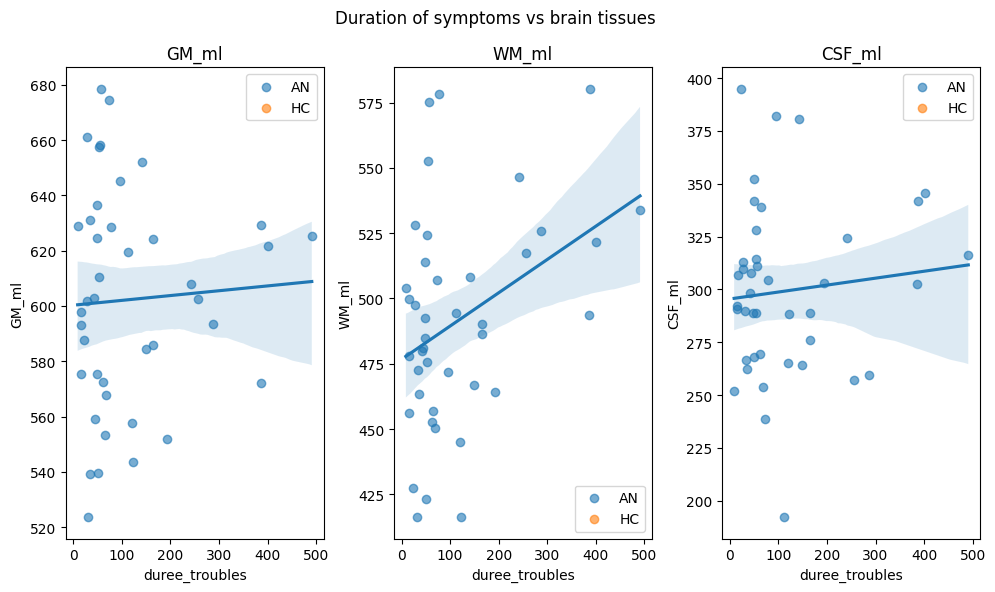

In [105]:
df_v1 = df_merged_tissues_long[df_merged_tissues_long["session"] == 1]

tissues = ["GM_ml", "WM_ml", "CSF_ml"]
fig, axes = plt.subplots(1, 3, figsize=(10,6))

for ax, tissue in zip(axes, tissues):

    sns.regplot(
        data=df_v1[df_v1.group=="AN"],
        x="duree_troubles",
        y=tissue,
        ax=ax,
        label="AN",
        scatter_kws={"alpha":0.6}
    )

    sns.regplot(
        data=df_v1[df_v1.group=="HC"],
        x="duree_troubles",
        y=tissue,
        ax=ax,
        label="HC",
        scatter_kws={"alpha":0.6}
    )

    ax.set_title(tissue)
    ax.legend()

plt.suptitle("Duration of symptoms vs brain tissues")
plt.tight_layout()
plt.show()

In [107]:
import utils_smri 

tissues = ["GM_ml", "WM_ml", "CSF_ml"]

res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long,
    outcomes=tissues,
    formula_template="{Y} ~ C(group) * C(session) + age + TIV_ml",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["group", "session", "age", "TIV_ml"],
    terms_of_interest=[
        "C(group)[T.HC]",
        "C(session)[T.2]",
        "C(group)[T.HC]:C(session)[T.2]"
    ]
)

res_global

,outcome,n,beta_C(group)[T.HC],p_C(group)[T.HC],beta_C(session)[T.2],p_C(session)[T.2],beta_C(group)[T.HC]:C(session)[T.2],p_C(group)[T.HC]:C(session)[T.2],formula
0,GM_ml,138,37.158691,6.020394e-11,15.636543,2.450309e-13,-11.720576,3.819395e-04,GM_ml ~ C(group) * C(session) + age + TIV_ml
1,WM_ml,138,-0.848873,8.997622e-01,-5.720124,1.926076e-05,5.461873,5.226000e-03,WM_ml ~ C(group) * C(session) + age + TIV_ml
2,CSF_ml,138,-51.106832,5.013054e-12,-31.804372,2.179769e-28,29.617918,2.811521e-11,CSF_ml ~ C(group) * C(session) + age + TIV_ml


In [108]:
import utils_smri 

tissues = ["GM_ml", "WM_ml", "CSF_ml"]

res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long,
    outcomes=tissues,
    formula_template="{Y} ~ C(remission_v3) * C(session) + age + TIV_ml",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["remission_v3", "session", "age", "TIV_ml"],
    terms_of_interest=[
        "C(remission_v3)[T.stable]",
        "C(session)[T.2]",
        "C(remission_v3)[T.stable]:C(session)[T.2]"
    ]
)

res_global

,outcome,n,beta_C(remission_v3)[T.stable],p_C(remission_v3)[T.stable],beta_C(session)[T.2],p_C(session)[T.2],beta_C(remission_v3)[T.stable]:C(session)[T.2],p_C(remission_v3)[T.stable]:C(session)[T.2],formula
0,GM_ml,78,4.156656,0.544143,17.936168,7.745343e-09,-4.183763,0.305852,GM_ml ~ C(remission_v3) * C(session) + age + T...
1,WM_ml,78,-5.743027,0.536191,-5.980525,8.791445e-03,2.031917,0.450749,WM_ml ~ C(remission_v3) * C(session) + age + T...
2,CSF_ml,78,-14.420575,0.171285,-39.711888,6.824420e-18,14.509061,0.016186,CSF_ml ~ C(remission_v3) * C(session) + age + ...


### group at baseline

In [109]:
res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.session == 1],
    outcomes=tissues,
    formula_template="{Y} ~ C(group) + age + TIV_ml",
    model_type="ols",
    dropna_extra=["group", "age", "TIV_ml"],
    terms_of_interest=[
        "C(group)[T.HC]"
    ]
)
res_global

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],formula
0,GM_ml,69,0.758717,0.747581,68.131118,4.870288e-20,37.408233,5.946127e-08,GM_ml ~ C(group) + age + TIV_ml
1,WM_ml,69,0.647516,0.631247,39.801830,1.010424e-14,0.175650,9.792413e-01,WM_ml ~ C(group) + age + TIV_ml
2,CSF_ml,69,0.516894,0.494597,23.182046,2.554850e-10,-51.369882,1.420732e-08,CSF_ml ~ C(group) + age + TIV_ml


In [110]:
res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.session == 1],
    outcomes=tissues,
    formula_template="{Y} ~ C(group) + BMI + age + TIV_ml",
    model_type="ols",
    dropna_extra=["group", "BMI", "age", "TIV_ml"],
    terms_of_interest=[
        "C(group)[T.HC]"
    ]
)
res_global

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],formula
0,GM_ml,69,0.762445,0.747598,51.352876,2.686870e-19,23.382470,0.130645,GM_ml ~ C(group) + BMI + age + TIV_ml
1,WM_ml,69,0.647819,0.625808,29.431198,6.816626e-14,-3.466707,0.838420,WM_ml ~ C(group) + BMI + age + TIV_ml
2,CSF_ml,69,0.524402,0.494677,17.641839,8.349119e-10,-33.120005,0.099459,CSF_ml ~ C(group) + BMI + age + TIV_ml


### group at follow-up

In [111]:
res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.session == 2],
    outcomes=tissues,
    formula_template="{Y} ~ C(group) + age + TIV_ml",
    model_type="ols",
    dropna_extra=["group", "age", "TIV_ml"],
    terms_of_interest=[
        "C(group)[T.HC]"
    ]
)

res_global

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],formula
0,GM_ml,69,0.780716,0.770595,77.139573,2.208840e-21,25.003443,0.000036,GM_ml ~ C(group) + age + TIV_ml
1,WM_ml,69,0.668360,0.653054,43.665213,1.414881e-15,7.515255,0.273110,WM_ml ~ C(group) + age + TIV_ml
2,CSF_ml,69,0.384284,0.355867,13.522743,5.896299e-07,-20.237367,0.007002,CSF_ml ~ C(group) + age + TIV_ml


### test-retest 

In [112]:
res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.group =='HC'],
    outcomes=tissues,
    formula_template="{Y} ~ C(session) + age + TIV_ml",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["session", "age", "TIV_ml"],
    terms_of_interest=[
        "C(session)[T.2]"
    ]
)

res_global

,outcome,n,beta_C(session)[T.2],p_C(session)[T.2],formula
0,GM_ml,56,3.945925,0.060187,GM_ml ~ C(session) + age + TIV_ml
1,WM_ml,56,-0.158640,0.898666,WM_ml ~ C(session) + age + TIV_ml
2,CSF_ml,56,-2.214944,0.308952,CSF_ml ~ C(session) + age + TIV_ml


### longitudinal change

In [113]:
res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.group =='AN'],
    outcomes=tissues,
    formula_template="{Y} ~ C(session) + age + TIV_ml",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["session", "age", "TIV_ml"],
    terms_of_interest=[
        "C(session)[T.2]"
    ]
)

res_global

,outcome,n,beta_C(session)[T.2],p_C(session)[T.2],formula
0,GM_ml,82,16.326188,7.014164e-12,GM_ml ~ C(session) + age + TIV_ml
1,WM_ml,82,-4.841416,1.445739e-03,WM_ml ~ C(session) + age + TIV_ml
2,CSF_ml,82,-32.462303,1.465493e-20,CSF_ml ~ C(session) + age + TIV_ml


In [115]:
df_merged_tissues_long.groupby(["session", "remission_v3", "group"])["subject"].nunique()

session  remission_v3  group
1        relapsed      AN       18
         stable        AN       21
2        relapsed      AN       18
         stable        AN       21
Name: subject, dtype: int64

In [116]:
res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long,
    outcomes=tissues,
    formula_template="{Y} ~ C(remission_v3) * C(session) + age + TIV_ml",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["remission_v3", "session", "age", "TIV_ml"],
    terms_of_interest=[
        "C(remission_v3)[T.stable]",
        "C(remission_v3)[T.relapsed]",
        "C(session)[T.2]",
        "C(remission_v3)[T.stable]:C(session)[T.2]",
        "C(remission_v3)[T.relapsed]:C(session)[T.2]"
    ]
)

res_global

,outcome,n,beta_C(remission_v3)[T.stable],p_C(remission_v3)[T.stable],beta_C(remission_v3)[T.relapsed],p_C(remission_v3)[T.relapsed],beta_C(session)[T.2],p_C(session)[T.2],beta_C(remission_v3)[T.stable]:C(session)[T.2],p_C(remission_v3)[T.stable]:C(session)[T.2],beta_C(remission_v3)[T.relapsed]:C(session)[T.2],p_C(remission_v3)[T.relapsed]:C(session)[T.2],formula
0,GM_ml,78,4.156656,0.544143,NaN,NaN,17.936168,7.745343e-09,-4.183763,0.305852,NaN,NaN,GM_ml ~ C(remission_v3) * C(session) + age + T...
1,WM_ml,78,-5.743027,0.536191,NaN,NaN,-5.980525,8.791445e-03,2.031917,0.450749,NaN,NaN,WM_ml ~ C(remission_v3) * C(session) + age + T...
2,CSF_ml,78,-14.420575,0.171285,NaN,NaN,-39.711888,6.824420e-18,14.509061,0.016186,NaN,NaN,CSF_ml ~ C(remission_v3) * C(session) + age + ...


### remission at baseline

In [117]:
res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.session == 1],
    outcomes=tissues,
    formula_template="{Y} ~ C(remission_v3) + age + TIV_ml",
    model_type="ols",
    dropna_extra=["remission_v3", "age", "TIV_ml"],
    terms_of_interest=[
        "C(remission_v3)[T.stable]"
    ]
)

res_global

,outcome,n,R2,adj_R2,F,p_model,beta_C(remission_v3)[T.stable],p_C(remission_v3)[T.stable],formula
0,GM_ml,39,0.694823,0.668665,26.562486,3.879497e-09,4.724992,0.528337,GM_ml ~ C(remission_v3) + age + TIV_ml
1,WM_ml,39,0.565212,0.527945,15.166361,1.729153e-06,-6.032072,0.524132,WM_ml ~ C(remission_v3) + age + TIV_ml
2,CSF_ml,39,0.385527,0.332858,7.319786,6.202851e-04,-15.862419,0.153678,CSF_ml ~ C(remission_v3) + age + TIV_ml


### remission at follow-up

In [118]:
res_global = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.session == 2],
    outcomes=tissues,
    formula_template="{Y} ~ C(remission_v3) + age + TIV_ml",
    model_type="ols",
    dropna_extra=["remission_v3", "age", "TIV_ml"],
    terms_of_interest=[
        "C(remission_v3)[T.stable]"
    ]
)

res_global

,outcome,n,R2,adj_R2,F,p_model,beta_C(remission_v3)[T.stable],p_C(remission_v3)[T.stable],formula
0,GM_ml,39,0.755154,0.734167,35.982309,8.541112e-11,-0.535973,0.939059,GM_ml ~ C(remission_v3) + age + TIV_ml
1,WM_ml,39,0.552433,0.514070,14.400181,2.841127e-06,-3.195704,0.747609,WM_ml ~ C(remission_v3) + age + TIV_ml
2,CSF_ml,39,0.320440,0.262192,5.501312,3.334637e-03,1.349974,0.902753,CSF_ml ~ C(remission_v3) + age + TIV_ml


### BMI at baseline

In [119]:
res_bmi_v1 = utils_smri.run_global_models(
    data=df_merged_tissues_long[(df_merged_tissues_long.session == 1)&(df_merged_tissues_long.group=="AN")],
    outcomes=tissues,
    formula_template="{Y} ~ BMI + age + TIV_ml",
    model_type="ols",
    dropna_extra=["BMI", "age", "TIV_ml"],
    terms_of_interest=["BMI"]
)
res_bmi_v1

,outcome,n,R2,adj_R2,F,p_model,beta_BMI,p_BMI,formula
0,GM_ml,41,0.712899,0.689620,30.624813,3.974369e-10,5.979874,0.027470,GM_ml ~ BMI + age + TIV_ml
1,WM_ml,41,0.562336,0.526850,15.846566,8.694086e-07,-0.111723,0.973644,WM_ml ~ BMI + age + TIV_ml
2,CSF_ml,41,0.385927,0.336137,7.751131,3.861747e-04,-7.335957,0.067790,CSF_ml ~ BMI + age + TIV_ml


### BMI at follow-up

In [120]:
res_bmi_v2 = utils_smri.run_global_models(
    data=df_merged_tissues_long[(df_merged_tissues_long.session == 2)&(df_merged_tissues_long.group=="AN")],
    outcomes=tissues,
    formula_template="{Y} ~ BMI + age + TIV_ml",
    model_type="ols",
    dropna_extra=["BMI", "age", "TIV_ml"],
    terms_of_interest=["BMI"]
)
res_bmi_v2

,outcome,n,R2,adj_R2,F,p_model,beta_BMI,p_BMI,formula
0,GM_ml,41,0.757415,0.737746,38.508008,1.810735e-11,3.126302,0.738569,GM_ml ~ BMI + age + TIV_ml
1,WM_ml,41,0.553936,0.517768,15.315888,1.227398e-06,-2.096746,0.874637,WM_ml ~ BMI + age + TIV_ml
2,CSF_ml,41,0.333424,0.279377,6.169174,1.652745e-03,-14.044971,0.338202,CSF_ml ~ BMI + age + TIV_ml


### group*BMI at baseline

In [121]:
res_global_interaction = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.session == 1],
    outcomes=tissues,
    formula_template="{Y} ~ C(group) * BMI + age + TIV_ml",
    model_type="ols",
    dropna_extra=["group", "BMI", "age", "TIV_ml"],
    terms_of_interest=[
        "C(group)[T.HC]:BMI"
        
    ]
)

res_global_interaction

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC]:BMI,p_C(group)[T.HC]:BMI,formula
0,GM_ml,69,0.779940,0.762475,44.657105,1.918358e-19,-8.336984,0.028767,GM_ml ~ C(group) * BMI + age + TIV_ml
1,WM_ml,69,0.648266,0.620351,23.222529,3.831389e-13,1.213463,0.778153,WM_ml ~ C(group) * BMI + age + TIV_ml
2,CSF_ml,69,0.553612,0.518185,15.626589,5.571142e-10,9.877663,0.046541,CSF_ml ~ C(group) * BMI + age + TIV_ml


### session*BMI 

In [122]:
res_session_interaction = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.group == "AN"],
    outcomes=tissues,
    formula_template="{Y} ~ C(session) * BMI + age + TIV_ml",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["session", "BMI", "age", "TIV_ml"],
    terms_of_interest=[
        "C(session)[T.2]",
        "C(session)[T.2]:BMI"
    ]
)

res_session_interaction

,outcome,n,beta_C(session)[T.2],p_C(session)[T.2],beta_C(session)[T.2]:BMI,p_C(session)[T.2]:BMI,formula
0,GM_ml,82,-187.951084,0.035805,8.206298,0.065814,GM_ml ~ C(session) * BMI + age + TIV_ml
1,WM_ml,82,13.837306,0.838896,-0.491126,0.884777,WM_ml ~ C(session) * BMI + age + TIV_ml
2,CSF_ml,82,116.616096,0.369544,-4.382193,0.498583,CSF_ml ~ C(session) * BMI + age + TIV_ml


### delat(BMI) 

In [ ]:
delta_global = utils_smri.make_delta_df(
    data=df_merged_tissues_long,
    value_cols=["GM_ml", "WM_ml", "CSF_ml", "BMI", "age", "TIV_ml"],
    subject_col="subject",
    session_col="session",
    baseline=1,
    followup=2,
)


delta_global.head()

,subject,GM_ml_V1,GM_ml_V2,delta_GM_ml,WM_ml_V1,WM_ml_V2,delta_WM_ml,CSF_ml_V1,CSF_ml_V2,delta_CSF_ml,BMI_V1,BMI_V2,delta_BMI,age_V1,age_V2,delta_age,TIV_ml_V1,TIV_ml_V2,delta_TIV_ml
0,1,572.301277,574.564435,2.263158,463.688696,460.508688,-3.180008,242.798179,243.392746,0.594567,21.6,NaN,NaN,33.0,33.0,0.0,1271.689995,1270.504271,-1.185724
1,2,573.150014,572.062011,-1.088003,372.682683,368.460557,-4.222126,201.144663,206.104801,4.960137,19.8,NaN,NaN,47.0,47.0,0.0,1137.927202,1135.262778,-2.664423
2,3,706.287440,706.974167,0.686727,603.350272,605.220413,1.870141,222.624583,224.222856,1.598273,22.9,NaN,NaN,27.0,27.0,0.0,1529.817586,1536.008152,6.190566
3,4,711.665876,709.639282,-2.026594,579.363308,578.018787,-1.344520,188.540754,198.513933,9.973179,20.6,NaN,NaN,27.0,27.0,0.0,1486.862563,1490.035255,3.172692
4,6,602.363282,608.447493,6.084211,517.573158,519.657459,2.084301,257.173663,249.046167,-8.127496,14.2,20.2,6.0,34.0,34.0,0.0,1355.317196,1383.267471,27.950275


In [124]:
delta_global["age"] = delta_global["age_V1"]
delta_global["TIV_ml"] = delta_global["TIV_ml_V1"]

res_delta_bmi = utils_smri.run_global_models(
    data=delta_global,
    outcomes=["delta_GM_ml", "delta_WM_ml", "delta_CSF_ml"],
    formula_template="{Y} ~ delta_BMI + age + TIV_ml",
    model_type="ols",
    dropna_extra=["delta_BMI", "age", "TIV_ml"],
    terms_of_interest=["delta_BMI"]
)

res_delta_bmi

,outcome,n,R2,adj_R2,F,p_model,beta_delta_BMI,p_delta_BMI,formula
0,delta_GM_ml,41,0.554802,0.518705,15.369726,1.184857e-06,7.976802,0.000001,delta_GM_ml ~ delta_BMI + age + TIV_ml
1,delta_WM_ml,41,0.046215,-0.031119,0.597597,6.206061e-01,-0.734726,0.406899,delta_WM_ml ~ delta_BMI + age + TIV_ml
2,delta_CSF_ml,41,0.572222,0.537538,16.497843,5.742625e-07,-8.630600,0.000007,delta_CSF_ml ~ delta_BMI + age + TIV_ml


### duration 

In [125]:
res_duration = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.group == "AN"],
    outcomes=tissues,
    formula_template="{Y} ~ duree_troubles + age + TIV_ml",
    model_type="ols",
    dropna_extra=["duree_troubles", "age", "TIV_ml"],
    terms_of_interest=["duree_troubles","age"]
)
res_duration

,outcome,n,R2,adj_R2,F,p_model,beta_duree_troubles,p_duree_troubles,beta_age,p_age,formula
0,GM_ml,82,0.695646,0.683941,59.426956,4.240691e-20,-0.020758,0.531751,-1.019487,0.004909,GM_ml ~ duree_troubles + age + TIV_ml
1,WM_ml,82,0.562485,0.545658,33.426538,5.371194e-14,0.053439,0.183756,0.034345,0.935728,WM_ml ~ duree_troubles + age + TIV_ml
2,CSF_ml,82,0.230214,0.200607,7.775628,1.314513e-04,-0.010595,0.841544,0.435243,0.441652,CSF_ml ~ duree_troubles + age + TIV_ml


### age-at-onset

In [126]:
res_onset = utils_smri.run_global_models(
    data=df_merged_tissues_long[(df_merged_tissues_long.group == "AN")],
    outcomes=tissues,
    formula_template="{Y} ~ age_at_onset + age + TIV_ml",
    model_type="ols",
    dropna_extra=["age_at_onset", "age", "TIV_ml"],
    terms_of_interest=["age_at_onset"]
)
res_onset

,outcome,n,R2,adj_R2,F,p_model,beta_age_at_onset,p_age_at_onset,formula
0,GM_ml,82,0.695646,0.683941,59.426956,4.240691e-20,0.249093,0.531751,GM_ml ~ age_at_onset + age + TIV_ml
1,WM_ml,82,0.562485,0.545658,33.426538,5.371194e-14,-0.641274,0.183756,WM_ml ~ age_at_onset + age + TIV_ml
2,CSF_ml,82,0.230214,0.200607,7.775628,1.314513e-04,0.127146,0.841544,CSF_ml ~ age_at_onset + age + TIV_ml


### session*duration

In [127]:
res_duration_session = utils_smri.run_global_models(
    data=df_merged_tissues_long[df_merged_tissues_long.group == "AN"],
    outcomes=tissues,
    formula_template="{Y} ~ C(session) * duree_troubles + age + TIV_ml",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["session", "duree_troubles", "age", "TIV_ml"],
    terms_of_interest=[
        "C(session)[T.2]",
        "duree_troubles",
        "C(session)[T.2]:duree_troubles"
    ]
)
res_duration_session

,outcome,n,beta_C(session)[T.2],p_C(session)[T.2],beta_duree_troubles,p_duree_troubles,beta_C(session)[T.2]:duree_troubles,p_C(session)[T.2]:duree_troubles,formula
0,GM_ml,82,21.680997,7.507361e-13,0.001645,0.967940,-0.047605,0.006978,GM_ml ~ C(session) * duree_troubles + age + TI...
1,WM_ml,82,-3.618726,5.910317e-02,0.087922,0.111575,-0.006134,0.547416,WM_ml ~ C(session) * duree_troubles + age + TI...
2,CSF_ml,82,-39.691796,1.033459e-18,-0.029720,0.639824,0.063132,0.015670,CSF_ml ~ C(session) * duree_troubles + age + T...


## Tests roi

In [132]:
available_rois = set(df_merged_roi_long["roi"].unique())

roi_list_remano = [
    r for r in [
        "Left Accumbens Area", "Right Accumbens Area",
        "Left Caudate", "Right Caudate",
        "Left Putamen", "Right Putamen",
        "Left AIns anterior insula", "Right AIns anterior insula",
        "Left ACgG anterior cingulate gyrus", "Right ACgG anterior cingulate gyrus",
        "Left MOrG medial orbital gyrus", "Right MOrG medial orbital gyrus",
        "Left LOrG lateral orbital gyrus", "Right LOrG lateral orbital gyrus",
        "Left Amygdala", "Right Amygdala",
        "Left Thalamus Proper", "Right Thalamus Proper",
    ]
    if r in available_rois
]

roi_list_remano
roi_outcomes = ["Vgm", "Vwm", "Vcsf"]

### group at baseline GM

#### NMH3

In [315]:
res_roi_group_v1_gm = utils_smri.run_roi_models(
    data=df_merged_roi_all[
        (df_merged_roi_all.session == 1) &
        (df_merged_roi_all.subject != 41)
    ],
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="Vgm ~ C(group) + age + TIV_ml",
    model_type="ols",
    group_col="subject",
    terms_of_interest=["C(group)[T.HC]"]
)

res_roi_group_v1_gm

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],roi,n_subjects,p_C(group)[T.HC]_fdr
0,Left Accumbens Area,101,0.584211,0.571351,45.430414,1.997057e-18,-0.000797,9.072795e-01,Left Accumbens Area,101,9.072795e-01
1,Right Accumbens Area,101,0.530468,0.515946,36.529520,6.927845e-16,0.007545,2.303506e-01,Right Accumbens Area,101,2.764208e-01
2,Left Caudate,101,0.463170,0.446567,27.896761,4.301517e-13,-0.022878,6.962710e-01,Left Caudate,101,7.372281e-01
3,Right Caudate,101,0.473872,0.457600,29.121945,1.637613e-13,0.031365,5.775318e-01,Right Caudate,101,6.497233e-01
4,Left Putamen,101,0.493891,0.478238,31.552727,2.545405e-14,0.141994,3.869777e-02,Left Putamen,101,5.804666e-02
5,Right Putamen,101,0.487121,0.471259,30.709450,4.816815e-14,0.160434,1.934361e-02,Right Putamen,101,3.165318e-02
6,Left AIns anterior insula,101,0.578068,0.565019,44.298300,4.046451e-18,0.347397,6.451155e-08,Left AIns anterior insula,101,5.806039e-07
7,Right AIns anterior insula,101,0.532023,0.517550,36.758443,5.906165e-16,0.382548,2.801486e-08,Right AIns anterior insula,101,5.042674e-07
8,Left ACgG anterior cingulate gyrus,101,0.553668,0.539864,40.109047,6.055948e-17,0.449262,5.261671e-07,Left ACgG anterior cingulate gyrus,101,2.367752e-06
9,Right ACgG anterior cingulate gyrus,101,0.379819,0.360639,19.802019,4.291175e-10,0.408249,4.177825e-05,Right ACgG anterior cingulate gyrus,101,1.074298e-04


In [134]:
df_merged_roi_all.groupby(["session", "group"])["subject"].nunique()

session  group
1        AN       71
         HC       30
2        AN       41
         HC       28
Name: subject, dtype: int64

### group at follow-up GM

In [135]:
res_roi_group_v2_gm = utils_smri.run_roi_models(
    data=df_merged_roi_long[df_merged_roi_long.session == 2],
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="Vgm ~ C(group) + age + TIV_ml",
    model_type="ols",
    group_col="subject",
    terms_of_interest=["C(group)[T.HC]"]
)
res_roi_group_v2_gm

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],roi,n_subjects,p_C(group)[T.HC]_fdr
0,Left Accumbens Area,69,0.558894,0.538535,27.452300,1.379417e-11,-0.002616,0.731941,Left Accumbens Area,69,0.773582
1,Right Accumbens Area,69,0.461660,0.436814,18.580526,8.170119e-09,-0.005444,0.453600,Right Accumbens Area,69,0.544319
2,Left Caudate,69,0.484712,0.460930,20.381042,2.015826e-09,-0.053417,0.406545,Left Caudate,69,0.522701
3,Right Caudate,69,0.502715,0.479763,21.903258,6.456067e-10,-0.018760,0.773582,Right Caudate,69,0.773582
4,Left Putamen,69,0.475533,0.451327,19.645124,3.546243e-09,0.309403,0.000177,Left Putamen,69,0.001589
5,Right Putamen,69,0.480565,0.456591,20.045346,2.605170e-09,0.246302,0.000919,Right Putamen,69,0.005513
6,Left AIns anterior insula,69,0.409010,0.381734,14.995011,1.601961e-07,0.153900,0.023489,Left AIns anterior insula,69,0.046978
7,Right AIns anterior insula,69,0.407876,0.380547,14.924763,1.702790e-07,0.193117,0.006620,Right AIns anterior insula,69,0.019860
8,Left ACgG anterior cingulate gyrus,69,0.375468,0.346643,13.025976,9.259435e-07,0.189555,0.059729,Left ACgG anterior cingulate gyrus,69,0.097739
9,Right ACgG anterior cingulate gyrus,69,0.225776,0.190043,6.318344,7.927060e-04,0.137512,0.253334,Right ACgG anterior cingulate gyrus,69,0.350770


### group at baseline WM

In [136]:
res_roi_group_v1_wm = utils_smri.run_roi_models(
    data=df_merged_roi_long[df_merged_roi_long.session == 1],
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="Vwm ~ C(group) + age + TIV_ml",
    model_type="ols",
    group_col="subject",
    terms_of_interest=["C(group)[T.HC]"]
)
res_roi_group_v1_wm

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],roi,n_subjects,p_C(group)[T.HC]_fdr
0,Left Accumbens Area,69,0.021040,-0.024143,0.465662,7.072398e-01,-0.000086,0.876098,Left Accumbens Area,69,0.927633
1,Right Accumbens Area,69,0.015916,-0.029503,0.350422,7.889586e-01,0.000480,0.511269,Right Accumbens Area,69,0.903079
2,Left Caudate,69,0.231231,0.195749,6.516918,6.366538e-04,-0.000678,0.862719,Left Caudate,69,0.927633
3,Right Caudate,69,0.270416,0.236743,8.030618,1.247022e-04,-0.001805,0.595551,Right Caudate,69,0.903079
4,Left Putamen,69,0.144035,0.104529,3.645905,1.705367e-02,0.033128,0.085592,Left Putamen,69,0.552048
5,Right Putamen,69,0.202576,0.165772,5.504150,1.973137e-03,0.020615,0.229419,Right Putamen,69,0.688257
6,Left AIns anterior insula,69,0.285100,0.252104,8.640588,6.595889e-05,0.004612,0.702395,Left AIns anterior insula,69,0.903079
7,Right AIns anterior insula,69,0.273481,0.239949,8.155887,1.093117e-04,0.023233,0.099048,Right AIns anterior insula,69,0.552048
8,Left ACgG anterior cingulate gyrus,69,0.225108,0.189343,6.294207,8.141822e-04,0.016974,0.491286,Left ACgG anterior cingulate gyrus,69,0.903079
9,Right ACgG anterior cingulate gyrus,69,0.149489,0.110234,3.808208,1.407174e-02,0.009681,0.691781,Right ACgG anterior cingulate gyrus,69,0.903079


### group at baseline CSF

In [137]:
res_roi_group_v1_csf = utils_smri.run_roi_models(
    data=df_merged_roi_long[df_merged_roi_long.session == 1],
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="Vcsf ~ C(group) + age + TIV_ml",
    model_type="ols",
    group_col="subject",
    terms_of_interest=["C(group)[T.HC]"]
)
res_roi_group_v1_csf

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],roi,n_subjects,p_C(group)[T.HC]_fdr
0,Left Accumbens Area,69,0.014242,-0.031254,0.313043,0.815880,-0.000005,0.977864,Left Accumbens Area,69,0.986924
1,Right Accumbens Area,69,0.019041,-0.026234,0.420563,0.738859,0.000180,0.380232,Right Accumbens Area,69,0.530010
2,Left Caudate,69,0.173321,0.135167,4.542633,0.005948,-0.015502,0.153864,Left Caudate,69,0.307727
3,Right Caudate,69,0.123840,0.083401,3.062445,0.034196,-0.011037,0.382785,Right Caudate,69,0.530010
4,Left Putamen,69,0.065561,0.022433,1.520149,0.217607,-0.000782,0.471105,Left Putamen,69,0.605706
5,Right Putamen,69,0.045876,0.001840,1.041773,0.380093,-0.000178,0.905160,Right Putamen,69,0.986924
6,Left AIns anterior insula,69,0.274195,0.240697,8.185255,0.000106,-0.199541,0.001011,Left AIns anterior insula,69,0.005471
7,Right AIns anterior insula,69,0.238747,0.203612,6.795175,0.000469,-0.192107,0.000973,Right AIns anterior insula,69,0.005471
8,Left ACgG anterior cingulate gyrus,69,0.217714,0.181608,6.029935,0.001092,-0.147331,0.013132,Left ACgG anterior cingulate gyrus,69,0.039397
9,Right ACgG anterior cingulate gyrus,69,0.225421,0.189671,6.305509,0.000804,-0.219871,0.001520,Right ACgG anterior cingulate gyrus,69,0.005471


### longitudinal AN GM

#### NMH4

In [138]:
res_roi_session_gm = utils_smri.run_roi_models(
    data=df_merged_roi_long[df_merged_roi_long.group == "AN"],
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="Vgm ~ C(session) + age ",
    model_type="mixedlm",
    group_col="subject",
    terms_of_interest=["C(session)[T.2]"]
)
res_roi_session_gm

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,outcome,n,beta_C(session)[T.2],p_C(session)[T.2],roi,n_subjects,p_C(session)[T.2]_fdr
0,Left Accumbens Area,82,0.015404,1.247307e-06,Left Accumbens Area,41,3.207360e-06
1,Right Accumbens Area,82,0.014175,1.651656e-05,Right Accumbens Area,41,3.716227e-05
2,Left Caudate,82,0.103038,1.638120e-19,Left Caudate,41,2.948617e-18
3,Right Caudate,82,0.104703,2.688009e-16,Right Caudate,41,2.419208e-15
4,Left Putamen,82,-0.128639,6.696375e-04,Left Putamen,41,1.205348e-03
5,Right Putamen,82,-0.052708,7.239151e-02,Right Putamen,41,8.686982e-02
6,Left AIns anterior insula,82,0.091975,3.038622e-08,Left AIns anterior insula,41,1.367380e-07
7,Right AIns anterior insula,82,0.097729,8.035057e-09,Right AIns anterior insula,41,4.821034e-08
8,Left ACgG anterior cingulate gyrus,82,0.082057,1.880011e-04,Left ACgG anterior cingulate gyrus,41,3.760023e-04
9,Right ACgG anterior cingulate gyrus,82,0.093511,3.637602e-07,Right ACgG anterior cingulate gyrus,41,1.091281e-06


### test retest GM

In [139]:
res_roi_session_gm = utils_smri.run_roi_models(
    data=df_merged_roi_long[df_merged_roi_long.group == "HC"],
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="Vgm ~ C(session) ",
    model_type="mixedlm",
    group_col="subject",
    terms_of_interest=["C(session)[T.2]"]
)
res_roi_session_gm

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,outcome,n,beta_C(session)[T.2],p_C(session)[T.2],roi,n_subjects,p_C(session)[T.2]_fdr
0,Left Accumbens Area,56,0.004316,0.168257,Left Accumbens Area,28,0.378577
1,Right Accumbens Area,56,0.003568,0.192121,Right Accumbens Area,28,0.383743
2,Left Caudate,56,0.007128,0.380982,Left Caudate,28,0.571473
3,Right Caudate,56,0.015915,0.074562,Right Caudate,28,0.223685
4,Left Putamen,56,0.046346,0.037857,Left Putamen,28,0.189364
5,Right Putamen,56,0.038154,0.055025,Right Putamen,28,0.198092
6,Left AIns anterior insula,56,-0.009983,0.609521,Left AIns anterior insula,28,0.731426
7,Right AIns anterior insula,56,0.005594,0.783016,Right AIns anterior insula,28,0.783016
8,Left ACgG anterior cingulate gyrus,56,0.012537,0.737434,Left ACgG anterior cingulate gyrus,28,0.780813
9,Right ACgG anterior cingulate gyrus,56,-0.018402,0.468070,Right ACgG anterior cingulate gyrus,28,0.648097


### group*session GM

In [143]:
res_roi_group_session_gm = utils_smri.run_roi_models(
    data=df_merged_roi_long,
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="Vgm ~ C(group) * C(session) + age ",
    model_type="mixedlm",
    group_col="subject",
    terms_of_interest=["C(group)[T.HC]:C(session)[T.2]","C(group)[T.HC]", "C(session)[T.2]"]
)
res_roi_group_session_gm

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


,outcome,n,beta_C(group)[T.HC]:C(session)[T.2],p_C(group)[T.HC]:C(session)[T.2],beta_C(group)[T.HC],p_C(group)[T.HC],beta_C(session)[T.2],p_C(session)[T.2],roi,n_subjects,p_C(group)[T.HC]:C(session)[T.2]_fdr,p_C(group)[T.HC]_fdr,p_C(session)[T.2]_fdr
0,Left Accumbens Area,138,-0.011088,1.675435e-02,0.000775,0.940322,0.015404,1.819995e-07,Left Accumbens Area,69,3.015782e-02,0.972692,5.459986e-07
1,Right Accumbens Area,138,-0.010607,2.053206e-02,-0.000293,0.972692,0.014175,1.176744e-06,Right Accumbens Area,69,3.079808e-02,0.972692,3.025914e-06
2,Left Caudate,138,-0.095910,4.158528e-10,-0.005364,0.945225,0.103038,5.834989e-26,Left Caudate,69,7.485350e-09,0.972692,1.050298e-24
3,Right Caudate,138,-0.088788,2.230580e-07,0.019468,0.809761,0.104703,9.039053e-22,Right Caudate,69,2.007522e-06,0.972692,8.135147e-21
4,Left Putamen,138,0.174985,3.901356e-04,0.073179,0.441847,-0.128639,4.258878e-05,Left Putamen,69,1.064420e-03,0.723023,8.517757e-05
5,Right Putamen,138,0.090862,2.019551e-02,0.106135,0.214556,-0.052708,3.442026e-02,Right Putamen,69,3.079808e-02,0.399921,4.084568e-02
6,Left AIns anterior insula,138,-0.101958,7.652387e-05,0.215577,0.005205,0.091975,2.134269e-08,Left AIns anterior insula,69,3.443574e-04,0.046849,7.845028e-08
7,Right AIns anterior insula,138,-0.092135,5.072906e-04,0.243140,0.002934,0.097729,7.063340e-09,Right AIns anterior insula,69,1.141404e-03,0.046849,4.238004e-08
8,Left ACgG anterior cingulate gyrus,138,-0.069520,8.813727e-02,0.204090,0.065843,0.082057,1.578993e-03,Left ACgG anterior cingulate gyrus,69,1.133193e-01,0.237036,2.186298e-03
9,Right ACgG anterior cingulate gyrus,138,-0.111913,2.503895e-04,0.199672,0.107235,0.093511,1.561683e-06,Right ACgG anterior cingulate gyrus,69,9.014023e-04,0.275747,3.513787e-06


### remission type

In [144]:
res_roi_remission_v1_gm = utils_smri.run_roi_models(
    data=df_merged_roi_long[df_merged_roi_long.session == 1],
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="Vgm ~ C(remission_v3) + age + TIV_ml",
    model_type="ols",
    group_col="subject",
    terms_of_interest=[
        "C(remission_v3)[T.stable]"
    ]
)
res_roi_remission_v1_gm

,outcome,n,R2,adj_R2,F,p_model,beta_C(remission_v3)[T.stable],p_C(remission_v3)[T.stable],roi,n_subjects,p_C(remission_v3)[T.stable]_fdr
0,Left Accumbens Area,69,0.394065,0.342128,7.587335,0.000490,0.012701,0.223028,Left Accumbens Area,69,0.582478
1,Right Accumbens Area,69,0.251450,0.187289,3.919024,0.016358,0.004994,0.549471,Right Accumbens Area,69,0.821228
2,Left Caudate,69,0.400054,0.348631,7.779544,0.000415,0.108250,0.180946,Left Caudate,69,0.582478
3,Right Caudate,69,0.422095,0.372560,8.521179,0.000221,0.119356,0.128463,Right Caudate,69,0.582478
4,Left Putamen,69,0.232055,0.166231,3.525399,0.024768,0.114844,0.210649,Left Putamen,69,0.582478
5,Right Putamen,69,0.254553,0.190658,3.983904,0.015288,0.099311,0.258879,Right Putamen,69,0.582478
6,Left AIns anterior insula,69,0.196026,0.127114,2.844586,0.051646,-0.052072,0.515742,Left AIns anterior insula,69,0.821228
7,Right AIns anterior insula,69,0.153449,0.080887,2.114743,0.115990,-0.045593,0.597956,Right AIns anterior insula,69,0.821228
8,Left ACgG anterior cingulate gyrus,69,0.317344,0.258831,5.423453,0.003596,-0.086439,0.481313,Left ACgG anterior cingulate gyrus,69,0.821228
9,Right ACgG anterior cingulate gyrus,69,0.265544,0.202591,4.218110,0.011997,0.213590,0.169416,Right ACgG anterior cingulate gyrus,69,0.582478


In [145]:
res_roi_remission_long = utils_smri.run_roi_models(
    data=df_merged_roi_long.dropna(subset=["remission_v3"]),
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="Vgm ~ C(remission_v3) * C(session)+age + TIV_ml ",
    model_type="mixedlm",
    group_col="subject",
    terms_of_interest=[
        "C(remission_v3)[T.stable]",
        "C(session)[T.2]",
        "C(remission_v3)[T.stable]:C(session)[T.2]"
    ]
)

res_roi_remission_long

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression

,outcome,n,beta_C(remission_v3)[T.stable],p_C(remission_v3)[T.stable],beta_C(session)[T.2],p_C(session)[T.2],beta_C(remission_v3)[T.stable]:C(session)[T.2],p_C(remission_v3)[T.stable]:C(session)[T.2],roi,n_subjects,p_C(remission_v3)[T.stable]_fdr,p_C(session)[T.2]_fdr,p_C(remission_v3)[T.stable]:C(session)[T.2]_fdr
0,Left Accumbens Area,78,0.013580,0.151543,0.023767,2.308678e-07,-0.013474,0.030991,Left Accumbens Area,39,0.456100,1.038905e-06,0.185944
1,Right Accumbens Area,78,0.005447,0.505607,0.020619,6.586683e-07,-0.012956,0.021543,Right Accumbens Area,39,0.726615,2.371206e-06,0.185944
2,Left Caudate,78,0.107501,0.159927,0.128113,2.688374e-13,-0.035954,0.127585,Left Caudate,39,0.456100,2.419537e-12,0.361461
3,Right Caudate,78,0.116347,0.122433,0.142559,5.497069e-15,-0.061363,0.012572,Right Caudate,39,0.456100,9.894724e-14,0.185944
4,Left Putamen,78,0.121872,0.177372,-0.148860,8.635309e-03,0.065249,0.397637,Left Putamen,39,0.456100,1.413051e-02,0.715747
5,Right Putamen,78,0.099966,0.224858,-0.062002,1.572938e-01,0.020462,0.731465,Right Putamen,39,0.505931,1.665464e-01,0.822898
6,Left AIns anterior insula,78,-0.058393,0.441789,0.105892,4.226092e-05,-0.015629,0.655675,Left AIns anterior insula,39,0.722927,1.267827e-04,0.822898
7,Right AIns anterior insula,78,-0.051641,0.524777,0.099905,5.751137e-05,0.000484,0.988506,Right AIns anterior insula,39,0.726615,1.478864e-04,0.988506
8,Left ACgG anterior cingulate gyrus,78,-0.092787,0.435737,0.129914,1.043020e-04,-0.066699,0.140568,Left ACgG anterior cingulate gyrus,39,0.722927,2.346796e-04,0.361461
9,Right ACgG anterior cingulate gyrus,78,0.203818,0.171482,0.141956,2.006542e-07,-0.069976,0.055217,Right ACgG anterior cingulate gyrus,39,0.456100,1.038905e-06,0.248476


### delta(BMI)

In [152]:
delta_roi_gm = utils_smri.make_delta_roi_df(
    data=df_merged_roi_long[df_merged_roi_long.group == "AN"],
    value_col="Vgm",
    roi_col="roi",
    subject_col="subject",
    session_col="session",
    baseline=1,
    followup=2
)
delta_bmi = utils_smri.make_delta_df(
    data=df_merged_roi_long[df_merged_roi_long.group == "AN"],
    value_cols=["BMI", "age"],
    subject_col="subject",
    session_col="session",
    baseline=1,
    followup=2
)
delta_roi_gm = delta_roi_gm.merge(
    delta_bmi[["subject", "delta_BMI", "age_V1"]],
    on="subject",
    how="left"
)

delta_roi_gm = delta_roi_gm.rename(columns={"age_V1": "age"})

#### NMH6

In [153]:
res_delta_roi_bmi = utils_smri.run_roi_models(
    data=delta_roi_gm,
    roi_col="roi",
    roi_list=roi_list_remano,
    formula="delta_Vgm ~ delta_BMI ",
    model_type="ols",
    group_col="subject",
    terms_of_interest=["delta_BMI"]
)

res_delta_roi_bmi.sort_values("p_delta_BMI_fdr")


,outcome,n,R2,adj_R2,F,p_model,beta_delta_BMI,p_delta_BMI,roi,n_subjects,p_delta_BMI_fdr
3,Right Caudate,41,0.345690,0.328913,20.604771,0.000053,0.034336,0.000053,Right Caudate,41,0.000953
2,Left Caudate,41,0.291772,0.273612,16.066993,0.000267,0.028128,0.000267,Left Caudate,41,0.001603
12,Left LOrG lateral orbital gyrus,41,0.293563,0.275449,16.206638,0.000254,0.039235,0.000254,Left LOrG lateral orbital gyrus,41,0.001603
6,Left AIns anterior insula,41,0.229111,0.209345,11.590973,0.001547,0.036291,0.001547,Left AIns anterior insula,41,0.006961
7,Right AIns anterior insula,41,0.210100,0.189846,10.373329,0.002580,0.035465,0.002580,Right AIns anterior insula,41,0.008234
1,Right Accumbens Area,41,0.207770,0.187457,10.228144,0.002745,0.006849,0.002745,Right Accumbens Area,41,0.008234
14,Left Amygdala,41,0.159889,0.138348,7.422458,0.009591,-0.010458,0.009591,Left Amygdala,41,0.024662
9,Right ACgG anterior cingulate gyrus,41,0.142825,0.120846,6.498302,0.014844,0.031722,0.014844,Right ACgG anterior cingulate gyrus,41,0.029689
16,Left Thalamus Proper,41,0.146132,0.124238,6.674509,0.013643,0.154637,0.013643,Left Thalamus Proper,41,0.029689
0,Left Accumbens Area,41,0.070453,0.046618,2.955900,0.093493,0.003851,0.093493,Left Accumbens Area,41,0.152989


### group

#### NMH3

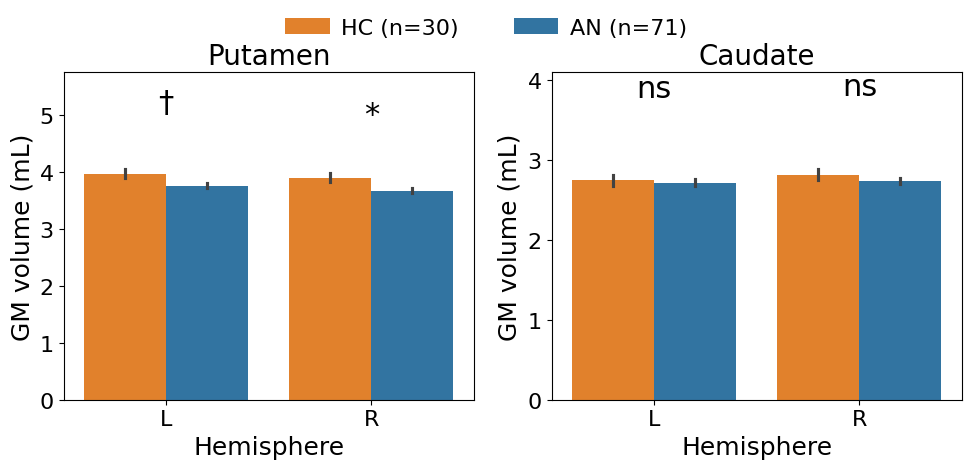

In [316]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

roi_map = {"caudate": ["Left Caudate", "Right Caudate"], "putamen": ["Left Putamen", "Right Putamen"]}

df_plot = df_merged_roi_all[(df_merged_roi_all["session"] == 1) & (df_merged_roi_all["roi"].isin(sum(roi_map.values(), [])))].copy()

df_plot["hemisphere"] = df_plot["roi"].map({"Left Caudate": "L", "Right Caudate": "R", "Left Putamen": "L", "Right Putamen": "R"})
df_plot["roi_base"] = df_plot["roi"].map({"Left Caudate": "caudate", "Right Caudate": "caudate", "Left Putamen": "putamen", "Right Putamen": "putamen"})

wide = df_plot.pivot_table(index=["subject", "group", "session", "hemisphere"], columns="roi_base", values="Vgm").reset_index()
wide["ratio_caudate_putamen"] = wide["caudate"] / wide["putamen"]

ratio_df = wide[["subject", "group", "session", "hemisphere", "ratio_caudate_putamen"]].copy()
ratio_df["roi_base"] = "ratio"
ratio_df = ratio_df.rename(columns={"ratio_caudate_putamen": "value"})
ratio_df = ratio_df[ratio_df["session"] == 1]

roi_df = df_plot.rename(columns={"Vgm": "value"})[["subject", "group", "session", "hemisphere", "roi_base", "value"]]
plot_df = pd.concat([roi_df, ratio_df], ignore_index=True)

pvals = {
    ("putamen", "L"): 0.05804666,
    ("putamen", "R"): 0.03165318,
    ("caudate", "L"): 0.7372281,
    ("caudate", "R"): 0.6497233,
}

def p_to_star(p):
    if p < 0.001: return "***"
    elif p < 0.01: return "**"
    elif p < 0.05: return "*"
    elif p < 0.1: return "†"
    else: return "ns"

def add_sig_star(ax, sub, roi_name, hemi):
    p = pvals.get((roi_name, hemi), None)
    if p is None: return
    x = 0 if hemi == "L" else 1
    y = sub[sub["hemisphere"] == hemi]["value"].max()
    r = sub[sub["hemisphere"] == hemi]["value"].max() - sub[sub["hemisphere"] == hemi]["value"].min()
    if r == 0: r = abs(y) * 0.1
    ax.text(x, y + 0.0 * r, p_to_star(p), ha="center", va="bottom", fontsize=22, fontweight="normal")

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "figure.titlesize": 24
})


palette = {
    "HC": sns.color_palette("tab10")[1],       # orange
    "AN": sns.color_palette("tab10")[0]  # blue
}
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=False)

for ax, roi_name in zip(axes, ["putamen", "caudate"]):
    sub = plot_df[plot_df["roi_base"] == roi_name].copy()

    sns.barplot(
    data=sub,
    x="hemisphere",
    y="value",
    hue="group",
    hue_order=["HC", "AN"],
    errorbar="se",
    palette=palette,
    ax=ax
)

    add_sig_star(ax, sub, roi_name, "L")
    add_sig_star(ax, sub, roi_name, "R")

    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.35)

    ax.set_title(roi_name.capitalize())
    ax.set_xlabel("Hemisphere")
    ax.set_ylabel("Caudate / Putamen ratio" if roi_name == "ratio" else "GM volume (mL)")
    ax.tick_params(axis="both", labelsize=16)

    if ax.get_legend() is not None:
        ax.get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles[:2],
    [ "HC (n=30)","AN (n=71)"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False,
    fontsize=16,
    columnspacing=2.5,
    handletextpad=0.5
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

#### NMH2

In [155]:
import pandas as pd
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests
df=pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/mouse_region_volumes.csv")
results = []

for (region, hemisphere), d in df.groupby(["region", "hemisphere"]):
    wt = d.loc[d["group"] == "WT", "volume"].dropna()
    ko = d.loc[d["group"] == "VAChTcKO", "volume"].dropna()

    t, p = ttest_ind(wt, ko, equal_var=False)

    results.append({
        "region": region,
        "hemisphere": hemisphere,
        "WT_n": len(wt),
        "WT_mean": wt.mean(),
        "WT_sd": wt.std(),
        "VAChTcKO_n": len(ko),
        "VAChTcKO_mean": ko.mean(),
        "VAChTcKO_sd": ko.std(),
        "t": t,
        "p": p
    })

res = pd.DataFrame(results)

res["p_fdr"] = multipletests(res["p"], method="fdr_bh")[1]

res["significant"] = res["p_fdr"] < 0.05

res


,region,hemisphere,WT_n,WT_mean,WT_sd,VAChTcKO_n,VAChTcKO_mean,VAChTcKO_sd,t,p,p_fdr,significant
0,DLS,Left,9,5.078889,0.247257,9,4.702222,0.426374,2.292648,0.039429,0.157715,False
1,DLS,Right,9,5.354444,0.183515,9,5.133333,0.454065,1.354439,0.203905,0.298084,False
2,DMS,Left,9,5.161111,0.283569,9,4.986667,0.364794,1.132644,0.275049,0.298084,False
3,DMS,Right,9,4.965556,0.207612,9,4.813333,0.366060,1.085142,0.298084,0.298084,False


  region hemisphere         t         p     p_fdr
0    DLS          L  2.292648  0.039429  0.157715
1    DLS          R  1.354439  0.203905  0.298084
2    DMS          L  1.132644  0.275049  0.298084
3    DMS          R  1.085142  0.298084  0.298084


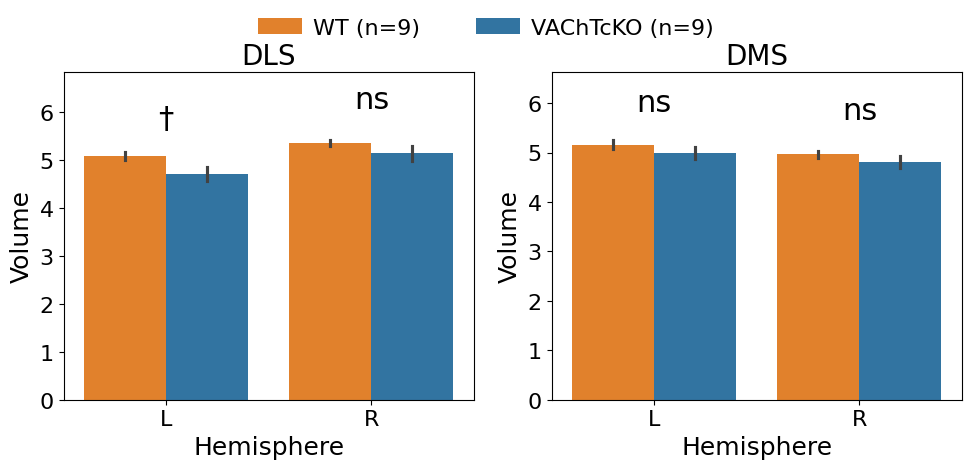

In [156]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

df_plot = df.copy()

df_plot["hemisphere"] = df_plot["hemisphere"].replace({"Left": "L", "Right": "R"})

# ============================================================
# STATISTICS: WT vs VAChTcKO
# ============================================================

results = []

for region in ["DLS", "DMS"]:
    for hemi in ["L", "R"]:
        sub = df_plot[(df_plot["region"] == region) & (df_plot["hemisphere"] == hemi)]

        wt = sub.loc[sub["group"] == "WT", "volume"].dropna()
        ko = sub.loc[sub["group"] == "VAChTcKO", "volume"].dropna()

        t, p = ttest_ind(wt, ko, equal_var=False)

        results.append({"region": region, "hemisphere": hemi, "t": t, "p": p})

res_stats = pd.DataFrame(results)
res_stats["p_fdr"] = multipletests(res_stats["p"], method="fdr_bh")[1]

print(res_stats)

pvals = {
    (row["region"], row["hemisphere"]): (row["p"], row["p_fdr"])
    for _, row in res_stats.iterrows()
}

def p_to_star(p, p_fdr):
    if p_fdr < 0.001: return "***"
    elif p_fdr < 0.01: return "**"
    elif p_fdr < 0.05: return "*"
    elif p < 0.05: return "†"
    else: return "ns"

def add_sig_star(ax, sub, region, hemi):
    p, p_fdr = pvals.get((region, hemi), (1, 1))
    symbol = p_to_star(p, p_fdr)

    x = 0 if hemi == "L" else 1
    y = sub[sub["hemisphere"] == hemi]["volume"].max()
    r = sub[sub["hemisphere"] == hemi]["volume"].max() - sub[sub["hemisphere"] == hemi]["volume"].min()
    if r == 0: r = abs(y) * 0.1

    ax.text(x, y + 0.05 * r, symbol, ha="center", va="bottom", fontsize=22)

# ============================================================
# PLOT
# ============================================================

plt.rcParams.update({
    "font.size": 16,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "legend.fontsize": 16,
    "figure.titlesize": 24
})

palette = {
    "WT": sns.color_palette("tab10")[1],       # orange
    "VAChTcKO": sns.color_palette("tab10")[0]  # blue
}

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=False)

for ax, region in zip(axes, ["DLS", "DMS"]):
    sub = df_plot[df_plot["region"] == region].copy()

    sns.barplot(data=sub, x="hemisphere", y="volume", hue="group", hue_order=["WT", "VAChTcKO"], errorbar="se", palette=palette, ax=ax)

    add_sig_star(ax, sub, region, "L")
    add_sig_star(ax, sub, region, "R")

    ymin, ymax = ax.get_ylim()
    ax.set_ylim(ymin, ymax * 1.20)

    ax.set_title(region)
    ax.set_xlabel("Hemisphere")
    ax.set_ylabel("Volume")
    ax.tick_params(axis="both", labelsize=16)

    if ax.get_legend() is not None:
        ax.get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(handles[:2], ["WT (n=9)", "VAChTcKO (n=9)"], loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=2, frameon=False, fontsize=16, columnspacing=2.5, handletextpad=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

/tmp/ipykernel_185855/4258508222.py:44: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  plotter.show()


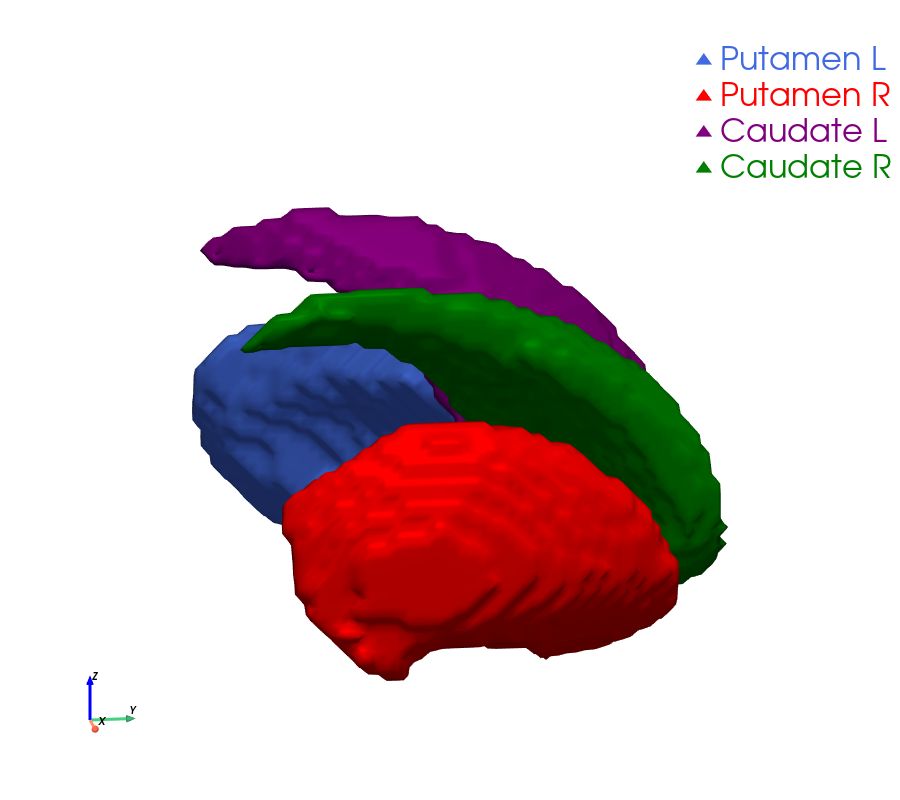

Saved: /home/imabrain/Downloads/3D_putamen_caudate_one_POV.png


In [157]:
import os
import numpy as np
import nibabel as nib
import pyvista as pv
from nilearn import image, datasets
from skimage import measure

roi_dir = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI"
out_dir = "/home/imabrain/Downloads"
os.makedirs(out_dir, exist_ok=True)

roi_paths = {"Putamen L": os.path.join(roi_dir, "putamen_L_bin.nii"), "Putamen R": os.path.join(roi_dir, "putamen_R_bin.nii"), "Caudate L": os.path.join(roi_dir, "caudate_L_bin.nii"), "Caudate R": os.path.join(roi_dir, "caudate_R_bin.nii")}
colors = {"Putamen L": "royalblue", "Putamen R": "red", "Caudate L": "purple", "Caudate R": "green"}
brain_img = datasets.load_mni152_template(resolution=1)

def nii_to_mesh(nii_path, target_img=None, smooth_iter=40):
    img = image.load_img(nii_path)
    if target_img is not None: img = image.resample_to_img(img, target_img, interpolation="nearest", force_resample=True, copy_header=True)
    data = img.get_fdata() > 0
    verts, faces, _, _ = measure.marching_cubes(data.astype(np.float32), level=0.5)
    verts_world = nib.affines.apply_affine(img.affine, verts)
    faces_pv = np.hstack([np.full((faces.shape[0], 1), 3), faces]).astype(np.int64)
    mesh = pv.PolyData(verts_world, faces_pv)
    if smooth_iter > 0: mesh = mesh.smooth(n_iter=smooth_iter)
    return mesh

pv.set_plot_theme("document")
plotter = pv.Plotter(off_screen=True, window_size=(900, 800))
plotter.set_background("white")

for name, path in roi_paths.items():
    mesh = nii_to_mesh(path, target_img=brain_img, smooth_iter=40)
    plotter.add_mesh(mesh, color=colors[name], opacity=1.0, smooth_shading=True, specular=0.25, specular_power=15, label=name)

plotter.camera_position = [(250, -35, 75), (0, 0, 10), (0, 0, 1)]
plotter.enable_parallel_projection()
plotter.camera.zoom(1.65)
plotter.add_axes(line_width=3, labels_off=False)
plotter.add_legend(bcolor="white", border=False, size=(0.24, 0.19), loc="upper right", face="triangle")
#plotter.add_text("Putamen and Caudate ROIs", position="upper_left", font_size=24, color="black")

out_png = os.path.join(out_dir, "3D_putamen_caudate_one_POV.png")
plotter.screenshot(out_png, transparent_background=False)
plotter.show()
plotter.close()

print("Saved:", out_png)


#### NMH15

/tmp/ipykernel_185855/2228327373.py:44: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  plotter.show()


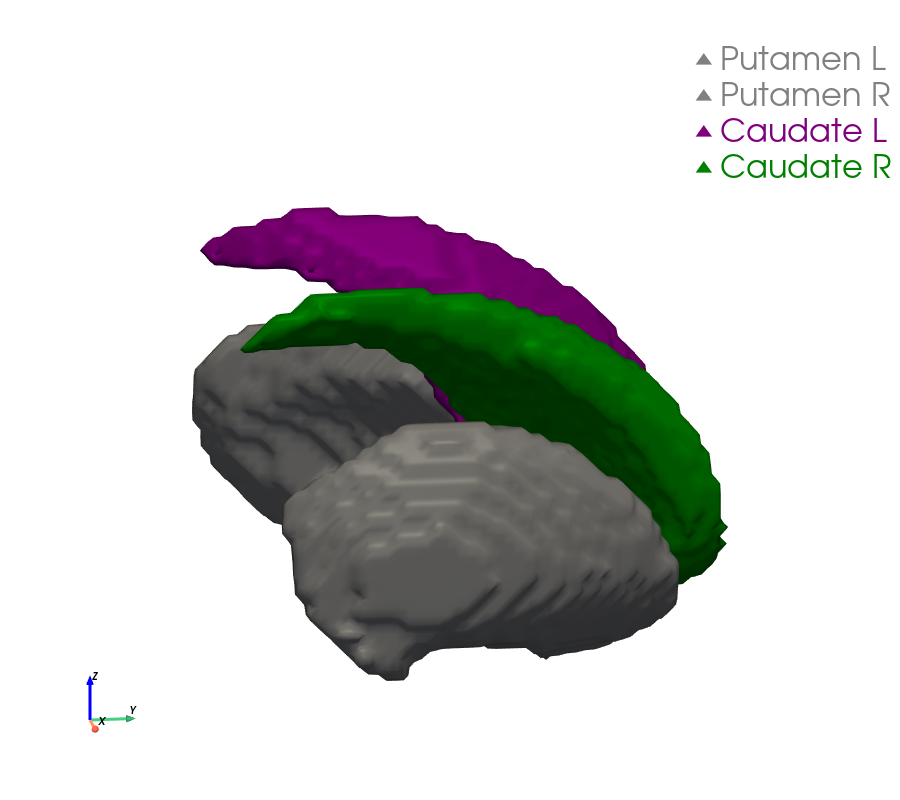

Saved: /home/imabrain/Downloads/3D_putamen_caudate_one_POV.png


In [158]:
import os
import numpy as np
import nibabel as nib
import pyvista as pv
from nilearn import image, datasets
from skimage import measure

roi_dir = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI"
out_dir = "/home/imabrain/Downloads"
os.makedirs(out_dir, exist_ok=True)

roi_paths = {"Putamen L": os.path.join(roi_dir, "putamen_L_bin.nii"), "Putamen R": os.path.join(roi_dir, "putamen_R_bin.nii"), "Caudate L": os.path.join(roi_dir, "caudate_L_bin.nii"), "Caudate R": os.path.join(roi_dir, "caudate_R_bin.nii")}
colors = {"Putamen L": "gray", "Putamen R": "gray", "Caudate L": "purple", "Caudate R": "green"}
brain_img = datasets.load_mni152_template(resolution=1)

def nii_to_mesh(nii_path, target_img=None, smooth_iter=40):
    img = image.load_img(nii_path)
    if target_img is not None: img = image.resample_to_img(img, target_img, interpolation="nearest", force_resample=True, copy_header=True)
    data = img.get_fdata() > 0
    verts, faces, _, _ = measure.marching_cubes(data.astype(np.float32), level=0.5)
    verts_world = nib.affines.apply_affine(img.affine, verts)
    faces_pv = np.hstack([np.full((faces.shape[0], 1), 3), faces]).astype(np.int64)
    mesh = pv.PolyData(verts_world, faces_pv)
    if smooth_iter > 0: mesh = mesh.smooth(n_iter=smooth_iter)
    return mesh

pv.set_plot_theme("document")
plotter = pv.Plotter(off_screen=True, window_size=(900, 800))
plotter.set_background("white")

for name, path in roi_paths.items():
    mesh = nii_to_mesh(path, target_img=brain_img, smooth_iter=40)
    plotter.add_mesh(mesh, color=colors[name], opacity=1.0, smooth_shading=True, specular=0.25, specular_power=15, label=name)

plotter.camera_position = [(250, -35, 75), (0, 0, 10), (0, 0, 1)]
plotter.enable_parallel_projection()
plotter.camera.zoom(1.65)
plotter.add_axes(line_width=3, labels_off=False)
plotter.add_legend(bcolor="white", border=False, size=(0.24, 0.19), loc="upper right", face="triangle")
#plotter.add_text("Putamen and Caudate ROIs", position="upper_left", font_size=24, color="black")

out_png = os.path.join(out_dir, "3D_putamen_caudate_one_POV.png")
plotter.screenshot(out_png, transparent_background=False)
plotter.show()
plotter.close()

print("Saved:", out_png)


/tmp/ipykernel_185855/3151530919.py:44: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  plotter.show()


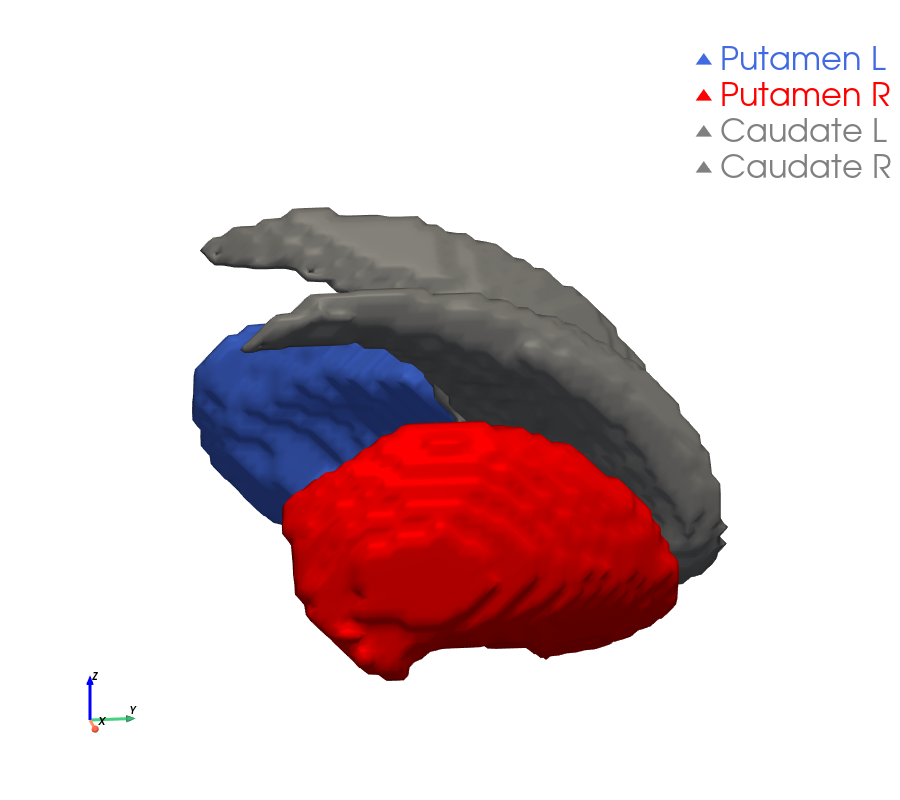

Saved: /home/imabrain/Downloads/3D_putamen_caudate_one_POV.png


In [159]:
import os
import numpy as np
import nibabel as nib
import pyvista as pv
from nilearn import image, datasets
from skimage import measure

roi_dir = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI"
out_dir = "/home/imabrain/Downloads"
os.makedirs(out_dir, exist_ok=True)

roi_paths = {"Putamen L": os.path.join(roi_dir, "putamen_L_bin.nii"), "Putamen R": os.path.join(roi_dir, "putamen_R_bin.nii"), "Caudate L": os.path.join(roi_dir, "caudate_L_bin.nii"), "Caudate R": os.path.join(roi_dir, "caudate_R_bin.nii")}
colors = {"Putamen L": "royalblue", "Putamen R": "red", "Caudate L": "gray", "Caudate R": "gray"}
brain_img = datasets.load_mni152_template(resolution=1)

def nii_to_mesh(nii_path, target_img=None, smooth_iter=40):
    img = image.load_img(nii_path)
    if target_img is not None: img = image.resample_to_img(img, target_img, interpolation="nearest", force_resample=True, copy_header=True)
    data = img.get_fdata() > 0
    verts, faces, _, _ = measure.marching_cubes(data.astype(np.float32), level=0.5)
    verts_world = nib.affines.apply_affine(img.affine, verts)
    faces_pv = np.hstack([np.full((faces.shape[0], 1), 3), faces]).astype(np.int64)
    mesh = pv.PolyData(verts_world, faces_pv)
    if smooth_iter > 0: mesh = mesh.smooth(n_iter=smooth_iter)
    return mesh

pv.set_plot_theme("document")
plotter = pv.Plotter(off_screen=True, window_size=(900, 800))
plotter.set_background("white")

for name, path in roi_paths.items():
    mesh = nii_to_mesh(path, target_img=brain_img, smooth_iter=40)
    plotter.add_mesh(mesh, color=colors[name], opacity=1.0, smooth_shading=True, specular=0.25, specular_power=15, label=name)

plotter.camera_position = [(250, -35, 75), (0, 0, 10), (0, 0, 1)]
plotter.enable_parallel_projection()
plotter.camera.zoom(1.65)
plotter.add_axes(line_width=3, labels_off=False)
plotter.add_legend(bcolor="white", border=False, size=(0.24, 0.19), loc="upper right", face="triangle")
#plotter.add_text("Putamen and Caudate ROIs", position="upper_left", font_size=24, color="black")

out_png = os.path.join(out_dir, "3D_putamen_caudate_one_POV.png")
plotter.screenshot(out_png, transparent_background=False)
plotter.show()
plotter.close()

print("Saved:", out_png)


## Voxel-wise

In [176]:
import nibabel as nib
from pathlib import Path

roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")

for rp in sorted(roi_dir.glob("*bin*.nii*")):
    img = nib.load(str(rp))
    print(
        rp.name,
        "| shape:", img.shape,
        "| zooms:", img.header.get_zooms()[:3],
        "| affine[0:3,3]:", img.affine[:3, 3]
    )

ACC_rostral_bin.nii | shape: (182, 218, 182) | zooms: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | affine[0:3,3]: [  90. -126.  -72.]
Cingulate_Gyrus_anterior_division_bin.nii | shape: (182, 218, 182) | zooms: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | affine[0:3,3]: [ -91. -126.  -72.]
Cingulate_Gyrus_posterior_division_bin.nii | shape: (182, 218, 182) | zooms: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | affine[0:3,3]: [ -91. -126.  -72.]
Hypothalamus_bin.nii | shape: (182, 218, 182) | zooms: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | affine[0:3,3]: [  90. -126.  -72.]
Insular_Cortex_bin.nii | shape: (182, 218, 182) | zooms: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | affine[0:3,3]: [ -91. -126.  -72.]
Left_Amygdala_bin.nii | shape: (182, 218, 182) | zooms: (np.float32(1.0), np.float32(1.0), np.float32(1.0)) | affine[0:3,3]: [ -91. -126.  -72.]
NACC_L_bin.nii | shape: (182, 218, 182) | zooms: (np.float32(1.0), np.float32(1.0), np.floa

### disease-specific change

AN paired subjects: 41
HC paired subjects: 28
[001] subject 6 done
[002] subject 7 done
[003] subject 10 done
[004] subject 12 done
[005] subject 13 done
[006] subject 15 done
[007] subject 16 done
[008] subject 17 done
[009] subject 18 done
[010] subject 20 done
[011] subject 21 done
[012] subject 23 done
[013] subject 24 done
[014] subject 25 done
[015] subject 28 done
[016] subject 29 done
[017] subject 31 done
[018] subject 32 done
[019] subject 33 done
[020] subject 34 done
[021] subject 35 done
[022] subject 37 done
[023] subject 53 done
[024] subject 54 done
[025] subject 56 done
[026] subject 57 done
[027] subject 60 done
[028] subject 61 done
[029] subject 62 done
[030] subject 63 done
[031] subject 73 done
[032] subject 74 done
[033] subject 75 done
[034] subject 78 done
[035] subject 79 done
[036] subject 80 done
[037] subject 81 done
[038] subject 82 done
[039] subject 89 done
[040] subject 92 done
[041] subject 94 done
[001] subject 1 done
[002] subject 2 done
[003] subjec

/tmp/ipykernel_185855/2031933876.py:89: UserWarning: Data array used to create a new image contains 64-bit ints. This is likely due to creating the array with numpy and passing `int` as the `dtype`. Many tools such as FSL and SPM cannot deal with int64 in Nifti images, so for compatibility the data has been converted to int32.
  mask_img = math_img("img.astype(int)", img=mask_img)


Mask voxels: 317679
[run_second_level_two_group] N after cleaning: 69
[run_second_level_two_group] missing after cleaning:
path      0
group     0
age       0
TIV_ml    0
dtype: int64
[run_second_level_two_group] design columns: ['intercept', 'group', 'age', 'TIV_ml']
[run_second_level_two_group] group counts:
group
AN    41
HC    28
Name: count, dtype: int64
[run_second_level_two_group] design head:
   intercept  group   age       TIV_ml
0        1.0      0  34.0  1355.317196
1        1.0      0  29.0  1363.021369
2        1.0      0  25.0  1542.801511
3        1.0      0  18.0  1390.881289
4        1.0      0  31.0  1486.842058


/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/utils_smri.py:1127: UserWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  slm = slm.fit(imgs, design_matrix=design)


   intercept  group   age       TIV_ml
0        1.0      0  34.0  1355.317196
1        1.0      0  29.0  1363.021369
2        1.0      0  25.0  1542.801511
3        1.0      0  18.0  1390.881289
4        1.0      0  31.0  1486.842058
group_label  group
AN           0        41
HC           1        28
Name: count, dtype: int64
group_label
AN    0.0
HC    1.0
Name: group, dtype: float64
FDR threshold: 2.1017959858810347


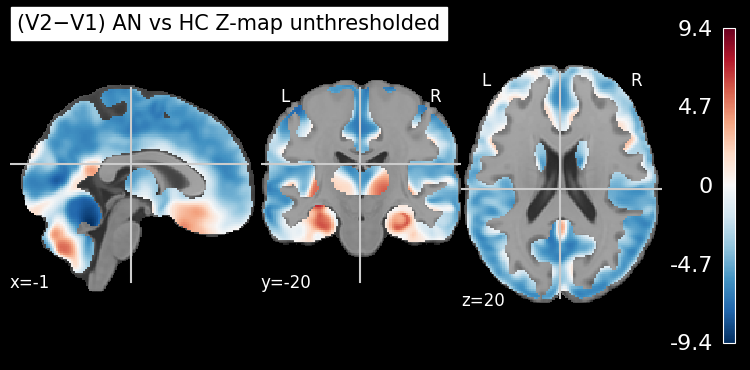

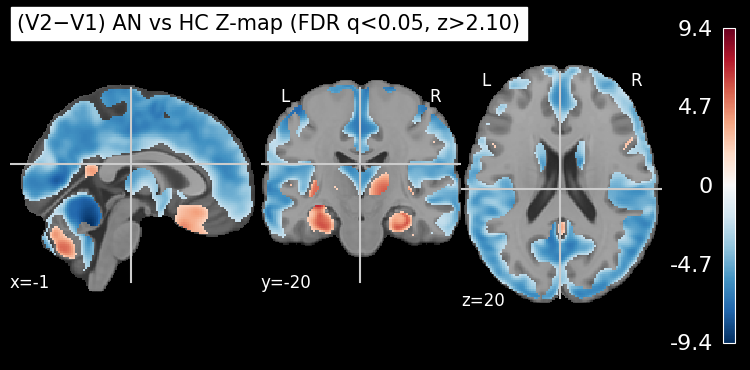

Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_vs_hc_delta_v2_minus_v1/VBM_deltaV2minusV1_AN_vs_HC_FDR_q05_positive.nii.gz
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_vs_hc_delta_v2_minus_v1/VBM_deltaV2minusV1_AN_vs_HC_FDR_q05_negative.nii.gz


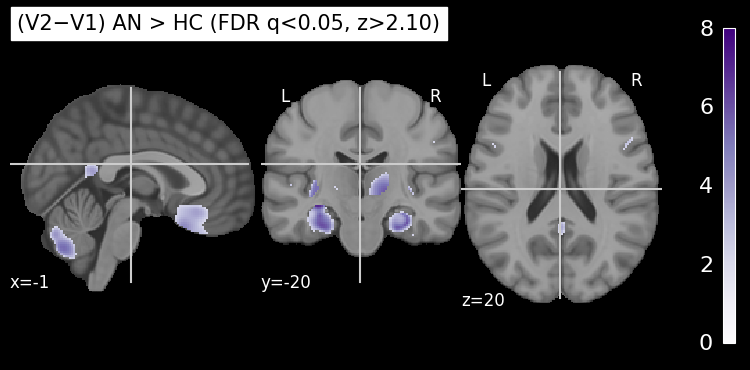

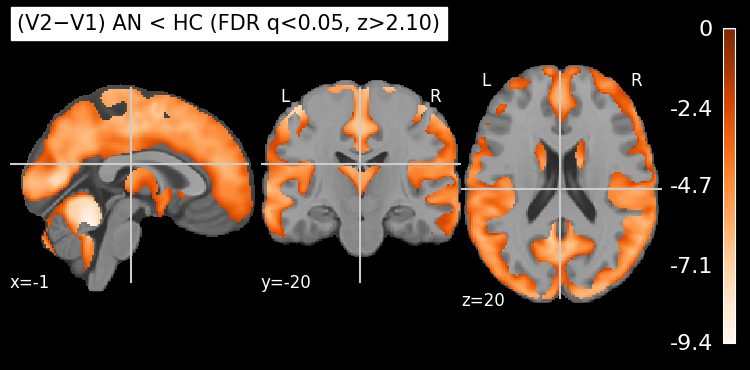

   Cluster ID     X     Y     Z  Peak Stat Cluster Size (mm3)
0           1  19.5 -70.5 -42.0   7.996089              71300
1          1a -16.5 -70.5 -48.0   7.845939                   
2          1b  25.5 -75.0 -33.0   7.377934                   
3          1c  27.0 -67.5 -25.5   7.277289                   
4           2  28.5  -7.5  -9.0   7.696030              18390
5          2a  33.0 -18.0 -24.0   6.119877                   
6          2b  24.0  -6.0 -33.0   5.977002                   
7          2c  28.5 -15.0 -19.5   5.897037                   
8           3 -31.5 -16.5 -10.5   7.629585              18430
9          3a -28.5 -21.0 -22.5   6.102262                   
10         3b -30.0  -4.5 -28.5   5.182710                   
11         3c -37.5 -24.0 -21.0   4.164612                   
12          4 -10.5  18.0 -27.0   5.522857               4644
13         4a   0.0  27.0 -15.0   3.860063                   
14         4b  -9.0  36.0 -28.5   3.227116                   
15      

In [177]:
from nilearn import datasets, plotting
from nilearn.image import load_img, mean_img, math_img, resample_to_img
from nilearn.masking import apply_mask
from nilearn.reporting import get_clusters_table

# =========================================================
# 1) paired AN and HC subjects
# =========================================================

wide_AN = utils_smri.make_paired_path_table(
    df_imgs=df_all_sv,
    group="AN",
    baseline=1,
    followup=2,
)

wide_HC = utils_smri.make_paired_path_table(
    df_imgs=df_all_sv,
    group="HC",
    baseline=1,
    followup=2,
)

print("AN paired subjects:", len(wide_AN))
print("HC paired subjects:", len(wide_HC))

diff_imgs_AN, subjects_AN = utils_smri.build_difference_images(
    wide_paths=wide_AN,
    baseline=1,
    followup=2,
    expr="img2 - img1",
    verbose=True,
)

diff_imgs_HC, subjects_HC = utils_smri.build_difference_images(
    wide_paths=wide_HC,
    baseline=1,
    followup=2,
    expr="img2 - img1",
    verbose=True,
)

# =========================================================
# 2) dataframe for second-level two-group model
# =========================================================

df_diff_AN = pd.DataFrame({
    "subject": subjects_AN,
    "path": diff_imgs_AN,
    "group": "AN",
})

df_diff_HC = pd.DataFrame({
    "subject": subjects_HC,
    "path": diff_imgs_HC,
    "group": "HC",
})

df_diff = pd.concat([df_diff_AN, df_diff_HC], ignore_index=True)

# add V1 covariates
df_covars_v1 = (
    df_merged_all[df_merged_all["session"] == 1][["subject", "age", "TIV_ml"]]
    .drop_duplicates(subset=["subject"])
    .copy()
)

df_covars_v1["age"] = pd.to_numeric(df_covars_v1["age"], errors="coerce")
df_covars_v1["TIV_ml"] = pd.to_numeric(df_covars_v1["TIV_ml"], errors="coerce")

df_diff = df_diff.merge(df_covars_v1, on="subject", how="left")
df_diff = df_diff.dropna(subset=["subject", "path", "group", "age", "TIV_ml"]).copy()

print(df_diff["group"].value_counts())
print(df_diff.groupby("group")[["age", "TIV_ml"]].mean())

# =========================================================
# 3) mask from original GM maps, not diff maps
# =========================================================

all_paths = (
    wide_AN[1].tolist() + wide_AN[2].tolist() +
    wide_HC[1].tolist() + wide_HC[2].tolist()
)

mean_gm = mean_img([load_img(p) for p in all_paths])

mask_img = math_img("img > 0.3", img=mean_gm)
mask_img = math_img("img.astype(int)", img=mask_img)

print("Mask voxels:", int(mask_img.get_fdata().sum()))

# =========================================================
# 4) two-group model on difference maps
# =========================================================

slm, z_map, design = utils_smri.run_second_level_two_group(
    df_imgs=df_diff,
    path_col="path",
    group_col="group",
    covariates=["age", "TIV_ml"],
    mask_img=mask_img,
    verbose=True,
)

print(design.head())

design_check = design.copy()
design_check["group_label"] = df_diff["group"].values
design_check["subject"] = df_diff["subject"].values

print(design_check.groupby("group_label")["group"].value_counts())
print(design_check.groupby("group_label")["group"].mean())

# =========================================================
# 5) save z-map
# =========================================================

out_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_vs_hc_delta_v2_minus_v1")
out_dir.mkdir(parents=True, exist_ok=True)

utils_smri.save_nifti(
    z_map,
    out_dir / "VBM_deltaV2minusV1_AN_vs_HC_parametric_zmap.nii.gz"
)

# =========================================================
# 6) FDR threshold
# =========================================================

z_fdr, z_thr = utils_smri.threshold_map(
    z_map,
    alpha=0.05,
    height_control="fdr",
    two_sided=True,
)

utils_smri.save_nifti(
    z_fdr,
    out_dir / "VBM_deltaV2minusV1_AN_vs_HC_parametric_zmap_FDR05.nii.gz"
)

print("FDR threshold:", z_thr)

# =========================================================
# 7) plot maps
# =========================================================

mni = datasets.load_mni152_template()

plotting.plot_stat_map(
    z_map,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    title="(V2−V1) AN vs HC Z-map unthresholded"
)
plotting.show()

plotting.plot_stat_map(
    z_fdr,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    symmetric_cbar=True,
    title=(
        f"(V2−V1) AN vs HC Z-map (FDR q<0.05, z>{z_thr:.2f})"
        if z_thr is not None else
        "(V2−V1) AN vs HC Z-map (no voxels survive FDR)"
    )
)
plotting.show()

# =========================================================
# 8) positive / negative maps
# =========================================================

if z_thr is not None:

    # Positive effects: AN > HC for change (V2−V1)
    z_inc = math_img("z * (z > 0)", z=z_fdr)

    # Negative effects: AN < HC for change (V2−V1)
    z_dec = math_img("z * (z < 0)", z=z_fdr)

    out_inc = out_dir / "VBM_deltaV2minusV1_AN_vs_HC_FDR_q05_positive.nii.gz"
    out_dec = out_dir / "VBM_deltaV2minusV1_AN_vs_HC_FDR_q05_negative.nii.gz"

    utils_smri.save_nifti(z_inc, out_inc)
    utils_smri.save_nifti(z_dec, out_dec)

    print("Saved:", out_inc)
    print("Saved:", out_dec)

else:
    print("No voxels survived FDR.")

# =========================================================
# 9) plot positive / negative maps
# =========================================================

if z_thr is not None:

    plotting.plot_stat_map(
    z_inc,
    bg_img=mni,
    threshold=1e-6,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    cmap="Purples",
    colorbar=True,
    title=f"(V2−V1) AN > HC (FDR q<0.05, z>{z_thr:.2f})"
)
    plotting.show()

    # Negative effects: AN < HC
    plotting.plot_stat_map(
        z_dec,
        bg_img=mni,
        threshold=1e-6,
        display_mode="ortho",
        cut_coords=(-1, -20, 20),
        cmap="Oranges",
        colorbar=True,
        title=f"(V2−V1) AN < HC (FDR q<0.05, z>{z_thr:.2f})"
    )
    plotting.show()

# =========================================================
# 10) clusters
# =========================================================

cluster_k = 1000

clusters = get_clusters_table(
    stat_img=z_fdr,
    stat_threshold=1e-6,
    cluster_threshold=cluster_k,
    two_sided=True
)

print(clusters)

# =========================================================
# 11) ROI summary
# =========================================================


roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")

roi_keep = [
    "putamen_R_slice01_most_posterior",
    "putamen_R_slice02",
    "putamen_R_slice03",
    "putamen_R_slice04",
    "putamen_R_slice05",
    "putamen_R_slice06_most_anterior",
    "putamen_L_slice01_most_posterior",
    "putamen_L_slice02",
    "putamen_L_slice03",
    "putamen_L_slice04",
    "putamen_L_slice05",
    "putamen_L_slice06_most_anterior",
]

roi_keep = set(roi_keep)

rows = []

print("Available ROI files:")
for rp in sorted(roi_dir.glob("*putamen*slice*.nii*")):
    roi_tmp = rp.stem.replace("_bin", "")
    if roi_tmp.endswith(".nii"):
        roi_tmp = roi_tmp.replace(".nii", "")
    print(rp.name, "->", roi_tmp)

for rp in sorted(roi_dir.glob("*.nii*")):

    roi_name = rp.stem.replace("_bin", "")

    # handle .nii.gz
    if roi_name.endswith(".nii"):
        roi_name = roi_name.replace(".nii", "")

    if roi_name not in roi_keep:
        continue

    roi = load_img(rp)

    roi_rs = resample_to_img(
        roi,
        z_map,
        interpolation="nearest"
    )

    roi_bin = math_img("img > 0", img=roi_rs)

    n_vox = int(roi_bin.get_fdata().sum())

    if n_vox == 0:
        print("Empty ROI after resampling:", roi_name)
        continue

    z_vals = apply_mask(z_map, roi_bin)
    zsig_vals = apply_mask(z_fdr, roi_bin)

    sig_mask = zsig_vals != 0
    sig_pos = zsig_vals > 0
    sig_neg = zsig_vals < 0

    rows.append({
        "roi": roi_name,
        "roi_file": rp.name,
        "n_vox": int(z_vals.size),
        "mean_z": float(np.mean(z_vals)),
        "median_z": float(np.median(z_vals)),
        "pct_FDR_sig_voxels": float(sig_mask.mean() * 100),
        "mean_z_sig_voxels":
            float(np.mean(zsig_vals[sig_mask]))
            if sig_mask.any() else np.nan,
        "pct_sig_pos": float(sig_pos.mean() * 100),
        "pct_sig_neg": float(sig_neg.mean() * 100),
    })

if len(rows) == 0:
    print("No ROI matched roi_keep.")
    df_roi_vox = pd.DataFrame()

else:
    df_roi_vox = (
        pd.DataFrame(rows)
        .sort_values(
            "pct_FDR_sig_voxels",
            ascending=False
        )
        .reset_index(drop=True)
    )

print(df_roi_vox)

In [179]:
design_check = design.copy()
design_check["group_label"] = df_diff["group"].values

print(design_check.groupby("group_label")["group"].mean())
print(design_check.groupby("group_label")["group"].value_counts())

group_label
AN    0.0
HC    1.0
Name: group, dtype: float64
group_label  group
AN           0        41
HC           1        28
Name: count, dtype: int64


### within-patient change

[001] subject 6 done
[002] subject 7 done
[003] subject 10 done
[004] subject 12 done
[005] subject 13 done
[006] subject 15 done
[007] subject 16 done
[008] subject 17 done
[009] subject 18 done
[010] subject 20 done
[011] subject 21 done
[012] subject 23 done
[013] subject 24 done
[014] subject 25 done
[015] subject 28 done
[016] subject 29 done
[017] subject 31 done
[018] subject 32 done
[019] subject 33 done
[020] subject 34 done
[021] subject 35 done
[022] subject 37 done
[023] subject 53 done
[024] subject 54 done
[025] subject 56 done
[026] subject 57 done
[027] subject 60 done
[028] subject 61 done
[029] subject 62 done
[030] subject 63 done
[031] subject 73 done
[032] subject 74 done
[033] subject 75 done
[034] subject 78 done
[035] subject 79 done
[036] subject 80 done
[037] subject 81 done
[038] subject 82 done
[039] subject 89 done
[040] subject 92 done
[041] subject 94 done
AN paired subjects: 41


/tmp/ipykernel_185855/1398858427.py:38: UserWarning: Data array used to create a new image contains 64-bit ints. This is likely due to creating the array with numpy and passing `int` as the `dtype`. Many tools such as FSL and SPM cannot deal with int64 in Nifti images, so for compatibility the data has been converted to int32.
  mask_img_AN_within = math_img("img.astype(int)", img=mask_img_AN_within)


Mask voxels: 309381


/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/utils_smri.py:1017: UserWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  slm = slm.fit(imgs, design_matrix=design)


   intercept
0        1.0
1        1.0
2        1.0
3        1.0
4        1.0
FDR threshold: 2.05529242007219


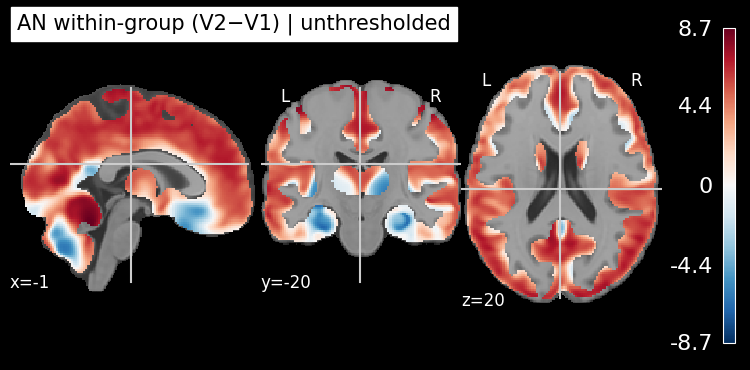

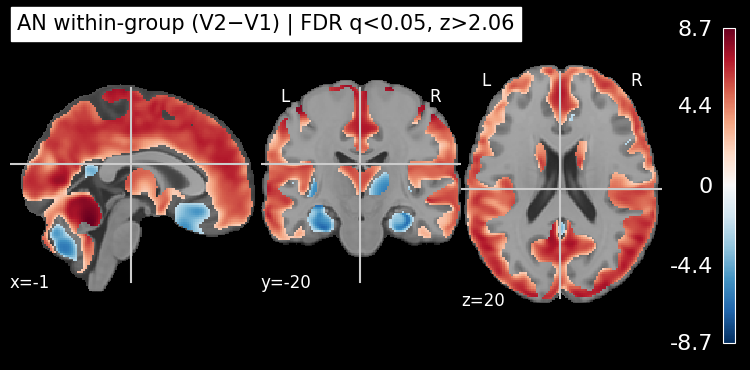

Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_within_v2_minus_v1/VBM_AN_within_V2minusV1_FDR05_increases.nii.gz
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_within_v2_minus_v1/VBM_AN_within_V2minusV1_FDR05_decreases.nii.gz


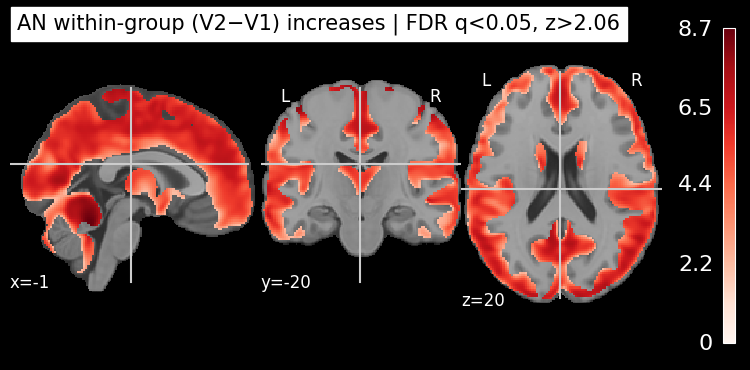

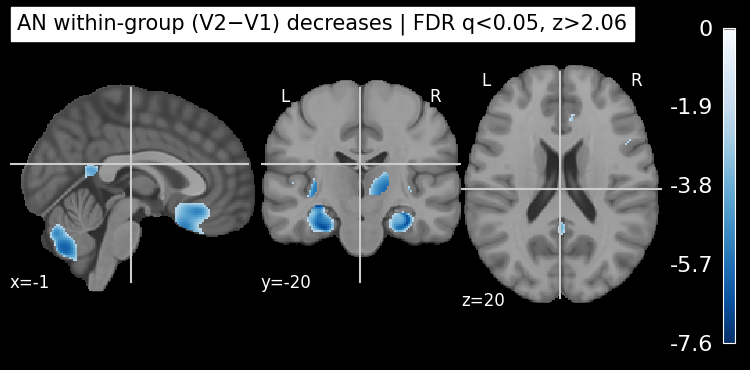

   Cluster ID     X     Y     Z  Peak Stat Cluster Size (mm3)
0           1  -3.0 -49.5 -22.5   8.709470             718308
1          1a  -6.0 -66.0   3.0   8.581442                   
2          1b -13.5 -49.5 -15.0   8.416694                   
3          1c  54.0 -13.5  52.5   8.296274                   
4           5 -18.0 -69.0 -51.0  -7.589498              69545
5          5a  25.5 -75.0 -33.0  -7.429173                   
6          5b  15.0 -72.0 -40.5  -7.396462                   
7          5c -16.5 -73.5 -43.5  -7.356152                   
8           6  27.0 -12.0  -7.5  -7.425749              17647
9          6a  33.0 -16.5 -25.5  -7.215563                   
10         6b  34.5 -22.5 -18.0  -6.652274                   
11         6c  16.5 -16.5   1.5  -6.014816                   
12          7 -31.5 -18.0 -10.5  -6.995388              18970
13         7a -28.5  -9.0 -12.0  -6.930076                   
14         7b -27.0 -19.5 -25.5  -6.845403                   
15      

In [180]:
from pathlib import Path
import numpy as np
import pandas as pd

from nilearn import datasets, plotting
from nilearn.image import load_img, mean_img, math_img, resample_to_img
from nilearn.masking import apply_mask
from nilearn.reporting import get_clusters_table

# =========================================================
# AN within-group longitudinal V2 - V1
# names changed to avoid overlap with disease-specific results
# =========================================================

# 1) paired AN subjects
wide_AN_within = utils_smri.make_paired_path_table(
    df_imgs=df_all_sv,
    group="AN",
    baseline=1,
    followup=2,
)

diff_imgs_AN_within, subjects_AN_within = utils_smri.build_difference_images(
    wide_paths=wide_AN_within,
    baseline=1,
    followup=2,
    expr="img2 - img1",
    verbose=True,
)

print("AN paired subjects:", len(wide_AN_within))

# 2) mask from original GM maps, not diff maps
all_paths_AN_within = wide_AN_within[1].tolist() + wide_AN_within[2].tolist()
mean_gm_AN_within = mean_img([load_img(p) for p in all_paths_AN_within])

mask_img_AN_within = math_img("img > 0.3", img=mean_gm_AN_within)
mask_img_AN_within = math_img("img.astype(int)", img=mask_img_AN_within)

print("Mask voxels:", int(mask_img_AN_within.get_fdata().sum()))

# 3) one-sample model
slm_AN_within, z_map_AN_within, design_AN_within = utils_smri.run_second_level_one_sample(
    imgs=diff_imgs_AN_within,
    mask_img=mask_img_AN_within,
    smoothing_fwhm=None,
    output_type="z_score",
)

print(design_AN_within.head())

# 4) save z-map
out_dir_AN_within = Path(
    "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_within_v2_minus_v1"
)
out_dir_AN_within.mkdir(parents=True, exist_ok=True)

utils_smri.save_nifti(
    z_map_AN_within,
    out_dir_AN_within / "VBM_AN_within_V2minusV1_parametric_zmap.nii.gz"
)

# 5) FDR threshold
z_fdr_AN_within, z_thr_AN_within = utils_smri.threshold_map(
    z_map_AN_within,
    alpha=0.05,
    height_control="fdr",
    two_sided=True,
)

utils_smri.save_nifti(
    z_fdr_AN_within,
    out_dir_AN_within / "VBM_AN_within_V2minusV1_parametric_zmap_FDR05.nii.gz"
)

print("FDR threshold:", z_thr_AN_within)

# 6) plot whole-brain maps
mni = datasets.load_mni152_template()

plotting.plot_stat_map(
    z_map_AN_within,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    title="AN within-group (V2−V1) | unthresholded"
)
plotting.show()

plotting.plot_stat_map(
    z_fdr_AN_within,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    symmetric_cbar=True,
    title=(
        f"AN within-group (V2−V1) | FDR q<0.05, z>{z_thr_AN_within:.2f}"
        if z_thr_AN_within is not None else
        "AN within-group (V2−V1) | no voxels survive FDR"
    )
)
plotting.show()

# 7) split increases / decreases
if z_thr_AN_within is not None:

    z_inc_AN_within = math_img("z * (z > 0)", z=z_fdr_AN_within)
    z_dec_AN_within = math_img("z * (z < 0)", z=z_fdr_AN_within)

    out_inc_AN_within = out_dir_AN_within / "VBM_AN_within_V2minusV1_FDR05_increases.nii.gz"
    out_dec_AN_within = out_dir_AN_within / "VBM_AN_within_V2minusV1_FDR05_decreases.nii.gz"

    utils_smri.save_nifti(z_inc_AN_within, out_inc_AN_within)
    utils_smri.save_nifti(z_dec_AN_within, out_dec_AN_within)

    print("Saved:", out_inc_AN_within)
    print("Saved:", out_dec_AN_within)

else:
    print("No voxels survived FDR.")

# 8) plot increases / decreases
if z_thr_AN_within is not None:

    plotting.plot_stat_map(
        z_inc_AN_within,
        bg_img=mni,
        threshold=1e-6,
        display_mode="ortho",
        cut_coords=(-1, -20, 20),
        cmap="Reds",
        colorbar=True,
        title=f"AN within-group (V2−V1) increases | FDR q<0.05, z>{z_thr_AN_within:.2f}"
    )
    plotting.show()

    plotting.plot_stat_map(
        z_dec_AN_within,
        bg_img=mni,
        threshold=1e-6,
        display_mode="ortho",
        cut_coords=(-1, -20, 20),
        cmap="Blues_r",
        colorbar=True,
        title=f"AN within-group (V2−V1) decreases | FDR q<0.05, z>{z_thr_AN_within:.2f}"
    )
    plotting.show()

# 9) clusters
cluster_k_AN_within = 1000

clusters_AN_within = get_clusters_table(
    stat_img=z_fdr_AN_within,
    stat_threshold=1e-6,
    cluster_threshold=cluster_k_AN_within,
    two_sided=True
)

print(clusters_AN_within)

# optional save
clusters_AN_within.to_csv(
    out_dir_AN_within / f"clusters_AN_within_V2minusV1_k{cluster_k_AN_within}.csv",
    index=False
)

## 10) ROI summary
roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")

roi_keep = [
    "ACC_rostral",
    "Cingulate_Gyrus_anterior_division",
    "Cingulate_Gyrus_posterior_division",
    "cerebellum_L",
    "cerebellum_R",
    "cerebellum_whole",
    "Hypothalamus",
    "Insular_Cortex",
    "Left_Amygdala",
    "NACC_L",
    "NACC_R",
    "OFC_lateral",
    "OFC_medial",
    "PFC_union",
    "Paracingulate_Gyrus",
    "Right_Amygdala",
    "caudate_L",
    "caudate_R",
    "putamen_L",
    "putamen_R",
    "thalamus_L",
    "thalamus_R",
]

roi_keep = set(roi_keep)

rows_AN_within = []

for rp in sorted(roi_dir.glob("*.nii*")):
    roi_name = rp.stem.replace("_bin", "")

    if roi_name not in roi_keep:
        continue

    roi = load_img(rp)

    # Resample ROI to z-map space
    roi_rs = resample_to_img(roi, z_map_AN_within, interpolation="nearest")

    # Binarize ROI
    roi_bin = math_img("img > 0", img=roi_rs)

    # Skip empty ROI
    n_vox = int(roi_bin.get_fdata().sum())
    if n_vox == 0:
        continue

    # Values inside ROI
    z_vals = apply_mask(z_map_AN_within, roi_bin)

    # Significant values
    zsig_vals = apply_mask(z_fdr_AN_within, roi_bin)

    sig_mask = (zsig_vals != 0)
    sig_pos = (zsig_vals > 0)
    sig_neg = (zsig_vals < 0)

    rows_AN_within.append({
        "roi": roi_name,
        "roi_file": rp.name,
        "n_vox": int(z_vals.size),
        "mean_z": float(np.mean(z_vals)),
        "median_z": float(np.median(z_vals)),
        "pct_FDR_sig_voxels": float(sig_mask.mean() * 100),
        "mean_z_sig_voxels": float(np.mean(zsig_vals[sig_mask])) if sig_mask.any() else np.nan,
        "pct_sig_pos": float(sig_pos.mean() * 100),
        "pct_sig_neg": float(sig_neg.mean() * 100),
    })

df_roi_vox_AN_within = pd.DataFrame(rows_AN_within).sort_values(
    "pct_FDR_sig_voxels",
    ascending=False
).reset_index(drop=True)

print(df_roi_vox_AN_within.head(20))

df_roi_vox_AN_within.to_csv(
    out_dir_AN_within / "roi_voxel_summary_AN_within_V2minusV1.csv",
    index=False
)

#### NMH17

In [181]:
import numpy as np
import pandas as pd
import nibabel as nib

from nilearn.image import load_img, resample_to_img

# --------------------------------------------------
# ROIs to report in the manuscript
# --------------------------------------------------

roi_keep = [
    "NACC_L",
    "NACC_R",
    "caudate_L",
    "caudate_R",
    "putamen_L",
    "putamen_R",
    "Insular_Cortex",
    "Left_Amygdala",
    "Right_Amygdala",
    "ACC_rostral",
    "OFC_lateral",
    "OFC_medial",
    "cerebellum_L",
    "cerebellum_R",
    "cerebellum_whole"
]

rows = []

z_data = z_fdr_AN_within.get_fdata()

for rp in sorted(roi_dir.glob("*.nii*")):

    roi_name = rp.stem.replace("_bin", "")

    if roi_name not in roi_keep:
        continue

    roi = load_img(rp)

    roi_rs = resample_to_img(
        roi,
        z_map_AN_within,
        interpolation="nearest"
    )

    roi_data = roi_rs.get_fdata() > 0

    sig_roi = roi_data & (z_data != 0)

    if sig_roi.sum() == 0:
        continue

    z_vals = z_data[sig_roi]

    # peak absolute Z within ROI
    peak_idx = np.argmax(np.abs(z_vals))
    peak_vox = np.argwhere(sig_roi)[peak_idx]

    peak_mni = nib.affines.apply_affine(
        z_fdr_AN_within.affine,
        peak_vox
    )

    peak_stat = z_data[tuple(peak_vox)]

    pct_pos = 100 * np.mean(z_vals > 0)
    pct_neg = 100 * np.mean(z_vals < 0)

    if pct_pos > pct_neg:
        direction = "V2 > V1"
    elif pct_neg > pct_pos:
        direction = "V2 < V1"
    else:
        direction = "Mixed"

    rows.append({
        "Brain region": roi_name,
        "Side": (
            "L" if peak_mni[0] < 0 else
            "R" if peak_mni[0] > 0 else
            "Midline"
        ),
        "x": peak_mni[0],
        "y": peak_mni[1],
        "z": peak_mni[2],
        "Peak Z": peak_stat,
        "ROI voxels": int(roi_data.sum()),
        "Significant voxels": int(sig_roi.sum()),
        "% significant": 100 * sig_roi.sum() / roi_data.sum(),
        "% V2 > V1": pct_pos,
        "% V2 < V1": pct_neg,
        "Direction": direction,
    })

df_roi_mni_table = (
    pd.DataFrame(rows)
    .sort_values("% significant", ascending=False)
    .reset_index(drop=True)
)

df_roi_mni_table

,Brain region,Side,x,y,z,Peak Z,ROI voxels,Significant voxels,% significant,% V2 > V1,% V2 < V1,Direction
0,NACC_L,L,-10.5,15.0,-4.5,6.943033,229,228,99.563319,100.000000,0.000000,V2 > V1
1,NACC_R,R,9.0,16.5,-3.0,6.022848,202,198,98.019802,100.000000,0.000000,V2 > V1
2,caudate_L,L,-12.0,15.0,0.0,7.117943,1175,953,81.106383,100.000000,0.000000,V2 > V1
3,caudate_R,R,10.5,1.5,16.5,6.468824,1223,937,76.614881,100.000000,0.000000,V2 > V1
4,Insular_Cortex,L,-36.0,-12.0,-3.0,-6.700333,6344,4400,69.356873,67.886364,32.113636,V2 > V1
5,putamen_L,L,-28.5,-10.5,-10.5,-6.866167,1897,1297,68.371112,50.115652,49.884348,V2 > V1
6,Left_Amygdala,L,-27.0,-9.0,-13.5,-6.765139,727,495,68.088033,30.101010,69.898990,V2 < V1
7,putamen_R,R,27.0,-10.5,-6.0,-7.320737,1867,1266,67.809320,42.338073,57.661927,V2 < V1
8,Right_Amygdala,R,27.0,-7.5,-12.0,-6.419685,842,568,67.458432,24.823944,75.176056,V2 < V1
9,cerebellum_L,L,-3.0,-49.5,-21.0,8.647482,26107,16563,63.442755,45.112600,54.887400,V2 < V1


In [182]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

from nilearn.image import load_img, math_img, resample_to_img
from nilearn.masking import apply_mask
from nilearn.plotting import plot_stat_map, find_xyz_cut_coords


# =========================================================
# USER INPUTS
# =========================================================

min_pct_sig_AN_within = 50
min_n_vox_AN_within = 100

# within-group longitudinal map:
# False -> positive = increases, negative = decreases
# True  -> flip sign if you want decreases to appear positive
flip_sign_AN_within = False

roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")
fig_dir_AN_within = Path(out_dir_AN_within) / "impacted_roi_voxel_figures"
fig_dir_AN_within.mkdir(parents=True, exist_ok=True)


# =========================================================
# 1) choose impacted ROIs from df_roi_vox_AN_within
# =========================================================

df_impacted_AN_within = (
    df_roi_vox_AN_within.loc[
        (df_roi_vox_AN_within["pct_FDR_sig_voxels"] >= min_pct_sig_AN_within) &
        (df_roi_vox_AN_within["n_vox"] >= min_n_vox_AN_within)
    ]
    .sort_values("pct_FDR_sig_voxels", ascending=False)
    .copy()
)

print("Impacted ROIs (AN within):")
print(
    df_impacted_AN_within[
        ["roi_file", "n_vox", "pct_FDR_sig_voxels", "mean_z", "pct_sig_pos", "pct_sig_neg"]
    ]
)

impacted_roi_files_AN_within = df_impacted_AN_within["roi_file"].tolist()

print("\nSelected ROI files (AN within):")
print(impacted_roi_files_AN_within)

df_impacted_AN_within.to_csv(
    fig_dir_AN_within / "impacted_rois_table_AN_within.csv",
    index=False
)


# =========================================================
# 2) helpers
# =========================================================

def load_bin_roi_in_stat_space(roi_path, stat_img):
    roi = load_img(roi_path)
    roi_rs = resample_to_img(roi, stat_img, interpolation="nearest")
    roi_bin = math_img("img > 0", img=roi_rs)
    return roi_bin

def combine_roi_imgs(roi_img_list):
    combined = None
    for roi_img in roi_img_list:
        if combined is None:
            combined = roi_img
        else:
            combined = math_img(
                "(img1 > 0) | (img2 > 0)",
                img1=combined,
                img2=roi_img
            )
    if combined is None:
        return None
    return math_img("img > 0", img=combined)

def make_masked_stat_img(stat_img, roi_mask, flip_sign=False):
    if flip_sign:
        return math_img("(-z) * roi", z=stat_img, roi=roi_mask)
    return math_img("z * roi", z=stat_img, roi=roi_mask)

def save_roi_figure(stat_img_masked, roi_mask, title, out_png, bg_img, threshold=1e-6):
    vals = apply_mask(stat_img_masked, roi_mask)
    if np.count_nonzero(vals) == 0:
        print(f"[SKIP] No significant voxels for {out_png.name}")
        return False

    cut_coords = find_xyz_cut_coords(roi_mask)

    display = plot_stat_map(
        stat_img_masked,
        bg_img=bg_img,
        threshold=threshold,
        display_mode="ortho",
        cut_coords=cut_coords,
        symmetric_cbar=True,
        colorbar=True,
        title=title
    )
    display.savefig(str(out_png), dpi=300)
    display.close()
    print("Saved:", out_png)
    return True

def strip_nii(fname):
    return re.sub(r"\.nii(\.gz)?$", "", fname)

def get_bilateral_base_name(fname):
    """
    Examples:
    NACC_L_bin.nii      -> NACC_bin
    NACC_R_bin.nii      -> NACC_bin
    dCa_L.nii           -> dCa
    dCa_R.nii           -> dCa
    OFC_lateral_bin.nii -> OFC_lateral_bin
    """
    base = strip_nii(fname)
    base = re.sub(r"_L(_bin)?$", r"\1", base)
    base = re.sub(r"_R(_bin)?$", r"\1", base)
    return base


# =========================================================
# 3) combined figure for all impacted ROIs
# =========================================================

roi_imgs_all_AN_within = []
found_all_AN_within = []

for fname in impacted_roi_files_AN_within:
    rp = roi_dir / fname
    if not rp.exists():
        print(f"[MISSING] {fname}")
        continue

    roi_bin = load_bin_roi_in_stat_space(rp, z_fdr_AN_within)
    roi_imgs_all_AN_within.append(roi_bin)
    found_all_AN_within.append(fname)

print("\nFound impacted ROIs (AN within):")
print(found_all_AN_within)

roi_combined_all_AN_within = combine_roi_imgs(roi_imgs_all_AN_within)

if roi_combined_all_AN_within is None:
    raise ValueError("No impacted ROI could be loaded for AN within-group analysis.")

roi_sig_all_AN_within = make_masked_stat_img(
    z_fdr_AN_within,
    roi_combined_all_AN_within,
    flip_sign=flip_sign_AN_within
)

save_roi_figure(
    stat_img_masked=roi_sig_all_AN_within,
    roi_mask=roi_combined_all_AN_within,
    title=f"AN within-group impacted ROIs (V2−V1) | FDR q<0.05 | n={len(found_all_AN_within)} ROIs",
    out_png=fig_dir_AN_within / "all_impacted_rois_AN_within_masked_statmap.png",
    bg_img=mni,
)


# =========================================================
# 4) bilateral groups automatically and save each
# =========================================================

bilateral_groups_AN_within = {}
for fname in impacted_roi_files_AN_within:
    base_name = get_bilateral_base_name(fname)
    bilateral_groups_AN_within.setdefault(base_name, []).append(fname)

print("\nBilateral groups (AN within):")
for k, v in bilateral_groups_AN_within.items():
    print(k, "->", v)

rows_groups_AN_within = []

for group_name, file_list in bilateral_groups_AN_within.items():

    roi_imgs_group = []
    found_group = []

    for fname in file_list:
        rp = roi_dir / fname
        if not rp.exists():
            print(f"[MISSING] {fname}")
            continue

        roi_bin = load_bin_roi_in_stat_space(rp, z_fdr_AN_within)
        roi_imgs_group.append(roi_bin)
        found_group.append(fname)

    roi_group_mask = combine_roi_imgs(roi_imgs_group)
    if roi_group_mask is None:
        continue

    roi_group_sig = make_masked_stat_img(
        z_fdr_AN_within,
        roi_group_mask,
        flip_sign=flip_sign_AN_within
    )

    sig_vals = apply_mask(roi_group_sig, roi_group_mask)
    nonzero = np.count_nonzero(sig_vals)

    out_png = fig_dir_AN_within / f"{group_name}_AN_within_bilateral_masked_statmap.png"

    saved = save_roi_figure(
        stat_img_masked=roi_group_sig,
        roi_mask=roi_group_mask,
        title=f"{group_name} | AN within-group (V2−V1) | FDR q<0.05",
        out_png=out_png,
        bg_img=mni,
    )

    rows_groups_AN_within.append({
        "group_name": group_name,
        "roi_files": ", ".join(found_group),
        "n_roi_files": len(found_group),
        "n_nonzero_sig_voxels": int(nonzero),
        "saved_png": str(out_png) if saved else "",
    })

df_bilateral_groups_AN_within = pd.DataFrame(rows_groups_AN_within).sort_values(
    ["n_nonzero_sig_voxels", "n_roi_files"],
    ascending=[False, False]
)

print("\nSaved bilateral/group figures summary (AN within):")
print(df_bilateral_groups_AN_within)

df_bilateral_groups_AN_within.to_csv(
    fig_dir_AN_within / "bilateral_group_figures_summary_AN_within.csv",
    index=False
)

Impacted ROIs (AN within):
                                      roi_file  n_vox  pct_FDR_sig_voxels  \
0                               NACC_L_bin.nii    229           99.563319   
1                               NACC_R_bin.nii    202           98.019802   
2                            caudate_L_bin.nii   1175           81.106383   
3                            caudate_R_bin.nii   1223           76.614881   
4                  Paracingulate_Gyrus_bin.nii   6884           72.428820   
5   Cingulate_Gyrus_posterior_division_bin.nii   5690           70.492091   
6                       Insular_Cortex_bin.nii   6344           69.356873   
7                            putamen_L_bin.nii   1897           68.371112   
8                        Left_Amygdala_bin.nii    727           68.088033   
9                            putamen_R_bin.nii   1867           67.809320   
10                      Right_Amygdala_bin.nii    842           67.458432   
11                        cerebellum_L_bin.nii  2

In [183]:
from pathlib import Path
import re
import numpy as np
import pandas as pd

from nilearn.image import load_img, math_img, resample_to_img
from nilearn.masking import apply_mask
from nilearn.plotting import plot_stat_map, find_xyz_cut_coords


# =========================================================
# USER INPUTS
# =========================================================

min_pct_sig_AN_within = 50
min_n_vox_AN_within = 100

flip_sign_AN_within = False

roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")
fig_dir_AN_within = Path(out_dir_AN_within) / "putamen_caudate_voxel_figures"
fig_dir_AN_within.mkdir(parents=True, exist_ok=True)


# =========================================================
# 1) KEEP ONLY PUTAMEN + CAUDATE
# =========================================================

df_impacted_AN_within = (
    df_roi_vox_AN_within.loc[
        (df_roi_vox_AN_within["pct_FDR_sig_voxels"] >= min_pct_sig_AN_within) &
        (df_roi_vox_AN_within["n_vox"] >= min_n_vox_AN_within) &
        (
            df_roi_vox_AN_within["roi_file"].str.contains("putamen", case=False, na=False) |
            df_roi_vox_AN_within["roi_file"].str.contains("caudate", case=False, na=False)
        )
    ]
    .sort_values("pct_FDR_sig_voxels", ascending=False)
    .copy()
)

print("Selected putamen/caudate ROIs:")
print(
    df_impacted_AN_within[
        ["roi_file", "n_vox", "pct_FDR_sig_voxels", "mean_z", "pct_sig_pos", "pct_sig_neg"]
    ]
)

impacted_roi_files_AN_within = df_impacted_AN_within["roi_file"].tolist()


# =========================================================
# 2) HELPERS
# =========================================================

def load_bin_roi_in_stat_space(roi_path, stat_img):
    roi = load_img(roi_path)
    roi_rs = resample_to_img(roi, stat_img, interpolation="nearest")
    return math_img("img > 0", img=roi_rs)

def combine_roi_imgs(roi_img_list):
    combined = None

    for roi_img in roi_img_list:
        if combined is None:
            combined = roi_img
        else:
            combined = math_img(
                "(img1 > 0) | (img2 > 0)",
                img1=combined,
                img2=roi_img
            )

    if combined is None:
        return None

    return math_img("img > 0", img=combined)

def make_masked_stat_img(stat_img, roi_mask, flip_sign=False):
    if flip_sign:
        return math_img("(-z) * roi", z=stat_img, roi=roi_mask)

    return math_img("z * roi", z=stat_img, roi=roi_mask)

def save_roi_figure(stat_img_masked, roi_mask, title, out_png, bg_img, threshold=1e-6):
    vals = apply_mask(stat_img_masked, roi_mask)

    if np.count_nonzero(vals) == 0:
        print(f"[SKIP] No significant voxels for {out_png.name}")
        return False

    cut_coords = find_xyz_cut_coords(roi_mask)

    display = plot_stat_map(
        stat_img_masked,
        bg_img=bg_img,
        threshold=threshold,
        display_mode="ortho",
        cut_coords=cut_coords,
        symmetric_cbar=True,
        colorbar=True,
        title=title
    )

    display.savefig(str(out_png), dpi=300)
    display.close()

    print("Saved:", out_png)
    return True

def strip_nii(fname):
    return re.sub(r"\.nii(\.gz)?$", "", fname)

def get_bilateral_base_name(fname):
    base = strip_nii(fname)
    base = re.sub(r"_L(_bin)?$", r"\1", base)
    base = re.sub(r"_R(_bin)?$", r"\1", base)
    return base

def get_region_title(group_name):
    if "putamen" in group_name.lower():
        return "Putamen"
    if "caudate" in group_name.lower():
        return "Caudate"
    return group_name


# =========================================================
# 3) GROUP L/R TOGETHER
# =========================================================

bilateral_groups_AN_within = {}

for fname in impacted_roi_files_AN_within:
    base_name = get_bilateral_base_name(fname)
    bilateral_groups_AN_within.setdefault(base_name, []).append(fname)

print("\nBilateral groups:")
for k, v in bilateral_groups_AN_within.items():
    print(k, "->", v)


# =========================================================
# 4) SAVE PUTAMEN AND CAUDATE FIGURES
# =========================================================

rows_groups_AN_within = []

for group_name, file_list in bilateral_groups_AN_within.items():

    roi_imgs_group = []
    found_group = []

    for fname in file_list:

        rp = roi_dir / fname

        if not rp.exists():
            print(f"[MISSING] {fname}")
            continue

        roi_bin = load_bin_roi_in_stat_space(rp, z_fdr_AN_within)

        roi_imgs_group.append(roi_bin)
        found_group.append(fname)

    roi_group_mask = combine_roi_imgs(roi_imgs_group)

    if roi_group_mask is None:
        continue

    roi_group_sig = make_masked_stat_img(
        z_fdr_AN_within,
        roi_group_mask,
        flip_sign=flip_sign_AN_within
    )

    sig_vals = apply_mask(roi_group_sig, roi_group_mask)
    nonzero = np.count_nonzero(sig_vals)

    region_title = get_region_title(group_name)

    out_png = fig_dir_AN_within / f"{group_name}_AN_within_bilateral_masked_statmap.png"

    saved = save_roi_figure(
        stat_img_masked=roi_group_sig,
        roi_mask=roi_group_mask,
        title=region_title,
        out_png=out_png,
        bg_img=mni
    )

    rows_groups_AN_within.append({
        "group_name": group_name,
        "roi_files": ", ".join(found_group),
        "n_roi_files": len(found_group),
        "n_nonzero_sig_voxels": int(nonzero),
        "saved_png": str(out_png) if saved else "",
    })


df_bilateral_groups_AN_within = pd.DataFrame(rows_groups_AN_within)

print("\nSaved putamen/caudate figures:")
print(df_bilateral_groups_AN_within)

Selected putamen/caudate ROIs:
            roi_file  n_vox  pct_FDR_sig_voxels    mean_z  pct_sig_pos  \
2  caudate_L_bin.nii   1175           81.106383  3.789021    81.106383   
3  caudate_R_bin.nii   1223           76.614881  3.404921    76.614881   
7  putamen_L_bin.nii   1897           68.371112 -0.167428    34.264628   
9  putamen_R_bin.nii   1867           67.809320 -0.753587    28.709159   

   pct_sig_neg  
2     0.000000  
3     0.000000  
7    34.106484  
9    39.100161  

Bilateral groups:
caudate_bin -> ['caudate_L_bin.nii', 'caudate_R_bin.nii']
putamen_bin -> ['putamen_L_bin.nii', 'putamen_R_bin.nii']
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_within_v2_minus_v1/putamen_caudate_voxel_figures/caudate_bin_AN_within_bilateral_masked_statmap.png
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_within_v2_minus_v1/putamen_caudate_voxel_figures/putamen_bin_AN_within_bilateral_masked_statmap.png

Saved putamen/caudate figures:
    group_name            

#### NMH5

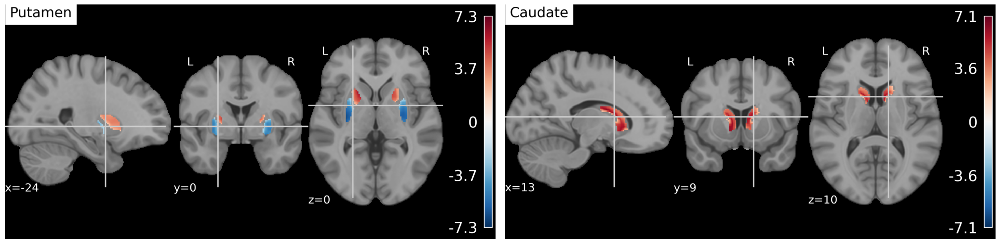

Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_within_v2_minus_v1/putamen_caudate_voxel_figures/Putamen_Caudate_AN_within_combined.png


In [184]:
from PIL import Image
import matplotlib.pyplot as plt

putamen_png = fig_dir_AN_within / "putamen_bin_AN_within_bilateral_masked_statmap.png"
caudate_png = fig_dir_AN_within / "caudate_bin_AN_within_bilateral_masked_statmap.png"

img_putamen = Image.open(putamen_png)
img_caudate = Image.open(caudate_png)

fig, axes = plt.subplots(1, 2, figsize=(20, 5))

axes[0].imshow(img_putamen)
axes[0].axis("off")

axes[1].imshow(img_caudate)
axes[1].axis("off")

plt.subplots_adjust(wspace=0.02, left=0, right=1, top=1, bottom=0)

out_combined = fig_dir_AN_within / "Putamen_Caudate_AN_within_combined.png"

plt.savefig(out_combined, dpi=300, bbox_inches="tight", pad_inches=0)
plt.show()

print("Saved:", out_combined)

#### NMH8

Processing: Putamen L
Processing: Putamen R
Processing: Caudate L
Processing: Caudate R


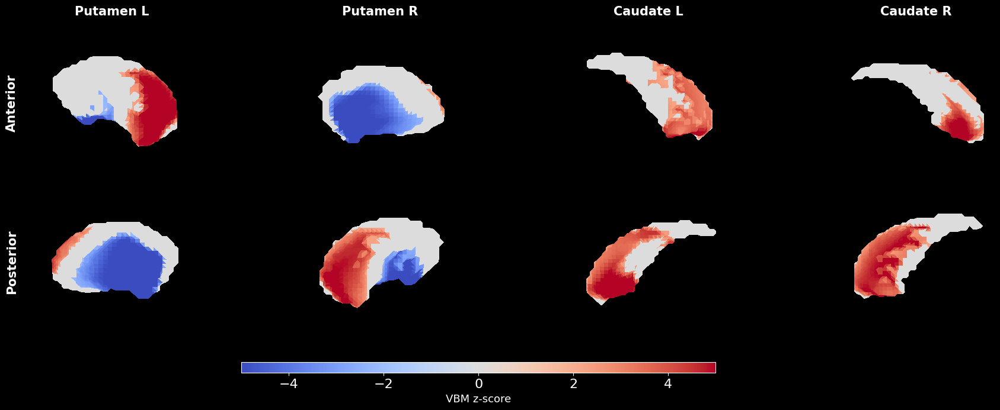

Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_within_v2_minus_v1/VBM_putamen_caudate_AP.png


In [185]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

from nilearn import image
from skimage import measure
from scipy.ndimage import map_coordinates
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# =====================================================
# PATHS
# =====================================================

roi_dir = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI"

out_dir = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_within_v2_minus_v1"
os.makedirs(out_dir, exist_ok=True)

zmap_path = os.path.join(
    out_dir,
    "VBM_AN_within_V2minusV1_parametric_zmap_FDR05.nii.gz"
)

z_img = image.load_img(zmap_path)

# =====================================================
# ROIs
# =====================================================

roi_paths = {
    "Putamen L": os.path.join(roi_dir, "putamen_L_bin.nii"),
    "Putamen R": os.path.join(roi_dir, "putamen_R_bin.nii"),
    "Caudate L": os.path.join(roi_dir, "caudate_L_bin.nii"),
    "Caudate R": os.path.join(roi_dir, "caudate_R_bin.nii"),
}

# =====================================================
# SETTINGS
# =====================================================

views = {
    "Anterior": (20, 0),
    "Posterior": (20, 180),
}

roi_order = [
    "Putamen L",
    "Putamen R",
    "Caudate L",
    "Caudate R",
]

z_threshold = 2.15
vlim = 5

# =====================================================
# FUNCTIONS
# =====================================================

def create_mesh_and_values(roi_path, z_img):

    roi_img = image.load_img(roi_path)

    roi_rs = image.resample_to_img(
        roi_img,
        z_img,
        interpolation="nearest",
        force_resample=True,
        copy_header=True
    )

    roi_data = roi_rs.get_fdata() > 0
    z_data = z_img.get_fdata()

    verts, faces, normals, values = measure.marching_cubes(
        roi_data.astype(float),
        level=0.5
    )

    z_vals = map_coordinates(
        z_data,
        verts.T,
        order=1,
        mode="nearest"
    )

    face_vals = z_vals[faces].mean(axis=1)

    verts_world = nib.affines.apply_affine(
        roi_rs.affine,
        verts
    )

    return verts_world, faces, face_vals


def plot_mesh_on_ax(
    ax,
    verts_world,
    faces,
    face_vals,
    elev,
    azim,
    vlim=5,
    z_threshold=2.15
):

    vals = face_vals.copy()
    vals[np.abs(vals) < z_threshold] = 0

    cmap = plt.cm.coolwarm
    norm = plt.Normalize(vmin=-vlim, vmax=vlim)

    face_colors = cmap(norm(vals))

    mesh = Poly3DCollection(
        verts_world[faces],
        facecolors=face_colors,
        edgecolors="none",
        linewidths=0,
        antialiased=False
    )

    ax.add_collection3d(mesh)

    ax.set_xlim(verts_world[:, 0].min(), verts_world[:, 0].max())
    ax.set_ylim(verts_world[:, 1].min(), verts_world[:, 1].max())
    ax.set_zlim(verts_world[:, 2].min(), verts_world[:, 2].max())

    ax.view_init(elev=elev, azim=azim)

    ax.set_axis_off()
    ax.set_box_aspect([
        np.ptp(verts_world[:, 0]),
        np.ptp(verts_world[:, 1]),
        np.ptp(verts_world[:, 2])
    ])

    ax.set_facecolor("black")


# =====================================================
# PRECOMPUTE MESHES
# =====================================================

meshes = {}

for name, path in roi_paths.items():
    print("Processing:", name)
    meshes[name] = create_mesh_and_values(path, z_img)

# =====================================================
# FIGURE
# =====================================================

fig = plt.figure(figsize=(20, 7), facecolor="black")

for row, (view_name, (elev, azim)) in enumerate(views.items()):

    for col, roi_name in enumerate(roi_order):

        ax = fig.add_subplot(
            2,
            4,
            row * 4 + col + 1,
            projection="3d"
        )

        verts_world, faces, face_vals = meshes[roi_name]

        plot_mesh_on_ax(
            ax=ax,
            verts_world=verts_world,
            faces=faces,
            face_vals=face_vals,
            elev=elev,
            azim=azim,
            vlim=vlim,
            z_threshold=z_threshold
        )

        if row == 0:
            ax.set_title(
                roi_name,
                color="white",
                fontsize=15,
                fontweight="bold",
                pad=12
            )

        if col == 0:
            ax.text2D(
                -0.18,
                0.5,
                view_name,
                transform=ax.transAxes,
                color="white",
                fontsize=15,
                fontweight="bold",
                rotation=90,
                va="center"
            )

# =====================================================
# COLORBAR
# =====================================================

cmap = plt.cm.coolwarm
norm = plt.Normalize(vmin=-vlim, vmax=vlim)

cax = fig.add_axes([0.30, 0.06, 0.40, 0.025])

cb = plt.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cax,
    orientation="horizontal"
)

cb.set_label("VBM z-score", color="white", fontsize=13)
cb.ax.tick_params(colors="white")

for spine in cb.ax.spines.values():
    spine.set_edgecolor("white")

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.90,
    bottom=0.14,
    wspace=0.02,
    hspace=0.02
)

out_png = os.path.join(
    out_dir,
    "VBM_putamen_caudate_AP.png"
)

plt.savefig(
    out_png,
    dpi=300,
    facecolor="black",
    bbox_inches="tight"
)

plt.show()

print("Saved:", out_png)

### normal change

Number of paired HC subjects: 28
[001] subject 1 done
[002] subject 2 done
[003] subject 3 done
[004] subject 4 done
[005] subject 38 done
[006] subject 39 done
[007] subject 40 done
[008] subject 42 done
[009] subject 43 done
[010] subject 44 done
[011] subject 45 done
[012] subject 46 done
[013] subject 48 done
[014] subject 49 done
[015] subject 50 done
[016] subject 52 done
[017] subject 64 done
[018] subject 65 done
[019] subject 66 done
[020] subject 67 done
[021] subject 68 done
[022] subject 69 done
[023] subject 70 done
[024] subject 71 done
[025] subject 72 done
[026] subject 83 done
[027] subject 84 done
[028] subject 85 done
Number of difference images: 28
Number of subjects: 28


/tmp/ipykernel_185855/1588921428.py:26: UserWarning: Data array used to create a new image contains 64-bit ints. This is likely due to creating the array with numpy and passing `int` as the `dtype`. Many tools such as FSL and SPM cannot deal with int64 in Nifti images, so for compatibility the data has been converted to int32.
  mask_img = math_img("img.astype(int)", img=mask_img)


Mask voxels: 328085


/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/utils_smri.py:1017: UserWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  slm = slm.fit(imgs, design_matrix=design)


   intercept
0        1.0
1        1.0
2        1.0
3        1.0
4        1.0


/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/utils_smri.py:1170: UserWarning: The given float value must not exceed 4.826145131002908. But, you have given threshold=inf.
  thr_img, thr = threshold_stats_img(


FDR threshold: inf


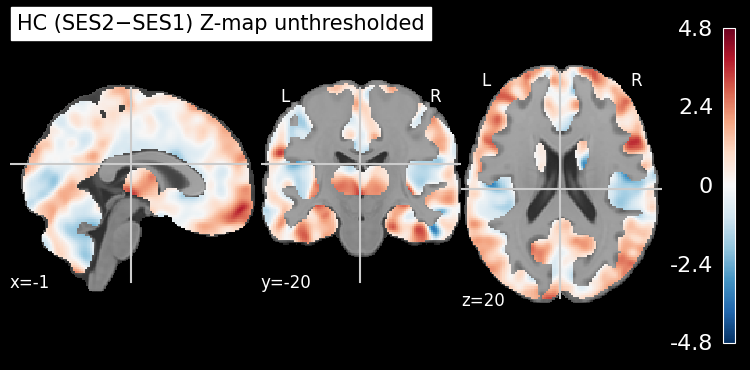

/tmp/ipykernel_185855/1588921428.py:74: UserWarning: empty mask
  plotting.plot_stat_map(


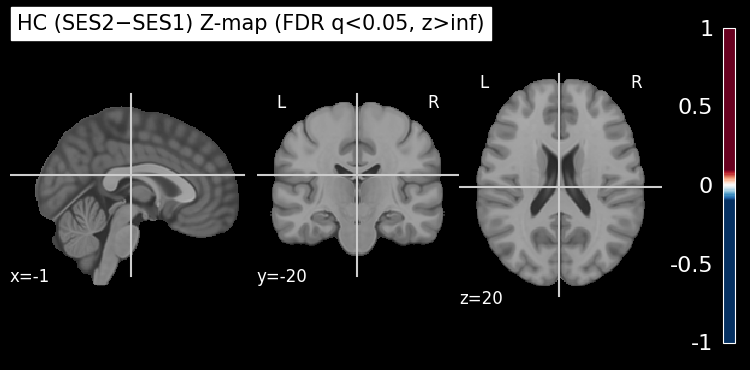

Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/hc_v2_minus_v1/VBM_HC_SES2_minus_SES1_FDR_q05_increases.nii.gz
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/hc_v2_minus_v1/VBM_HC_SES2_minus_SES1_FDR_q05_decreases.nii.gz


/tmp/ipykernel_185855/1588921428.py:111: UserWarning: empty mask
  plotting.plot_stat_map(


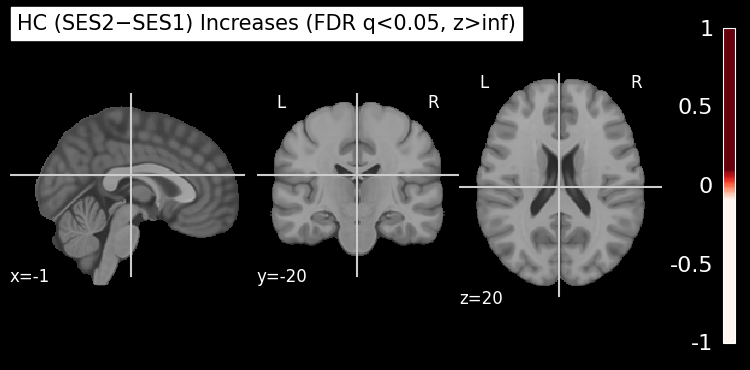

/tmp/ipykernel_185855/1588921428.py:123: UserWarning: empty mask
  plotting.plot_stat_map(


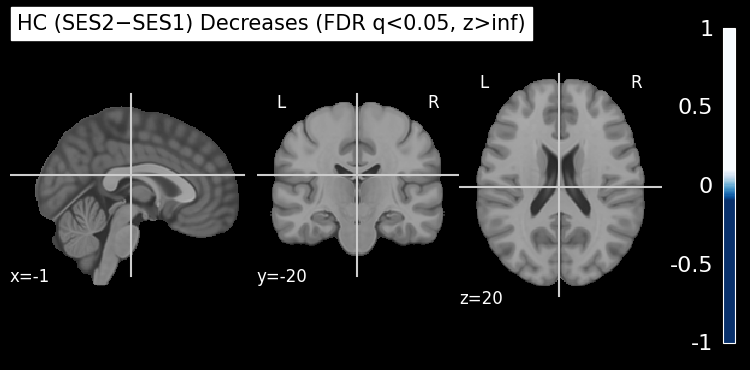

/tmp/ipykernel_185855/1588921428.py:138: UserWarning: The given float value must not exceed 0.0. But, you have given threshold=1e-06.
  clusters = get_clusters_table(
/tmp/ipykernel_185855/1588921428.py:138: UserWarning: No clusters found with stat higher than 1e-06
  clusters = get_clusters_table(
/tmp/ipykernel_185855/1588921428.py:138: UserWarning: No clusters found with stat lower than -1e-06
  clusters = get_clusters_table(


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)


In [187]:

wide_HC = utils_smri.make_paired_path_table(
    df_imgs=df_all_sv,
    group="HC",
    baseline=1,
    followup=2,
)

wide_HC.head()
print("Number of paired HC subjects:", len(wide_HC))

diff_imgs, subjects = utils_smri.build_difference_images(
    wide_paths=wide_HC,
    baseline=1,
    followup=2,
    expr="img2 - img1",
    verbose=True,
)

print("Number of difference images:", len(diff_imgs))
print("Number of subjects:", len(subjects))

all_paths = wide_HC[1].tolist() + wide_HC[2].tolist()
mean_gm = mean_img([load_img(p) for p in all_paths])

mask_img = math_img("img > 0.3", img=mean_gm)
mask_img = math_img("img.astype(int)", img=mask_img)

print("Mask voxels:", int(mask_img.get_fdata().sum()))

slm, z_map, design = utils_smri.run_second_level_one_sample(
    imgs=diff_imgs,
    mask_img=mask_img,
    smoothing_fwhm=None,
    output_type="z_score",
)

print(design.head())

out_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/hc_v2_minus_v1")
out_dir.mkdir(parents=True, exist_ok=True)

utils_smri.save_nifti(
    z_map,
    out_dir / "VBM_HC_SES2_minus_SES1_parametric_zmap.nii.gz"
)

z_fdr, z_thr = utils_smri.threshold_map(
    z_map,
    alpha=0.05,
    height_control="fdr",
    two_sided=True,
)

utils_smri.save_nifti(
    z_fdr,
    out_dir / "VBM_HC_SES2_minus_SES1_parametric_zmap_FDR05.nii.gz"
)

print("FDR threshold:", z_thr)


mni = datasets.load_mni152_template()

plotting.plot_stat_map(
    z_map,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    title="HC (SES2−SES1) Z-map unthresholded"
)
plotting.show()

plotting.plot_stat_map(
    z_fdr,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    symmetric_cbar=True,
    title=(
        f"HC (SES2−SES1) Z-map (FDR q<0.05, z>{z_thr:.2f})"
        if z_thr is not None else
        "HC (SES2−SES1) Z-map (no voxels survive FDR)"
    )
)
plotting.show()

if z_thr is not None:

    # Positive changes: V2 > V1
    z_inc = math_img("z * (z > 0)", z=z_fdr)

    # Negative changes: V2 < V1
    z_dec = math_img("z * (z < 0)", z=z_fdr)

    out_inc = out_dir / "VBM_HC_SES2_minus_SES1_FDR_q05_increases.nii.gz"
    out_dec = out_dir / "VBM_HC_SES2_minus_SES1_FDR_q05_decreases.nii.gz"

    utils_smri.save_nifti(z_inc, out_inc)
    utils_smri.save_nifti(z_dec, out_dec)

    print("Saved:", out_inc)
    print("Saved:", out_dec)

else:
    print("No voxels survived FDR.")

if z_thr is not None:

    plotting.plot_stat_map(
        z_inc,
        bg_img=mni,
        threshold=1e-6,
        display_mode="ortho",
        cut_coords=(-1, -20, 20),
        cmap="Reds",
        colorbar=True,
        title=f"HC (SES2−SES1) Increases (FDR q<0.05, z>{z_thr:.2f})"
    )
    plotting.show()

    plotting.plot_stat_map(
        z_dec,
        bg_img=mni,
        threshold=1e-6,
        display_mode="ortho",
        cut_coords=(-1, -20, 20),
        cmap="Blues_r",
        colorbar=True,
        title=f"HC (SES2−SES1) Decreases (FDR q<0.05, z>{z_thr:.2f})"
    )
    plotting.show()


cluster_k = 1000

clusters = get_clusters_table(
    stat_img=z_fdr,
    stat_threshold=1e-6,
    cluster_threshold=cluster_k,
    two_sided=True
)

clusters

In [188]:
roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")

rows = []

for rp in sorted(roi_dir.glob("*bin*.nii*")):

    roi = load_img(rp)

    # Resample ROI to match z_map space
    roi_rs = resample_to_img(roi, z_map, interpolation="nearest")

    # Binarize ROI
    roi_bin = math_img("img > 0", img=roi_rs)

    # Skip empty ROI
    n_vox = int(roi_bin.get_fdata().sum())
    if n_vox == 0:
        continue

    # Values inside ROI
    z_vals = apply_mask(z_map, roi_bin)

    # Significant voxels
    zsig_vals = apply_mask(z_fdr, roi_bin)

    sig_mask = (zsig_vals != 0)
    sig_pos = (zsig_vals > 0)
    sig_neg = (zsig_vals < 0)

    rows.append({
        "roi_file": rp.name,
        "n_vox": int(z_vals.size),
        "mean_z": float(np.mean(z_vals)),
        "median_z": float(np.median(z_vals)),
        "pct_FDR_sig_voxels": float(sig_mask.mean() * 100),
        "mean_z_sig_voxels": float(np.mean(zsig_vals[sig_mask])) if sig_mask.any() else np.nan,
        "pct_sig_pos": float(sig_pos.mean() * 100),
        "pct_sig_neg": float(sig_neg.mean() * 100),
    })

df_roi_vox_hc = pd.DataFrame(rows).sort_values(
    "pct_FDR_sig_voxels",
    ascending=False
)

df_roi_vox_hc

,roi_file,n_vox,mean_z,median_z,pct_FDR_sig_voxels,mean_z_sig_voxels,pct_sig_pos,pct_sig_neg
0,ACC_rostral_bin.nii,6122,-0.275108,-0.083294,0.0,NaN,0.0,0.0
1,Cingulate_Gyrus_anterior_division_bin.nii,6120,-0.283013,-0.101964,0.0,NaN,0.0,0.0
2,Cingulate_Gyrus_posterior_division_bin.nii,5690,0.516797,0.454191,0.0,NaN,0.0,0.0
3,Hypothalamus_bin.nii,463,0.418527,0.201011,0.0,NaN,0.0,0.0
4,Insular_Cortex_bin.nii,6344,0.229108,0.065133,0.0,NaN,0.0,0.0
5,Left_Amygdala_bin.nii,727,0.581594,0.624753,0.0,NaN,0.0,0.0
6,NACC_L_bin.nii,229,-0.929563,-0.862628,0.0,NaN,0.0,0.0
7,NACC_R_bin.nii,202,-0.381454,-0.425947,0.0,NaN,0.0,0.0
8,OFC_lateral_bin.nii,7489,0.015863,0.000000,0.0,NaN,0.0,0.0
9,OFC_medial_bin.nii,2302,0.799198,0.895242,0.0,NaN,0.0,0.0


### baseline group difference

Number of AN subjects: 41
Number of HC subjects: 28


/tmp/ipykernel_185855/29992084.py:37: UserWarning: Data array used to create a new image contains 64-bit ints. This is likely due to creating the array with numpy and passing `int` as the `dtype`. Many tools such as FSL and SPM cannot deal with int64 in Nifti images, so for compatibility the data has been converted to int32.
  mask_img = math_img("img.astype(int)", img=mask_img)


Mask voxels: 310413
[run_second_level_two_group] N after cleaning: 69
[run_second_level_two_group] missing after cleaning:
path      0
group     0
age       0
TIV_ml    0
dtype: int64
[run_second_level_two_group] design columns: ['intercept', 'group', 'age', 'TIV_ml']
[run_second_level_two_group] group counts:
group
AN    41
HC    28
Name: count, dtype: int64
[run_second_level_two_group] design head:
   intercept  group   age       TIV_ml
0        1.0      0  34.0  1355.317196
1        1.0      0  29.0  1363.021369
2        1.0      0  25.0  1542.801511
3        1.0      0  18.0  1390.881289
4        1.0      0  31.0  1486.842058


/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/utils_smri.py:1127: UserWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  slm = slm.fit(imgs, design_matrix=design)


   intercept  group   age       TIV_ml
0        1.0      0  34.0  1355.317196
1        1.0      0  29.0  1363.021369
2        1.0      0  25.0  1542.801511
3        1.0      0  18.0  1390.881289
4        1.0      0  31.0  1486.842058
FDR threshold: 2.295616161986441


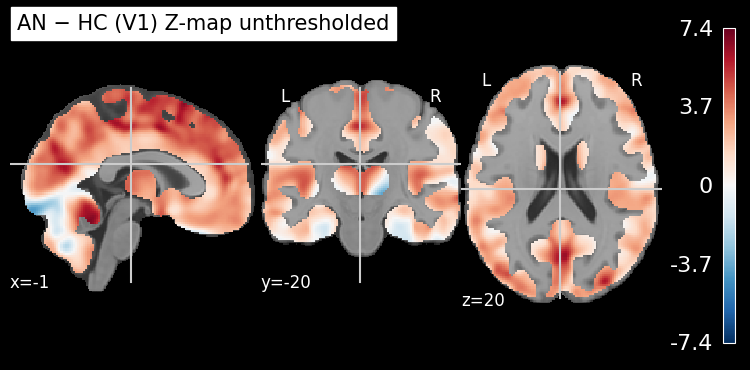

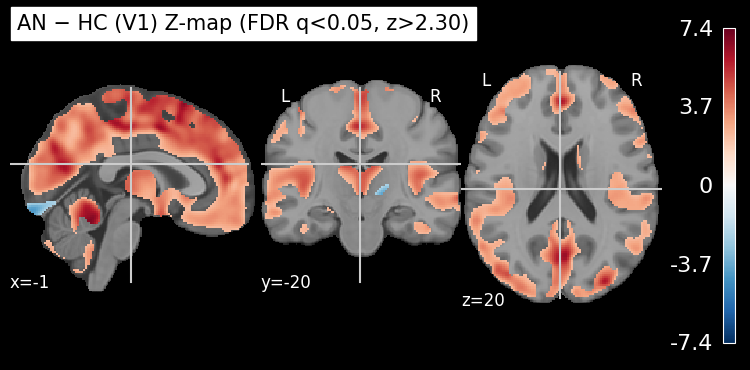

Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_vs_hc_v1/VBM_AN_minus_HC_V1_FDR_q05_positive.nii.gz
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_vs_hc_v1/VBM_AN_minus_HC_V1_FDR_q05_negative.nii.gz


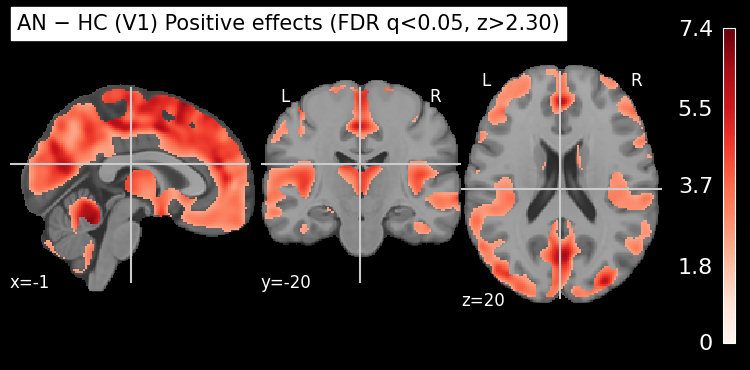

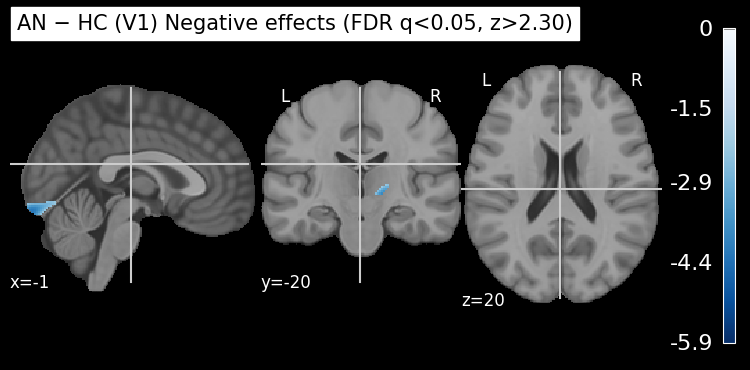

,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)
0,1,-34.5,-82.5,-39.0,7.376691,9291
1,2,-6.0,-49.5,-21.0,7.239135,414834
2,2a,0.0,18.0,63.0,6.864981,
3,2b,0.0,15.0,54.0,6.522261,
4,2c,1.5,-69.0,18.0,6.482979,
5,3,31.5,-85.5,-37.5,6.000429,6993
6,7,19.5,-69.0,-42.0,-5.863354,5146
7,8,-21.0,-66.0,-45.0,-5.840212,4782


In [189]:
df_subject_covars = df_merged_all[
    [
        "subject",
        "session",
        "age",
        "TIV_ml",
        "BMI",
        "hads_depression",
        "ybs_obs",
        "duree_years",
        "remission_v3"
    ]
].drop_duplicates()

df_vbm = utils_smri.build_cross_sectional_vbm_dataset(
    df_paths=df_all_sv,
    df_covars=df_subject_covars
)

df_v1 = df_vbm[df_vbm.session == 1].copy()

df_gmvoxel = df_v1[["subject", "path", "group", "age", "TIV_ml"]].copy()

df_gmvoxel["age"] = pd.to_numeric(df_gmvoxel["age"], errors="coerce")
df_gmvoxel["TIV_ml"] = pd.to_numeric(df_gmvoxel["TIV_ml"], errors="coerce")
df_gmvoxel = df_gmvoxel.dropna(subset=["subject", "path", "group", "age", "TIV_ml"])

df_gmvoxel.head()
print("Number of AN subjects:", (df_gmvoxel["group"] == "AN").sum())
print("Number of HC subjects:", (df_gmvoxel["group"] == "HC").sum())


all_paths = df_gmvoxel["path"].tolist()
mean_gm = mean_img([load_img(p) for p in all_paths])

mask_img = math_img("img > 0.3", img=mean_gm)
mask_img = math_img("img.astype(int)", img=mask_img)

print("Mask voxels:", int(mask_img.get_fdata().sum()))


slm, z_map, design = utils_smri.run_second_level_two_group(
    df_imgs=df_gmvoxel,
    path_col="path",
    group_col="group",
    covariates=["age", "TIV_ml"],
    mask_img=mask_img,
    verbose=True,
)

print(design.head())


out_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_vs_hc_v1")
out_dir.mkdir(parents=True, exist_ok=True)

utils_smri.save_nifti(
    z_map,
    out_dir / "VBM_AN_minus_HC_V1_parametric_zmap.nii.gz"
)

z_fdr, z_thr = utils_smri.threshold_map(
    z_map,
    alpha=0.05,
    height_control="fdr",
    two_sided=True,
)

utils_smri.save_nifti(
    z_fdr,
    out_dir / "VBM_AN_minus_HC_V1_parametric_zmap_FDR05.nii.gz"
)

print("FDR threshold:", z_thr)

mni = datasets.load_mni152_template()

plotting.plot_stat_map(
    z_map,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    title="AN − HC (V1) Z-map unthresholded"
)
plotting.show()

plotting.plot_stat_map(
    z_fdr,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    symmetric_cbar=True,
    title=(
        f"AN − HC (V1) Z-map (FDR q<0.05, z>{z_thr:.2f})"
        if z_thr is not None else
        "AN − HC (V1) Z-map (no voxels survive FDR)"
    )
)
plotting.show()

if z_thr is not None:

    # Positive effects: AN > HC
    z_inc = math_img("z * (z > 0)", z=z_fdr)

    # Negative effects: AN < HC
    z_dec = math_img("z * (z < 0)", z=z_fdr)

    out_inc = out_dir / "VBM_AN_minus_HC_V1_FDR_q05_positive.nii.gz"
    out_dec = out_dir / "VBM_AN_minus_HC_V1_FDR_q05_negative.nii.gz"

    utils_smri.save_nifti(z_inc, out_inc)
    utils_smri.save_nifti(z_dec, out_dec)

    print("Saved:", out_inc)
    print("Saved:", out_dec)

else:
    print("No voxels survived FDR.")

if z_thr is not None:

    plotting.plot_stat_map(
        z_inc,
        bg_img=mni,
        threshold=1e-6,
        display_mode="ortho",
        cut_coords=(-1, -20, 20),
        cmap="Reds",
        colorbar=True,
        title=f"AN − HC (V1) Positive effects (FDR q<0.05, z>{z_thr:.2f})"
    )
    plotting.show()

    plotting.plot_stat_map(
        z_dec,
        bg_img=mni,
        threshold=1e-6,
        display_mode="ortho",
        cut_coords=(-1, -20, 20),
        cmap="Blues_r",
        colorbar=True,
        title=f"AN − HC (V1) Negative effects (FDR q<0.05, z>{z_thr:.2f})"
    )
    plotting.show()

cluster_k = 1000

clusters = get_clusters_table(
    stat_img=z_fdr,
    stat_threshold=1e-6,
    cluster_threshold=cluster_k,
    two_sided=True
)

clusters

In [190]:
roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")

rows = []

for rp in sorted(roi_dir.glob("*bin*.nii*")):

    roi = load_img(rp)

    # Resample ROI to match z_map space
    roi_rs = resample_to_img(roi, z_map, interpolation="nearest")

    # Binarize ROI
    roi_bin = math_img("img > 0", img=roi_rs)

    # Skip empty ROI
    n_vox = int(roi_bin.get_fdata().sum())
    if n_vox == 0:
        continue

    # Values inside ROI
    z_vals = apply_mask(z_map, roi_bin)

    # Significant voxels
    zsig_vals = apply_mask(z_fdr, roi_bin)

    sig_mask = (zsig_vals != 0)
    sig_pos = (zsig_vals > 0)
    sig_neg = (zsig_vals < 0)

    rows.append({
        "roi_file": rp.name,
        "n_vox": int(z_vals.size),
        "mean_z": float(np.mean(z_vals)),
        "median_z": float(np.median(z_vals)),
        "pct_FDR_sig_voxels": float(sig_mask.mean() * 100),
        "mean_z_sig_voxels": float(np.mean(zsig_vals[sig_mask])) if sig_mask.any() else np.nan,
        "pct_sig_pos": float(sig_pos.mean() * 100),
        "pct_sig_neg": float(sig_neg.mean() * 100),
    })

df_roi_vox = pd.DataFrame(rows).sort_values(
    "pct_FDR_sig_voxels",
    ascending=False
)

df_roi_vox

,roi_file,n_vox,mean_z,median_z,pct_FDR_sig_voxels,mean_z_sig_voxels,pct_sig_pos,pct_sig_neg
9,OFC_medial_bin.nii,2302,2.501264,2.758903,70.590791,3.007347,70.590791,0.000000
8,OFC_lateral_bin.nii,7489,2.691043,2.900546,68.660702,3.403608,68.660702,0.000000
20,thalamus_L_bin.nii,3104,2.419779,2.818353,63.692010,3.321437,63.692010,0.000000
11,Paracingulate_Gyrus_bin.nii,6884,2.568743,2.553223,57.452063,3.585417,57.452063,0.000000
4,Insular_Cortex_bin.nii,6344,2.337543,2.571852,57.266709,3.307949,57.266709,0.000000
21,thalamus_R_bin.nii,3041,1.528730,1.756757,45.050970,2.907023,41.861230,3.189740
2,Cingulate_Gyrus_posterior_division_bin.nii,5690,1.928047,2.098892,44.235501,3.123626,44.235501,0.000000
19,putamen_R_bin.nii,1867,1.513468,1.891116,38.993037,2.782181,38.939475,0.053562
5,Left_Amygdala_bin.nii,727,1.619535,1.770366,38.239340,3.132148,38.239340,0.000000
18,putamen_L_bin.nii,1897,1.343959,1.827853,38.218239,2.590027,37.058513,1.159726


### remission V2-V1

Number of paired AN subjects: 41
[001] subject 6 done
[002] subject 7 done
[003] subject 10 done
[004] subject 12 done
[005] subject 13 done
[006] subject 15 done
[007] subject 16 done
[008] subject 17 done
[009] subject 18 done
[010] subject 20 done
[011] subject 21 done
[012] subject 23 done
[013] subject 24 done
[014] subject 25 done
[015] subject 28 done
[016] subject 29 done
[017] subject 31 done
[018] subject 32 done
[019] subject 33 done
[020] subject 34 done
[021] subject 35 done
[022] subject 37 done
[023] subject 53 done
[024] subject 54 done
[025] subject 56 done
[026] subject 57 done
[027] subject 60 done
[028] subject 61 done
[029] subject 62 done
[030] subject 63 done
[031] subject 73 done
[032] subject 74 done
[033] subject 75 done
[034] subject 78 done
[035] subject 79 done
[036] subject 80 done
[037] subject 81 done
[038] subject 82 done
[039] subject 89 done
[040] subject 92 done
[041] subject 94 done
Number of difference images: 41
Number of subjects: 41
remission_v3

/tmp/ipykernel_185855/2677974655.py:68: UserWarning: Data array used to create a new image contains 64-bit ints. This is likely due to creating the array with numpy and passing `int` as the `dtype`. Many tools such as FSL and SPM cannot deal with int64 in Nifti images, so for compatibility the data has been converted to int32.
  mask_img = math_img("img.astype(int)", img=mask_img)


Mask voxels: 309381
   intercept  remission_code   age       TIV_ml
0        1.0               1  34.0  1355.317196
1        1.0               1  29.0  1363.021369
2        1.0               0  25.0  1542.801511
3        1.0               1  18.0  1390.881289
4        1.0               0  31.0  1486.842058


/tmp/ipykernel_185855/2677974655.py:82: UserWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  slm = slm.fit(df_long["path"].tolist(), design_matrix=design)
/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/utils_smri.py:1170: UserWarning: The given float value must not exceed 4.752855042887496. But, you have given threshold=inf.
  thr_img, thr = threshold_stats_img(


FDR threshold: inf


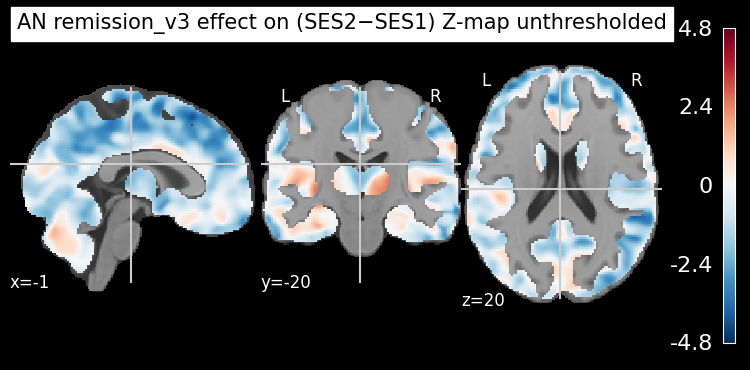

/tmp/ipykernel_185855/2677974655.py:124: UserWarning: empty mask
  plotting.plot_stat_map(


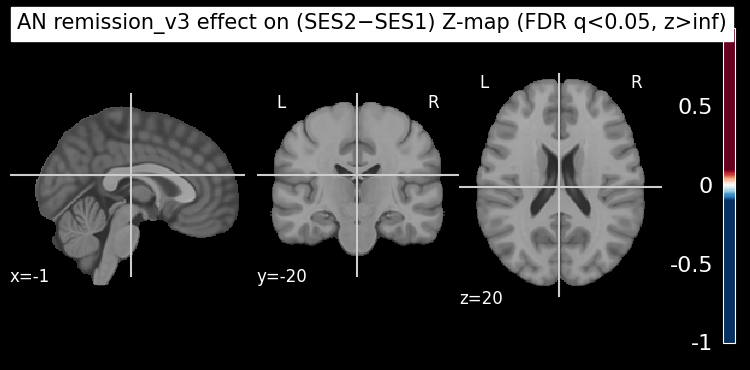

Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_remission_v3_v2_minus_v1/VBM_AN_remission_v3_SES2_minus_SES1_FDR_q05_positive.nii.gz
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_remission_v3_v2_minus_v1/VBM_AN_remission_v3_SES2_minus_SES1_FDR_q05_negative.nii.gz


/tmp/ipykernel_185855/2677974655.py:161: UserWarning: empty mask
  plotting.plot_stat_map(


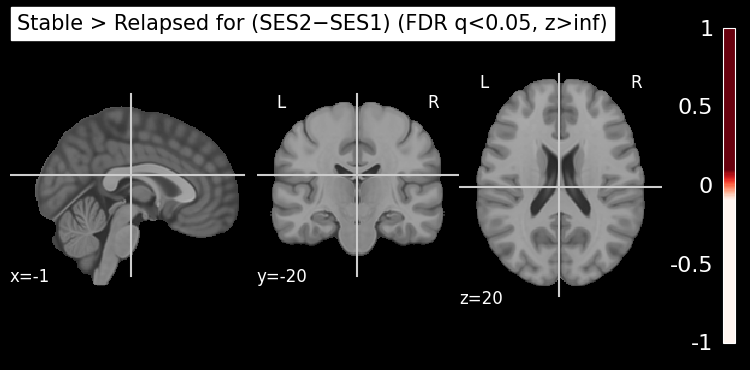

/tmp/ipykernel_185855/2677974655.py:173: UserWarning: empty mask
  plotting.plot_stat_map(


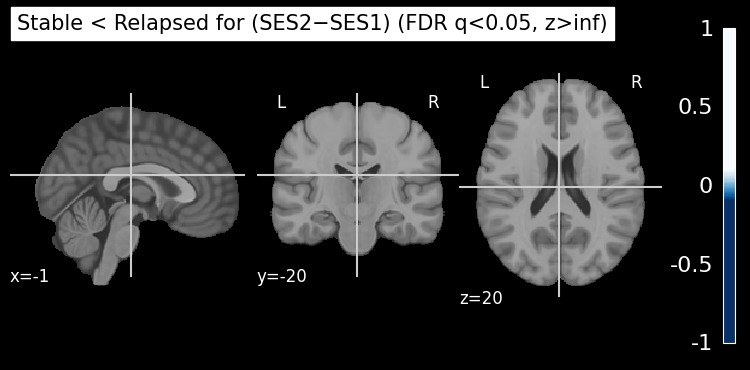

/tmp/ipykernel_185855/2677974655.py:188: UserWarning: The given float value must not exceed 0.0. But, you have given threshold=1e-06.
  clusters = get_clusters_table(
/tmp/ipykernel_185855/2677974655.py:188: UserWarning: No clusters found with stat higher than 1e-06
  clusters = get_clusters_table(
/tmp/ipykernel_185855/2677974655.py:188: UserWarning: No clusters found with stat lower than -1e-06
  clusters = get_clusters_table(


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)


In [191]:
df_subject_covars = df_merged_all[
    [
        "subject",
        "session",
        "age",
        "TIV_ml",
        "BMI",
        "hads_depression",
        "ybs_obs",
        "duree_years",
        "remission_v3"
    ]
].drop_duplicates()

df_vbm = utils_smri.build_cross_sectional_vbm_dataset(
    df_paths=df_all_sv,
    df_covars=df_subject_covars
)

wide_AN = utils_smri.make_paired_path_table(
    df_imgs=df_all_sv,
    group="AN",
    baseline=1,
    followup=2,
)

wide_AN.head()
print("Number of paired AN subjects:", len(wide_AN))


diff_imgs, subjects = utils_smri.build_difference_images(
    wide_paths=wide_AN,
    baseline=1,
    followup=2,
    expr="img2 - img1",
    verbose=True,
)

print("Number of difference images:", len(diff_imgs))
print("Number of subjects:", len(subjects))


df_an_v1 = df_vbm[
    (df_vbm.group == "AN") & (df_vbm.session == 1)
][["subject", "age", "TIV_ml", "remission_v3"]].copy()

df_an_v1["age"] = pd.to_numeric(df_an_v1["age"], errors="coerce")
df_an_v1["TIV_ml"] = pd.to_numeric(df_an_v1["TIV_ml"], errors="coerce")

df_long = pd.DataFrame({
    "subject": subjects,
    "path": diff_imgs
}).merge(df_an_v1, on="subject", how="left")

df_long = df_long.dropna(subset=["subject", "path", "remission_v3", "age", "TIV_ml"]).copy()

# Keep only the two remission groups if needed
df_long = df_long[df_long["remission_v3"].isin(["stable", "relapsed"])].copy()

print(df_long["remission_v3"].value_counts(dropna=False))
df_long.head()


all_paths = wide_AN[1].tolist() + wide_AN[2].tolist()
mean_gm = mean_img([load_img(p) for p in all_paths])

mask_img = math_img("img > 0.3", img=mean_gm)
mask_img = math_img("img.astype(int)", img=mask_img)

print("Mask voxels:", int(mask_img.get_fdata().sum()))


df_long["remission_code"] = (df_long["remission_v3"] == "stable").astype(int)

design = df_long[["remission_code", "age", "TIV_ml"]].copy()
design.insert(0, "intercept", 1.0)

print(design.head())


slm = SecondLevelModel(mask_img=mask_img, smoothing_fwhm=None)
slm = slm.fit(df_long["path"].tolist(), design_matrix=design)

z_map = slm.compute_contrast(
    second_level_contrast="remission_code",
    output_type="z_score"
)

out_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/results/vbm/an_remission_v3_v2_minus_v1")
out_dir.mkdir(parents=True, exist_ok=True)

utils_smri.save_nifti(
    z_map,
    out_dir / "VBM_AN_remission_v3_SES2_minus_SES1_parametric_zmap.nii.gz"
)


z_fdr, z_thr = utils_smri.threshold_map(
    z_map,
    alpha=0.05,
    height_control="fdr",
    two_sided=True,
)

utils_smri.save_nifti(
    z_fdr,
    out_dir / "VBM_AN_remission_v3_SES2_minus_SES1_parametric_zmap_FDR05.nii.gz"
)

print("FDR threshold:", z_thr)

mni = datasets.load_mni152_template()

plotting.plot_stat_map(
    z_map,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    title="AN remission_v3 effect on (SES2−SES1) Z-map unthresholded"
)
plotting.show()

plotting.plot_stat_map(
    z_fdr,
    bg_img=mni,
    display_mode="ortho",
    cut_coords=(-1, -20, 20),
    colorbar=True,
    symmetric_cbar=True,
    title=(
        f"AN remission_v3 effect on (SES2−SES1) Z-map (FDR q<0.05, z>{z_thr:.2f})"
        if z_thr is not None else
        "AN remission_v3 effect on (SES2−SES1) Z-map (no voxels survive FDR)"
    )
)
plotting.show()

if z_thr is not None:

    # Positive effects: stable > relapsed for longitudinal change
    z_inc = math_img("z * (z > 0)", z=z_fdr)

    # Negative effects: stable < relapsed for longitudinal change
    z_dec = math_img("z * (z < 0)", z=z_fdr)

    out_inc = out_dir / "VBM_AN_remission_v3_SES2_minus_SES1_FDR_q05_positive.nii.gz"
    out_dec = out_dir / "VBM_AN_remission_v3_SES2_minus_SES1_FDR_q05_negative.nii.gz"

    utils_smri.save_nifti(z_inc, out_inc)
    utils_smri.save_nifti(z_dec, out_dec)

    print("Saved:", out_inc)
    print("Saved:", out_dec)

else:
    print("No voxels survived FDR.")

if z_thr is not None:

    plotting.plot_stat_map(
        z_inc,
        bg_img=mni,
        threshold=1e-6,
        display_mode="ortho",
        cut_coords=(-1, -20, 20),
        cmap="Reds",
        colorbar=True,
        title=f"Stable > Relapsed for (SES2−SES1) (FDR q<0.05, z>{z_thr:.2f})"
    )
    plotting.show()

    plotting.plot_stat_map(
        z_dec,
        bg_img=mni,
        threshold=1e-6,
        display_mode="ortho",
        cut_coords=(-1, -20, 20),
        cmap="Blues_r",
        colorbar=True,
        title=f"Stable < Relapsed for (SES2−SES1) (FDR q<0.05, z>{z_thr:.2f})"
    )
    plotting.show()


cluster_k = 1000

clusters = get_clusters_table(
    stat_img=z_fdr,
    stat_threshold=1e-6,
    cluster_threshold=cluster_k,
    two_sided=True
)

clusters

In [192]:
roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")

rows = []

for rp in sorted(roi_dir.glob("*bin*.nii*")):

    roi = load_img(rp)

    # Resample ROI to match z_map space
    roi_rs = resample_to_img(roi, z_map, interpolation="nearest")

    # Binarize ROI
    roi_bin = math_img("img > 0", img=roi_rs)

    # Skip empty ROI
    n_vox = int(roi_bin.get_fdata().sum())
    if n_vox == 0:
        continue

    # Values inside ROI
    z_vals = apply_mask(z_map, roi_bin)

    # Significant voxels
    zsig_vals = apply_mask(z_fdr, roi_bin)

    sig_mask = (zsig_vals != 0)
    sig_pos = (zsig_vals > 0)
    sig_neg = (zsig_vals < 0)

    rows.append({
        "roi_file": rp.name,
        "n_vox": int(z_vals.size),
        "mean_z": float(np.mean(z_vals)),
        "median_z": float(np.median(z_vals)),
        "pct_FDR_sig_voxels": float(sig_mask.mean() * 100),
        "mean_z_sig_voxels": float(np.mean(zsig_vals[sig_mask])) if sig_mask.any() else np.nan,
        "pct_sig_pos": float(sig_pos.mean() * 100),
        "pct_sig_neg": float(sig_neg.mean() * 100),
    })

df_roi_vox = pd.DataFrame(rows).sort_values(
    "pct_FDR_sig_voxels",
    ascending=False
)

df_roi_vox

,roi_file,n_vox,mean_z,median_z,pct_FDR_sig_voxels,mean_z_sig_voxels,pct_sig_pos,pct_sig_neg
0,ACC_rostral_bin.nii,6122,-0.468536,0.000000,0.0,NaN,0.0,0.0
1,Cingulate_Gyrus_anterior_division_bin.nii,6120,-0.469800,0.000000,0.0,NaN,0.0,0.0
2,Cingulate_Gyrus_posterior_division_bin.nii,5690,-0.968939,-0.872033,0.0,NaN,0.0,0.0
3,Hypothalamus_bin.nii,463,-0.889858,-0.885882,0.0,NaN,0.0,0.0
4,Insular_Cortex_bin.nii,6344,0.163589,0.093053,0.0,NaN,0.0,0.0
5,Left_Amygdala_bin.nii,727,-0.212078,-0.219370,0.0,NaN,0.0,0.0
6,NACC_L_bin.nii,229,-1.387019,-1.437063,0.0,NaN,0.0,0.0
7,NACC_R_bin.nii,202,-1.524048,-1.678057,0.0,NaN,0.0,0.0
8,OFC_lateral_bin.nii,7489,-0.035885,0.000000,0.0,NaN,0.0,0.0
9,OFC_medial_bin.nii,2302,-0.360533,-0.334685,0.0,NaN,0.0,0.0


## Visualization

### Tissues baseline

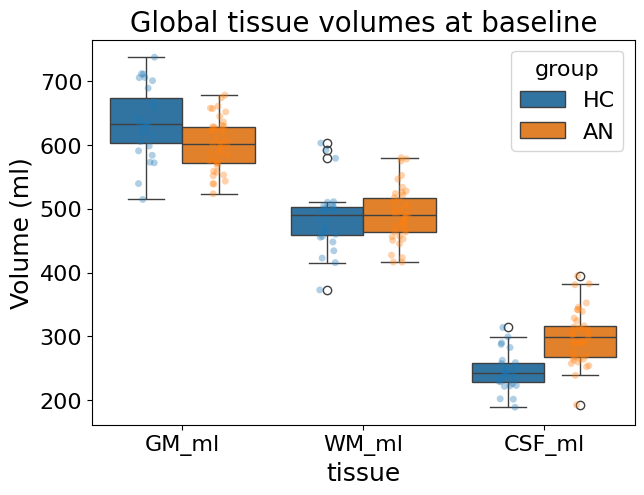

In [198]:
df_v1 = df_merged_tissues_long[df_merged_tissues_long["session"] == 1]

df_tissues = df_v1.melt(id_vars=["group"], value_vars=["GM_ml", "WM_ml", "CSF_ml"],var_name="tissue",value_name="volume")

plt.figure(figsize=(7,5))

sns.boxplot(
    data=df_tissues,
    x="tissue",
    y="volume",
    hue="group"
)

sns.stripplot(
    data=df_tissues,
    x="tissue",
    y="volume",
    hue="group",
    dodge=True,
    alpha=0.35,
    legend=False
)

plt.title("Global tissue volumes at baseline")
plt.ylabel("Volume (ml)")
plt.show()

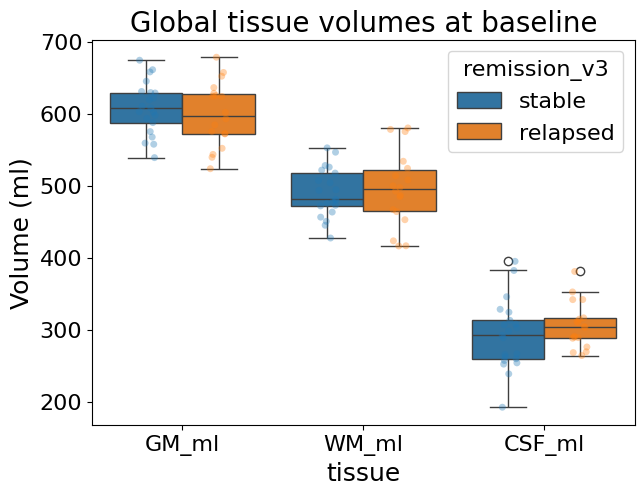

In [199]:
df_v1 = df_merged_tissues_long[df_merged_tissues_long["session"] == 1]

# convert to long format
df_tissues = df_v1.melt(
    id_vars=["remission_v3"],
    value_vars=["GM_ml", "WM_ml", "CSF_ml"],
    var_name="tissue",
    value_name="volume"
)

plt.figure(figsize=(7,5))

sns.boxplot(
    data=df_tissues,
    x="tissue",
    y="volume",
    hue="remission_v3"
)

sns.stripplot(
    data=df_tissues,
    x="tissue",
    y="volume",
    hue="remission_v3",
    dodge=True,
    alpha=0.35,
    legend=False
)

plt.title("Global tissue volumes at baseline")
plt.ylabel("Volume (ml)")
plt.show()

### delta BMI

#### NMH6

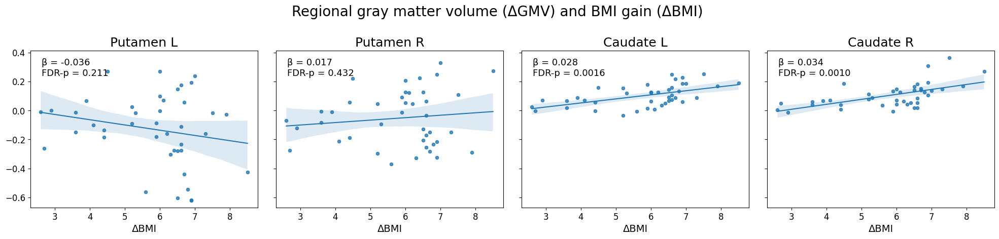

Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/delta_GMV_BMI_putamen_caudate.png


In [321]:
roi_list = [
    "Left Putamen",
    "Right Putamen",
    "Left Caudate",
    "Right Caudate",
]

title_map = {
    "Left Putamen": "Putamen L",
    "Right Putamen": "Putamen R",
    "Left Caudate": "Caudate L",
    "Right Caudate": "Caudate R",
}

stats_map = {
    "Left Putamen": ("-0.036", "0.211"),
    "Right Putamen": ("0.017", "0.432"),
    "Left Caudate": ("0.028", "0.0016"),
    "Right Caudate": ("0.034", "0.0010"),
}

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

for i, roi in enumerate(roi_list):
    ax = axes[i]

    sub = delta_roi_gm[delta_roi_gm["roi"] == roi]

    sns.regplot(
        data=sub,
        x="delta_BMI",
        y="delta_Vgm",
        ax=ax,
        scatter_kws={"s": 20},
        line_kws={"linewidth": 1.5}
    )

    beta, p_fdr = stats_map[roi]

    ax.text(
    0.05, 0.95,
    f"β = {beta}\nFDR-p = {p_fdr}",
    transform=ax.transAxes,
    fontsize=13,
    va="top",
    ha="left"
)

    ax.set_title(title_map[roi], fontsize=18)
    ax.set_xlabel("ΔBMI", fontsize=14)
    ax.set_ylabel("")
    ax.tick_params(axis="both", labelsize=12)

fig.suptitle(
    "Regional gray matter volume (ΔGMV) and BMI gain (ΔBMI)",
    fontsize=20,
    y=0.98
)

plt.subplots_adjust(
    left=0.04,
    right=0.99,
    bottom=0.18,
    top=0.80,
    wspace=0.08
)

out_path = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/delta_GMV_BMI_putamen_caudate.png"

plt.savefig(out_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", out_path)

## QC

In [202]:
from pathlib import Path
import json
import pandas as pd

rawdata_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/rawdata")
rows = []

for json_file in rawdata_dir.glob("sub-*/ses-*/anat/*.json"):
    try:
        with open(json_file, "r", encoding="utf-8") as f: meta = json.load(f)
        subject, session = json_file.parts[-4], json_file.parts[-3]
        rows.append({"subject": subject, "session": session, "json_file": str(json_file), "Manufacturer": meta.get("Manufacturer"), "ManufacturersModelName": meta.get("ManufacturersModelName"), "StationName": meta.get("StationName"), "MagneticFieldStrength": meta.get("MagneticFieldStrength")})
    except Exception as e:
        rows.append({"subject": json_file.parts[-4] if len(json_file.parts) >= 4 else None, "session": json_file.parts[-3] if len(json_file.parts) >= 3 else None, "json_file": str(json_file), "Manufacturer": None, "ManufacturersModelName": None, "StationName": None, "MagneticFieldStrength": None, "error": str(e)})

df = pd.DataFrame(rows).sort_values(["subject", "session"]).reset_index(drop=True)
print(df.head())
print("\n=== Summary by scanner ===")
print(df.groupby(["Manufacturer", "ManufacturersModelName"], dropna=False).size().reset_index(name="n_files").sort_values("n_files", ascending=False))

out_csv = rawdata_dir / "scanner_inventory_anat.csv"
df.to_csv(out_csv, index=False)

print(f"\nSaved: {out_csv}")

  subject session                                          json_file  \
0  sub-01  ses-V1  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/rawdata/...   
1  sub-01  ses-V1  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/rawdata/...   
2  sub-01  ses-V2  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/rawdata/...   
3  sub-01  ses-V2  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/rawdata/...   
4  sub-02  ses-V1  /mnt/irm_sandbox01/REMANO/REMANO_BIDS/rawdata/...   

  Manufacturer ManufacturersModelName StationName  MagneticFieldStrength  
0        Canon               Galan 3T    Galan 3T                      3  
1        Canon               Galan 3T    Galan 3T                      3  
2        Canon               Galan 3T    Galan 3T                      3  
3        Canon               Galan 3T    Galan 3T                      3  
4        Canon               Galan 3T    Galan 3T                      3  

=== Summary by scanner ===
  Manufacturer ManufacturersModelName  n_files
0        Canon               Galan 3T     

## ROI intersection putamen

In [209]:
from pathlib import Path
import numpy as np
import nibabel as nib
from nibabel.affines import apply_affine

roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")

def principal_axis_equal_voxel_segmentation(roi_path, out_prefix, n_slices=7, orient_with="AP"):
    img = nib.load(str(roi_path))
    data = img.get_fdata() > 0
    coords = np.argwhere(data)
    coords_mm = apply_affine(img.affine, coords)
    center_mm = coords_mm.mean(axis=0)
    coords_centered = coords_mm - center_mm
    _, _, Vt = np.linalg.svd(coords_centered, full_matrices=False)
    principal_axis = Vt[0].copy()
    axis_index = {"ML": 0, "AP": 1, "IS": 2}[orient_with]
    if principal_axis[axis_index] < 0:
        principal_axis = -principal_axis
    proj_vals = coords_centered @ principal_axis
    order = np.argsort(proj_vals)
    coords_sorted = coords[order]
    proj_sorted = proj_vals[order]
    split_indices = np.array_split(np.arange(len(coords_sorted)), n_slices)
    counts, boundaries, out_paths = [], [], []

    for i, idxs in enumerate(split_indices):
        mask = np.zeros(data.shape, dtype=np.uint8)
        selected_voxels = coords_sorted[idxs]
        mask[selected_voxels[:, 0], selected_voxels[:, 1], selected_voxels[:, 2]] = 1
        counts.append(len(idxs))
        boundaries.append((proj_sorted[idxs[0]], proj_sorted[idxs[-1]]))
        suffix = "_most_posterior" if i == 0 else "_most_anterior" if i == n_slices - 1 else ""
        out_path = roi_dir / f"{out_prefix}_slice{i+1:02d}{suffix}.nii"
        nib.save(nib.Nifti1Image(mask, img.affine, img.header.copy()), str(out_path))
        out_paths.append(out_path)
        print(f"Saved: {out_path} | voxels: {len(idxs)}")

    print(f"\nROI: {roi_path.name}")
    print(f"Center (mm): {center_mm}")
    print(f"Principal axis: {principal_axis}")
    print("Projection ranges (posterior -> anterior):")
    for i, ((b0, b1), count) in enumerate(zip(boundaries, counts), 1):
        print(f"  Slice {i}: {b0:.3f} to {b1:.3f} | voxels={count}")
    print()

    return {"center_mm": center_mm, "principal_axis": principal_axis, "counts": counts, "boundaries": boundaries, "out_paths": out_paths}

for structure in ["putamen", "caudate"]:
    for side in ["L", "R"]:
        principal_axis_equal_voxel_segmentation(roi_dir / f"{structure}_{side}_bin.nii", f"{structure}_{side}_svd_eqvox", n_slices=7, orient_with="AP")

Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI/putamen_L_svd_eqvox_slice01_most_posterior.nii | voxels: 914
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI/putamen_L_svd_eqvox_slice02.nii | voxels: 914
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI/putamen_L_svd_eqvox_slice03.nii | voxels: 914
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI/putamen_L_svd_eqvox_slice04.nii | voxels: 914
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI/putamen_L_svd_eqvox_slice05.nii | voxels: 914
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI/putamen_L_svd_eqvox_slice06.nii | voxels: 914
Saved: /mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI/putamen_L_svd_eqvox_slice07_most_anterior.nii | voxels: 913

ROI: putamen_L_bin.nii
Center (mm): [-24.8575895    0.56870408   0.36970455]
Principal axis: [ 

In [210]:
from pathlib import Path
import numpy as np
import nibabel as nib
from nilearn.image import resample_to_img

roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")
put_path = roi_dir / "putamen_R_bin.nii"
slice_paths = [roi_dir / "putamen_R_svd_eqvox_slice01_most_posterior.nii", roi_dir / "putamen_R_svd_eqvox_slice02.nii", roi_dir / "putamen_R_svd_eqvox_slice03.nii", roi_dir / "putamen_R_svd_eqvox_slice04.nii", roi_dir / "putamen_R_svd_eqvox_slice05.nii", roi_dir / "putamen_R_svd_eqvox_slice06.nii", roi_dir / "putamen_R_svd_eqvox_slice07_most_anterior.nii"]

img_put = nib.load(str(put_path))
imgs_slices = [nib.load(str(p)) for p in slice_paths]
resampled = [resample_to_img(img, img_put, interpolation="nearest") if img.shape != img_put.shape or not np.allclose(img.affine, img_put.affine) else img for img in imgs_slices]

m_put = img_put.get_fdata() > 0
masks = [img.get_fdata() > 0 for img in resampled]

for i, m in enumerate(masks, 1):
    print(f"Slice {i} outside putamen: {int((m & ~m_put).sum())}")

union_7 = np.logical_or.reduce(masks)
missing = m_put & ~union_7
extra = union_7 & ~m_put

print(f"\nPutamen total: {int(m_put.sum())}")
print(f"Union of 7 total: {int(union_7.sum())}")
print(f"Missing voxels from putamen: {int(missing.sum())}")
print(f"Extra voxels outside putamen: {int(extra.sum())}")
print(f"Coverage (%): {100 * (union_7 & m_put).sum() / m_put.sum():.2f}")

print("\nPairwise overlaps:")
overlap_found = False
for i in range(len(masks)):
    for j in range(i + 1, len(masks)):
        n_overlap = int((masks[i] & masks[j]).sum())
        if n_overlap > 0:
            overlap_found = True
            print(f"Slice {i+1} & Slice {j+1}: {n_overlap} overlapping voxels")

if not overlap_found:
    print("No overlap between slices.")

Slice 1 outside putamen: 0
Slice 2 outside putamen: 0
Slice 3 outside putamen: 0
Slice 4 outside putamen: 0
Slice 5 outside putamen: 0
Slice 6 outside putamen: 0
Slice 7 outside putamen: 0

Putamen total: 6397
Union of 7 total: 6397
Missing voxels from putamen: 0
Extra voxels outside putamen: 0
Coverage (%): 100.00

Pairwise overlaps:
No overlap between slices.


## Test roi BG

In [211]:
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
from nilearn.image import resample_to_img

roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")
root_AN_4roi = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_AN/GM/unsmooth")
root_HC_4roi = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_HC/GM/unsmooth")

def build_roi_df_fast(root: Path, group_label: str, roi_dir: Path, roi_keep=None) -> pd.DataFrame:
    gm_paths = sorted(root.rglob("mwp1*.nii"))
    if not gm_paths:
        raise ValueError(f"No GM images found in: {root}")

    roi_keep = set(roi_keep) if roi_keep is not None else None
    roi_paths = [rp for rp in sorted(roi_dir.glob("*.nii*")) if roi_keep is None or rp.name.replace(".nii.gz", "").replace(".nii", "").replace("_bin", "") in roi_keep]

    print(f"{group_label}: {len(gm_paths)} GM images | {len(roi_paths)} ROI masks")
    print("ROIs found:", [rp.name for rp in roi_paths])

    if not roi_paths:
        raise ValueError("No ROI masks matched roi_keep. Check names/extensions.")

    ref_gm = nib.load(str(gm_paths[0]))
    resampled_rois = {}

    for rp in roi_paths:
        roi_name = rp.name.replace(".nii.gz", "").replace(".nii", "").replace("_bin", "")
        resampled_rois[roi_name] = resample_to_img(nib.load(str(rp)), ref_gm, interpolation="nearest").get_fdata() > 0

    rows = []

    for gm_path in gm_paths:
        print(f"[{group_label}] {gm_path.name}")
        subject, session = parse_sub_ses(gm_path.name)
        gm_img = nib.load(str(gm_path))
        gm = gm_img.get_fdata()
        voxel_vol_mm3 = np.prod(gm_img.header.get_zooms()[:3])

        for roi_name, roi_mask in resampled_rois.items():
            rows.append({"subject": subject, "session": session, "group": group_label, "roi": roi_name, "GM_roi_ml": float(np.nansum(gm[roi_mask]) * voxel_vol_mm3 / 1000)})

    return pd.DataFrame(rows)

roi_keep = [f"{structure}_{side}_svd_eqvox_slice{i:02d}{'_most_posterior' if i == 1 else '_most_anterior' if i == 7 else ''}" for structure in ["putamen", "caudate"] for side in ["R", "L"] for i in range(1, 8)]


In [212]:
df_roi_4_an = build_roi_df_fast(root_AN_4roi, "AN", roi_dir, roi_keep)
df_roi_4_hc = build_roi_df_fast(root_HC_4roi, "HC", roi_dir, roi_keep)

df_roi_4_all = (
    pd.concat([df_roi_4_an, df_roi_4_hc], ignore_index=True)
    .sort_values(["group", "subject", "session", "roi"])
    .reset_index(drop=True)
)

print(df_roi_4_all.head())

AN: 111 GM images | 28 ROI masks
ROIs found: ['caudate_L_svd_eqvox_slice01_most_posterior.nii', 'caudate_L_svd_eqvox_slice02.nii', 'caudate_L_svd_eqvox_slice03.nii', 'caudate_L_svd_eqvox_slice04.nii', 'caudate_L_svd_eqvox_slice05.nii', 'caudate_L_svd_eqvox_slice06.nii', 'caudate_L_svd_eqvox_slice07_most_anterior.nii', 'caudate_R_svd_eqvox_slice01_most_posterior.nii', 'caudate_R_svd_eqvox_slice02.nii', 'caudate_R_svd_eqvox_slice03.nii', 'caudate_R_svd_eqvox_slice04.nii', 'caudate_R_svd_eqvox_slice05.nii', 'caudate_R_svd_eqvox_slice06.nii', 'caudate_R_svd_eqvox_slice07_most_anterior.nii', 'putamen_L_svd_eqvox_slice01_most_posterior.nii', 'putamen_L_svd_eqvox_slice02.nii', 'putamen_L_svd_eqvox_slice03.nii', 'putamen_L_svd_eqvox_slice04.nii', 'putamen_L_svd_eqvox_slice05.nii', 'putamen_L_svd_eqvox_slice06.nii', 'putamen_L_svd_eqvox_slice07_most_anterior.nii', 'putamen_R_svd_eqvox_slice01_most_posterior.nii', 'putamen_R_svd_eqvox_slice02.nii', 'putamen_R_svd_eqvox_slice03.nii', 'putamen_R_s

In [215]:
df_bg_all=merge_volume(df_merged_all,df_roi_4_all)
df_bg_all

,subject,session,group,roi,GM_roi_ml,TIV_ml,study_id,redcap_event_name,age,soustype,...,indif_d5,delay_discounting_complete,habits_yn,group_scan,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total
0,5,1,AN,caudate_L_svd_eqvox_slice01_most_posterior,0.253101,1401.254204,6,visite_1_arm_1,20.0,2.0,...,64.0,2.0,1.0,AN,16.1,stable,NaN,6.333333,13.666667,165.0
1,5,1,AN,caudate_L_svd_eqvox_slice02,0.317624,1401.254204,6,visite_1_arm_1,20.0,2.0,...,64.0,2.0,1.0,AN,16.1,stable,NaN,6.333333,13.666667,165.0
2,5,1,AN,caudate_L_svd_eqvox_slice03,0.333941,1401.254204,6,visite_1_arm_1,20.0,2.0,...,64.0,2.0,1.0,AN,16.1,stable,NaN,6.333333,13.666667,165.0
3,5,1,AN,caudate_L_svd_eqvox_slice04,0.335955,1401.254204,6,visite_1_arm_1,20.0,2.0,...,64.0,2.0,1.0,AN,16.1,stable,NaN,6.333333,13.666667,165.0
4,5,1,AN,caudate_L_svd_eqvox_slice05,0.368097,1401.254204,6,visite_1_arm_1,20.0,2.0,...,64.0,2.0,1.0,AN,16.1,stable,NaN,6.333333,13.666667,165.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4727,85,2,HC,putamen_R_svd_eqvox_slice03,0.672656,1367.312468,180,visite_2_arm_2,28.0,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
4728,85,2,HC,putamen_R_svd_eqvox_slice04,0.736567,1367.312468,180,visite_2_arm_2,28.0,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
4729,85,2,HC,putamen_R_svd_eqvox_slice05,0.730670,1367.312468,180,visite_2_arm_2,28.0,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0
4730,85,2,HC,putamen_R_svd_eqvox_slice06,0.733849,1367.312468,180,visite_2_arm_2,28.0,NaN,...,NaN,NaN,NaN,HC,NaN,NaN,NaN,NaN,NaN,0.0


In [216]:
roi_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI")
root_AN_4roi_long = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long_AN/GM/unsmooth")
root_HC_4roi_long = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long_HC/GM/unsmooth")


df_roi_long_an = build_roi_df_fast(root_AN_4roi_long, "AN", roi_dir, roi_keep)
df_roi_long_hc = build_roi_df_fast(root_HC_4roi_long, "HC", roi_dir, roi_keep)

df_roi_long = (
    pd.concat([df_roi_long_an, df_roi_long_hc], ignore_index=True)
    .sort_values(["subject", "session", "roi"])
    .reset_index(drop=True)
)

df_roi_long.head()

AN: 82 GM images | 28 ROI masks
ROIs found: ['caudate_L_svd_eqvox_slice01_most_posterior.nii', 'caudate_L_svd_eqvox_slice02.nii', 'caudate_L_svd_eqvox_slice03.nii', 'caudate_L_svd_eqvox_slice04.nii', 'caudate_L_svd_eqvox_slice05.nii', 'caudate_L_svd_eqvox_slice06.nii', 'caudate_L_svd_eqvox_slice07_most_anterior.nii', 'caudate_R_svd_eqvox_slice01_most_posterior.nii', 'caudate_R_svd_eqvox_slice02.nii', 'caudate_R_svd_eqvox_slice03.nii', 'caudate_R_svd_eqvox_slice04.nii', 'caudate_R_svd_eqvox_slice05.nii', 'caudate_R_svd_eqvox_slice06.nii', 'caudate_R_svd_eqvox_slice07_most_anterior.nii', 'putamen_L_svd_eqvox_slice01_most_posterior.nii', 'putamen_L_svd_eqvox_slice02.nii', 'putamen_L_svd_eqvox_slice03.nii', 'putamen_L_svd_eqvox_slice04.nii', 'putamen_L_svd_eqvox_slice05.nii', 'putamen_L_svd_eqvox_slice06.nii', 'putamen_L_svd_eqvox_slice07_most_anterior.nii', 'putamen_R_svd_eqvox_slice01_most_posterior.nii', 'putamen_R_svd_eqvox_slice02.nii', 'putamen_R_svd_eqvox_slice03.nii', 'putamen_R_sv

,subject,session,group,roi,GM_roi_ml
0,1,1,HC,caudate_L_svd_eqvox_slice01_most_posterior,0.277269
1,1,1,HC,caudate_L_svd_eqvox_slice02,0.336667
2,1,1,HC,caudate_L_svd_eqvox_slice03,0.340778
3,1,1,HC,caudate_L_svd_eqvox_slice04,0.347983
4,1,1,HC,caudate_L_svd_eqvox_slice05,0.378445


### group at baseline GM

In [217]:
df_roi_long=merge_volume(df_merged_long,df_roi_long)
df_roi_long

,subject,session,group,roi,GM_roi_ml,TIV_ml,study_id,redcap_event_name,age,soustype,...,indif_d5,delay_discounting_complete,habits_yn,group_scan,BMI,remission_v3,remission,duree_years,age_at_onset,edi2_total
0,1,1,HC,caudate_L_svd_eqvox_slice01_most_posterior,0.277269,1278.788153,13,visite_1_arm_2,33.0,NaN,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
1,1,1,HC,caudate_L_svd_eqvox_slice02,0.336667,1278.788153,13,visite_1_arm_2,33.0,NaN,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
2,1,1,HC,caudate_L_svd_eqvox_slice03,0.340778,1278.788153,13,visite_1_arm_2,33.0,NaN,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
3,1,1,HC,caudate_L_svd_eqvox_slice04,0.347983,1278.788153,13,visite_1_arm_2,33.0,NaN,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
4,1,1,HC,caudate_L_svd_eqvox_slice05,0.378445,1278.788153,13,visite_1_arm_2,33.0,NaN,...,69.0,2.0,1.0,HC,21.6,NaN,NaN,NaN,NaN,24.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3859,94,2,AN,putamen_R_svd_eqvox_slice03,0.502309,1362.329347,233,visite_2_arm_1,33.0,NaN,...,21.0,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0
3860,94,2,AN,putamen_R_svd_eqvox_slice04,0.578454,1362.329347,233,visite_2_arm_1,33.0,NaN,...,21.0,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0
3861,94,2,AN,putamen_R_svd_eqvox_slice05,0.592575,1362.329347,233,visite_2_arm_1,33.0,NaN,...,21.0,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0
3862,94,2,AN,putamen_R_svd_eqvox_slice06,0.624598,1362.329347,233,visite_2_arm_1,33.0,NaN,...,21.0,2.0,1.0,AN,19.7,NaN,NaN,13.75,19.25,131.0


In [218]:
res_roi_group_v1_gm_bg = utils_smri.run_roi_models(
    data=df_roi_long[df_roi_long.session == 1],
    roi_col="roi",
    roi_list=roi_keep,
    formula="GM_roi_ml ~ C(group) + age + TIV_ml",
    model_type="ols",
    group_col="subject",
    terms_of_interest=["C(group)[T.HC]"]
)
res_roi_group_v1_gm_bg

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],roi,n_subjects,p_C(group)[T.HC]_fdr
0,putamen_R_svd_eqvox_slice01_most_posterior,69,0.220475,0.184497,6.128030,9.791973e-04,0.014837,0.262647,putamen_R_svd_eqvox_slice01_most_posterior,69,0.459632
1,putamen_R_svd_eqvox_slice02,69,0.264840,0.230909,7.805370,1.582218e-04,0.007661,0.530827,putamen_R_svd_eqvox_slice02,69,0.571660
2,putamen_R_svd_eqvox_slice03,69,0.294305,0.261734,9.035918,4.391457e-05,0.023320,0.081619,putamen_R_svd_eqvox_slice03,69,0.190443
3,putamen_R_svd_eqvox_slice04,69,0.395438,0.367535,14.171956,3.298516e-07,0.040373,0.002038,putamen_R_svd_eqvox_slice04,69,0.008808
4,putamen_R_svd_eqvox_slice05,69,0.442682,0.416959,17.209970,2.470073e-08,0.043237,0.000539,putamen_R_svd_eqvox_slice05,69,0.007301
5,putamen_R_svd_eqvox_slice06,69,0.432852,0.406676,16.536158,4.314473e-08,0.038607,0.002202,putamen_R_svd_eqvox_slice06,69,0.008808
6,putamen_R_svd_eqvox_slice07_most_anterior,69,0.398042,0.370260,14.327002,2.875490e-07,0.027668,0.033988,putamen_R_svd_eqvox_slice07_most_anterior,69,0.095165
7,putamen_L_svd_eqvox_slice01_most_posterior,69,0.179386,0.141512,4.736331,4.752056e-03,0.004538,0.733371,putamen_L_svd_eqvox_slice01_most_posterior,69,0.733371
8,putamen_L_svd_eqvox_slice02,69,0.249966,0.215349,7.220896,2.956232e-04,0.008021,0.523648,putamen_L_svd_eqvox_slice02,69,0.571660
9,putamen_L_svd_eqvox_slice03,69,0.338836,0.308321,11.103832,5.630425e-06,0.023542,0.047101,putamen_L_svd_eqvox_slice03,69,0.119893


### group at follow-up GM

In [219]:
res_roi_group_v2_gm_bg = utils_smri.run_roi_models(
    data=df_roi_long[df_roi_long.session == 2],
    roi_col="roi",
    roi_list=roi_keep,
    formula="GM_roi_ml ~ C(group) + age + TIV_ml",
    model_type="ols",
    group_col="subject",
    terms_of_interest=["C(group)[T.HC]"]
)
res_roi_group_v2_gm_bg

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],roi,n_subjects,p_C(group)[T.HC]_fdr
0,putamen_R_svd_eqvox_slice01_most_posterior,69,0.337990,0.307435,11.061921,5.862806e-06,0.062520,7.603266e-05,putamen_R_svd_eqvox_slice01_most_posterior,69,0.000355
1,putamen_R_svd_eqvox_slice02,69,0.479201,0.455165,19.936112,2.833133e-09,0.067092,3.973987e-07,putamen_R_svd_eqvox_slice02,69,0.000011
2,putamen_R_svd_eqvox_slice03,69,0.475652,0.451451,19.654491,3.520621e-09,0.062688,1.585514e-06,putamen_R_svd_eqvox_slice03,69,0.000015
3,putamen_R_svd_eqvox_slice04,69,0.471164,0.446756,19.303825,4.623567e-09,0.046638,1.894772e-04,putamen_R_svd_eqvox_slice04,69,0.000758
4,putamen_R_svd_eqvox_slice05,69,0.477826,0.453725,19.826496,3.082608e-09,0.033566,4.205320e-03,putamen_R_svd_eqvox_slice05,69,0.014719
5,putamen_R_svd_eqvox_slice06,69,0.491928,0.468479,20.978209,1.283593e-09,0.019406,9.017751e-02,putamen_R_svd_eqvox_slice06,69,0.229543
6,putamen_R_svd_eqvox_slice07_most_anterior,69,0.453660,0.428444,17.991156,1.308840e-08,0.015189,2.002524e-01,putamen_R_svd_eqvox_slice07_most_anterior,69,0.467256
7,putamen_L_svd_eqvox_slice01_most_posterior,69,0.314892,0.283271,9.958495,1.730210e-05,0.078099,6.602120e-06,putamen_L_svd_eqvox_slice01_most_posterior,69,0.000046
8,putamen_L_svd_eqvox_slice02,69,0.420773,0.394040,15.739534,8.445488e-08,0.071560,9.536349e-07,putamen_L_svd_eqvox_slice02,69,0.000013
9,putamen_L_svd_eqvox_slice03,69,0.441353,0.415569,17.117496,2.665092e-08,0.052641,2.473592e-05,putamen_L_svd_eqvox_slice03,69,0.000139


#### NMH8

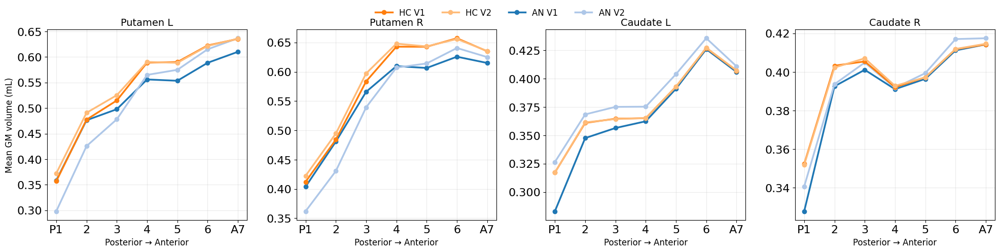

In [222]:
import matplotlib.pyplot as plt

df = df_roi_long.copy()

df["structure"] = df["roi"].str.extract(r"^(putamen|caudate)")
df["side"] = df["roi"].str.extract(r"_(L|R)_")
df["slice"] = df["roi"].str.extract(r"slice(\d+)").astype(int)
df["session"] = df["session"].replace({"V1": "1", "V2": "2", 1.0: "1", 2.0: "2"}).astype(str)

df_mean = df.groupby(["structure", "side", "group", "session", "slice"], as_index=False)["GM_roi_ml"].mean()

colors = {
    ("AN", "1"): "#1F77B4",
    ("AN", "2"): "#AEC7E8",
    ("HC", "1"): "#FF7F0E",
    ("HC", "2"): "#FFBB78"
}

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=False)

plot_order = [
    ("putamen", "L"),
    ("putamen", "R"),
    ("caudate", "L"),
    ("caudate", "R")
]

for ax, (structure, side) in zip(axes, plot_order):
    d_side = df_mean[(df_mean["structure"] == structure) & (df_mean["side"] == side)]

    for (group, session), d in d_side.groupby(["group", "session"]):
        d = d.sort_values("slice")
        ax.plot(d["slice"], d["GM_roi_ml"], marker="o", linewidth=2.5, color=colors[(group, session)], label=f"{group} V{session}")

    ax.set_title(f"{structure.capitalize()} {side}", fontsize=14)
    ax.set_xticks(range(1, 8))
    ax.set_xticklabels(["P1", "2", "3", "4", "5", "6", "A7"])
    ax.set_xlabel("Posterior → Anterior", fontsize=12)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Mean GM volume (mL)", fontsize=12)

handles, labels = axes[0].get_legend_handles_labels()

legend_order = ["HC V1", "HC V2", "AN V1", "AN V2"]
ordered_handles = [handles[labels.index(label)] for label in legend_order]

fig.legend(ordered_handles, legend_order, loc="upper center", ncol=4, frameon=False, fontsize=12, bbox_to_anchor=(0.5, 1.02))

plt.tight_layout()
plt.show()

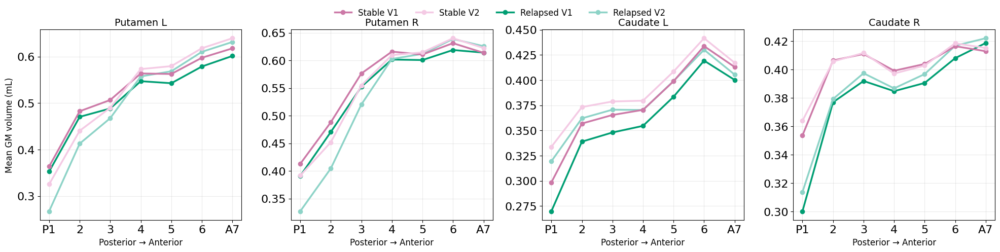

In [223]:
import matplotlib.pyplot as plt

df = df_roi_long.copy()

df["structure"] = df["roi"].str.extract(r"^(putamen|caudate)")
df["side"] = df["roi"].str.extract(r"_(L|R)_")
df["slice"] = df["roi"].str.extract(r"slice(\d+)").astype(int)

df["session"] = df["session"].replace({
    "V1": "1",
    "V2": "2",
    1.0: "1",
    2.0: "2"
}).astype(str)

df_mean = df.groupby(
    ["structure", "side", "remission_v3", "session", "slice"],
    as_index=False
)["GM_roi_ml"].mean()

colors = {
    ("relapsed", "1"): "#009E73",
    ("relapsed", "2"): "#8DD3C7",
    ("stable", "1"): "#CC79A7",
    ("stable", "2"): "#F4CAE4"
}

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=False)

plot_order = [
    ("putamen", "L"),
    ("putamen", "R"),
    ("caudate", "L"),
    ("caudate", "R")
]

for ax, (structure, side) in zip(axes, plot_order):
    d_side = df_mean[(df_mean["structure"] == structure) & (df_mean["side"] == side)]

    for (remission, session), d in d_side.groupby(["remission_v3", "session"]):
        d = d.sort_values("slice")
        ax.plot(d["slice"], d["GM_roi_ml"], marker="o", linewidth=2.5, color=colors[(remission, session)], label=f"{remission} V{session}")

    ax.set_title(f"{structure.capitalize()} {side}", fontsize=14)
    ax.set_xticks(range(1, 8))
    ax.set_xticklabels(["P1", "2", "3", "4", "5", "6", "A7"])
    ax.set_xlabel("Posterior → Anterior", fontsize=12)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Mean GM volume (mL)", fontsize=12)

handles, labels = axes[0].get_legend_handles_labels()

legend_order = [
    "stable V1",
    "stable V2",
    "relapsed V1",
    "relapsed V2"
]

ordered_handles = [handles[labels.index(label)] for label in legend_order]

legend_labels = [
    "Stable V1",
    "Stable V2",
    "Relapsed V1",
    "Relapsed V2"
]

fig.legend(
    ordered_handles,
    legend_labels,
    loc="upper center",
    ncol=4,
    frameon=False,
    fontsize=12,
    bbox_to_anchor=(0.5, 1.02)
)

plt.tight_layout()
plt.show()

### longitudinal AN GM

In [224]:
roi_keep = [
    r for r in df_roi_long["roi"].unique()
    if r.startswith("putamen_R_svd_eqvox") or r.startswith("putamen_L_svd_eqvox")
]

#### NMH7

In [225]:
res_roi_session_gm = utils_smri.run_roi_models(
    data=df_roi_long[df_roi_long.group == "AN"],
    roi_col="roi",
    roi_list=roi_keep,
    formula="GM_roi_ml ~ C(session) + age + TIV_ml",
    model_type="ols",
    terms_of_interest=["C(session)[T.2]"]
)
res_roi_session_gm

,outcome,n,R2,adj_R2,F,p_model,beta_C(session)[T.2],p_C(session)[T.2],roi,n_subjects,p_C(session)[T.2]_fdr
0,putamen_L_svd_eqvox_slice01_most_posterior,82,0.195008,0.164047,6.298459,6.981202e-04,-0.059609,0.000118,putamen_L_svd_eqvox_slice01_most_posterior,41,0.000551
1,putamen_L_svd_eqvox_slice02,82,0.240043,0.210813,8.212444,8.115794e-05,-0.049544,0.000109,putamen_L_svd_eqvox_slice02,41,0.000551
2,putamen_L_svd_eqvox_slice03,82,0.190056,0.158904,6.100982,8.767043e-04,-0.018491,0.063924,putamen_L_svd_eqvox_slice03,41,0.099438
3,putamen_L_svd_eqvox_slice04,82,0.249822,0.220969,8.658440,4.986922e-05,0.010524,0.276592,putamen_L_svd_eqvox_slice04,41,0.322691
4,putamen_L_svd_eqvox_slice05,82,0.327309,0.301437,12.650751,8.038398e-07,0.023007,0.010369,putamen_L_svd_eqvox_slice05,41,0.024195
5,putamen_L_svd_eqvox_slice06,82,0.349460,0.324439,13.966782,2.245423e-07,0.028168,0.003042,putamen_L_svd_eqvox_slice06,41,0.009620
6,putamen_L_svd_eqvox_slice07_most_anterior,82,0.270364,0.242301,9.634210,1.750758e-05,0.028275,0.015448,putamen_L_svd_eqvox_slice07_most_anterior,41,0.030896
7,putamen_R_svd_eqvox_slice01_most_posterior,82,0.165345,0.133243,5.150593,2.662611e-03,-0.040876,0.003436,putamen_R_svd_eqvox_slice01_most_posterior,41,0.009620
8,putamen_R_svd_eqvox_slice02,82,0.286565,0.259125,10.443387,7.490515e-06,-0.049342,0.000035,putamen_R_svd_eqvox_slice02,41,0.000489
9,putamen_R_svd_eqvox_slice03,82,0.192521,0.161464,6.198991,7.828875e-04,-0.025290,0.024115,putamen_R_svd_eqvox_slice03,41,0.042202


#### NMH7

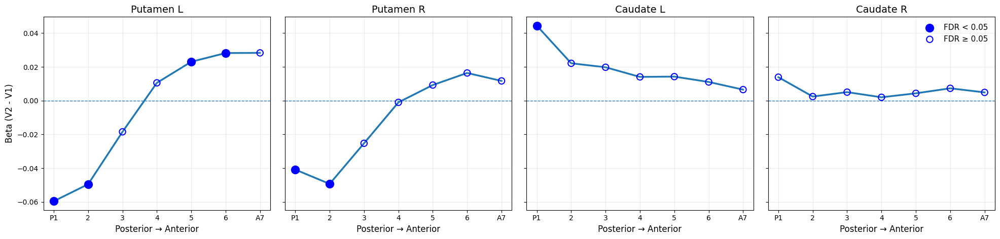

In [227]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

panels = [
    ("putamen", "L"),
    ("putamen", "R"),
    ("caudate", "L"),
    ("caudate", "R")
]

for ax, (structure, side) in zip(axes, panels):
    d = df_beta[(df_beta["structure"] == structure) & (df_beta["side"] == side)].sort_values("slice")

    ax.plot(d["slice"], d["beta_C(session)[T.2]"], linewidth=2.5,  zorder=1)

    d_sig = d[d["sig_fdr"]]
    d_nonsig = d[~d["sig_fdr"]]

    ax.scatter(d_sig["slice"], d_sig["beta_C(session)[T.2]"],
               s=110, color="blue", edgecolor="blue", linewidth=2,
               zorder=3, label="FDR < 0.05")

    ax.scatter(d_nonsig["slice"], d_nonsig["beta_C(session)[T.2]"],
               s=80, facecolors="none", edgecolors="blue", linewidth=1.5,
               zorder=3, label="FDR ≥ 0.05")

    ax.axhline(0, linestyle="--", linewidth=1)

    ax.set_title(f"{structure.capitalize()} {side}", fontsize=14)
    ax.set_xticks(range(1, 8))
    ax.set_xticklabels(["P1", "2", "3", "4", "5", "6", "A7"])
    ax.set_xlabel("Posterior → Anterior", fontsize=12)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Beta (V2 - V1)", fontsize=12)
axes[-1].legend(fontsize=11, frameon=False)

plt.tight_layout()
plt.show()

## Gradient value

In [239]:
import pandas as pd
import numpy as np
from functools import reduce

def compute_gradient(row, slice_cols):
    y = row[slice_cols].to_numpy(dtype=float)
    x = np.arange(len(y))
    mask = ~np.isnan(y)
    return np.polyfit(x[mask], y[mask], 1)[0] if mask.sum() >= 3 else np.nan

def extract_gradient(df, roi_prefix, gradient_name):
    df_wide = df[df["roi"].str.contains(roi_prefix, na=False)].pivot_table(index=["subject", "session", "group"], columns="roi", values="GM_roi_ml").reset_index()
    df_wide.columns.name = None
    slice_cols = sorted([c for c in df_wide.columns if "slice" in c], key=lambda x: int(x.split("slice")[1].split("_")[0]))
    df_wide[gradient_name] = df_wide.apply(lambda row: compute_gradient(row, slice_cols), axis=1)
    return df_wide[["subject", "session", "group", gradient_name]]

In [240]:
df_extremes = df[df["slice"].isin([1, 7])].copy()
df_extremes["position"] = df_extremes["slice"].map({
    1: "posterior",
    7: "anterior"
})
df_wide = df_extremes.pivot_table(
    index=["subject", "structure", "side", "group", "session"],
    columns="position",
    values="GM_roi_ml"
).reset_index()

df_wide["gradient"] = df_wide["anterior"] - df_wide["posterior"]
df_wide

position,subject,structure,side,group,session,anterior,posterior,gradient
0,1,caudate,L,HC,1,0.415395,0.277269,0.138127
1,1,caudate,L,HC,2,0.416490,0.270048,0.146442
2,1,caudate,R,HC,1,0.454060,0.281009,0.173051
3,1,caudate,R,HC,2,0.454402,0.277147,0.177255
4,1,putamen,L,HC,1,0.595429,0.316421,0.279008
...,...,...,...,...,...,...,...,...
547,94,caudate,R,AN,2,0.379949,0.300002,0.079947
548,94,putamen,L,AN,1,0.596525,0.348431,0.248094
549,94,putamen,L,AN,2,0.624335,0.246262,0.378073
550,94,putamen,R,AN,1,0.603841,0.367999,0.235842


In [343]:
import pandas as pd
import numpy as np
from functools import reduce

df_bg_long_grad = df_roi_long.copy()

gradient_specs = {
    "gradient_putamen_R": "putamen_R_svd_eqvox_slice",
    "gradient_putamen_L": "putamen_L_svd_eqvox_slice",
    "gradient_caudate_R": "caudate_R_svd_eqvox_slice",
    "gradient_caudate_L": "caudate_L_svd_eqvox_slice"
}

gradient_dfs = [extract_gradient(df_bg_long_grad, roi_prefix, gradient_name) for gradient_name, roi_prefix in gradient_specs.items()]
df_gradients = reduce(lambda left, right: pd.merge(left, right, on=["subject", "session", "group"], how="outer"), gradient_dfs)

remission_info = df_bg_long_grad[["subject", "session", "group", "remission_v3"]].drop_duplicates(subset=["subject", "session", "group"])
df_gradients = df_gradients.merge(remission_info, on=["subject", "session", "group"], how="left")

df_gradients["gradient_ratio_R"] = df_gradients["gradient_caudate_R"] / df_gradients["gradient_putamen_R"]
df_gradients["gradient_ratio_L"] = df_gradients["gradient_caudate_L"] / df_gradients["gradient_putamen_L"]

gradient_cols = ["gradient_putamen_R", "gradient_putamen_L", "gradient_caudate_R", "gradient_caudate_L", "gradient_ratio_R", "gradient_ratio_L"]

df_gradients_long = df_gradients.melt(id_vars=["subject", "session", "group", "remission_v3"], value_vars=gradient_cols, var_name="roi", value_name="gradient")

print(df_gradients_long["group"].value_counts(dropna=False))
df_gradients_long

group
AN    492
HC    336
Name: count, dtype: int64


,subject,session,group,remission_v3,roi,gradient
0,1,1,HC,NaN,gradient_putamen_R,0.050574
1,1,2,HC,NaN,gradient_putamen_R,0.038074
2,2,1,HC,NaN,gradient_putamen_R,0.036122
3,2,2,HC,NaN,gradient_putamen_R,0.032288
4,3,1,HC,NaN,gradient_putamen_R,0.038924
...,...,...,...,...,...,...
823,89,2,AN,NaN,gradient_ratio_L,0.110732
824,92,1,AN,relapsed,gradient_ratio_L,0.737492
825,92,2,AN,relapsed,gradient_ratio_L,0.608524
826,94,1,AN,NaN,gradient_ratio_L,0.581173


#### NMH10

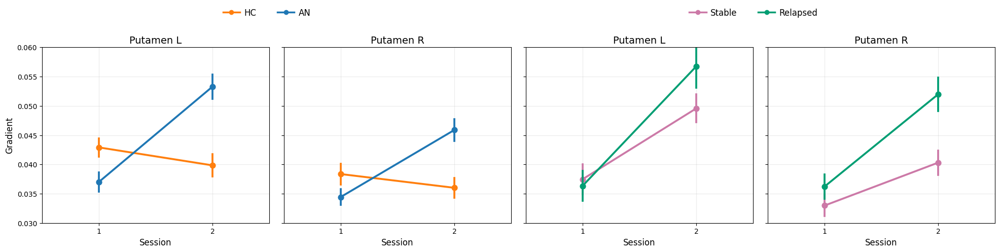

In [242]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ============================================================
# DATA
# ============================================================

df_plot = df_gradients_long[
    df_gradients_long["roi"].isin([
        "gradient_putamen_L",
        "gradient_putamen_R"
    ])
].copy()

df_plot_rem = df_plot[
    df_plot["remission_v3"].notna()
].copy()

roi_order = [
    "gradient_putamen_L",
    "gradient_putamen_R"
]

# ============================================================
# COLORS
# ============================================================

group_palette = {
    "HC": "tab:orange",
    "AN": "tab:blue"
}

remission_palette = {
    "stable": "#CC79A7",
    "relapsed": "#009E73"
}

# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

# ============================================================
# HC vs AN
# ============================================================

for ax, roi in zip(axes[:2], roi_order):

    sub = df_plot[
        df_plot["roi"] == roi
    ].copy()

    sns.pointplot(
        data=sub,
        x="session",
        y="gradient",
        hue="group",
        hue_order=["HC", "AN"],
        palette=group_palette,
        errorbar="se",
        markers="o",
        linestyles="-",
        ax=ax
    )

    ax.set_ylim(0.03, 0.06)

    if roi == "gradient_putamen_L":
        ax.set_title("Putamen L", fontsize=14)
    else:
        ax.set_title("Putamen R", fontsize=14)

    ax.set_xlabel("Session", fontsize=12)
    ax.set_ylabel("Gradient" if ax == axes[0] else "", fontsize=12)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(alpha=0.25)

    if ax.get_legend() is not None:
        ax.get_legend().remove()

# ============================================================
# STABLE vs RELAPSED
# ============================================================

for ax, roi in zip(axes[2:], roi_order):

    sub = df_plot_rem[
        df_plot_rem["roi"] == roi
    ].copy()

    sns.pointplot(
        data=sub,
        x="session",
        y="gradient",
        hue="remission_v3",
        hue_order=["stable", "relapsed"],
        palette=remission_palette,
        errorbar="se",
        markers="o",
        linestyles="-",
        ax=ax
    )

    ax.set_ylim(0.03, 0.06)

    if roi == "gradient_putamen_L":
        ax.set_title("Putamen L", fontsize=14)
    else:
        ax.set_title("Putamen R", fontsize=14)

    ax.set_xlabel("Session", fontsize=12)
    ax.set_ylabel("", fontsize=12)
    ax.tick_params(axis="both", labelsize=10)
    ax.grid(alpha=0.25)

    if ax.get_legend() is not None:
        ax.get_legend().remove()

# ============================================================
# LEGEND 1: HC → AN
# ============================================================

group_handles = [
    Line2D([0], [0], color=group_palette["HC"], marker="o", linewidth=2.5, label="HC"),
    Line2D([0], [0], color=group_palette["AN"], marker="o", linewidth=2.5, label="AN")
]

fig.legend(
    handles=group_handles,
    labels=["HC", "AN"],
    loc="upper center",
    bbox_to_anchor=(0.27, 1.02),
    ncol=2,
    frameon=False,
    fontsize=12,
    columnspacing=2.5,
    handletextpad=0.5
)

# ============================================================
# LEGEND 2: STABLE → RELAPSED
# ============================================================

remission_handles = [
    Line2D([0], [0], color=remission_palette["stable"], marker="o", linewidth=2.5, label="Stable"),
    Line2D([0], [0], color=remission_palette["relapsed"], marker="o", linewidth=2.5, label="Relapsed")
]

fig.legend(
    handles=remission_handles,
    labels=["Stable", "Relapsed"],
    loc="upper center",
    bbox_to_anchor=(0.75, 1.02),
    ncol=2,
    frameon=False,
    fontsize=12,
    columnspacing=2.5,
    handletextpad=0.5
)

# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

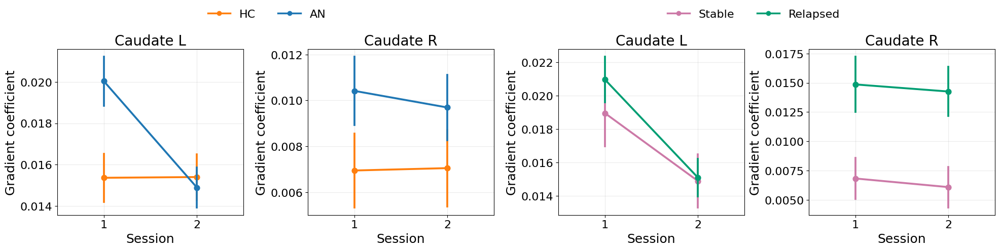

In [346]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

df_plot = df_gradients_long[
    df_gradients_long["roi"].isin([
        "gradient_caudate_L",
        "gradient_caudate_R"
    ])
].copy()

df_plot["group"] = df_plot["group"].astype(str).str.strip().str.upper()

df_plot["remission_v3"] = (
    df_plot["remission_v3"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df_plot["gradient"] = pd.to_numeric(df_plot["gradient"], errors="coerce")

df_plot_rem = df_plot[
    (df_plot["group"] == "AN") &
    (df_plot["remission_v3"].isin(["stable", "relapsed"]))
].copy()

roi_order = ["gradient_caudate_L", "gradient_caudate_R"]

group_palette = {"HC": "tab:orange", "AN": "tab:blue"}
remission_palette = {"stable": "#CC79A7", "relapsed": "#009E73"}

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=False)

for ax, roi in zip(axes[:2], roi_order):
    sub = df_plot[df_plot["roi"] == roi]

    sns.pointplot(
        data=sub,
        x="session",
        y="gradient",
        hue="group",
        hue_order=["HC", "AN"],
        palette=group_palette,
        errorbar="se",
        markers="o",
        linestyles="-",
        ax=ax
    )

    ax.set_title("Caudate L" if roi.endswith("_L") else "Caudate R")
    ax.set_xlabel("Session")
    ax.set_ylabel("Gradient coefficient")
    ax.grid(alpha=0.25)

    if ax.get_legend():
        ax.get_legend().remove()

for ax, roi in zip(axes[2:], roi_order):
    sub = df_plot_rem[df_plot_rem["roi"] == roi]

    sns.pointplot(
        data=sub,
        x="session",
        y="gradient",
        hue="remission_v3",
        hue_order=["stable", "relapsed"],
        palette=remission_palette,
        errorbar="se",
        markers="o",
        linestyles="-",
        ax=ax
    )

    ax.set_title("Caudate L" if roi.endswith("_L") else "Caudate R")
    ax.set_xlabel("Session")
    ax.set_ylabel("Gradient coefficient")
    ax.grid(alpha=0.25)

    if ax.get_legend():
        ax.get_legend().remove()

group_handles = [
    Line2D([0], [0], color=group_palette[g], marker="o", lw=2.5, label=g)
    for g in ["HC", "AN"]
]

remission_handles = [
    Line2D([0], [0], color=remission_palette[g], marker="o", lw=2.5, label=g.capitalize())
    for g in ["stable", "relapsed"]
]

fig.legend(
    handles=group_handles,
    loc="upper center",
    bbox_to_anchor=(0.27, 1.02),
    ncol=2,
    frameon=False
)

fig.legend(
    handles=remission_handles,
    loc="upper center",
    bbox_to_anchor=(0.75, 1.02),
    ncol=2,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

In [245]:
df_age = redcap_data_filtered[["subject", "age"]].dropna(subset=["subject"]).copy()
df_age["subject"] = df_age["subject"].astype(int)
df_age = df_age.drop_duplicates("subject")

df_tiv = df_tiv_long[["subject", "session", "TIV_ml"]].copy()
df_tiv["subject"] = df_tiv["subject"].astype(int)
df_tiv = df_tiv.drop_duplicates(["subject", "session"])

df_gradients_long["subject"] = df_gradients_long["subject"].astype(int)
df_gradients_long = df_gradients_long.merge(df_age, on="subject", how="left").merge(df_tiv, on=["subject", "session"], how="left")

print(df_gradients_long.columns)
df_gradients_long

Index(['subject', 'session', 'group', 'remission_v3', 'roi', 'gradient', 'age',
       'TIV_ml'],
      dtype='str')


,subject,session,group,remission_v3,roi,gradient,age,TIV_ml
0,1,1,HC,NaN,gradient_putamen_R,0.050574,33.0,1278.788153
1,1,2,HC,NaN,gradient_putamen_R,0.038074,33.0,1278.465869
2,2,1,HC,NaN,gradient_putamen_R,0.036122,47.0,1146.977361
3,2,2,HC,NaN,gradient_putamen_R,0.032288,47.0,1146.627369
4,3,1,HC,NaN,gradient_putamen_R,0.038924,27.0,1532.262295
...,...,...,...,...,...,...,...,...
823,89,2,AN,NaN,gradient_ratio_L,0.110732,19.0,1334.196348
824,92,1,AN,relapsed,gradient_ratio_L,0.737492,45.0,1229.516935
825,92,2,AN,relapsed,gradient_ratio_L,0.608524,45.0,1228.221326
826,94,1,AN,NaN,gradient_ratio_L,0.581173,33.0,1364.826348


In [246]:
df_gradients = df_gradients.merge(
    df_age,
    on="subject",
    how="left"
)


df_gradients = df_gradients.merge(
    df_tiv,
    on=["subject", "session"],
    how="left"
)


print(df_gradients.columns)


df_gradients

Index(['subject', 'session', 'group', 'gradient_putamen_R',
       'gradient_putamen_L', 'gradient_caudate_R', 'gradient_caudate_L',
       'remission_v3', 'gradient_ratio_R', 'gradient_ratio_L', 'age',
       'TIV_ml'],
      dtype='str')


,subject,session,group,gradient_putamen_R,gradient_putamen_L,gradient_caudate_R,gradient_caudate_L,remission_v3,gradient_ratio_R,gradient_ratio_L,age,TIV_ml
0,1,1,HC,0.050574,0.039497,0.023744,0.022346,NaN,0.469497,0.565758,33.0,1278.788153
1,1,2,HC,0.038074,0.034701,0.024264,0.023041,NaN,0.637286,0.663973,33.0,1278.465869
2,2,1,HC,0.036122,0.041851,0.008756,0.009832,NaN,0.242406,0.234924,47.0,1146.977361
3,2,2,HC,0.032288,0.033387,0.008557,0.011929,NaN,0.265018,0.357300,47.0,1146.627369
4,3,1,HC,0.038924,0.036483,0.019107,0.018731,NaN,0.490877,0.513410,27.0,1532.262295
...,...,...,...,...,...,...,...,...,...,...,...,...
133,89,2,AN,0.044095,0.064497,0.006213,0.007142,NaN,0.140899,0.110732,19.0,1334.196348
134,92,1,AN,0.033398,0.034841,0.019604,0.025695,relapsed,0.586994,0.737492,45.0,1229.516935
135,92,2,AN,0.033925,0.036755,0.017480,0.022366,relapsed,0.515262,0.608524,45.0,1228.221326
136,94,1,AN,0.038959,0.038492,0.007447,0.022370,NaN,0.191136,0.581173,33.0,1364.826348


### group

In [247]:
from statsmodels.stats.multitest import multipletests

gradient_cols = ["gradient_putamen_R", "gradient_putamen_L", "gradient_caudate_R", "gradient_caudate_L", "gradient_ratio_R", "gradient_ratio_L"]

res_ratios_all_slices = utils_smri.run_global_models(data=df_gradients[df_gradients["session"] == 1], outcomes=gradient_cols, formula_template="{Y} ~ C(group) + age", model_type="ols", dropna_extra=["group", "age"], terms_of_interest=["C(group)[T.HC]"])

term = "C(group)[T.HC]"
p_col = f"p_{term}"
mask = res_ratios_all_slices[p_col].notna()
res_ratios_all_slices.loc[mask, "p_fdr"] = multipletests(res_ratios_all_slices.loc[mask, p_col], method="fdr_bh")[1]

res_ratios_all_slices.sort_values("p_fdr")

,outcome,n,R2,adj_R2,F,p_model,beta_C(group)[T.HC],p_C(group)[T.HC],formula,p_fdr
5,gradient_ratio_L,69,0.169821,0.144664,6.750440,0.002151,-0.249106,0.000604,gradient_ratio_L ~ C(group) + age,0.003626
3,gradient_caudate_L,69,0.165199,0.139902,6.530358,0.002584,-0.005054,0.003693,gradient_caudate_L ~ C(group) + age,0.011078
1,gradient_putamen_L,69,0.099108,0.071809,3.630380,0.031930,0.005647,0.022598,gradient_putamen_L ~ C(group) + age,0.045196
4,gradient_ratio_R,69,0.062402,0.033990,2.196317,0.119276,-0.138114,0.041954,gradient_ratio_R ~ C(group) + age,0.062931
2,gradient_caudate_R,69,0.041075,0.012017,1.413534,0.250550,-0.003624,0.113548,gradient_caudate_R ~ C(group) + age,0.113548
0,gradient_putamen_R,69,0.061559,0.033121,2.164702,0.122866,0.003690,0.097381,gradient_putamen_R ~ C(group) + age,0.113548


### session

In [341]:
from statsmodels.stats.multitest import multipletests
from IPython.display import display
import numpy as np

gradient_cols = [
    "gradient_putamen_L",
    "gradient_putamen_R",
    "gradient_caudate_L",
    "gradient_caudate_R",
    "gradient_ratio_L",
    "gradient_ratio_R"
]

df_an = df_gradients[
    (df_gradients["group"] == "AN") &
    (df_gradients["session"].isin([1, 2]))
].copy()

res_long = utils_smri.run_global_models(
    data=df_an,
    outcomes=gradient_cols,
    formula_template="{Y} ~ C(session) + age",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["age", "session"],
    terms_of_interest=["C(session)[T.2]"]
)

term = "C(session)[T.2]"
p_col = f"p_{term}"

res_long["p_fdr"] = np.nan

if p_col in res_long.columns:
    mask = res_long[p_col].notna()
    if mask.any():
        res_long.loc[mask, "p_fdr"] = multipletests(
            res_long.loc[mask, p_col],
            method="fdr_bh"
        )[1]

display(res_long)

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2245: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the

,outcome,n,R2,adj_R2,F,p_model,beta_C(session)[T.2],p_C(session)[T.2],formula,model_used,mixedlm_error,p_fdr
0,gradient_putamen_L,82,0.334968,0.318132,34.552563,1.924406e-09,0.016284,1.842255e-15,gradient_putamen_L ~ C(session) + age,ols_cluster_subject,Singular matrix,1.105353e-14
1,gradient_putamen_R,82,NaN,NaN,NaN,NaN,0.011448,2.032388e-13,gradient_putamen_R ~ C(session) + age,NaN,NaN,6.097163e-13
2,gradient_caudate_L,82,NaN,NaN,NaN,NaN,-0.005135,7.958379e-12,gradient_caudate_L ~ C(session) + age,NaN,NaN,1.591676e-11
3,gradient_caudate_R,82,NaN,NaN,NaN,NaN,-0.000724,1.528167e-02,gradient_caudate_R ~ C(session) + age,NaN,NaN,1.528167e-02
4,gradient_ratio_L,82,NaN,NaN,NaN,NaN,-0.304897,3.995238e-11,gradient_ratio_L ~ C(session) + age,NaN,NaN,5.992857e-11
5,gradient_ratio_R,82,NaN,NaN,NaN,NaN,-0.101410,2.799334e-07,gradient_ratio_R ~ C(session) + age,NaN,NaN,3.359201e-07


#### NMH8

In [334]:
import pandas as pd
import numpy as np
from statsmodels.stats.multitest import multipletests
from IPython.display import display

gradient_cols = [
    "gradient_putamen_L",
    "gradient_putamen_R",
    "gradient_caudate_L",
    "gradient_caudate_R",
    "gradient_ratio_L",
    "gradient_ratio_R"
]

df_gs = df_gradients[
    (df_gradients["group"].isin(["AN", "HC"])) &
    (df_gradients["session"].isin([1, 2]))
].copy()

df_gs["session"] = df_gs["session"].astype(int)
df_gs["group"] = pd.Categorical(
    df_gs["group"],
    categories=["AN", "HC"]
)

res_long_gs = utils_smri.run_global_models(
    data=df_gs,
    outcomes=gradient_cols,
    formula_template="{Y} ~ C(group) * C(session) + age",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["group", "session", "age"],
    terms_of_interest=["C(group)[T.HC]:C(session)[T.2]"]
)

term = "C(group)[T.HC]:C(session)[T.2]"
p_col = f"p_{term}"
beta_col = f"beta_{term}"

res_long_gs["p_fdr"] = np.nan

if p_col in res_long_gs.columns:
    mask = res_long_gs[p_col].notna()

    if mask.any():
        res_long_gs.loc[mask, "p_fdr"] = multipletests(
            res_long_gs.loc[mask, p_col],
            method="fdr_bh"
        )[1]

    columns = (
        ["outcome"]
        + [c for c in ["n", "n_subjects"] if c in res_long_gs.columns]
        + [c for c in [beta_col, p_col, "p_fdr", "model_used", "mixedlm_error", "error"]
           if c in res_long_gs.columns]
    )

    display(res_long_gs[columns].sort_values("p_fdr"))

else:
    print("Interaction term not found.")
    print("Available columns:", res_long_gs.columns.tolist())
    print(res_long_gs.to_string(index=False))

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression

,outcome,n,beta_C(group)[T.HC]:C(session)[T.2],p_C(group)[T.HC]:C(session)[T.2],p_fdr,model_used,mixedlm_error
0,gradient_putamen_L,138,-0.019350,1.212403e-14,7.274416e-14,NaN,NaN
4,gradient_ratio_L,138,0.342694,9.046092e-12,2.713828e-11,ols_cluster_subject,Singular matrix
1,gradient_putamen_R,138,-0.013795,4.938861e-11,9.877722e-11,NaN,NaN
2,gradient_caudate_L,138,0.005171,8.916094e-08,1.337414e-07,NaN,NaN
5,gradient_ratio_R,138,0.122778,5.678379e-06,6.814055e-06,NaN,NaN
3,gradient_caudate_R,138,0.000828,3.760679e-02,3.760679e-02,NaN,NaN


### remission

In [335]:
import pandas as pd
import numpy as np
from statsmodels.stats.multitest import multipletests
from IPython.display import display

gradient_cols = [
    "gradient_putamen_L",
    "gradient_putamen_R",
    "gradient_caudate_L",
    "gradient_caudate_R",
    "gradient_ratio_L",
    "gradient_ratio_R"
]

df_rem = df_gradients[
    (df_gradients["group"] == "AN") &
    (df_gradients["session"] == 1) &
    (df_gradients["remission_v3"].isin(["stable", "relapsed"]))
].copy()

df_rem["remission_v3"] = pd.Categorical(
    df_rem["remission_v3"],
    categories=["relapsed", "stable"]
)

res_ratios_all_rem = utils_smri.run_global_models(
    data=df_rem,
    outcomes=gradient_cols,
    formula_template="{Y} ~ C(remission_v3) + age",
    model_type="ols",
    dropna_extra=["remission_v3", "age"],
    terms_of_interest=["C(remission_v3)[T.stable]"]
)

term = "C(remission_v3)[T.stable]"
p_col = f"p_{term}"
beta_col = f"beta_{term}"

res_ratios_all_rem["p_fdr"] = np.nan

if p_col in res_ratios_all_rem.columns:
    mask = res_ratios_all_rem[p_col].notna()

    if mask.any():
        res_ratios_all_rem.loc[mask, "p_fdr"] = multipletests(
            res_ratios_all_rem.loc[mask, p_col],
            method="fdr_bh"
        )[1]

    columns = (
        ["outcome"]
        + [c for c in ["n", "n_subjects"] if c in res_ratios_all_rem.columns]
        + [c for c in [beta_col, p_col, "p_fdr", "error"]
           if c in res_ratios_all_rem.columns]
    )

    display(res_ratios_all_rem[columns].sort_values("p_fdr"))

else:
    print("Remission coefficient not found.")
    print(res_ratios_all_rem.to_string(index=False))

,outcome,n,beta_C(remission_v3)[T.stable],p_C(remission_v3)[T.stable],p_fdr
3,gradient_caudate_R,39,-0.008528,0.004972,0.029834
5,gradient_ratio_R,39,-0.245097,0.011185,0.033555
2,gradient_caudate_L,39,-0.002620,0.276473,0.331767
1,gradient_putamen_R,39,-0.003662,0.191891,0.331767
4,gradient_ratio_L,39,-0.131951,0.261196,0.331767
0,gradient_putamen_L,39,0.000873,0.811630,0.811630


### remission*session

#### NMH9

In [336]:
import pandas as pd
import numpy as np
from statsmodels.stats.multitest import multipletests
from IPython.display import display

gradient_cols = [
    "gradient_putamen_L",
    "gradient_putamen_R",
    "gradient_caudate_L",
    "gradient_caudate_R",
    "gradient_ratio_L",
    "gradient_ratio_R"
]

df_rem = df_gradients[
    (df_gradients["group"] == "AN") &
    (df_gradients["session"].isin([1, 2])) &
    (df_gradients["remission_v3"].isin(["stable", "relapsed"]))
].copy()

df_rem["session"] = df_rem["session"].astype(int)
df_rem["remission_v3"] = pd.Categorical(
    df_rem["remission_v3"],
    categories=["relapsed", "stable"]
)

res_long_rem = utils_smri.run_global_models(
    data=df_rem,
    outcomes=gradient_cols,
    formula_template="{Y} ~ C(remission_v3) * C(session) + age",
    model_type="mixedlm",
    group_col="subject",
    dropna_extra=["remission_v3", "session", "age"],
    terms_of_interest=["C(remission_v3)[T.stable]:C(session)[T.2]"]
)

term = "C(remission_v3)[T.stable]:C(session)[T.2]"
p_col = f"p_{term}"
beta_col = f"beta_{term}"

res_long_rem["p_fdr"] = np.nan

if p_col in res_long_rem.columns:
    mask = res_long_rem[p_col].notna()

    if mask.any():
        res_long_rem.loc[mask, "p_fdr"] = multipletests(
            res_long_rem.loc[mask, p_col],
            method="fdr_bh"
        )[1]

    columns = [
        c for c in [
            "outcome", "n", "n_subjects", beta_col,
            p_col, "p_fdr", "model_used", "mixedlm_error", "error"
        ]
        if c in res_long_rem.columns
    ]

    display(res_long_rem[columns].sort_values("p_fdr"))

else:
    print("Interaction term not found.")
    print(res_long_rem.to_string(index=False))

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2245: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the

,outcome,n,beta_C(remission_v3)[T.stable]:C(session)[T.2],p_C(remission_v3)[T.stable]:C(session)[T.2],p_fdr,model_used,mixedlm_error
1,gradient_putamen_R,78,-0.008432,0.004638,0.027829,NaN,NaN
0,gradient_putamen_L,78,-0.008316,0.047898,0.095796,ols_cluster_subject,Singular matrix
5,gradient_ratio_R,78,0.078110,0.047877,0.095796,NaN,NaN
2,gradient_caudate_L,78,0.001810,0.209875,0.251850,NaN,NaN
4,gradient_ratio_L,78,0.131977,0.195736,0.251850,ols_cluster_subject,Singular matrix
3,gradient_caudate_R,78,-0.000132,0.831568,0.831568,NaN,NaN


### predicts outcome category longitudinale

In [255]:
gradient_cols = ["gradient_putamen_R", "gradient_putamen_L", "gradient_caudate_R", "gradient_caudate_L", "gradient_ratio_R", "gradient_ratio_L"]
df_age = df_roi_long[["subject", "age"]].dropna(subset=["age"]).drop_duplicates("subject")

df_gradients["subject"] = df_gradients["subject"].astype(int)
df_age["subject"] = df_age["subject"].astype(int)

df_gradients = df_gradients.drop(columns=["age"], errors="ignore").merge(df_age, on="subject", how="left")
df_an = df_gradients[df_gradients["group"] == "AN"].copy()

df_delta_grad = df_an.pivot_table(index=["subject", "remission_v3", "age"], columns="session", values=gradient_cols)
df_delta_grad.columns = [f"{grad}_s{int(session)}" for grad, session in df_delta_grad.columns]
df_delta_grad = df_delta_grad.reset_index()

for grad in gradient_cols:
    df_delta_grad[f"delta_{grad}"] = df_delta_grad[f"{grad}_s2"] - df_delta_grad[f"{grad}_s1"]

df_delta_grad = df_delta_grad[df_delta_grad["remission_v3"].isin(["stable", "relapsed"])].copy()
df_delta_grad["remission_bin"] = (df_delta_grad["remission_v3"] == "stable").astype(int)

df_delta_grad

,subject,remission_v3,age,gradient_caudate_L_s1,gradient_caudate_L_s2,gradient_caudate_R_s1,gradient_caudate_R_s2,gradient_putamen_L_s1,gradient_putamen_L_s2,gradient_putamen_R_s1,...,gradient_ratio_L_s2,gradient_ratio_R_s1,gradient_ratio_R_s2,delta_gradient_putamen_R,delta_gradient_putamen_L,delta_gradient_caudate_R,delta_gradient_caudate_L,delta_gradient_ratio_R,delta_gradient_ratio_L,remission_bin
0,6,stable,34.0,0.010221,0.011687,-0.001468,-0.002041,0.021639,0.032300,0.027937,...,0.361826,-0.052535,-0.070671,0.000938,0.010661,-0.000573,0.001466,-0.018136,-0.110526,1
1,7,stable,29.0,0.021847,0.020578,0.015036,0.014492,0.029265,0.047682,0.029393,...,0.431574,0.511552,0.405274,0.006366,0.018416,-0.000544,-0.001269,-0.106279,-0.314957,1
2,10,relapsed,25.0,0.019597,0.015545,0.012160,0.014478,0.038930,0.095951,0.039892,...,0.162009,0.304825,0.191632,0.035659,0.057021,0.002318,-0.004052,-0.113193,-0.341387,0
3,12,stable,18.0,0.033211,0.019001,-0.002568,-0.003626,0.042213,0.068330,0.028449,...,0.278071,-0.090251,-0.103490,0.006591,0.026117,-0.001059,-0.014210,-0.013239,-0.508679,1
4,13,relapsed,31.0,0.021191,0.015057,0.012530,0.012892,0.009998,0.039088,0.020214,...,0.385204,0.619845,0.320860,0.019966,0.029090,0.000363,-0.006134,-0.298985,-1.734284,0
5,15,stable,21.0,0.015375,0.013673,0.009364,0.008738,0.031633,0.033944,0.037012,...,0.402820,0.252994,0.223143,0.002147,0.002311,-0.000626,-0.001702,-0.029851,-0.083226,1
6,16,stable,23.0,0.017546,0.015139,0.005555,0.005851,0.029005,0.035802,0.019709,...,0.422857,0.281824,0.201299,0.009356,0.006797,0.000296,-0.002407,-0.080524,-0.182089,1
7,17,relapsed,48.0,0.020226,0.018459,0.006935,0.004052,0.032327,0.035114,0.018683,...,0.525677,0.371197,0.086376,0.028228,0.002788,-0.002883,-0.001767,-0.284821,-0.099987,0
8,18,relapsed,24.0,0.012204,0.007875,0.009458,0.009086,0.025235,0.059051,0.033194,...,0.133353,0.284936,0.178168,0.017803,0.033816,-0.000372,-0.004329,-0.106768,-0.350256,0
9,20,relapsed,21.0,0.019383,0.016277,0.019686,0.020190,0.031420,0.047099,0.032363,...,0.345586,0.608286,0.447920,0.012711,0.015679,0.000503,-0.003106,-0.160366,-0.271320,0


#### NMH11

In [256]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
from scipy.stats import zscore
from statsmodels.stats.multitest import multipletests

delta_cols = [f"delta_{gradient}" for gradient in gradient_cols]
results = []

for delta in delta_cols:
    dfi = df_delta_grad[["remission_bin", delta, "age"]].dropna().copy()

    if dfi["remission_bin"].nunique() < 2 or dfi[delta].std() == 0:
        results.append({"predictor": delta, "n": len(dfi), "error": "Only one remission class or zero predictor variance"})
        continue

    try:
        dfi["delta_z"] = zscore(dfi[delta].astype(float))
        X = sm.add_constant(dfi[["delta_z", "age"]].astype(float))
        y = dfi["remission_bin"].astype(int)
        model = sm.Logit(y, X).fit(disp=False)
        pred = model.predict(X)
        beta = model.params["delta_z"]

        results.append({"predictor": delta, "n": len(dfi), "beta_z": beta, "OR_per_1SD": np.exp(beta), "p": model.pvalues["delta_z"], "beta_age": model.params["age"], "p_age": model.pvalues["age"], "AUC": roc_auc_score(y, pred), "pseudo_R2": model.prsquared, "error": np.nan})
    except Exception as e:
        results.append({"predictor": delta, "n": len(dfi), "error": str(e)})

res_logit_delta_gradients_z = pd.DataFrame(results)
mask = res_logit_delta_gradients_z["p"].notna() & np.isfinite(res_logit_delta_gradients_z["p"])
res_logit_delta_gradients_z.loc[mask, "p_fdr"] = multipletests(res_logit_delta_gradients_z.loc[mask, "p"], method="fdr_bh")[1]

res_logit_delta_gradients_z.sort_values("p", na_position="last")

,predictor,n,beta_z,OR_per_1SD,p,beta_age,p_age,AUC,pseudo_R2,error,p_fdr
0,delta_gradient_putamen_R,39,-0.980970,0.374947,0.020351,-0.015693,0.634730,0.732804,0.138138,NaN,0.122107
1,delta_gradient_putamen_L,39,-0.796953,0.450700,0.052296,-0.031142,0.322417,0.687831,0.096716,NaN,0.143385
4,delta_gradient_ratio_R,39,0.718555,2.051466,0.071692,-0.027515,0.384364,0.706349,0.083947,NaN,0.143385
3,delta_gradient_caudate_L,39,0.548754,1.731096,0.136767,-0.037953,0.261952,0.661376,0.053438,NaN,0.205150
5,delta_gradient_ratio_L,39,0.662483,1.939602,0.173489,-0.032521,0.307602,0.642857,0.057691,NaN,0.208186
2,delta_gradient_caudate_R,39,-0.058845,0.942853,0.856937,-0.020073,0.499609,0.568783,0.009383,NaN,0.856937


In [337]:
print(df_delta_grad.groupby("remission_v3")["remission_bin"].value_counts())

remission_v3  remission_bin
relapsed      0                18
stable        1                21
Name: count, dtype: int64


#### NMH11

/tmp/ipykernel_185855/2098863727.py:65: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


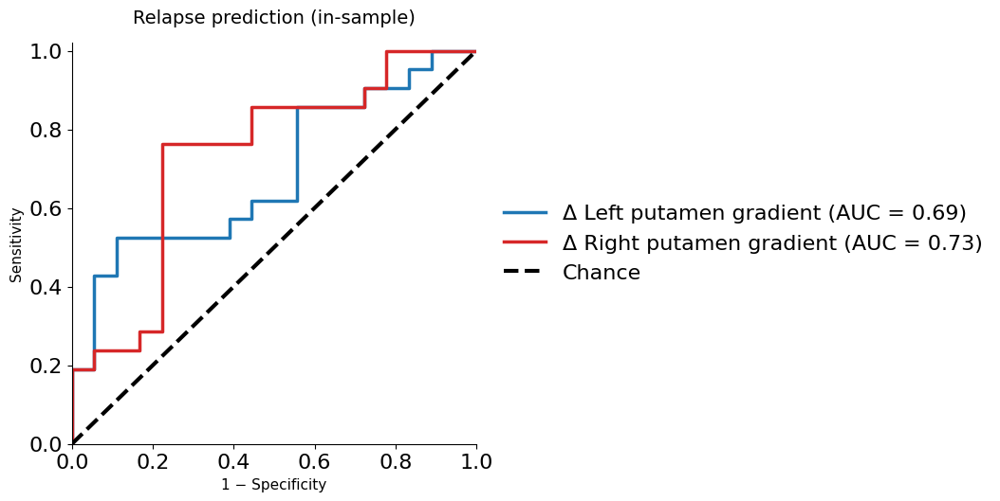

In [340]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve
from scipy.stats import zscore
from statsmodels.stats.multitest import multipletests

delta_cols=[f"delta_{gradient}" for gradient in gradient_cols]
results=[]
roc_data={}

for delta in delta_cols:
    dfi=df_delta_grad[["remission_bin",delta,"age"]].dropna().copy()
    if dfi["remission_bin"].nunique()<2 or dfi[delta].std()==0:
        results.append({"predictor":delta,"n":len(dfi),"error":"Only one remission class or zero predictor variance"})
        continue
    try:
        dfi["delta_z"]=zscore(dfi[delta].astype(float))
        X=sm.add_constant(dfi[["delta_z","age"]].astype(float))
        y=dfi["remission_bin"].astype(int)
        model=sm.Logit(y,X).fit(disp=False)
        pred=model.predict(X)
        beta=model.params["delta_z"]
        auc=roc_auc_score(y,pred)
        fpr,tpr,thresholds=roc_curve(y,pred)
        roc_data[delta]={"fpr":fpr,"tpr":tpr,"thresholds":thresholds,"auc":auc,"OR":np.exp(beta),"p":model.pvalues["delta_z"],"n":len(dfi)}
        results.append({"predictor":delta,"n":len(dfi),"beta_z":beta,"OR_per_1SD":np.exp(beta),"p":model.pvalues["delta_z"],"beta_age":model.params["age"],"p_age":model.pvalues["age"],"AUC":auc,"pseudo_R2":model.prsquared,"error":np.nan})
    except Exception as e:
        results.append({"predictor":delta,"n":len(dfi),"error":str(e)})

res_logit_delta_gradients_z=pd.DataFrame(results)
mask=res_logit_delta_gradients_z["p"].notna()&np.isfinite(res_logit_delta_gradients_z["p"])
res_logit_delta_gradients_z.loc[mask,"p_fdr"]=multipletests(res_logit_delta_gradients_z.loc[mask,"p"],method="fdr_bh")[1]
res_logit_delta_gradients_z=res_logit_delta_gradients_z.sort_values("p",na_position="last")

fig, ax = plt.subplots(figsize=(5.5,5.5))

colors = {
    "delta_gradient_putamen_L": "#1f77b4",
    "delta_gradient_putamen_R": "#d62728"
}

labels = {
    "delta_gradient_putamen_L": f"Δ Left putamen gradient (AUC = {roc_data['delta_gradient_putamen_L']['auc']:.2f})",
    "delta_gradient_putamen_R": f"Δ Right putamen gradient (AUC = {roc_data['delta_gradient_putamen_R']['auc']:.2f})"
}

for predictor in ["delta_gradient_putamen_L","delta_gradient_putamen_R"]:
    r = roc_data[predictor]
    ax.plot(r["fpr"], r["tpr"], lw=2.5, color=colors[predictor], label=labels[predictor])

ax.plot([0,1],[0,1], linestyle="--", color="black", lw=3, label="Chance")

ax.set_xlim(0,1)
ax.set_ylim(0,1.02)
ax.set_title("Relapse prediction (in-sample)", fontsize=14, pad=15)
ax.set_xlabel("1 − Specificity", fontsize=11)
ax.set_ylabel("Sensitivity", fontsize=11)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="center left", bbox_to_anchor=(1.02,0.5), frameon=False)
plt.tight_layout()
plt.show()

In [261]:
from pathlib import Path
import xml.etree.ElementTree as ET
import re
import numpy as np
import pandas as pd

# ============================================================
# PATHS
# ============================================================

cat12_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm_long")
out_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/qc_smri")
out_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# FIND CAT12 XML FILES
# ============================================================

xml_files = sorted(cat12_dir.rglob("cat_rsub-*_ses-*_T1w.xml"))

print(f"Found {len(xml_files)} longitudinal CAT12 XML files")

# ============================================================
# HELPERS
# ============================================================

def get_float(root, path):
    node = root.find(path)
    if node is None or node.text is None:
        return np.nan
    try:
        return float(node.text.strip())
    except Exception:
        return np.nan

def get_text(root, path):
    node = root.find(path)
    if node is None or node.text is None:
        return None
    return node.text.strip()

def parse_iqr_percent_grade(root):
    iqr_percent = np.nan
    grade = None

    for item in root.findall(".//catlog/item"):
        txt = item.text or ""
        m = re.search(r"Image Quality Rating\s*\(IQR\):\s*([\d.]+)%\s*\(([^)]+)\)", txt)
        if m:
            iqr_percent = float(m.group(1))
            grade = m.group(2).strip()
            break

    return iqr_percent, grade

# ============================================================
# EXTRACT QC
# ============================================================

rows = []

for xml_file in xml_files:

    try:
        root = ET.parse(xml_file).getroot()

        text = str(xml_file)

        sub_match = re.search(r"(sub-\d+)", text)
        ses_match = re.search(r"(ses-[A-Za-z0-9]+)", text)

        subject = sub_match.group(1) if sub_match else None
        session = ses_match.group(1) if ses_match else None

        iqr_percent, grade = parse_iqr_percent_grade(root)

        row = {
            "subject": subject,
            "session": session,
            "xml_path": str(xml_file),

            # CAT12 summary quality
            "IQR_percent": iqr_percent,
            "IQR_grade": grade,

            # Raw CAT12 quality rating
            "IQR_raw": get_float(root, ".//qualityratings/IQR"),

            # Image-quality measures
            "NCR": get_float(root, ".//qualitymeasures/NCR"),
            "ICR": get_float(root, ".//qualitymeasures/ICR"),
            "contrast": get_float(root, ".//qualitymeasures/contrast"),
            "contrastr": get_float(root, ".//qualitymeasures/contrastr"),

            # Resolution
            "res_RMS": get_float(root, ".//qualitymeasures/res_RMS"),
            "res_ECR": get_float(root, ".//qualitymeasures/res_ECR"),
            "res_BB": get_float(root, ".//qualitymeasures/res_BB"),

            # Surface QC
            "SurfaceEulerNumber": get_float(root, ".//qualitymeasures/SurfaceEulerNumber"),
            "SurfaceDefectArea": get_float(root, ".//qualitymeasures/SurfaceDefectArea"),
            "SurfaceDefectNumber": get_float(root, ".//qualitymeasures/SurfaceDefectNumber"),
            "SurfaceIntensityRMSE": get_float(root, ".//qualitymeasures/SurfaceIntensityRMSE"),
            "SurfacePositionRMSE": get_float(root, ".//qualitymeasures/SurfacePositionRMSE"),

            # Volumetric information
            "TIV_ml": get_float(root, ".//subjectmeasures/vol_TIV"),
            "WMH_relative": get_float(root, ".//subjectmeasures/vol_rel_WMH"),

            # CAT12 version
            "CAT12_version": get_text(root, ".//software/version_cat"),
            "CAT12_revision": get_text(root, ".//software/revision_cat"),
        }

        rows.append(row)

    except Exception as e:
        print("ERROR:", xml_file, e)

qc_df = pd.DataFrame(rows)

# ============================================================
# REMOVE DUPLICATES IF SAME SUBJECT/SESSION APPEARS MORE THAN ONCE
# ============================================================

qc_df = qc_df.sort_values(["subject", "session", "IQR_percent"], ascending=[True, True, False])

# ============================================================
# SIMPLE REVIEW FLAGS
# ============================================================

qc_df["qc_review"] = False
qc_df["qc_reason"] = ""

for i, row in qc_df.iterrows():

    reasons = []

    if pd.isna(row["IQR_percent"]):
        reasons.append("missing_IQR")

    if pd.notna(row["IQR_grade"]) and row["IQR_grade"] not in ["A", "B"]:
        reasons.append(f"IQR_grade_{row['IQR_grade']}")

    if pd.notna(row["res_BB"]) and row["res_BB"] > 0:
        reasons.append("brain_near_image_boundary")

    qc_df.loc[i, "qc_reason"] = "; ".join(reasons)
    qc_df.loc[i, "qc_review"] = len(reasons) > 0

# ============================================================
# SAVE
# ============================================================

out_csv = out_dir / "CAT12_QC_longitudinal.csv"
qc_df.to_csv(out_csv, index=False)

print("\nSaved:")
print(out_csv)

# ============================================================
# SUMMARY
# ============================================================

print("\n=== IQR SUMMARY ===")
print(qc_df["IQR_percent"].describe())

print("\n=== CAT12 GRADES ===")
print(qc_df["IQR_grade"].value_counts(dropna=False))

print("\n=== SUBJECTS FLAGGED FOR REVIEW ===")
display(
    qc_df.loc[
        qc_df["qc_review"],
        ["subject", "session", "IQR_percent", "IQR_grade", "NCR", "ICR", "qc_reason"]
    ].sort_values("IQR_percent")
)

print("\n=== WORST IQR SCORES ===")
display(
    qc_df[
        ["subject", "session", "IQR_percent", "IQR_grade", "NCR", "ICR", "res_BB"]
    ].sort_values("IQR_percent").head(20)
)

qc_df

Found 188 longitudinal CAT12 XML files

Saved:
/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/qc_smri/CAT12_QC_longitudinal.csv

=== IQR SUMMARY ===
count    154.000000
mean      86.297143
std        0.333539
min       84.580000
25%       86.252500
50%       86.395000
75%       86.487500
max       86.580000
Name: IQR_percent, dtype: float64

=== CAT12 GRADES ===
IQR_grade
B      154
NaN     34
Name: count, dtype: int64

=== SUBJECTS FLAGGED FOR REVIEW ===


,subject,session,IQR_percent,IQR_grade,NCR,ICR,qc_reason
20,sub-12,ses-V1,NaN,NaN,0.142392,0.992526,missing_IQR
21,sub-12,ses-V1,NaN,NaN,0.142392,0.992526,missing_IQR
22,sub-12,ses-V2,NaN,NaN,0.176492,1.051397,missing_IQR
23,sub-12,ses-V2,NaN,NaN,0.176492,1.051397,missing_IQR
28,sub-15,ses-V1,NaN,NaN,0.079348,0.669484,missing_IQR
29,sub-15,ses-V1,NaN,NaN,0.079348,0.669484,missing_IQR
30,sub-15,ses-V2,NaN,NaN,0.083303,0.613204,missing_IQR
31,sub-15,ses-V2,NaN,NaN,0.083303,0.613204,missing_IQR
52,sub-23,ses-V1,NaN,NaN,0.097685,0.907135,missing_IQR
53,sub-23,ses-V1,NaN,NaN,0.097685,0.907135,missing_IQR



=== WORST IQR SCORES ===


,subject,session,IQR_percent,IQR_grade,NCR,ICR,res_BB
116,sub-50,ses-V1,84.58,B,0.121752,1.051337,0.0
154,sub-70,ses-V1,84.75,B,0.119607,0.954358,0.0
108,sub-45,ses-V1,84.97,B,0.116617,0.734705,0.0
137,sub-61,ses-V2,85.09,B,0.115027,0.977003,0.0
119,sub-52,ses-V2,85.26,B,0.112435,0.778432,0.0
38,sub-17,ses-V2,85.51,B,0.108359,0.677488,0.0
39,sub-17,ses-V2,85.51,B,0.108359,0.677488,0.0
135,sub-60,ses-V2,85.54,B,0.107741,1.058136,0.0
162,sub-74,ses-V1,85.81,B,0.102653,0.877790,0.0
175,sub-82,ses-V2,85.85,B,0.101657,1.275449,0.0


,subject,session,xml_path,IQR_percent,IQR_grade,IQR_raw,NCR,ICR,contrast,contrastr,...,SurfaceDefectArea,SurfaceDefectNumber,SurfaceIntensityRMSE,SurfacePositionRMSE,TIV_ml,WMH_relative,CAT12_version,CAT12_revision,qc_review,qc_reason
0,sub-01,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.55,B,1.845046,0.072542,0.668313,47.351860,0.233764,...,0.287310,0.0,0.076518,0.089472,NaN,NaN,12.9,2577,False,
1,sub-01,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.51,B,1.849065,0.076422,0.716897,45.721413,0.222405,...,0.287310,0.0,0.074465,0.084146,NaN,NaN,12.9,2577,False,
2,sub-02,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.17,B,1.882733,0.093091,0.564535,55.974518,0.288395,...,0.964686,0.0,0.088655,0.106413,NaN,NaN,12.9,2577,False,
3,sub-02,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,85.95,B,1.905109,0.099371,0.667726,50.250786,0.257527,...,0.964686,0.0,0.087872,0.106476,NaN,NaN,12.9,2577,False,
4,sub-03,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.54,B,1.846094,0.073658,1.067665,25.074516,0.130792,...,0.570535,0.0,0.077945,0.091135,NaN,NaN,12.9,2577,False,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
183,sub-89,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,85.90,B,1.910356,0.100622,1.210324,33.522461,0.165732,...,0.334977,0.0,0.081184,0.101060,NaN,NaN,12.9,2577,False,
184,sub-92,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.15,B,1.885040,0.093830,0.584582,49.900497,0.262071,...,0.643259,0.0,0.074861,0.085950,NaN,NaN,12.9,2577,False,
185,sub-92,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.23,B,1.876652,0.091005,0.578238,50.779613,0.259688,...,0.643259,0.0,0.077052,0.092785,NaN,NaN,12.9,2577,False,
186,sub-94,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.28,B,1.871972,0.089232,0.806672,29.395212,0.150270,...,0.749770,0.0,0.076276,0.088708,NaN,NaN,12.9,2577,False,


In [262]:
print(qc_df["IQR_percent"].describe())
print(qc_df["IQR_grade"].value_counts(dropna=False))
print(qc_df["qc_review"].value_counts(dropna=False))

count    154.000000
mean      86.297143
std        0.333539
min       84.580000
25%       86.252500
50%       86.395000
75%       86.487500
max       86.580000
Name: IQR_percent, dtype: float64
IQR_grade
B      154
NaN     34
Name: count, dtype: int64
qc_review
False    154
True      34
Name: count, dtype: int64


In [263]:
from pathlib import Path
import xml.etree.ElementTree as ET
import re
import numpy as np
import pandas as pd

# ============================================================
# PATHS
# ============================================================

cat12_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12")
out_dir = Path("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/qc_smri")
out_dir.mkdir(parents=True, exist_ok=True)

# ============================================================
# FIND CAT12 XML FILES
# ============================================================

xml_files = sorted(cat12_dir.rglob("cat_rsub-*_ses-*_T1w.xml"))

print(f"Found {len(xml_files)} CAT12 XML files")

# ============================================================
# HELPERS
# ============================================================

def get_float(root, path):
    node = root.find(path)
    if node is None or node.text is None:
        return np.nan
    try:
        return float(node.text.strip())
    except Exception:
        return np.nan

def get_text(root, path):
    node = root.find(path)
    if node is None or node.text is None:
        return None
    return node.text.strip()

def parse_iqr_percent_grade(root):
    iqr_percent = np.nan
    grade = None

    for item in root.findall(".//catlog/item"):
        txt = item.text or ""
        m = re.search(r"Image Quality Rating\s*\(IQR\):\s*([\d.]+)%\s*\(([^)]+)\)", txt)
        if m:
            iqr_percent = float(m.group(1))
            grade = m.group(2).strip()
            break

    return iqr_percent, grade

# ============================================================
# EXTRACT QC
# ============================================================

rows = []

for xml_file in xml_files:

    try:
        root = ET.parse(xml_file).getroot()

        text = str(xml_file)

        sub_match = re.search(r"(sub-\d+)", text)
        ses_match = re.search(r"(ses-[A-Za-z0-9]+)", text)

        subject = sub_match.group(1) if sub_match else None
        session = ses_match.group(1) if ses_match else None

        iqr_percent, grade = parse_iqr_percent_grade(root)

        row = {
            "subject": subject,
            "session": session,
            "xml_path": str(xml_file),

            # CAT12 summary quality
            "IQR_percent": iqr_percent,
            "IQR_grade": grade,

            # Raw CAT12 quality rating
            "IQR_raw": get_float(root, ".//qualityratings/IQR"),

            # Image-quality measures
            "NCR": get_float(root, ".//qualitymeasures/NCR"),
            "ICR": get_float(root, ".//qualitymeasures/ICR"),
            "contrast": get_float(root, ".//qualitymeasures/contrast"),
            "contrastr": get_float(root, ".//qualitymeasures/contrastr"),

            # Resolution
            "res_RMS": get_float(root, ".//qualitymeasures/res_RMS"),
            "res_ECR": get_float(root, ".//qualitymeasures/res_ECR"),
            "res_BB": get_float(root, ".//qualitymeasures/res_BB"),

            # Surface QC
            "SurfaceEulerNumber": get_float(root, ".//qualitymeasures/SurfaceEulerNumber"),
            "SurfaceDefectArea": get_float(root, ".//qualitymeasures/SurfaceDefectArea"),
            "SurfaceDefectNumber": get_float(root, ".//qualitymeasures/SurfaceDefectNumber"),
            "SurfaceIntensityRMSE": get_float(root, ".//qualitymeasures/SurfaceIntensityRMSE"),
            "SurfacePositionRMSE": get_float(root, ".//qualitymeasures/SurfacePositionRMSE"),

            # Volumetric information
            "TIV_ml": get_float(root, ".//subjectmeasures/vol_TIV"),
            "WMH_relative": get_float(root, ".//subjectmeasures/vol_rel_WMH"),

            # CAT12 version
            "CAT12_version": get_text(root, ".//software/version_cat"),
            "CAT12_revision": get_text(root, ".//software/revision_cat"),
        }

        rows.append(row)

    except Exception as e:
        print("ERROR:", xml_file, e)

qc_df = pd.DataFrame(rows)

# ============================================================
# REMOVE DUPLICATES IF SAME SUBJECT/SESSION APPEARS MORE THAN ONCE
# ============================================================

qc_df = qc_df.sort_values(["subject", "session", "IQR_percent"], ascending=[True, True, False])
qc_df = qc_df.drop_duplicates(subset=["subject", "session"], keep="first").reset_index(drop=True)

# ============================================================
# SIMPLE REVIEW FLAGS
# ============================================================

qc_df["qc_review"] = False
qc_df["qc_reason"] = ""

for i, row in qc_df.iterrows():

    reasons = []

    if pd.isna(row["IQR_percent"]):
        reasons.append("missing_IQR")

    if pd.notna(row["IQR_grade"]) and row["IQR_grade"] not in ["A", "B"]:
        reasons.append(f"IQR_grade_{row['IQR_grade']}")

    if pd.notna(row["res_BB"]) and row["res_BB"] > 0:
        reasons.append("brain_near_image_boundary")

    qc_df.loc[i, "qc_reason"] = "; ".join(reasons)
    qc_df.loc[i, "qc_review"] = len(reasons) > 0

# ============================================================
# SAVE
# ============================================================

out_csv = out_dir / "CAT12_QC_all_subjects.csv"
qc_df.to_csv(out_csv, index=False)

print("\nSaved:")
print(out_csv)

# ============================================================
# SUMMARY
# ============================================================

print("\n=== IQR SUMMARY ===")
print(qc_df["IQR_percent"].describe())

print("\n=== CAT12 GRADES ===")
print(qc_df["IQR_grade"].value_counts(dropna=False))

print("\n=== SUBJECTS FLAGGED FOR REVIEW ===")
display(
    qc_df.loc[
        qc_df["qc_review"],
        ["subject", "session", "IQR_percent", "IQR_grade", "NCR", "ICR", "qc_reason"]
    ].sort_values("IQR_percent")
)

print("\n=== WORST IQR SCORES ===")
display(
    qc_df[
        ["subject", "session", "IQR_percent", "IQR_grade", "NCR", "ICR", "res_BB"]
    ].sort_values("IQR_percent").head(20)
)

qc_df

Found 470 CAT12 XML files

Saved:
/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/qc_smri/CAT12_QC_all_subjects.csv

=== IQR SUMMARY ===
count    130.000000
mean      86.256154
std        0.415932
min       83.830000
25%       86.240000
50%       86.385000
75%       86.477500
max       86.580000
Name: IQR_percent, dtype: float64

=== CAT12 GRADES ===
IQR_grade
B      130
NaN     18
Name: count, dtype: int64

=== SUBJECTS FLAGGED FOR REVIEW ===


,subject,session,IQR_percent,IQR_grade,NCR,ICR,qc_reason
16,sub-12,ses-V1,NaN,NaN,0.142392,0.992526,missing_IQR
17,sub-12,ses-V2,NaN,NaN,0.176492,1.051397,missing_IQR
20,sub-15,ses-V1,NaN,NaN,0.079348,0.669484,missing_IQR
21,sub-15,ses-V2,NaN,NaN,0.083303,0.613204,missing_IQR
32,sub-23,ses-V1,NaN,NaN,0.097685,0.907135,missing_IQR
33,sub-23,ses-V2,NaN,NaN,0.094830,0.915874,missing_IQR
38,sub-28,ses-V1,NaN,NaN,0.094694,1.339840,missing_IQR
39,sub-28,ses-V2,NaN,NaN,0.091608,1.099849,missing_IQR
42,sub-31,ses-V1,NaN,NaN,0.088214,0.748668,missing_IQR
43,sub-31,ses-V2,NaN,NaN,0.081626,0.850323,missing_IQR



=== WORST IQR SCORES ===


,subject,session,IQR_percent,IQR_grade,NCR,ICR,res_BB
14,sub-102,ses-V1,83.83,B,0.130276,0.909926,0.0
74,sub-50,ses-V1,84.58,B,0.121752,1.051337,0.0
106,sub-70,ses-V1,84.75,B,0.119607,0.954358,0.0
66,sub-45,ses-V1,84.97,B,0.116617,0.734705,0.0
89,sub-61,ses-V2,85.09,B,0.115027,0.977003,0.0
15,sub-102,ses-V2,85.22,B,0.113100,0.901214,0.0
77,sub-52,ses-V2,85.26,B,0.112435,0.778432,0.0
25,sub-17,ses-V2,85.51,B,0.108359,0.677488,0.0
87,sub-60,ses-V2,85.54,B,0.107741,1.058136,0.0
114,sub-74,ses-V1,85.81,B,0.102653,0.877790,0.0


,subject,session,xml_path,IQR_percent,IQR_grade,IQR_raw,NCR,ICR,contrast,contrastr,...,SurfaceDefectArea,SurfaceDefectNumber,SurfaceIntensityRMSE,SurfacePositionRMSE,TIV_ml,WMH_relative,CAT12_version,CAT12_revision,qc_review,qc_reason
0,sub-01,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.55,B,1.845046,0.072542,0.668313,47.351860,0.233764,...,0.287310,0.0,0.076518,0.089472,NaN,NaN,12.9,2577,False,
1,sub-01,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.51,B,1.849065,0.076422,0.716897,45.721413,0.222405,...,0.287310,0.0,0.074465,0.084146,NaN,NaN,12.9,2577,False,
2,sub-02,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.17,B,1.882733,0.093091,0.564535,55.974518,0.288395,...,0.964686,0.0,0.088655,0.106413,NaN,NaN,12.9,2577,False,
3,sub-02,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,85.95,B,1.905109,0.099371,0.667726,50.250786,0.257527,...,0.964686,0.0,0.087872,0.106476,NaN,NaN,12.9,2577,False,
4,sub-03,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.54,B,1.846094,0.073658,1.067665,25.074516,0.130792,...,0.570535,0.0,0.077945,0.091135,NaN,NaN,12.9,2577,False,
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
143,sub-97,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.40,B,1.860109,0.083789,0.809300,43.323765,0.229904,...,0.657102,0.0,0.083343,0.095815,NaN,NaN,12.9,2577,False,
144,sub-98,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.40,B,1.860017,0.083737,0.772891,36.227169,0.202184,...,0.579980,0.0,0.076206,0.091525,NaN,NaN,12.9,2577,False,
145,sub-98,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.30,B,1.869745,0.088325,0.889771,35.627792,0.190405,...,0.579980,0.0,0.079208,0.092968,NaN,NaN,12.9,2577,False,
146,sub-99,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,86.41,B,1.858990,0.083177,0.662881,45.179741,0.229515,...,0.270131,0.0,0.080600,0.087155,NaN,NaN,12.9,2577,False,


In [264]:
missing_iqr = qc_df[qc_df["IQR_percent"].isna()][["subject", "session", "xml_path", "NCR", "ICR", "res_BB"]]
display(missing_iqr)

,subject,session,xml_path,NCR,ICR,res_BB
16,sub-12,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.142392,0.992526,0.0
17,sub-12,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.176492,1.051397,0.0
20,sub-15,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.079348,0.669484,0.0
21,sub-15,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.083303,0.613204,0.0
32,sub-23,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.097685,0.907135,0.0
33,sub-23,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.094830,0.915874,0.0
38,sub-28,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.094694,1.339840,0.0
39,sub-28,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.091608,1.099849,0.0
42,sub-31,ses-V1,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.088214,0.748668,0.0
43,sub-31,ses-V2,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...,0.081626,0.850323,0.0


In [265]:
display(
    qc_df[
        ["subject", "session", "IQR_percent", "IQR_grade", "NCR", "ICR", "res_BB", "xml_path"]
    ]
    .sort_values("IQR_percent")
    .head(10)
)

,subject,session,IQR_percent,IQR_grade,NCR,ICR,res_BB,xml_path
14,sub-102,ses-V1,83.83,B,0.130276,0.909926,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
74,sub-50,ses-V1,84.58,B,0.121752,1.051337,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
106,sub-70,ses-V1,84.75,B,0.119607,0.954358,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
66,sub-45,ses-V1,84.97,B,0.116617,0.734705,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
89,sub-61,ses-V2,85.09,B,0.115027,0.977003,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
15,sub-102,ses-V2,85.22,B,0.113100,0.901214,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
77,sub-52,ses-V2,85.26,B,0.112435,0.778432,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
25,sub-17,ses-V2,85.51,B,0.108359,0.677488,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
87,sub-60,ses-V2,85.54,B,0.107741,1.058136,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...
114,sub-74,ses-V1,85.81,B,0.102653,0.877790,0.0,/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivati...


## vertex-wise

In [266]:
import os
import re
import glob
import numpy as np
import pandas as pd
import nibabel as nib

from nilearn.image import resample_to_img


# =====================================================
# 1. PATHS
# =====================================================

dbm_dir = "/mnt/POOL_IRM07/REMANO/segm_cross_dbm"

roi_dir = (
    "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/"
    "derivatives/cat12/basic_model/ROI"
)

out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"
os.makedirs(out_dir, exist_ok=True)


# =====================================================
# 2. WHOLE CAUDATE AND PUTAMEN ROIs
# =====================================================

roi_paths = {
    "putamen_L": os.path.join(
        roi_dir,
        "putamen_L_bin.nii"
    ),
    "putamen_R": os.path.join(
        roi_dir,
        "putamen_R_bin.nii"
    ),
    "caudate_L": os.path.join(
        roi_dir,
        "caudate_L_bin.nii"
    ),
    "caudate_R": os.path.join(
        roi_dir,
        "caudate_R_bin.nii"
    ),
}


# =====================================================
# 3. CHECK ROI FILES
# =====================================================

for roi_name, roi_path in roi_paths.items():

    if not os.path.exists(roi_path):

        raise FileNotFoundError(
            f"Missing ROI: {roi_name}\n"
            f"{roi_path}"
        )

print("All ROI files were found.")


# =====================================================
# 4. FIND ALL CROSS-SECTIONAL V1 wj IMAGES
# =====================================================

wj_files = sorted(
    glob.glob(
        os.path.join(
            dbm_dir,
            "sub-*",
            "ses-V1",
            "anat",
            "mri",
            "wj_*.nii"
        )
    )
)

print("Number of wj files found:", len(wj_files))

if len(wj_files) == 0:

    raise FileNotFoundError(
        "No V1 wj images were found."
    )


# =====================================================
# 5. EXTRACT SUBJECT ID
# =====================================================

def extract_subject(path):

    match = re.search(
        r"sub-0*(\d+)",
        path
    )

    if match is None:
        return None

    return int(match.group(1))


# =====================================================
# 6. CHECK FOR DUPLICATE SUBJECT FILES
# =====================================================

file_rows = []

for wj_path in wj_files:

    file_rows.append({
        "subject": extract_subject(wj_path),
        "wj_path": wj_path
    })

df_files = pd.DataFrame(file_rows)

duplicate_subjects = df_files[
    df_files.duplicated(
        subset=["subject"],
        keep=False
    )
].sort_values("subject")

if not duplicate_subjects.empty:

    print("\nWARNING: multiple V1 wj files found for some subjects:")
    print(duplicate_subjects.to_string(index=False))

    raise ValueError(
        "Resolve duplicate V1 wj files before extraction."
    )


# =====================================================
# 7. LOAD ROI IMAGES ONCE
# =====================================================

roi_images = {
    roi_name: nib.load(roi_path)
    for roi_name, roi_path in roi_paths.items()
}


# =====================================================
# 8. EXTRACT DBM ROI VALUES
# =====================================================

results = []
errors = []

for index, wj_path in enumerate(
    wj_files,
    start=1
):

    subject = extract_subject(wj_path)

    print(
        f"[{index}/{len(wj_files)}] "
        f"Subject {subject}"
    )

    if subject is None:

        errors.append({
            "subject": np.nan,
            "roi": np.nan,
            "wj_path": wj_path,
            "error": "Subject ID could not be extracted."
        })

        continue

    try:

        wj_img = nib.load(wj_path)
        wj_data = wj_img.get_fdata()

    except Exception as exc:

        errors.append({
            "subject": subject,
            "roi": np.nan,
            "wj_path": wj_path,
            "error": str(exc)
        })

        continue

    for roi_name, roi_img in roi_images.items():

        try:

            # -----------------------------------------
            # Resample ROI to the wj image grid
            # -----------------------------------------

            roi_resampled = resample_to_img(
                roi_img,
                wj_img,
                interpolation="nearest",
                force_resample=True,
                copy_header=True
            )

            roi_mask = (
                roi_resampled.get_fdata() > 0
            )

            n_mask_voxels = int(
                np.sum(roi_mask)
            )

            # -----------------------------------------
            # Extract finite, positive Jacobian values
            # -----------------------------------------

            valid_mask = (
                roi_mask
                & np.isfinite(wj_data)
                & (wj_data > 0)
            )

            roi_values = wj_data[
                valid_mask
            ]

            n_valid_voxels = int(
                roi_values.size
            )

            # -----------------------------------------
            # Empty ROI case
            # -----------------------------------------

            if n_valid_voxels == 0:

                mean_wj = np.nan
                median_wj = np.nan
                sd_wj = np.nan
                min_wj = np.nan
                max_wj = np.nan

                mean_log_wj = np.nan
                median_log_wj = np.nan
                sd_log_wj = np.nan
                min_log_wj = np.nan
                max_log_wj = np.nan

            else:

                # -------------------------------------
                # Raw Jacobian summaries
                # -------------------------------------

                mean_wj = float(
                    np.mean(roi_values)
                )

                median_wj = float(
                    np.median(roi_values)
                )

                sd_wj = (
                    float(
                        np.std(
                            roi_values,
                            ddof=1
                        )
                    )
                    if n_valid_voxels > 1
                    else np.nan
                )

                min_wj = float(
                    np.min(roi_values)
                )

                max_wj = float(
                    np.max(roi_values)
                )

                # -------------------------------------
                # Voxel-wise log-Jacobian summaries
                # -------------------------------------

                log_roi_values = np.log(
                    roi_values
                )

                mean_log_wj = float(
                    np.mean(log_roi_values)
                )

                median_log_wj = float(
                    np.median(log_roi_values)
                )

                sd_log_wj = (
                    float(
                        np.std(
                            log_roi_values,
                            ddof=1
                        )
                    )
                    if n_valid_voxels > 1
                    else np.nan
                )

                min_log_wj = float(
                    np.min(log_roi_values)
                )

                max_log_wj = float(
                    np.max(log_roi_values)
                )

            # -----------------------------------------
            # Store one row per subject × ROI
            # -----------------------------------------

            results.append({
                "subject": subject,
                "session": 1,
                "roi": roi_name,

                "mean_wj": mean_wj,
                "median_wj": median_wj,
                "sd_wj": sd_wj,
                "min_wj": min_wj,
                "max_wj": max_wj,

                "mean_log_wj": mean_log_wj,
                "median_log_wj": median_log_wj,
                "sd_log_wj": sd_log_wj,
                "min_log_wj": min_log_wj,
                "max_log_wj": max_log_wj,

                "n_mask_voxels": n_mask_voxels,
                "n_valid_voxels": n_valid_voxels,

                "percent_valid_voxels": (
                    100 * n_valid_voxels
                    / n_mask_voxels
                    if n_mask_voxels > 0
                    else np.nan
                ),

                "wj_path": wj_path
            })

        except Exception as exc:

            errors.append({
                "subject": subject,
                "roi": roi_name,
                "wj_path": wj_path,
                "error": str(exc)
            })


# =====================================================
# 9. CREATE LONG-FORM TABLE
# =====================================================

df_dbm_roi_long = pd.DataFrame(
    results
)

if df_dbm_roi_long.empty:

    raise RuntimeError(
        "No DBM ROI values were successfully extracted."
    )

df_dbm_roi_long = (
    df_dbm_roi_long
    .sort_values(
        ["subject", "roi"]
    )
    .reset_index(drop=True)
)

print("\nLong-format table:")
print(
    df_dbm_roi_long.head(12).to_string(
        index=False
    )
)


# =====================================================
# 10. CHECK EXPECTED NUMBER OF ROWS
# =====================================================

expected_rows = (
    df_dbm_roi_long["subject"].nunique()
    * len(roi_paths)
)

print("\nSubjects extracted:")
print(
    df_dbm_roi_long["subject"].nunique()
)

print("Rows extracted:")
print(
    len(df_dbm_roi_long)
)

print("Expected rows:")
print(
    expected_rows
)

if len(df_dbm_roi_long) != expected_rows:

    print(
        "\nWARNING: the number of rows is not equal to "
        "subjects × ROIs."
    )


# =====================================================
# 11. CHECK DUPLICATE SUBJECT × ROI ROWS
# =====================================================

duplicate_rows = df_dbm_roi_long[
    df_dbm_roi_long.duplicated(
        subset=["subject", "session", "roi"],
        keep=False
    )
]

if not duplicate_rows.empty:

    print(
        "\nWARNING: duplicate subject/session/ROI rows:"
    )

    print(
        duplicate_rows.to_string(index=False)
    )


# =====================================================
# 12. CREATE WIDE TABLE USING MEAN LOG-JACOBIAN
# =====================================================

df_dbm_roi_log_wide = (
    df_dbm_roi_long
    .pivot(
        index=[
            "subject",
            "session"
        ],
        columns="roi",
        values="mean_log_wj"
    )
    .reset_index()
)

df_dbm_roi_log_wide.columns.name = None

df_dbm_roi_log_wide = (
    df_dbm_roi_log_wide
    .sort_values("subject")
    .reset_index(drop=True)
)

print("\nWide-format mean log-Jacobian table:")
print(
    df_dbm_roi_log_wide.head().to_string(
        index=False
    )
)


# =====================================================
# 13. OPTIONAL WIDE TABLE USING RAW MEAN wj
# =====================================================

df_dbm_roi_raw_wide = (
    df_dbm_roi_long
    .pivot(
        index=[
            "subject",
            "session"
        ],
        columns="roi",
        values="mean_wj"
    )
    .reset_index()
)

df_dbm_roi_raw_wide.columns.name = None

df_dbm_roi_raw_wide = (
    df_dbm_roi_raw_wide
    .sort_values("subject")
    .reset_index(drop=True)
)

print("\nWide-format raw mean wj table:")
print(
    df_dbm_roi_raw_wide.head().to_string(
        index=False
    )
)


# =====================================================
# 14. SAVE RESULTS
# =====================================================

long_path = os.path.join(
    out_dir,
    "DBM_ROI_caudate_putamen_V1_long_raw_log.csv"
)

log_wide_path = os.path.join(
    out_dir,
    "DBM_ROI_caudate_putamen_V1_mean_log_wj_wide.csv"
)

raw_wide_path = os.path.join(
    out_dir,
    "DBM_ROI_caudate_putamen_V1_mean_raw_wj_wide.csv"
)

df_dbm_roi_long.to_csv(
    long_path,
    index=False
)

df_dbm_roi_log_wide.to_csv(
    log_wide_path,
    index=False
)

df_dbm_roi_raw_wide.to_csv(
    raw_wide_path,
    index=False
)

print("\nSaved:")
print(long_path)
print(log_wide_path)
print(raw_wide_path)


# =====================================================
# 15. VOXEL-COUNT QC
# =====================================================

df_voxel_qc = (
    df_dbm_roi_long
    .groupby("roi")
    .agg(
        subjects=(
            "subject",
            "nunique"
        ),
        mask_voxels_min=(
            "n_mask_voxels",
            "min"
        ),
        mask_voxels_max=(
            "n_mask_voxels",
            "max"
        ),
        valid_voxels_min=(
            "n_valid_voxels",
            "min"
        ),
        valid_voxels_max=(
            "n_valid_voxels",
            "max"
        ),
        valid_percent_min=(
            "percent_valid_voxels",
            "min"
        ),
        valid_percent_max=(
            "percent_valid_voxels",
            "max"
        )
    )
    .reset_index()
)

print("\nVoxel-count QC:")
print(
    df_voxel_qc.to_string(
        index=False
    )
)

voxel_qc_path = os.path.join(
    out_dir,
    "DBM_ROI_caudate_putamen_V1_voxel_QC.csv"
)

df_voxel_qc.to_csv(
    voxel_qc_path,
    index=False
)


# =====================================================
# 16. DISTRIBUTION QC
# =====================================================

df_distribution_qc = (
    df_dbm_roi_long
    .groupby("roi")
    .agg(
        n=(
            "subject",
            "count"
        ),
        mean_raw=(
            "mean_wj",
            "mean"
        ),
        sd_raw=(
            "mean_wj",
            "std"
        ),
        min_raw=(
            "mean_wj",
            "min"
        ),
        max_raw=(
            "mean_wj",
            "max"
        ),
        mean_log=(
            "mean_log_wj",
            "mean"
        ),
        sd_log=(
            "mean_log_wj",
            "std"
        ),
        min_log=(
            "mean_log_wj",
            "min"
        ),
        max_log=(
            "mean_log_wj",
            "max"
        )
    )
    .reset_index()
)

print("\nDistribution QC:")
print(
    df_distribution_qc.to_string(
        index=False
    )
)

distribution_qc_path = os.path.join(
    out_dir,
    "DBM_ROI_caudate_putamen_V1_distribution_QC.csv"
)

df_distribution_qc.to_csv(
    distribution_qc_path,
    index=False
)


# =====================================================
# 17. SAVE ERRORS
# =====================================================

df_errors = pd.DataFrame(
    errors
)

if not df_errors.empty:

    error_path = os.path.join(
        out_dir,
        "DBM_ROI_caudate_putamen_V1_extraction_errors.csv"
    )

    df_errors.to_csv(
        error_path,
        index=False
    )

    print("\nExtraction errors:")
    print(
        df_errors.to_string(
            index=False
        )
    )

    print("\nErrors saved to:")
    print(error_path)

else:

    print("\nNo extraction errors.")


# =====================================================
# 18. FINAL SUMMARY
# =====================================================

print("\n====================================")
print("EXTRACTION COMPLETE")
print("====================================")

print(
    "Subjects:",
    df_dbm_roi_long["subject"].nunique()
)

print(
    "ROIs:",
    df_dbm_roi_long["roi"].nunique()
)

print(
    "Long rows:",
    len(df_dbm_roi_long)
)

print(
    "Primary value for AN vs HC comparison:"
)

print(
    "mean_log_wj"
)

All ROI files were found.
Number of wj files found: 101
[1/101] Subject 1
[2/101] Subject 2
[3/101] Subject 3
[4/101] Subject 4
[5/101] Subject 5
[6/101] Subject 6
[7/101] Subject 7
[8/101] Subject 8
[9/101] Subject 9
[10/101] Subject 10
[11/101] Subject 100
[12/101] Subject 101
[13/101] Subject 102
[14/101] Subject 11
[15/101] Subject 12
[16/101] Subject 13
[17/101] Subject 14
[18/101] Subject 15
[19/101] Subject 16
[20/101] Subject 17
[21/101] Subject 18
[22/101] Subject 19
[23/101] Subject 20
[24/101] Subject 21
[25/101] Subject 22
[26/101] Subject 23
[27/101] Subject 24
[28/101] Subject 25
[29/101] Subject 26
[30/101] Subject 27
[31/101] Subject 28
[32/101] Subject 29
[33/101] Subject 30
[34/101] Subject 31
[35/101] Subject 32
[36/101] Subject 33
[37/101] Subject 34
[38/101] Subject 35
[39/101] Subject 36
[40/101] Subject 37
[41/101] Subject 38
[42/101] Subject 39
[43/101] Subject 40
[44/101] Subject 42
[45/101] Subject 43
[46/101] Subject 44
[47/101] Subject 45
[48/101] Subject 46

In [267]:
import os
import re
import glob
import numpy as np
import pandas as pd
import nibabel as nib

from scipy.ndimage import map_coordinates
from skimage.measure import marching_cubes


# =====================================================
# 1. PATHS
# =====================================================

dbm_dir = "/mnt/POOL_IRM07/REMANO/segm_cross_dbm"

roi_path = (
    "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/"
    "derivatives/cat12/basic_model/ROI/"
    "putamen_R_bin.nii"
)

out_dir = (
    "/mnt/POOL_IRM07/REMANO/"
    "DBM_analysis/surface_shape_putamen_R"
)

os.makedirs(out_dir, exist_ok=True)


# =====================================================
# 2. FIND ALL CROSS-SECTIONAL V1 DEFORMATION FIELDS
# =====================================================

y_files = sorted(
    glob.glob(
        os.path.join(
            dbm_dir,
            "sub-*",
            "ses-V1",
            "anat",
            "mri",
            "y_*.nii"
        )
    )
)

print("Number of y fields found:", len(y_files))

if len(y_files) == 0:
    raise FileNotFoundError(
        "No y deformation fields were found."
    )


# =====================================================
# 3. SUBJECT ID FROM PATH
# =====================================================

def extract_subject(path):

    match = re.search(
        r"sub-0*(\d+)",
        path
    )

    if match is None:
        return None

    return int(match.group(1))


# =====================================================
# 4. CREATE COMMON MNI SURFACE ONCE
# =====================================================

roi_img = nib.load(roi_path)
roi_data = roi_img.get_fdata()

vertices_voxel, faces, _, _ = marching_cubes(
    roi_data,
    level=0.5
)

vertices_mni = nib.affines.apply_affine(
    roi_img.affine,
    vertices_voxel
)

print("Number of surface vertices:", len(vertices_mni))
print("Number of faces:", len(faces))


# =====================================================
# 5. COMPUTE VERTEX NORMALS
# =====================================================

def compute_vertex_normals(vertices, faces):

    vertex_normals = np.zeros_like(
        vertices,
        dtype=float
    )

    triangles = vertices[faces]

    face_normals = np.cross(
        triangles[:, 1] - triangles[:, 0],
        triangles[:, 2] - triangles[:, 0]
    )

    for corner in range(3):
        np.add.at(
            vertex_normals,
            faces[:, corner],
            face_normals
        )

    lengths = np.linalg.norm(
        vertex_normals,
        axis=1,
        keepdims=True
    )

    vertex_normals = (
        vertex_normals
        / np.maximum(lengths, 1e-12)
    )

    return vertex_normals


normals_mni = compute_vertex_normals(
    vertices_mni,
    faces
)


# =====================================================
# 6. ESTIMATE AFFINE COMPONENT FROM ONE y FIELD
# =====================================================

def estimate_affine_from_y(
    y_img,
    y_data,
    step=6
):

    shape = y_data.shape[:3]

    i, j, k = np.meshgrid(
        np.arange(0, shape[0], step),
        np.arange(0, shape[1], step),
        np.arange(0, shape[2], step),
        indexing="ij"
    )

    voxel_coordinates = np.column_stack([
        i.ravel(),
        j.ravel(),
        k.ravel()
    ])

    world_coordinates = nib.affines.apply_affine(
        y_img.affine,
        voxel_coordinates
    )

    mapped_coordinates = y_data[
        voxel_coordinates[:, 0],
        voxel_coordinates[:, 1],
        voxel_coordinates[:, 2],
        :
    ]

    valid = (
        np.all(
            np.isfinite(world_coordinates),
            axis=1
        )
        &
        np.all(
            np.isfinite(mapped_coordinates),
            axis=1
        )
    )

    world_valid = world_coordinates[valid]
    mapped_valid = mapped_coordinates[valid]

    X = np.column_stack([
        world_valid,
        np.ones(len(world_valid))
    ])

    B, _, _, _ = np.linalg.lstsq(
        X,
        mapped_valid,
        rcond=None
    )

    affine_matrix = np.eye(4)
    affine_matrix[:3, :] = B.T

    return affine_matrix


# =====================================================
# 7. EXTRACT NORMAL DISPLACEMENT FOR ONE SUBJECT
# =====================================================

def extract_surface_displacement(
    y_path,
    vertices_mni,
    faces
):

    y_img = nib.load(y_path)
    y_data = y_img.get_fdata()

    if y_data.ndim == 5:
        y_data = y_data[:, :, :, 0, :]

    if (
        y_data.ndim != 4
        or y_data.shape[-1] != 3
    ):
        raise ValueError(
            f"Unexpected deformation shape: "
            f"{y_data.shape}"
        )

    # -----------------------------------------
    # Estimate affine-only mapping
    # -----------------------------------------

    affine_mni_to_native = (
        estimate_affine_from_y(
            y_img,
            y_data,
            step=6
        )
    )

    # -----------------------------------------
    # Convert MNI vertices to deformation voxels
    # -----------------------------------------

    vertices_y_voxel = nib.affines.apply_affine(
        np.linalg.inv(y_img.affine),
        vertices_mni
    )

    coordinates = vertices_y_voxel.T

    # -----------------------------------------
    # Sample full deformation field
    # -----------------------------------------

    vertices_full_native = np.column_stack([
        map_coordinates(
            y_data[..., dimension],
            coordinates,
            order=1,
            mode="constant",
            cval=np.nan
        )
        for dimension in range(3)
    ])

    # -----------------------------------------
    # Affine-only mapped surface
    # -----------------------------------------

    vertices_affine_native = (
        nib.affines.apply_affine(
            affine_mni_to_native,
            vertices_mni
        )
    )

    # -----------------------------------------
    # Local nonlinear vector
    # -----------------------------------------

    nonlinear_vectors = (
        vertices_full_native
        - vertices_affine_native
    )

    # -----------------------------------------
    # Normals in the affine-native surface
    # -----------------------------------------

    surface_normals = compute_vertex_normals(
        vertices_affine_native,
        faces
    )

    # -----------------------------------------
    # Dot product
    # -----------------------------------------

    normal_displacement = np.sum(
        nonlinear_vectors
        * surface_normals,
        axis=1
    )

    valid_vertices = (
        np.all(
            np.isfinite(vertices_full_native),
            axis=1
        )
        &
        np.isfinite(normal_displacement)
    )

    normal_displacement[
        ~valid_vertices
    ] = np.nan

    return {
        "normal_displacement": normal_displacement,
        "vertices_full_native": vertices_full_native,
        "vertices_affine_native": vertices_affine_native,
        "affine_matrix": affine_mni_to_native,
        "valid_vertices": valid_vertices
    }


# =====================================================
# 8. LOOP OVER ALL SUBJECTS
# =====================================================

all_displacements = []
metadata = []
errors = []

for index, y_path in enumerate(y_files, start=1):

    subject = extract_subject(y_path)

    print(
        f"[{index}/{len(y_files)}] "
        f"Processing subject {subject}"
    )

    try:

        result = extract_surface_displacement(
            y_path=y_path,
            vertices_mni=vertices_mni,
            faces=faces
        )

        displacement = result[
            "normal_displacement"
        ]

        all_displacements.append(
            displacement
        )

        metadata.append({
            "subject": subject,
            "session": 1,
            "y_path": y_path,
            "n_vertices": len(displacement),
            "n_valid_vertices": int(
                np.sum(
                    result["valid_vertices"]
                )
            ),
            "mean_displacement": float(
                np.nanmean(displacement)
            ),
            "median_displacement": float(
                np.nanmedian(displacement)
            ),
            "min_displacement": float(
                np.nanmin(displacement)
            ),
            "max_displacement": float(
                np.nanmax(displacement)
            ),
            "percent_outward": float(
                100
                * np.nanmean(
                    displacement > 0
                )
            ),
            "percent_inward": float(
                100
                * np.nanmean(
                    displacement < 0
                )
            )
        })

    except Exception as exc:

        errors.append({
            "subject": subject,
            "y_path": y_path,
            "error": str(exc)
        })

        print(
            "ERROR:",
            subject,
            exc
        )


# =====================================================
# 9. CREATE SUBJECTS × VERTICES MATRIX
# =====================================================

if len(all_displacements) == 0:
    raise RuntimeError(
        "No subjects were successfully processed."
    )

surface_matrix = np.vstack(
    all_displacements
)

df_metadata = pd.DataFrame(
    metadata
)

print(
    "\nSurface matrix shape:",
    surface_matrix.shape
)

print(
    "\nMetadata shape:",
    df_metadata.shape
)


# =====================================================
# 10. SAVE MATRIX, METADATA AND MESH
# =====================================================

np.save(
    os.path.join(
        out_dir,
        "putamen_R_surface_displacement_matrix.npy"
    ),
    surface_matrix
)

df_metadata.to_csv(
    os.path.join(
        out_dir,
        "putamen_R_surface_subject_metadata.csv"
    ),
    index=False
)

np.save(
    os.path.join(
        out_dir,
        "putamen_R_vertices_mni.npy"
    ),
    vertices_mni
)

np.save(
    os.path.join(
        out_dir,
        "putamen_R_faces.npy"
    ),
    faces
)

np.save(
    os.path.join(
        out_dir,
        "putamen_R_normals_mni.npy"
    ),
    normals_mni
)


# =====================================================
# 11. OPTIONAL DATAFRAME WITH VERTEX COLUMNS
# =====================================================

vertex_columns = [
    f"vertex_{i:04d}"
    for i in range(surface_matrix.shape[1])
]

df_vertices = pd.DataFrame(
    surface_matrix,
    columns=vertex_columns
)

df_surface = pd.concat(
    [
        df_metadata[
            ["subject", "session"]
        ].reset_index(drop=True),
        df_vertices
    ],
    axis=1
)

df_surface.to_pickle(
    os.path.join(
        out_dir,
        "putamen_R_surface_subjects_vertices.pkl"
    )
)


# =====================================================
# 12. SAVE ERRORS
# =====================================================

df_errors = pd.DataFrame(errors)

if not df_errors.empty:

    df_errors.to_csv(
        os.path.join(
            out_dir,
            "putamen_R_surface_extraction_errors.csv"
        ),
        index=False
    )

    print("\nErrors:")
    print(df_errors)

else:
    print("\nNo extraction errors.")


# =====================================================
# 13. FINAL SUMMARY
# =====================================================

print("\nSaved outputs in:")
print(out_dir)

print("\nSubjects processed:")
print(len(df_metadata))

print("\nVertices per subject:")
print(surface_matrix.shape[1])

print("\nMean valid vertices:")
print(
    df_metadata[
        "n_valid_vertices"
    ].mean()
)

print("\nMetadata preview:")
print(df_metadata.head())

Number of y fields found: 101
Number of surface vertices: 3424
Number of faces: 6844
[1/101] Processing subject 1
[2/101] Processing subject 2
[3/101] Processing subject 3
[4/101] Processing subject 4
[5/101] Processing subject 5
[6/101] Processing subject 6
[7/101] Processing subject 7
[8/101] Processing subject 8
[9/101] Processing subject 9
[10/101] Processing subject 10
[11/101] Processing subject 100
[12/101] Processing subject 101
[13/101] Processing subject 102
[14/101] Processing subject 11
[15/101] Processing subject 12
[16/101] Processing subject 13
[17/101] Processing subject 14
[18/101] Processing subject 15
[19/101] Processing subject 16
[20/101] Processing subject 17
[21/101] Processing subject 18
[22/101] Processing subject 19
[23/101] Processing subject 20
[24/101] Processing subject 21
[25/101] Processing subject 22
[26/101] Processing subject 23
[27/101] Processing subject 24
[28/101] Processing subject 25
[29/101] Processing subject 26
[30/101] Processing subject 27


In [268]:
import os
import re
import glob
import numpy as np
import pandas as pd
import nibabel as nib
from nilearn.image import resample_to_img

dbm_dir = "/mnt/POOL_IRM07/REMANO/segm_cross_dbm"
roi_dir = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI"
out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"
os.makedirs(out_dir, exist_ok=True)

roi_paths = {
    "putamen_L": os.path.join(roi_dir, "putamen_L_bin.nii"),
    "putamen_R": os.path.join(roi_dir, "putamen_R_bin.nii"),
    "caudate_L": os.path.join(roi_dir, "caudate_L_bin.nii"),
    "caudate_R": os.path.join(roi_dir, "caudate_R_bin.nii")
}

missing_rois = {name: path for name, path in roi_paths.items() if not os.path.exists(path)}
if missing_rois:
    raise FileNotFoundError("\n".join(f"Missing ROI {name}: {path}" for name, path in missing_rois.items()))

wj_files = sorted(glob.glob(os.path.join(dbm_dir, "sub-*", "ses-V1", "anat", "mri", "wj_*.nii")))
if not wj_files:
    raise FileNotFoundError("No V1 wj images were found.")

def extract_subject(path):
    match = re.search(r"sub-0*(\d+)", path)
    return int(match.group(1)) if match else None

df_files = pd.DataFrame({"subject": [extract_subject(path) for path in wj_files], "wj_path": wj_files})
duplicate_subjects = df_files[df_files.duplicated("subject", keep=False)].sort_values("subject")

if not duplicate_subjects.empty:
    print(duplicate_subjects.to_string(index=False))
    raise ValueError("Resolve duplicate V1 wj files before extraction.")

roi_images = {name: nib.load(path) for name, path in roi_paths.items()}
results, errors = [], []

for index, wj_path in enumerate(wj_files, start=1):
    subject = extract_subject(wj_path)
    print(f"[{index}/{len(wj_files)}] Subject {subject}")

    if subject is None:
        errors.append({"subject": np.nan, "roi": np.nan, "wj_path": wj_path, "error": "Subject ID could not be extracted."})
        continue

    try:
        wj_img = nib.load(wj_path)
        wj_data = wj_img.get_fdata()
    except Exception as exc:
        errors.append({"subject": subject, "roi": np.nan, "wj_path": wj_path, "error": str(exc)})
        continue

    for roi_name, roi_img in roi_images.items():
        try:
            roi_mask = resample_to_img(roi_img, wj_img, interpolation="nearest", force_resample=True, copy_header=True).get_fdata() > 0
            n_mask_voxels = int(roi_mask.sum())
            roi_values = wj_data[roi_mask & np.isfinite(wj_data) & (wj_data > 0)]
            n_valid_voxels = int(roi_values.size)

            if n_valid_voxels:
                log_values = np.log(roi_values)
                mean_wj = float(np.mean(roi_values))
                median_wj = float(np.median(roi_values))
                sd_wj = float(np.std(roi_values, ddof=1)) if n_valid_voxels > 1 else np.nan
                min_wj = float(np.min(roi_values))
                max_wj = float(np.max(roi_values))
                mean_log_wj = float(np.mean(log_values))
                median_log_wj = float(np.median(log_values))
                sd_log_wj = float(np.std(log_values, ddof=1)) if n_valid_voxels > 1 else np.nan
                min_log_wj = float(np.min(log_values))
                max_log_wj = float(np.max(log_values))
            else:
                mean_wj = median_wj = sd_wj = min_wj = max_wj = np.nan
                mean_log_wj = median_log_wj = sd_log_wj = min_log_wj = max_log_wj = np.nan

            results.append({
                "subject": subject,
                "session": 1,
                "roi": roi_name,
                "mean_wj": mean_wj,
                "median_wj": median_wj,
                "sd_wj": sd_wj,
                "min_wj": min_wj,
                "max_wj": max_wj,
                "mean_log_wj": mean_log_wj,
                "median_log_wj": median_log_wj,
                "sd_log_wj": sd_log_wj,
                "min_log_wj": min_log_wj,
                "max_log_wj": max_log_wj,
                "n_mask_voxels": n_mask_voxels,
                "n_valid_voxels": n_valid_voxels,
                "percent_valid_voxels": 100 * n_valid_voxels / n_mask_voxels if n_mask_voxels else np.nan,
                "wj_path": wj_path
            })
        except Exception as exc:
            errors.append({"subject": subject, "roi": roi_name, "wj_path": wj_path, "error": str(exc)})

df_dbm_roi_long = pd.DataFrame(results)

if df_dbm_roi_long.empty:
    raise RuntimeError("No DBM ROI values were successfully extracted.")

df_dbm_roi_long = df_dbm_roi_long.sort_values(["subject", "roi"]).reset_index(drop=True)

expected_rows = df_dbm_roi_long["subject"].nunique() * len(roi_paths)
if len(df_dbm_roi_long) != expected_rows:
    print(f"WARNING: {len(df_dbm_roi_long)} rows extracted; {expected_rows} expected.")

duplicate_rows = df_dbm_roi_long[df_dbm_roi_long.duplicated(["subject", "session", "roi"], keep=False)]
if not duplicate_rows.empty:
    print(duplicate_rows.to_string(index=False))

df_dbm_roi_log_wide = df_dbm_roi_long.pivot(index=["subject", "session"], columns="roi", values="mean_log_wj").reset_index().sort_values("subject").reset_index(drop=True)
df_dbm_roi_raw_wide = df_dbm_roi_long.pivot(index=["subject", "session"], columns="roi", values="mean_wj").reset_index().sort_values("subject").reset_index(drop=True)
df_dbm_roi_log_wide.columns.name = None
df_dbm_roi_raw_wide.columns.name = None

df_voxel_qc = df_dbm_roi_long.groupby("roi").agg(subjects=("subject", "nunique"), mask_voxels_min=("n_mask_voxels", "min"), mask_voxels_max=("n_mask_voxels", "max"), valid_voxels_min=("n_valid_voxels", "min"), valid_voxels_max=("n_valid_voxels", "max"), valid_percent_min=("percent_valid_voxels", "min"), valid_percent_max=("percent_valid_voxels", "max")).reset_index()

df_distribution_qc = df_dbm_roi_long.groupby("roi").agg(n=("subject", "count"), mean_raw=("mean_wj", "mean"), sd_raw=("mean_wj", "std"), min_raw=("mean_wj", "min"), max_raw=("mean_wj", "max"), mean_log=("mean_log_wj", "mean"), sd_log=("mean_log_wj", "std"), min_log=("mean_log_wj", "min"), max_log=("mean_log_wj", "max")).reset_index()

output_files = {
    "DBM_ROI_caudate_putamen_V1_long_raw_log.csv": df_dbm_roi_long,
    "DBM_ROI_caudate_putamen_V1_mean_log_wj_wide.csv": df_dbm_roi_log_wide,
    "DBM_ROI_caudate_putamen_V1_mean_raw_wj_wide.csv": df_dbm_roi_raw_wide,
    "DBM_ROI_caudate_putamen_V1_voxel_QC.csv": df_voxel_qc,
    "DBM_ROI_caudate_putamen_V1_distribution_QC.csv": df_distribution_qc
}

for filename, dataframe in output_files.items():
    dataframe.to_csv(os.path.join(out_dir, filename), index=False)

df_errors = pd.DataFrame(errors)
if not df_errors.empty:
    df_errors.to_csv(os.path.join(out_dir, "DBM_ROI_caudate_putamen_V1_extraction_errors.csv"), index=False)

print(f"Subjects: {df_dbm_roi_long['subject'].nunique()}")
print(f"ROIs: {df_dbm_roi_long['roi'].nunique()}")
print(f"Long rows: {len(df_dbm_roi_long)}")
print("Primary value for AN vs HC comparison: mean_log_wj")

df_dbm_roi_long

[1/101] Subject 1
[2/101] Subject 2
[3/101] Subject 3
[4/101] Subject 4
[5/101] Subject 5
[6/101] Subject 6
[7/101] Subject 7
[8/101] Subject 8
[9/101] Subject 9
[10/101] Subject 10
[11/101] Subject 100
[12/101] Subject 101
[13/101] Subject 102
[14/101] Subject 11
[15/101] Subject 12
[16/101] Subject 13
[17/101] Subject 14
[18/101] Subject 15
[19/101] Subject 16
[20/101] Subject 17
[21/101] Subject 18
[22/101] Subject 19
[23/101] Subject 20
[24/101] Subject 21
[25/101] Subject 22
[26/101] Subject 23
[27/101] Subject 24
[28/101] Subject 25
[29/101] Subject 26
[30/101] Subject 27
[31/101] Subject 28
[32/101] Subject 29
[33/101] Subject 30
[34/101] Subject 31
[35/101] Subject 32
[36/101] Subject 33
[37/101] Subject 34
[38/101] Subject 35
[39/101] Subject 36
[40/101] Subject 37
[41/101] Subject 38
[42/101] Subject 39
[43/101] Subject 40
[44/101] Subject 42
[45/101] Subject 43
[46/101] Subject 44
[47/101] Subject 45
[48/101] Subject 46
[49/101] Subject 47
[50/101] Subject 48
[51/101] Subjec

,subject,session,roi,mean_wj,median_wj,sd_wj,min_wj,max_wj,mean_log_wj,median_log_wj,sd_log_wj,min_log_wj,max_log_wj,n_mask_voxels,n_valid_voxels,percent_valid_voxels,wj_path
0,1,1,caudate_L,2.275485,2.288413,0.260226,1.624403,2.762199,0.815424,0.827859,0.117538,0.485140,1.016027,1175,1175,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-01/s...
1,1,1,caudate_R,2.239191,2.218091,0.269331,1.518857,2.919886,0.798781,0.796647,0.121780,0.417958,1.071545,1223,1223,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-01/s...
2,1,1,putamen_L,2.284275,2.279124,0.126580,1.965797,2.711360,0.824532,0.823791,0.054948,0.675898,0.997451,1897,1897,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-01/s...
3,1,1,putamen_R,2.266202,2.265095,0.136222,1.904577,2.617969,0.816290,0.817616,0.060386,0.644260,0.962399,1867,1867,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-01/s...
4,2,1,caudate_L,1.679133,1.730163,0.193525,1.060084,1.963095,0.511194,0.548216,0.121129,0.058348,0.674523,1175,1175,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-02/s...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,101,1,putamen_R,2.284136,2.286024,0.172132,1.765971,2.864007,0.823124,0.826814,0.075942,0.568701,1.052222,1867,1867,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-101/...
400,102,1,caudate_L,2.394463,2.341097,0.205608,2.004781,3.217691,0.869691,0.850620,0.082132,0.695535,1.168664,1175,1175,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-102/...
401,102,1,caudate_R,2.229015,2.210597,0.159942,1.776730,2.782849,0.799016,0.793263,0.071216,0.574775,1.023475,1223,1223,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-102/...
402,102,1,putamen_L,2.206083,2.201628,0.087145,1.875299,2.604668,0.790441,0.789197,0.039427,0.628768,0.957305,1897,1897,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-102/...


In [269]:
covariates = (
    df_merged_all[
        ["subject", "group", "age", "TIV_ml"]
    ]
    .drop_duplicates("subject")
    .copy()
)

covariates["subject"] = covariates["subject"].astype(int)

df_analysis = df_dbm_roi_long.merge(
    covariates,
    on="subject",
    how="inner"
)
df_analysis

,subject,session,roi,mean_wj,median_wj,sd_wj,min_wj,max_wj,mean_log_wj,median_log_wj,sd_log_wj,min_log_wj,max_log_wj,n_mask_voxels,n_valid_voxels,percent_valid_voxels,wj_path,group,age,TIV_ml
0,1,1,caudate_L,2.275485,2.288413,0.260226,1.624403,2.762199,0.815424,0.827859,0.117538,0.485140,1.016027,1175,1175,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-01/s...,HC,33.0,1271.689995
1,1,1,caudate_R,2.239191,2.218091,0.269331,1.518857,2.919886,0.798781,0.796647,0.121780,0.417958,1.071545,1223,1223,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-01/s...,HC,33.0,1271.689995
2,1,1,putamen_L,2.284275,2.279124,0.126580,1.965797,2.711360,0.824532,0.823791,0.054948,0.675898,0.997451,1897,1897,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-01/s...,HC,33.0,1271.689995
3,1,1,putamen_R,2.266202,2.265095,0.136222,1.904577,2.617969,0.816290,0.817616,0.060386,0.644260,0.962399,1867,1867,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-01/s...,HC,33.0,1271.689995
4,2,1,caudate_L,1.679133,1.730163,0.193525,1.060084,1.963095,0.511194,0.548216,0.121129,0.058348,0.674523,1175,1175,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-02/s...,HC,47.0,1137.927202
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
399,101,1,putamen_R,2.284136,2.286024,0.172132,1.765971,2.864007,0.823124,0.826814,0.075942,0.568701,1.052222,1867,1867,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-101/...,AN,31.0,1278.231633
400,102,1,caudate_L,2.394463,2.341097,0.205608,2.004781,3.217691,0.869691,0.850620,0.082132,0.695535,1.168664,1175,1175,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-102/...,AN,48.0,1376.544389
401,102,1,caudate_R,2.229015,2.210597,0.159942,1.776730,2.782849,0.799016,0.793263,0.071216,0.574775,1.023475,1223,1223,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-102/...,AN,48.0,1376.544389
402,102,1,putamen_L,2.206083,2.201628,0.087145,1.875299,2.604668,0.790441,0.789197,0.039427,0.628768,0.957305,1897,1897,100.0,/mnt/POOL_IRM07/REMANO/segm_cross_dbm/sub-102/...,AN,48.0,1376.544389


In [270]:
df_analysis = df_analysis[
    (df_analysis["session"] == 1) &
    (df_analysis["group"].isin(["AN", "HC"]))
].copy()
df_analysis = df_analysis[
    df_analysis["subject"] != 6
].copy()

In [271]:
global_qc = []

for wj_path in wj_files:
    subject = extract_subject(wj_path)

    img = nib.load(wj_path)
    data = img.get_fdata()

    valid = np.isfinite(data) & (data > 0)
    values = data[valid]

    global_qc.append({
        "subject": subject,
        "mean_whole_image": np.mean(values),
        "median_whole_image": np.median(values),
        "min": np.min(values),
        "max": np.max(values)
    })

df_global_qc = pd.DataFrame(global_qc)
df_global_qc.describe()

,subject,mean_whole_image,median_whole_image,min,max
count,101.000000,101.000000,101.000000,1.010000e+02,101.000000
mean,51.603960,2.427011,2.478934,5.864443e-01,5.022903
std,29.717698,0.179564,0.194030,3.891551e-01,1.237128
min,1.000000,1.956963,1.954902,2.265033e-09,3.800643
25%,26.000000,2.296630,2.331285,9.209463e-02,4.438246
50%,52.000000,2.429295,2.487484,7.679181e-01,4.778633
75%,77.000000,2.550479,2.617422,8.944193e-01,5.182560
max,102.000000,2.876064,2.965554,1.238012e+00,14.490299


In [272]:
import statsmodels.formula.api as smf
import pandas as pd
import numpy as np
results_group = []

for roi in df_analysis["roi"].unique():

    dfi = df_analysis[
        df_analysis["roi"] == roi
    ].copy()

    dfi = dfi.dropna(
        subset=[
            "mean_log_wj",
            "group",
            "age",
            "subject"
        ]
    )

    dfi["group"] = pd.Categorical(
        dfi["group"],
        categories=["HC", "AN"]
    )

    model = smf.ols(
        "mean_log_wj ~ C(group) + age",
        data=dfi
    ).fit()

    term = "C(group)[T.AN]"

    results_group.append({
        "roi": roi,
        "beta_AN_vs_HC": model.params.get(term, np.nan),
        "se": model.bse.get(term, np.nan),
        "t": model.tvalues.get(term, np.nan),
        "p": model.pvalues.get(term, np.nan),
        "n_AN": int((dfi["group"] == "AN").sum()),
        "n_HC": int((dfi["group"] == "HC").sum()),
        "n_total": len(dfi)
    })

df_group_results = pd.DataFrame(results_group)
df_group_results

,roi,beta_AN_vs_HC,se,t,p,n_AN,n_HC,n_total
0,caudate_L,0.024805,0.027170,0.912934,0.363541,70,30,100
1,caudate_R,-0.005008,0.024668,-0.203023,0.839542,70,30,100
2,putamen_L,-0.037567,0.020683,-1.816301,0.072413,70,30,100
3,putamen_R,-0.045949,0.020360,-2.256766,0.026267,70,30,100


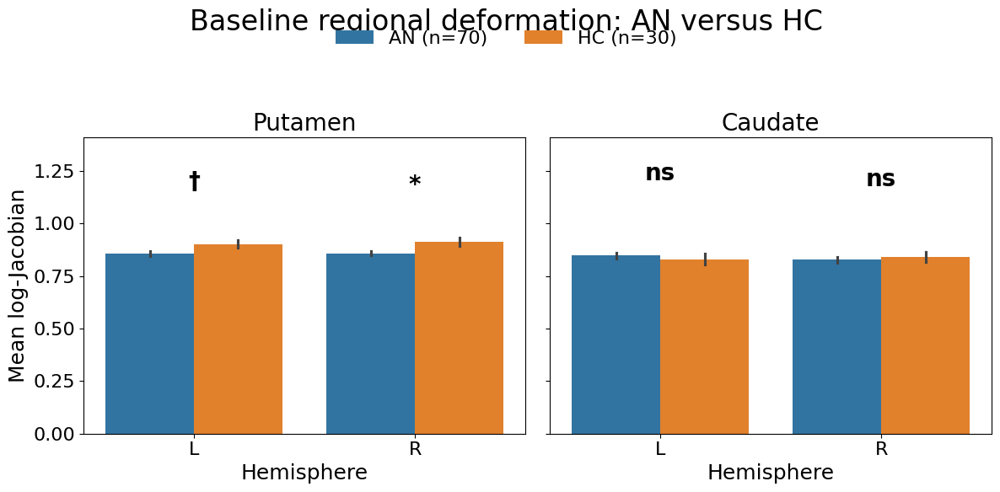

In [273]:
def p_to_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    elif p < 0.10:
        return "†"
    else:
        return "ns"
pvals = {
    ("caudate", "L"): 0.363541,
    ("caudate", "R"): 0.839542,
    ("putamen", "L"): 0.072413,
    ("putamen", "R"): 0.026267,
}

def add_sig_star(ax, sub, roi_name, hemi):
    """
    Add significance annotation above one hemisphere.

    Parameters
    ----------
    ax : matplotlib axis
    sub : dataframe for one ROI (putamen or caudate)
    roi_name : "putamen" or "caudate"
    hemi : "L" or "R"
    """

    p = pvals.get((roi_name, hemi), None)

    if p is None:
        return

    star = p_to_star(p)

    # Left = 0, Right = 1
    x = 0 if hemi == "L" else 1

    values = sub.loc[
        sub["hemisphere"] == hemi,
        "value"
    ]

    y_max = values.max()
    y_min = values.min()

    y_range = y_max - y_min

    if y_range == 0:
        y_range = abs(y_max) * 0.10

    y = y_max + 0.05 * y_range

    ax.text(
        x,
        y,
        star,
        ha="center",
        va="bottom",
        fontsize=20,
        fontweight="bold",
        color="black"
    )
# Keep baseline AN and HC
df_plot = df_analysis[
    (df_analysis["session"] == 1) &
    (df_analysis["group"].isin(["AN", "HC"])) &
    (df_analysis["roi"].isin([
        "putamen_L",
        "putamen_R",
        "caudate_L",
        "caudate_R"
    ]))
].copy()

# Exclude failed-QC subject if needed
df_plot = df_plot[df_plot["subject"] != 6].copy()

df_plot["hemisphere"] = df_plot["roi"].map({
    "putamen_L": "L",
    "putamen_R": "R",
    "caudate_L": "L",
    "caudate_R": "R",
})

df_plot["roi_base"] = df_plot["roi"].map({
    "putamen_L": "putamen",
    "putamen_R": "putamen",
    "caudate_L": "caudate",
    "caudate_R": "caudate",
})

df_plot["value"] = df_plot["mean_log_wj"]
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 6),
    sharey=True
)

for ax, roi_name in zip(
    axes,
    ["putamen", "caudate"]
):

    sub = df_plot[
        df_plot["roi_base"] == roi_name
    ].copy()

    sns.barplot(
        data=sub,
        x="hemisphere",
        y="value",
        hue="group",
        hue_order=["AN", "HC"],
        errorbar="se",
        ax=ax
    )

    add_sig_star(ax, sub, roi_name, "L")
    add_sig_star(ax, sub, roi_name, "R")

    ymin, ymax = ax.get_ylim()
    margin = (ymax - ymin) * 0.20
    ax.set_ylim(ymin, ymax + margin)

    ax.set_title(roi_name.capitalize())
    ax.set_xlabel("Hemisphere")
    ax.set_ylabel("Mean log-Jacobian")
n_an = df_plot.loc[
    df_plot["group"] == "AN",
    "subject"
].nunique()

n_hc = df_plot.loc[
    df_plot["group"] == "HC",
    "subject"
].nunique()

for ax in axes:
    legend = ax.get_legend()
    if legend is not None:
        legend.remove()

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles[:2],
    [f"AN (n={n_an})", f"HC (n={n_hc})"],
    loc="upper center",
    bbox_to_anchor=(0.5, 0.97),
    ncol=2,
    frameon=False
)

plt.suptitle(
    "Baseline regional deformation: AN versus HC"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.91]
)

plt.show()

## DBM long

In [274]:
gm_files = sorted(glob.glob( "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm/sub-*/ses-*/anat/mri/p1*.nii"))
print("N GM files:", len(gm_files))
print(gm_files[:5])
gm_mean = image.mean_img(gm_files)
gm_mask = image.math_img("img > 0.2", img=gm_mean)

N GM files: 171
['/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm/sub-01/ses-V1/anat/mri/p1sub-01_ses-V1_T1w.nii', '/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm/sub-01/ses-V2/anat/mri/p1sub-01_ses-V2_T1w.nii', '/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm/sub-02/ses-V1/anat/mri/p1sub-02_ses-V1_T1w.nii', '/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm/sub-02/ses-V2/anat/mri/p1sub-02_ses-V2_T1w.nii', '/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/segm/sub-03/ses-V1/anat/mri/p1sub-03_ses-V1_T1w.nii']


In [275]:
import os

out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"

gm_mask_path = os.path.join(out_dir, "GM_mask_group_thr02.nii.gz")
gm_mask.to_filename(gm_mask_path)

print("Saved:", gm_mask_path)

Saved: /mnt/POOL_IRM07/REMANO/DBM_analysis/GM_mask_group_thr02.nii.gz


In [279]:
delta_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_logjac"

rows = []

for f in os.listdir(delta_dir):
    if f.endswith(".nii.gz"):

        sub = f.split("_")[0].replace("sub-", "")

        rows.append({
            "subject": int(sub),
            "delta_path": os.path.join(delta_dir, f)
        })

delta_df = pd.DataFrame(rows)

print(delta_df.head())

   subject                                         delta_path
0        6  /mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...
1       92  /mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...
2       28  /mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...
3       10  /mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...
4       84  /mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...


In [289]:
df_age = redcap_data_filtered[["subject", "age",'group']].copy()

# remove rows with missing subject
df_age = df_age[df_age["subject"].notna()].copy()

# ensure integer type
df_age["subject"] = df_age["subject"].astype(int)

# remove duplicates
df_age = df_age.drop_duplicates(subset=["subject"])
df_tiv = df_tiv_long[["subject", "session", "TIV_ml"]].copy()

# make sure subject is int
df_tiv["subject"] = df_tiv["subject"].astype(int)

# average across sessions (safe choice)
df_tiv = df_tiv.groupby("subject", as_index=False)["TIV_ml"].mean()

delta_df["subject"] = delta_df["subject"].astype(int)
delta_df = delta_df.drop(
    columns=["age", "age_x", "age_y", "TIV_ml", "TIV_ml_x", "TIV_ml_y", "group"],
    errors="ignore"
)

delta_df["subject"] = delta_df["subject"].astype(int)


delta_df = delta_df.merge(df_age, on="subject", how="inner")
delta_df = delta_df.merge(df_tiv, on="subject", how="inner")
delta_df

,subject,delta_path,age,group,TIV_ml
0,6,/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...,34.0,AN,1377.130611
1,92,/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...,45.0,AN,1228.869130
2,28,/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...,50.0,AN,1488.491363
3,10,/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...,25.0,AN,1555.699220
4,84,/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...,29.0,HC,1308.481062
...,...,...,...,...,...
64,82,/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...,55.0,AN,1475.542365
65,2,/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...,47.0,HC,1146.802365
66,53,/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...,20.0,AN,1322.189447
67,23,/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_...,19.0,AN,1498.552123


Saved AN-only clean delta dataframe:
/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_dataset_AN_only_clean_exclude_sub06_age_TIV.csv
N AN subjects: 40
   subject group   age       TIV_ml
0       92    AN  45.0  1228.869130
1       28    AN  50.0  1488.491363
2       10    AN  25.0  1555.699220
3       24    AN  19.0  1493.004075
4       21    AN  43.0  1490.707554


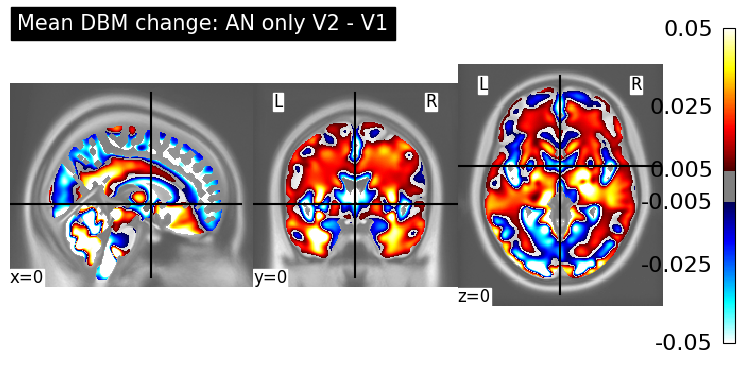

Design matrix:
   intercept  age_c       TIV_c
0        1.0   16.4 -161.679291
1        1.0   21.4   97.942941
2        1.0   -3.6  165.150798
3        1.0   -9.6  102.455653
4        1.0   14.4  100.159132


/tmp/ipykernel_185855/1854821389.py:111: UserWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  model_an = model_an.fit(


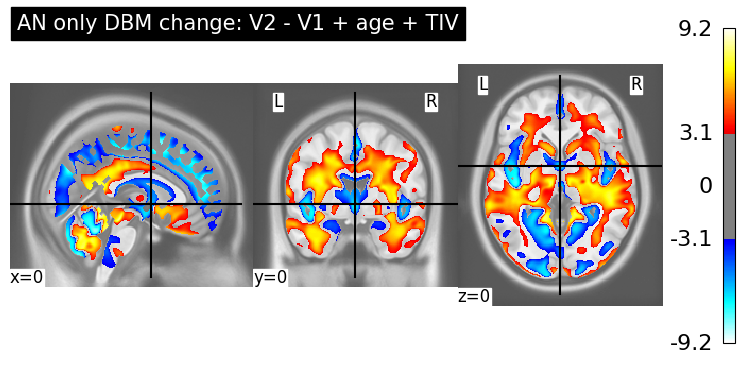

AN-only cluster table saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/clusters_AN_only_DBM_change_age_TIV_clean_exclude_sub06_brainmask.csv


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)
0,1,-10.0,-53.0,6.0,9.168387,595314
1,1a,4.0,-41.0,-23.0,8.450977,
2,1b,-36.0,-54.0,-38.0,8.390932,
3,1c,-2.0,-47.0,-11.0,8.360693,
4,2,-46.0,-72.0,-49.0,6.234072,1150
...,...,...,...,...,...,...
66,49,18.0,-59.0,63.0,-4.694418,378
67,49a,13.0,-52.0,70.0,-3.371121,
68,50,-13.0,-69.0,13.0,-4.514387,285
69,51,-58.0,-56.0,6.0,-4.066630,254


In [290]:
import os
import numpy as np
import pandas as pd

from IPython.display import display as ipy_display

from nilearn import image, plotting, masking
from nilearn.glm.second_level import SecondLevelModel
from nilearn.reporting import get_clusters_table
from nilearn.glm import threshold_stats_img

# =========================
# 0. PATHS
# =========================

out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"
os.makedirs(out_dir, exist_ok=True)

template = "/home/imabrain/Downloads/tpl-MNI152NLin2009cAsym_res-01_T1w.nii.gz"

template_img = image.load_img(template)
brain_mask = masking.compute_brain_mask(template_img)

# =========================
# 1. EXCLUDE BAD SUBJECTS + KEEP AN ONLY
# =========================

bad_subjects = [6]

delta_df_an = delta_df[
    (~delta_df["subject"].astype(int).isin(bad_subjects)) &
    (delta_df["group"] == "AN")
].copy()

delta_df_an = delta_df_an.reset_index(drop=True)

# keep only rows with age and TIV
delta_df_an = delta_df_an.dropna(
    subset=["age", "TIV_ml", "delta_path"]
).copy()

# center covariates
delta_df_an["age_c"] = delta_df_an["age"] - delta_df_an["age"].mean()
delta_df_an["TIV_c"] = delta_df_an["TIV_ml"] - delta_df_an["TIV_ml"].mean()

delta_csv = os.path.join(
    out_dir,
    "dbm_delta_dataset_AN_only_clean_exclude_sub06_age_TIV.csv"
)

delta_df_an.to_csv(delta_csv, index=False)

print("Saved AN-only clean delta dataframe:")
print(delta_csv)
print("N AN subjects:", len(delta_df_an))
print(delta_df_an[["subject", "group", "age", "TIV_ml"]].head())

delta_imgs_an = list(delta_df_an["delta_path"])

# =========================
# 2. MEAN DBM AN ONLY
# =========================

mean_an = image.mean_img(delta_imgs_an)

mean_an_masked = image.math_img(
    "np.where(mask, img, 0)",
    img=mean_an,
    mask=brain_mask
)

mean_an_path = os.path.join(
    out_dir,
    "mean_delta_logjac_AN_only_clean_exclude_sub06_brainmask.nii.gz"
)

mean_an_masked.to_filename(mean_an_path)

disp = plotting.plot_stat_map(
    mean_an_masked,
    bg_img=template,
    title="Mean DBM change: AN only V2 - V1",
    threshold=0.005,
    vmax=0.05,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

# =========================
# 3. AN ONLY ONE-SAMPLE TEST + AGE + TIV
# =========================

design_an = pd.DataFrame({
    "intercept": np.ones(len(delta_df_an)),
    "age_c": delta_df_an["age_c"].values,
    "TIV_c": delta_df_an["TIV_c"].values
})

print("Design matrix:")
print(design_an.head())

model_an = SecondLevelModel(
    mask_img=brain_mask,
    smoothing_fwhm=None
)

model_an = model_an.fit(
    delta_imgs_an,
    design_matrix=design_an
)

z_map_an = model_an.compute_contrast(
    "intercept",
    output_type="z_score"
)

z_map_an_masked = image.math_img(
    "np.where(mask, img, 0)",
    img=z_map_an,
    mask=brain_mask
)

z_an_path = os.path.join(
    out_dir,
    "zmap_AN_only_DBM_change_age_TIV_clean_exclude_sub06_brainmask.nii.gz"
)

z_map_an_masked.to_filename(z_an_path)

disp = plotting.plot_stat_map(
    z_map_an_masked,
    bg_img=template,
    title="AN only DBM change: V2 - V1 + age + TIV",
    threshold=3.1,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

clusters_an = get_clusters_table(
    z_map_an_masked,
    stat_threshold=3.1,
    cluster_threshold=100,
    two_sided=True
)

clusters_an_path = os.path.join(
    out_dir,
    "clusters_AN_only_DBM_change_age_TIV_clean_exclude_sub06_brainmask.csv"
)

clusters_an.to_csv(clusters_an_path, index=False)

print("AN-only cluster table saved:")
print(clusters_an_path)

ipy_display(clusters_an)

Saved AN-only clean delta dataframe:
/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_dataset_AN_only_clean_exclude_sub06_age_TIV.csv
N AN subjects: 40
   subject group   age       TIV_ml
0       92    AN  45.0  1228.869130
1       28    AN  50.0  1488.491363
2       10    AN  25.0  1555.699220
3       24    AN  19.0  1493.004075
4       21    AN  43.0  1490.707554


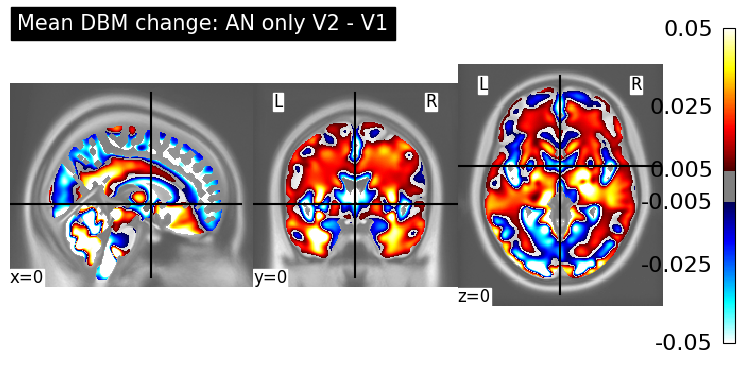

Design matrix:
   intercept  age_c       TIV_c
0        1.0   16.4 -161.679291
1        1.0   21.4   97.942941
2        1.0   -3.6  165.150798
3        1.0   -9.6  102.455653
4        1.0   14.4  100.159132


/tmp/ipykernel_185855/940536226.py:114: UserWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  model_an = model_an.fit(


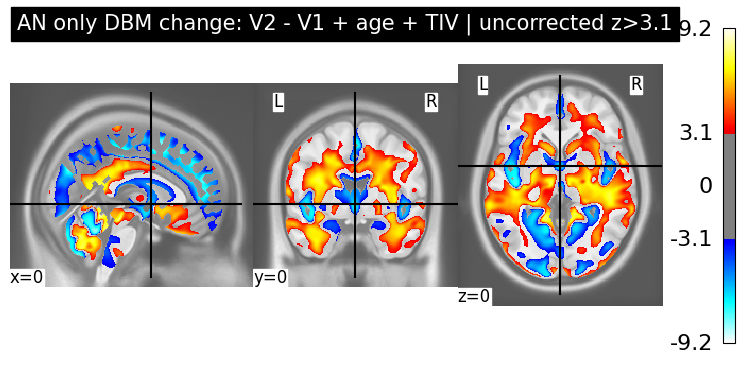

AN-only uncorrected cluster table saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/clusters_AN_only_DBM_change_age_TIV_uncorrected_z31_exclude_sub06_brainmask.csv


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)
0,1,-10.0,-53.0,6.0,9.168387,595314
1,1a,4.0,-41.0,-23.0,8.450977,
2,1b,-36.0,-54.0,-38.0,8.390932,
3,1c,-2.0,-47.0,-11.0,8.360693,
4,2,-46.0,-72.0,-49.0,6.234072,1150
...,...,...,...,...,...,...
66,49,18.0,-59.0,63.0,-4.694418,378
67,49a,13.0,-52.0,70.0,-3.371121,
68,50,-13.0,-69.0,13.0,-4.514387,285
69,51,-58.0,-56.0,6.0,-4.066630,254


FDR threshold: 2.155358359485445


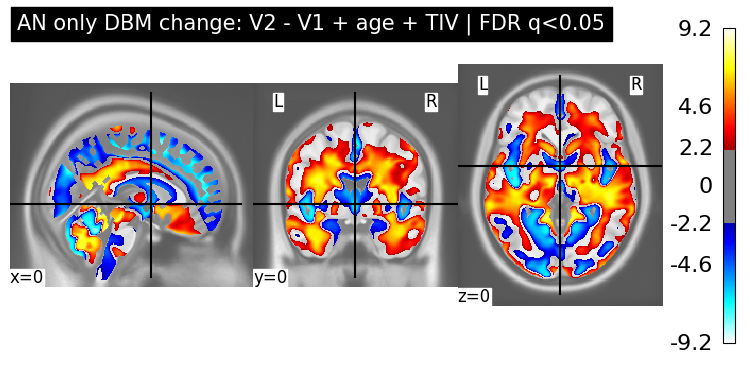

AN-only FDR cluster table saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/clusters_AN_only_DBM_change_age_TIV_FDR005_exclude_sub06_brainmask.csv


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)
0,1,-10.0,-53.0,6.0,9.168387,747573
1,1a,4.0,-41.0,-23.0,8.450977,
2,1b,-36.0,-54.0,-38.0,8.390932,
3,1c,-2.0,-47.0,-11.0,8.360693,
4,2,-46.0,-72.0,-49.0,6.234072,1563
5,2a,-34.0,-83.0,-47.0,5.623836,
6,3,31.0,-84.0,-48.0,5.962289,2314
7,3a,40.0,-77.0,-51.0,5.755731,
8,3b,27.0,-90.0,-38.0,4.830348,
9,3c,36.0,-87.0,-32.0,4.240808,


In [291]:
import os
import numpy as np
import pandas as pd

from IPython.display import display as ipy_display

from nilearn import image, plotting, masking
from nilearn.glm.second_level import SecondLevelModel
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table

# =========================
# 0. PATHS
# =========================

out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"
os.makedirs(out_dir, exist_ok=True)

template = "/home/imabrain/Downloads/tpl-MNI152NLin2009cAsym_res-01_T1w.nii.gz"

template_img = image.load_img(template)
brain_mask = masking.compute_brain_mask(template_img)

# =========================
# 1. EXCLUDE BAD SUBJECTS + KEEP AN ONLY
# =========================

bad_subjects = [6]

delta_df_an = delta_df[
    (~delta_df["subject"].astype(int).isin(bad_subjects)) &
    (delta_df["group"] == "AN")
].copy()

delta_df_an = delta_df_an.reset_index(drop=True)

# keep only rows with age and TIV
delta_df_an = delta_df_an.dropna(
    subset=["age", "TIV_ml", "delta_path"]
).copy()

# center covariates
delta_df_an["age_c"] = delta_df_an["age"] - delta_df_an["age"].mean()
delta_df_an["TIV_c"] = delta_df_an["TIV_ml"] - delta_df_an["TIV_ml"].mean()

delta_csv = os.path.join(
    out_dir,
    "dbm_delta_dataset_AN_only_clean_exclude_sub06_age_TIV.csv"
)

delta_df_an.to_csv(delta_csv, index=False)

print("Saved AN-only clean delta dataframe:")
print(delta_csv)
print("N AN subjects:", len(delta_df_an))
print(delta_df_an[["subject", "group", "age", "TIV_ml"]].head())

delta_imgs_an = list(delta_df_an["delta_path"])

if len(delta_imgs_an) < 5:
    raise ValueError("Too few AN subjects after filtering.")

# =========================
# 2. MEAN DBM AN ONLY
# =========================

mean_an = image.mean_img(delta_imgs_an)

mean_an_masked = image.math_img(
    "np.where(mask, img, 0)",
    img=mean_an,
    mask=brain_mask
)

mean_an_path = os.path.join(
    out_dir,
    "mean_delta_logjac_AN_only_clean_exclude_sub06_brainmask.nii.gz"
)

mean_an_masked.to_filename(mean_an_path)

disp = plotting.plot_stat_map(
    mean_an_masked,
    bg_img=template,
    title="Mean DBM change: AN only V2 - V1",
    threshold=0.005,
    vmax=0.05,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

# =========================
# 3. AN ONLY ONE-SAMPLE TEST + AGE + TIV
# =========================

design_an = pd.DataFrame({
    "intercept": np.ones(len(delta_df_an)),
    "age_c": delta_df_an["age_c"].values,
    "TIV_c": delta_df_an["TIV_c"].values
})

print("Design matrix:")
print(design_an.head())

model_an = SecondLevelModel(
    mask_img=brain_mask,
    smoothing_fwhm=None
)

model_an = model_an.fit(
    delta_imgs_an,
    design_matrix=design_an
)

z_map_an = model_an.compute_contrast(
    "intercept",
    output_type="z_score"
)

z_map_an_masked = image.math_img(
    "np.where(mask, img, 0)",
    img=z_map_an,
    mask=brain_mask
)

z_an_unc_path = os.path.join(
    out_dir,
    "zmap_AN_only_DBM_change_age_TIV_uncorrected_exclude_sub06_brainmask.nii.gz"
)

z_map_an_masked.to_filename(z_an_unc_path)

# =========================
# 4. PLOT UNCORRECTED MAP
# =========================

disp = plotting.plot_stat_map(
    z_map_an_masked,
    bg_img=template,
    title="AN only DBM change: V2 - V1 + age + TIV | uncorrected z>3.1",
    threshold=3.1,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

clusters_an_unc = get_clusters_table(
    z_map_an_masked,
    stat_threshold=3.1,
    cluster_threshold=100,
    two_sided=True
)

clusters_an_unc_path = os.path.join(
    out_dir,
    "clusters_AN_only_DBM_change_age_TIV_uncorrected_z31_exclude_sub06_brainmask.csv"
)

clusters_an_unc.to_csv(clusters_an_unc_path, index=False)

print("AN-only uncorrected cluster table saved:")
print(clusters_an_unc_path)

ipy_display(clusters_an_unc)

# =========================
# 5. FDR CORRECTION
# =========================

z_map_an_fdr, threshold_fdr = threshold_stats_img(
    z_map_an_masked,
    alpha=0.05,
    height_control="fdr",
    two_sided=True
)

print("FDR threshold:", threshold_fdr)

z_an_fdr_path = os.path.join(
    out_dir,
    "zmap_AN_only_DBM_change_age_TIV_FDR005_exclude_sub06_brainmask.nii.gz"
)

z_map_an_fdr.to_filename(z_an_fdr_path)

# =========================
# 6. PLOT FDR MAP
# =========================

disp = plotting.plot_stat_map(
    z_map_an_fdr,
    bg_img=template,
    title="AN only DBM change: V2 - V1 + age + TIV | FDR q<0.05",
    threshold=threshold_fdr,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

# =========================
# 7. CLUSTER TABLE FDR
# =========================

clusters_an_fdr = get_clusters_table(
    z_map_an_fdr,
    stat_threshold=threshold_fdr,
    cluster_threshold=100,
    two_sided=True
)

clusters_an_fdr_path = os.path.join(
    out_dir,
    "clusters_AN_only_DBM_change_age_TIV_FDR005_exclude_sub06_brainmask.csv"
)

clusters_an_fdr.to_csv(clusters_an_fdr_path, index=False)

print("AN-only FDR cluster table saved:")
print(clusters_an_fdr_path)

ipy_display(clusters_an_fdr)

In [292]:

z_data = z_map_an_masked.get_fdata()
fdr_data = z_map_an_fdr.get_fdata()

print("Uncorrected |z| > 3.1:", np.sum(np.abs(z_data) > 3.1))
print("FDR non-zero voxels:", np.sum(fdr_data != 0))
print("FDR |z| > threshold:", np.sum(np.abs(z_data) > threshold_fdr))

Uncorrected |z| > 3.1: 844168
FDR non-zero voxels: 1087149
FDR |z| > threshold: 1087149


In [293]:
import os
import numpy as np
import pandas as pd

from nilearn import image
from nilearn.image import math_img, resample_to_img

roi_dir = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI"
out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"

z_map_path = os.path.join(
    out_dir,
    "zmap_AN_only_DBM_change_age_TIV_FDR005_exclude_sub06_brainmask.nii.gz"
)

z_map = image.load_img(z_map_path)

threshold = 3.1  # stricter than 2.3

selected_rois = [
    "caudate_L_bin.nii", "caudate_R_bin.nii",
    "putamen_L_bin.nii", "putamen_R_bin.nii",
    "NACC_L_bin.nii", "NACC_R_bin.nii",
    "ACC_rostral_bin.nii",
    "OFC_lateral_bin.nii", "OFC_medial_bin.nii",
    "PFC_union_bin.nii",
    "Insular_Cortex_bin.nii",

    "putamen_R_svd_eqvox_slice01_most_posterior.nii",

    "putamen_R_svd_eqvox_slice07_most_anterior.nii",

    "putamen_L_svd_eqvox_slice01_most_posterior.nii",

    "putamen_L_svd_eqvox_slice07_most_anterior.nii",

    "caudate_R_svd_eqvox_slice01_most_posterior.nii",

    "caudate_R_svd_eqvox_slice07_most_anterior.nii",

    "caudate_L_svd_eqvox_slice01_most_posterior.nii",

    "caudate_L_svd_eqvox_slice07_most_anterior.nii",
]

roi_files = []

missing_rois = []

for roi in selected_rois:
    p = os.path.join(roi_dir, roi)
    if os.path.exists(p):
        roi_files.append(p)
    else:
        missing_rois.append(roi)

print("Found ROIs:", len(roi_files))
print("Missing ROIs:", missing_rois)

# positive = AN V2 > V1
# negative = AN V2 < V1
threshold = 2.15

mask_pos = math_img(f"img > {threshold}", img=z_map)
mask_neg = math_img(f"img < {-threshold}", img=z_map)
mask_pos_data = mask_pos.get_fdata() > 0
mask_neg_data = mask_neg.get_fdata() > 0

n_pos_cluster = int(np.sum(mask_pos_data))
n_neg_cluster = int(np.sum(mask_neg_data))

print("Positive suprathreshold voxels:", n_pos_cluster)
print("Negative suprathreshold voxels:", n_neg_cluster)

results = []

for roi_path in roi_files:

    roi_name = os.path.basename(roi_path)

    roi_img = image.load_img(roi_path)

    roi_resampled = resample_to_img(
        roi_img,
        z_map,
        interpolation="nearest",
        force_resample=True,
        copy_header=True
    )

    roi_data = roi_resampled.get_fdata() > 0
    n_roi = int(np.sum(roi_data))

    if n_roi == 0:
        print("Empty after resampling:", roi_name)
        continue

    overlap_pos = np.logical_and(mask_pos_data, roi_data)
    overlap_neg = np.logical_and(mask_neg_data, roi_data)

    n_overlap_pos = int(np.sum(overlap_pos))
    n_overlap_neg = int(np.sum(overlap_neg))

    results.append({
        "roi": roi_name,
        "roi_size_voxels": n_roi,

        "AN_V2_gt_V1_voxels": n_overlap_pos,
        "AN_V2_gt_V1_percent_roi": 100 * n_overlap_pos / n_roi,
        "AN_V2_gt_V1_percent_cluster": 100 * n_overlap_pos / n_pos_cluster if n_pos_cluster > 0 else 0,

        "AN_V2_lt_V1_voxels": n_overlap_neg,
        "AN_V2_lt_V1_percent_roi": 100 * n_overlap_neg / n_roi,
        "AN_V2_lt_V1_percent_cluster": 100 * n_overlap_neg / n_neg_cluster if n_neg_cluster > 0 else 0,
    })

df_overlap_AN = pd.DataFrame(results)

df_overlap_AN = df_overlap_AN[
    (df_overlap_AN["AN_V2_gt_V1_voxels"] > 0) |
    (df_overlap_AN["AN_V2_lt_V1_voxels"] > 0)
].copy()

df_overlap_AN = df_overlap_AN.sort_values(
    ["AN_V2_gt_V1_percent_roi", "AN_V2_lt_V1_percent_roi"],
    ascending=False
).reset_index(drop=True)

out_csv = os.path.join(
    out_dir,
    f"ROI_cluster_overlap_selected_ROIs_AN_only_DBM_z{threshold}_age_TIV_exclude_sub06.csv"
)

df_overlap_AN.to_csv(out_csv, index=False)

print("Saved:")
print(out_csv)

df_overlap_AN

Found ROIs: 19
Missing ROIs: []
Positive suprathreshold voxels: 757466
Negative suprathreshold voxels: 329683
Saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/ROI_cluster_overlap_selected_ROIs_AN_only_DBM_z2.15_age_TIV_exclude_sub06.csv


,roi,roi_size_voxels,AN_V2_gt_V1_voxels,AN_V2_gt_V1_percent_roi,AN_V2_gt_V1_percent_cluster,AN_V2_lt_V1_voxels,AN_V2_lt_V1_percent_roi,AN_V2_lt_V1_percent_cluster
0,putamen_R_svd_eqvox_slice07_most_anterior.nii,913,907,99.342826,0.119741,0,0.000000,0.000000
1,NACC_L_bin.nii,756,751,99.338624,0.099146,0,0.000000,0.000000
2,NACC_R_bin.nii,666,661,99.249249,0.087265,0,0.000000,0.000000
3,putamen_L_svd_eqvox_slice07_most_anterior.nii,913,870,95.290252,0.114857,0,0.000000,0.000000
4,caudate_R_svd_eqvox_slice07_most_anterior.nii,589,550,93.378608,0.072611,0,0.000000,0.000000
5,putamen_R_svd_eqvox_slice01_most_posterior.nii,914,824,90.153173,0.108784,19,2.078775,0.005763
6,putamen_L_svd_eqvox_slice01_most_posterior.nii,914,786,85.995624,0.103767,38,4.157549,0.011526
7,caudate_L_svd_eqvox_slice07_most_anterior.nii,564,481,85.283688,0.063501,0,0.000000,0.000000
8,caudate_R_bin.nii,4127,2929,70.971650,0.386684,517,12.527260,0.156817
9,putamen_R_bin.nii,6397,4297,67.172112,0.567286,366,5.721432,0.111016


Saved HC-only clean delta dataframe:
/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_dataset_HC_only_age_TIV.csv
N HC subjects: 28
   subject group   age       TIV_ml
0       84    HC  29.0  1308.481062
1       44    HC  22.0  1469.826229
2       64    HC  30.0  1313.605193
3       68    HC  19.0  1382.942975
4       38    HC  27.0  1387.903402


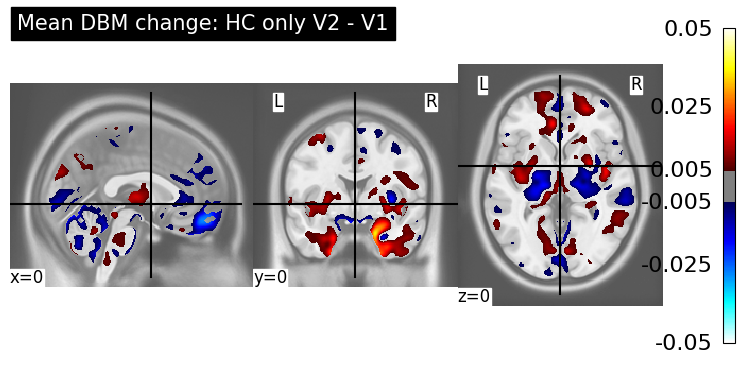

Design matrix:
   intercept     age_c       TIV_c
0        1.0  2.214286  -59.869840
1        1.0 -4.785714  101.475326
2        1.0  3.214286  -54.745709
3        1.0 -7.785714   14.592072
4        1.0  0.214286   19.552500


/tmp/ipykernel_185855/1916498822.py:111: UserWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  model_hc = model_hc.fit(


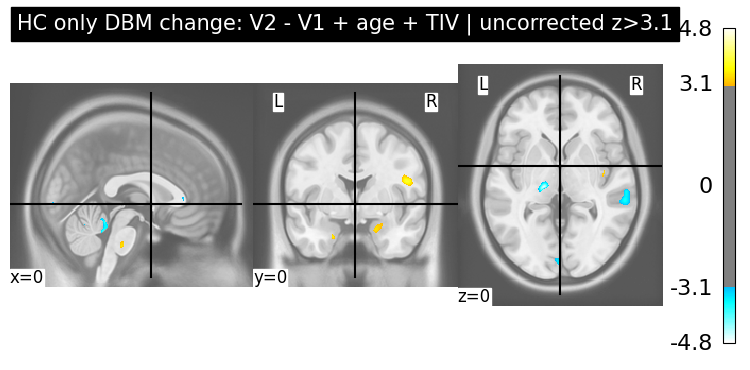

HC-only uncorrected cluster table saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/clusters_HC_only_DBM_change_age_TIV_uncorrected_z31_brainmask.csv


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)
0,1,46.0,-26.0,-19.0,4.809918,5866
1,1a,50.0,-39.0,-22.0,4.214572,
2,1b,37.0,-38.0,-6.0,4.045807,
3,1c,42.0,-41.0,-13.0,3.698571,
4,2,-21.0,11.0,-14.0,4.307521,195
5,2a,-11.0,16.0,-12.0,3.299567,
6,3,-15.0,29.0,-8.0,4.144266,618
7,4,49.0,2.0,22.0,3.995861,419
8,5,-21.0,-3.0,-31.0,3.809473,183
9,5a,-27.0,-12.0,-34.0,3.546341,


/tmp/ipykernel_185855/1916498822.py:174: UserWarning: The given float value must not exceed 4.809918145448148. But, you have given threshold=inf.
  z_map_hc_fdr, threshold_fdr = threshold_stats_img(


FDR threshold: inf


/tmp/ipykernel_185855/1916498822.py:194: UserWarning: empty mask
  disp = plotting.plot_stat_map(


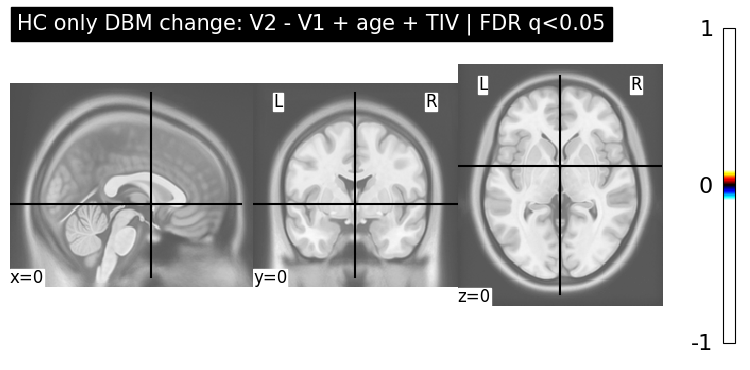

/tmp/ipykernel_185855/1916498822.py:211: UserWarning: The given float value must not exceed 0.0. But, you have given threshold=inf.
  clusters_hc_fdr = get_clusters_table(


HC-only FDR cluster table saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/clusters_HC_only_DBM_change_age_TIV_FDR005_brainmask.csv


/tmp/ipykernel_185855/1916498822.py:211: UserWarning: No clusters found with stat higher than inf
  clusters_hc_fdr = get_clusters_table(
/tmp/ipykernel_185855/1916498822.py:211: UserWarning: No clusters found with stat lower than -inf
  clusters_hc_fdr = get_clusters_table(


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)


In [294]:
import os
import numpy as np
import pandas as pd

from IPython.display import display as ipy_display

from nilearn import image, plotting, masking
from nilearn.glm.second_level import SecondLevelModel
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table

# =========================
# 0. PATHS
# =========================

out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"
os.makedirs(out_dir, exist_ok=True)

template = "/home/imabrain/Downloads/tpl-MNI152NLin2009cAsym_res-01_T1w.nii.gz"

template_img = image.load_img(template)
brain_mask = masking.compute_brain_mask(template_img)

# =========================
# 1. KEEP HC ONLY
# =========================

delta_df_hc = delta_df[
    delta_df["group"] == "HC"
].copy()

delta_df_hc = delta_df_hc.reset_index(drop=True)

# keep only rows with age and TIV
delta_df_hc = delta_df_hc.dropna(
    subset=["age", "TIV_ml", "delta_path"]
).copy()

# center covariates
delta_df_hc["age_c"] = delta_df_hc["age"] - delta_df_hc["age"].mean()
delta_df_hc["TIV_c"] = delta_df_hc["TIV_ml"] - delta_df_hc["TIV_ml"].mean()

delta_csv = os.path.join(
    out_dir,
    "dbm_delta_dataset_HC_only_age_TIV.csv"
)

delta_df_hc.to_csv(delta_csv, index=False)

print("Saved HC-only clean delta dataframe:")
print(delta_csv)
print("N HC subjects:", len(delta_df_hc))
print(delta_df_hc[["subject", "group", "age", "TIV_ml"]].head())

delta_imgs_hc = list(delta_df_hc["delta_path"])

if len(delta_imgs_hc) < 5:
    raise ValueError("Too few HC subjects after filtering.")

# =========================
# 2. MEAN DBM HC ONLY
# =========================

mean_hc = image.mean_img(delta_imgs_hc)

mean_hc_masked = image.math_img(
    "np.where(mask, img, 0)",
    img=mean_hc,
    mask=brain_mask
)

mean_hc_path = os.path.join(
    out_dir,
    "mean_delta_logjac_HC_only_brainmask.nii.gz"
)

mean_hc_masked.to_filename(mean_hc_path)

disp = plotting.plot_stat_map(
    mean_hc_masked,
    bg_img=template,
    title="Mean DBM change: HC only V2 - V1",
    threshold=0.005,
    vmax=0.05,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

# =========================
# 3. HC ONLY ONE-SAMPLE TEST + AGE + TIV
# =========================

design_hc = pd.DataFrame({
    "intercept": np.ones(len(delta_df_hc)),
    "age_c": delta_df_hc["age_c"].values,
    "TIV_c": delta_df_hc["TIV_c"].values
})

print("Design matrix:")
print(design_hc.head())

model_hc = SecondLevelModel(
    mask_img=brain_mask,
    smoothing_fwhm=None
)

model_hc = model_hc.fit(
    delta_imgs_hc,
    design_matrix=design_hc
)

z_map_hc = model_hc.compute_contrast(
    "intercept",
    output_type="z_score"
)

z_map_hc_masked = image.math_img(
    "np.where(mask, img, 0)",
    img=z_map_hc,
    mask=brain_mask
)

z_hc_unc_path = os.path.join(
    out_dir,
    "zmap_HC_only_DBM_change_age_TIV_uncorrected_brainmask.nii.gz"
)

z_map_hc_masked.to_filename(z_hc_unc_path)

# =========================
# 4. PLOT UNCORRECTED MAP
# =========================

disp = plotting.plot_stat_map(
    z_map_hc_masked,
    bg_img=template,
    title="HC only DBM change: V2 - V1 + age + TIV | uncorrected z>3.1",
    threshold=3.1,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

clusters_hc_unc = get_clusters_table(
    z_map_hc_masked,
    stat_threshold=3.1,
    cluster_threshold=100,
    two_sided=True
)

clusters_hc_unc_path = os.path.join(
    out_dir,
    "clusters_HC_only_DBM_change_age_TIV_uncorrected_z31_brainmask.csv"
)

clusters_hc_unc.to_csv(clusters_hc_unc_path, index=False)

print("HC-only uncorrected cluster table saved:")
print(clusters_hc_unc_path)

ipy_display(clusters_hc_unc)

# =========================
# 5. FDR CORRECTION
# =========================

z_map_hc_fdr, threshold_fdr = threshold_stats_img(
    z_map_hc_masked,
    alpha=0.05,
    height_control="fdr",
    two_sided=True
)

print("FDR threshold:", threshold_fdr)

z_hc_fdr_path = os.path.join(
    out_dir,
    "zmap_HC_only_DBM_change_age_TIV_FDR005_brainmask.nii.gz"
)

z_map_hc_fdr.to_filename(z_hc_fdr_path)

# =========================
# 6. PLOT FDR MAP
# =========================

disp = plotting.plot_stat_map(
    z_map_hc_fdr,
    bg_img=template,
    title="HC only DBM change: V2 - V1 + age + TIV | FDR q<0.05",
    threshold=threshold_fdr,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

# =========================
# 7. CLUSTER TABLE FDR
# =========================

clusters_hc_fdr = get_clusters_table(
    z_map_hc_fdr,
    stat_threshold=threshold_fdr,
    cluster_threshold=100,
    two_sided=True
)

clusters_hc_fdr_path = os.path.join(
    out_dir,
    "clusters_HC_only_DBM_change_age_TIV_FDR005_brainmask.csv"
)

clusters_hc_fdr.to_csv(clusters_hc_fdr_path, index=False)

print("HC-only FDR cluster table saved:")
print(clusters_hc_fdr_path)

ipy_display(clusters_hc_fdr)

Saved AN vs HC longitudinal dataframe:
/mnt/POOL_IRM07/REMANO/DBM_analysis/dbm_delta_dataset_AN_vs_HC_longitudinal_age_TIV_exclude_sub06.csv
N subjects: 68
group
AN    40
HC    28
Name: count, dtype: int64
   subject group   age       TIV_ml
0       92    AN  45.0  1228.869130
1       28    AN  50.0  1488.491363
2       10    AN  25.0  1555.699220
3       84    HC  29.0  1308.481062
4       24    AN  19.0  1493.004075


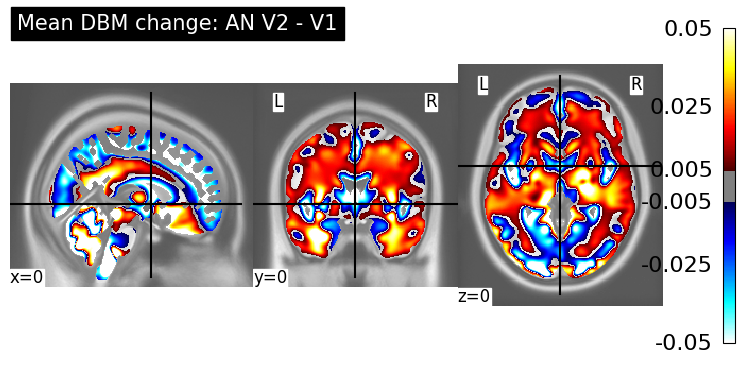

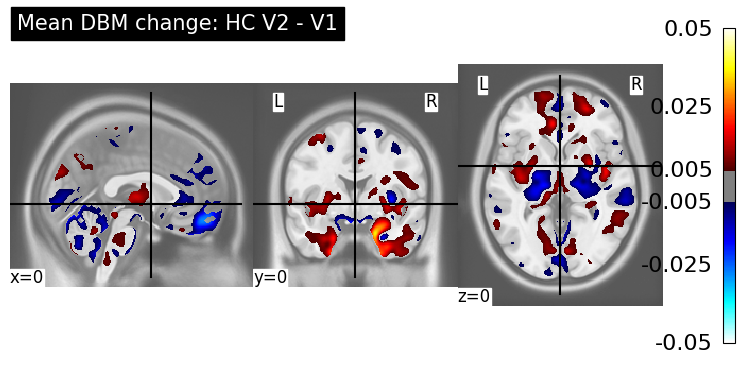

Design matrix:
   intercept  group_AN      age_c       TIV_c
0        1.0         1  17.147059 -152.539136
1        1.0         1  22.147059  107.083096
2        1.0         1  -2.852941  174.290953
3        1.0         0   1.147059  -72.927205
4        1.0         1  -8.852941  111.595808


/tmp/ipykernel_185855/469233882.py:133: UserWarning: [NiftiMasker.fit] Generation of a mask has been requested (imgs != None) while a mask was given at masker creation. Given mask will be used.
  model_group = model_group.fit(


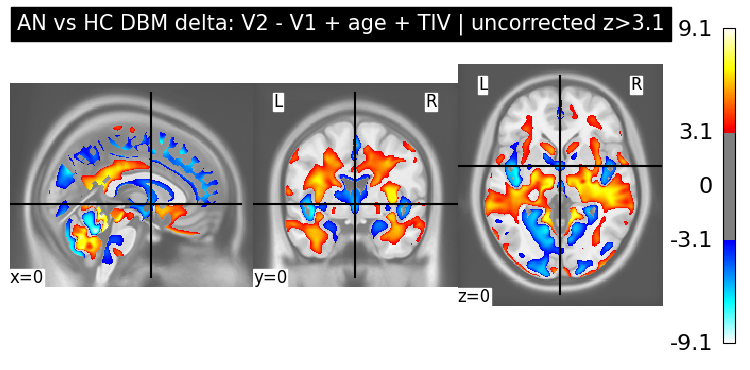

AN vs HC uncorrected cluster table saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/clusters_AN_vs_HC_DBM_delta_longitudinal_age_TIV_uncorrected_z31_exclude_sub06_brainmask.csv


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)
0,1,4.0,-41.0,-23.0,9.078147,445057
1,1a,-11.0,-54.0,6.0,8.899878,
2,1b,1.0,-47.0,-11.0,8.832557,
3,1c,22.0,-61.0,-43.0,8.806261,
4,2,37.0,-95.0,-7.0,7.076443,5786
...,...,...,...,...,...,...
96,68,-18.0,-64.0,63.0,-4.209819,362
97,69,65.0,-23.0,17.0,-4.004126,157
98,70,40.0,-44.0,44.0,-3.934142,224
99,70a,43.0,-48.0,52.0,-3.819801,


FDR threshold: 2.221596358849304


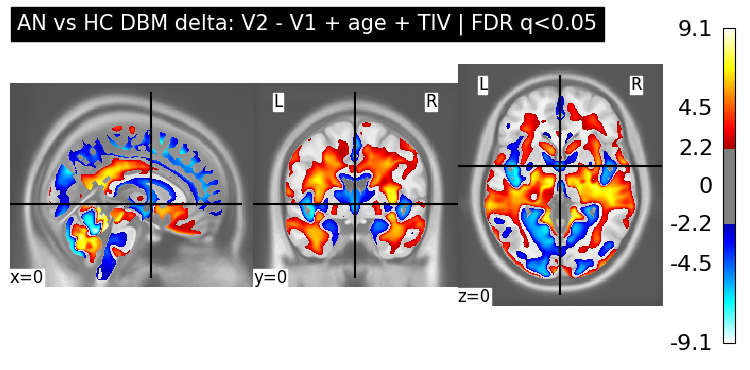

AN vs HC FDR cluster table saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/clusters_AN_vs_HC_DBM_delta_longitudinal_age_TIV_FDR005_exclude_sub06_brainmask.csv


,Cluster ID,X,Y,Z,Peak Stat,Cluster Size (mm3)
0,1,4.0,-41.0,-23.0,9.078147,620334
1,1a,-11.0,-54.0,6.0,8.899878,
2,1b,1.0,-47.0,-11.0,8.832557,
3,1c,22.0,-61.0,-43.0,8.806261,
4,2,-45.0,-74.0,-48.0,5.669979,1018
5,2a,-34.0,-83.0,-47.0,4.799040,
6,3,32.0,-84.0,-47.0,5.642577,1379
7,3a,27.0,-90.0,-38.0,4.058901,
8,3b,35.0,-88.0,-31.0,3.995669,
9,3c,25.0,-91.0,-36.0,3.974699,


In [295]:
import os
import numpy as np
import pandas as pd

from IPython.display import display as ipy_display

from nilearn import image, plotting, masking
from nilearn.glm.second_level import SecondLevelModel
from nilearn.glm import threshold_stats_img
from nilearn.reporting import get_clusters_table

# =========================
# 0. PATHS
# =========================

out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"
os.makedirs(out_dir, exist_ok=True)

template = "/home/imabrain/Downloads/tpl-MNI152NLin2009cAsym_res-01_T1w.nii.gz"

template_img = image.load_img(template)
brain_mask = masking.compute_brain_mask(template_img)

# =========================
# 1. CLEAN DATASET: AN + HC
# =========================

bad_subjects = [6]

delta_df_group = delta_df[
    (~delta_df["subject"].astype(int).isin(bad_subjects)) &
    (delta_df["group"].isin(["AN", "HC"]))
].copy()

delta_df_group = delta_df_group.reset_index(drop=True)

delta_df_group = delta_df_group.dropna(
    subset=["age", "TIV_ml", "delta_path", "group"]
).copy()

delta_df_group["group_AN"] = (
    delta_df_group["group"] == "AN"
).astype(int)

# center covariates across all included subjects
delta_df_group["age_c"] = (
    delta_df_group["age"] - delta_df_group["age"].mean()
)

delta_df_group["TIV_c"] = (
    delta_df_group["TIV_ml"] - delta_df_group["TIV_ml"].mean()
)

delta_csv = os.path.join(
    out_dir,
    "dbm_delta_dataset_AN_vs_HC_longitudinal_age_TIV_exclude_sub06.csv"
)

delta_df_group.to_csv(delta_csv, index=False)

print("Saved AN vs HC longitudinal dataframe:")
print(delta_csv)
print("N subjects:", len(delta_df_group))
print(delta_df_group["group"].value_counts())
print(delta_df_group[["subject", "group", "age", "TIV_ml"]].head())

delta_imgs_group = list(delta_df_group["delta_path"])

if len(delta_imgs_group) < 10:
    raise ValueError("Too few subjects after filtering.")

# =========================
# 2. MEAN DBM BY GROUP
# =========================

for group_name in ["AN", "HC"]:

    group_imgs = list(
        delta_df_group.loc[
            delta_df_group["group"] == group_name,
            "delta_path"
        ]
    )

    mean_group = image.mean_img(group_imgs)

    mean_group_masked = image.math_img(
        "np.where(mask, img, 0)",
        img=mean_group,
        mask=brain_mask
    )

    mean_group_path = os.path.join(
        out_dir,
        f"mean_delta_logjac_{group_name}_ANvsHC_dataset_brainmask.nii.gz"
    )

    mean_group_masked.to_filename(mean_group_path)

    disp = plotting.plot_stat_map(
        mean_group_masked,
        bg_img=template,
        title=f"Mean DBM change: {group_name} V2 - V1",
        threshold=0.005,
        vmax=0.05,
        display_mode="ortho",
        cut_coords=(0, 0, 0),
        cmap="cold_hot",
        black_bg=False
    )

    plotting.show()

# =========================
# 3. AN VS HC LONGITUDINAL MODEL + AGE + TIV
# =========================

design_group = pd.DataFrame({
    "intercept": np.ones(len(delta_df_group)),
    "group_AN": delta_df_group["group_AN"].values,
    "age_c": delta_df_group["age_c"].values,
    "TIV_c": delta_df_group["TIV_c"].values
})

print("Design matrix:")
print(design_group.head())

model_group = SecondLevelModel(
    mask_img=brain_mask,
    smoothing_fwhm=None
)

model_group = model_group.fit(
    delta_imgs_group,
    design_matrix=design_group
)

# group_AN contrast = AN > HC in V2-V1 DBM change
z_map_group = model_group.compute_contrast(
    "group_AN",
    output_type="z_score"
)

z_map_group_masked = image.math_img(
    "np.where(mask, img, 0)",
    img=z_map_group,
    mask=brain_mask
)

z_group_unc_path = os.path.join(
    out_dir,
    "zmap_AN_vs_HC_DBM_delta_longitudinal_age_TIV_uncorrected_exclude_sub06_brainmask.nii.gz"
)

z_map_group_masked.to_filename(z_group_unc_path)

# =========================
# 4. PLOT UNCORRECTED MAP
# =========================

disp = plotting.plot_stat_map(
    z_map_group_masked,
    bg_img=template,
    title="AN vs HC DBM delta: V2 - V1 + age + TIV | uncorrected z>3.1",
    threshold=3.1,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

clusters_group_unc = get_clusters_table(
    z_map_group_masked,
    stat_threshold=3.1,
    cluster_threshold=100,
    two_sided=True
)

clusters_group_unc_path = os.path.join(
    out_dir,
    "clusters_AN_vs_HC_DBM_delta_longitudinal_age_TIV_uncorrected_z31_exclude_sub06_brainmask.csv"
)

clusters_group_unc.to_csv(clusters_group_unc_path, index=False)

print("AN vs HC uncorrected cluster table saved:")
print(clusters_group_unc_path)

ipy_display(clusters_group_unc)

# =========================
# 5. FDR CORRECTION
# =========================

z_map_group_fdr, threshold_fdr = threshold_stats_img(
    z_map_group_masked,
    alpha=0.05,
    height_control="fdr",
    two_sided=True
)

print("FDR threshold:", threshold_fdr)

z_group_fdr_path = os.path.join(
    out_dir,
    "zmap_AN_vs_HC_DBM_delta_longitudinal_age_TIV_FDR005_exclude_sub06_brainmask.nii.gz"
)

z_map_group_fdr.to_filename(z_group_fdr_path)

# =========================
# 6. PLOT FDR MAP
# =========================

disp = plotting.plot_stat_map(
    z_map_group_fdr,
    bg_img=template,
    title="AN vs HC DBM delta: V2 - V1 + age + TIV | FDR q<0.05",
    threshold=threshold_fdr,
    display_mode="ortho",
    cut_coords=(0, 0, 0),
    cmap="cold_hot",
    black_bg=False
)

plotting.show()

# =========================
# 7. CLUSTER TABLE FDR
# =========================

clusters_group_fdr = get_clusters_table(
    z_map_group_fdr,
    stat_threshold=threshold_fdr,
    cluster_threshold=100,
    two_sided=True
)

clusters_group_fdr_path = os.path.join(
    out_dir,
    "clusters_AN_vs_HC_DBM_delta_longitudinal_age_TIV_FDR005_exclude_sub06_brainmask.csv"
)

clusters_group_fdr.to_csv(clusters_group_fdr_path, index=False)

print("AN vs HC FDR cluster table saved:")
print(clusters_group_fdr_path)

ipy_display(clusters_group_fdr)

In [296]:
out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"
template = "/home/imabrain/Downloads/tpl-MNI152NLin2009cAsym_res-01_T1w.nii.gz"

# AN vs HC longitudinal FDR map
zmap_path = os.path.join(
    out_dir,
    "zmap_AN_vs_HC_DBM_delta_longitudinal_age_TIV_FDR005_exclude_sub06_brainmask.nii.gz"
)

zmap = image.load_img(zmap_path)

# choose axial slices from inferior to superior
cut_coords = [-45, -35, -25, -15, -5, 5, 15, 25, 35, 45, 55, 65]

display = plotting.plot_stat_map(
    zmap,
    bg_img=template,
    title="AN vs HC DBM change: V2 - V1 | FDR q<0.05",
    display_mode="z",
    cut_coords=cut_coords,
    threshold=0.1,   # because FDR map is already thresholded
    cmap="cold_hot",
    black_bg=True,
    annotate=True,
    draw_cross=False,
    colorbar=True
)

out_png = os.path.join(
    out_dir,
    "figure_AN_vs_HC_DBM_delta_FDR_axial_slices.png"
)

display.savefig(out_png, dpi=300)
display.close()

print("Saved:")
print(out_png)

Saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/figure_AN_vs_HC_DBM_delta_FDR_axial_slices.png


In [297]:
cut_coords = [-50, -40, -30, -20, -10, 0, 10, 20, 30, 40, 50]

display = plotting.plot_stat_map(
    zmap,
    bg_img=template,
    title="AN vs HC DBM change: V2 - V1 | FDR q<0.05",
    display_mode="x",
    cut_coords=cut_coords,
    threshold=0.1,
    cmap="cold_hot",
    black_bg=True,
    annotate=True,
    draw_cross=False,
    colorbar=True
)

out_png = os.path.join(
    out_dir,
    "figure_AN_vs_HC_DBM_delta_FDR_sagittal_slices.png"
)

display.savefig(out_png, dpi=300)
display.close()

#### NMH19

Processing: Putamen L
Processing: Putamen R
Processing: Caudate L
Processing: Caudate R


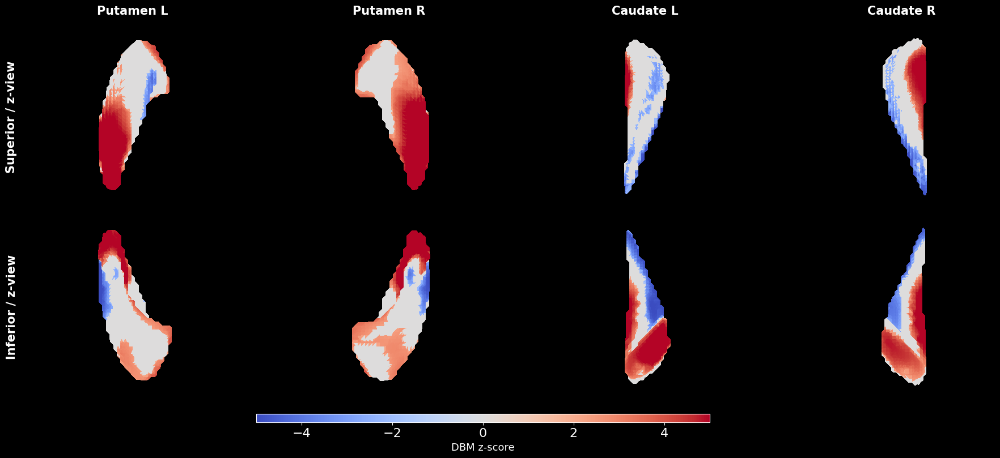

Saved: /mnt/POOL_IRM07/REMANO/DBM_analysis/DBM_putamen_caudate_SI_3D.png


In [ ]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt

from nilearn import image
from skimage import measure
from scipy.ndimage import map_coordinates
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# =====================================================
# PATHS
# =====================================================

roi_dir = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI"

out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis"
os.makedirs(out_dir, exist_ok=True)

zmap_path = os.path.join(
    out_dir,
    "zmap_AN_vs_HC_DBM_delta_longitudinal_age_TIV_FDR005_exclude_sub06_brainmask.nii.gz"
)

z_img = image.load_img(zmap_path)

# =====================================================
# ROIs
# =====================================================

roi_paths = {
    "Putamen L": os.path.join(roi_dir, "putamen_L_bin.nii"),
    "Putamen R": os.path.join(roi_dir, "putamen_R_bin.nii"),
    "Caudate L": os.path.join(roi_dir, "caudate_L_bin.nii"),
    "Caudate R": os.path.join(roi_dir, "caudate_R_bin.nii"),
}

roi_order = [
    "Putamen L",
    "Putamen R",
    "Caudate L",
    "Caudate R",
]

# =====================================================
# SETTINGS
# =====================================================

views = {
    "Superior / z-view": (90, 270),
    "Inferior / z-view": (-90, 270),
}

z_threshold = 2.15
vlim = 5

# =====================================================
# FUNCTIONS
# =====================================================

def create_mesh_and_values(roi_path, z_img):

    roi_img = image.load_img(roi_path)

    roi_rs = image.resample_to_img(
        roi_img,
        z_img,
        interpolation="nearest",
        force_resample=True,
        copy_header=True
    )

    roi_data = roi_rs.get_fdata() > 0
    z_data = z_img.get_fdata()

    verts, faces, normals, values = measure.marching_cubes(
        roi_data.astype(float),
        level=0.5
    )

    z_vals = map_coordinates(
        z_data,
        verts.T,
        order=1,
        mode="nearest"
    )

    face_vals = z_vals[faces].mean(axis=1)

    verts_world = nib.affines.apply_affine(
        roi_rs.affine,
        verts
    )

    return verts_world, faces, face_vals


def plot_mesh_on_ax(
    ax,
    verts_world,
    faces,
    face_vals,
    elev,
    azim,
    vlim=5,
    z_threshold=2.15
):

    vals = face_vals.copy()
    vals[np.abs(vals) < z_threshold] = 0

    cmap = plt.cm.coolwarm
    norm = plt.Normalize(vmin=-vlim, vmax=vlim)

    face_colors = cmap(norm(vals))

    mesh = Poly3DCollection(
        verts_world[faces],
        facecolors=face_colors,
        edgecolors="none",
        linewidths=0,
        antialiased=False
    )

    ax.add_collection3d(mesh)

    ax.set_xlim(verts_world[:, 0].min(), verts_world[:, 0].max())
    ax.set_ylim(verts_world[:, 1].min(), verts_world[:, 1].max())
    ax.set_zlim(verts_world[:, 2].min(), verts_world[:, 2].max())

    ax.view_init(elev=elev, azim=azim)

    ax.set_axis_off()

    ax.set_box_aspect([
        np.ptp(verts_world[:, 0]),
        np.ptp(verts_world[:, 1]),
        np.ptp(verts_world[:, 2])
    ])

    ax.set_facecolor("black")


# =====================================================
# PRECOMPUTE MESHES
# =====================================================

meshes = {}

for name, path in roi_paths.items():
    print("Processing:", name)
    meshes[name] = create_mesh_and_values(path, z_img)

# =====================================================
# FIGURE
# =====================================================

n_rows = len(views)
n_cols = len(roi_order)

fig = plt.figure(figsize=(20, 8), facecolor="black")

for row, (view_name, (elev, azim)) in enumerate(views.items()):

    for col, roi_name in enumerate(roi_order):

        ax = fig.add_subplot(
            n_rows,
            n_cols,
            row * n_cols + col + 1,
            projection="3d"
        )

        verts_world, faces, face_vals = meshes[roi_name]

        plot_mesh_on_ax(
            ax=ax,
            verts_world=verts_world,
            faces=faces,
            face_vals=face_vals,
            elev=elev,
            azim=azim,
            vlim=vlim,
            z_threshold=z_threshold
        )

        if row == 0:
            ax.set_title(
                roi_name,
                color="white",
                fontsize=15,
                fontweight="bold",
                pad=12
            )

        if col == 0:
            ax.text2D(
                -0.18,
                0.5,
                view_name,
                transform=ax.transAxes,
                color="white",
                fontsize=15,
                fontweight="bold",
                rotation=90,
                va="center"
            )

# =====================================================
# COLORBAR
# =====================================================

cmap = plt.cm.coolwarm
norm = plt.Normalize(vmin=-vlim, vmax=vlim)

cax = fig.add_axes([0.30, 0.05, 0.40, 0.018])

cb = plt.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    cax=cax,
    orientation="horizontal"
)

cb.set_label("DBM z-score", color="white", fontsize=13)
cb.ax.tick_params(colors="white")

for spine in cb.ax.spines.values():
    spine.set_edgecolor("white")

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.93,
    bottom=0.10,
    wspace=0.02,
    hspace=0.02
)

out_png = os.path.join(
    out_dir,
    "DBM_putamen_caudate_SI_3D.png"
)

plt.savefig(
    out_png,
    dpi=300,
    facecolor="black",
    bbox_inches="tight"
)

plt.show()

print("Saved:", out_png)

In [ ]:
import os
import numpy as np
import pandas as pd

from nilearn import image
from nilearn.image import resample_to_img
from tqdm import tqdm

# =====================================================
# 0. PATHS
# =====================================================

roi_dir = "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/derivatives/cat12/basic_model/ROI"
base_dir = "/mnt/POOL_IRM07/REMANO/segm_long_dbm"

out_dir = "/mnt/POOL_IRM07/REMANO/DBM_analysis/roi_wj_values_longitudinal"
os.makedirs(out_dir, exist_ok=True)

# =====================================================
# 1. ROIs
# =====================================================

selected_rois = [
    "OFC_lateral_bin.nii",
    "OFC_medial_bin.nii",
    "putamen_R_bin.nii",
    "putamen_L_bin.nii",
    "caudate_R_bin.nii",
    "caudate_L_bin.nii",
    "Insular_Cortex_bin.nii"
]

roi_files = []

for roi in selected_rois:
    roi_path = os.path.join(roi_dir, roi)
    if os.path.exists(roi_path):
        roi_files.append(roi_path)
    else:
        print("Missing ROI:", roi)

print("ROIs found:", len(roi_files))

# =====================================================
# 2. FIND LONGITUDINAL wj_rsub FILES
# =====================================================

rows = []

for sub in os.listdir(base_dir):

    if not sub.startswith("sub-"):
        continue

    sub_dir = os.path.join(base_dir, sub)

    for ses in os.listdir(sub_dir):

        if not ses.startswith("ses-"):
            continue

        mri_dir = os.path.join(sub_dir, ses, "anat", "mri")

        if not os.path.isdir(mri_dir):
            continue

        for f in os.listdir(mri_dir):

            # IMPORTANT: longitudinal DBM files are wj_rsub-*
            if (
                f.startswith("wj_rsub-")
                and f.endswith("_T1w.nii")
                and "avg" not in f
            ):
                rows.append({
                    "subject": sub.replace("sub-", ""),
                    "session": ses.replace("ses-V", ""),
                    "wj_long_path": os.path.join(mri_dir, f)
                })

wj_long_df = pd.DataFrame(rows)

wj_long_df["subject"] = pd.to_numeric(wj_long_df["subject"], errors="coerce")
wj_long_df["session"] = pd.to_numeric(wj_long_df["session"], errors="coerce")

wj_long_df = wj_long_df.dropna(subset=["subject", "session"]).copy()

wj_long_df["subject"] = wj_long_df["subject"].astype(int)
wj_long_df["session"] = wj_long_df["session"].astype(int)

wj_long_df = wj_long_df.drop_duplicates(
    subset=["subject", "session"]
).copy()

print(wj_long_df.shape)
print(wj_long_df.head())

# =====================================================
# 3. ADD GROUP / AGE / TIV
# =====================================================

# group
scan_cov = (
    scan_unique[["subject", "group"]]
    .drop_duplicates("subject")
    .copy()
)

scan_cov["subject"] = pd.to_numeric(scan_cov["subject"], errors="coerce")
scan_cov = scan_cov.dropna(subset=["subject"]).copy()
scan_cov["subject"] = scan_cov["subject"].astype(int)

wj_long_df = wj_long_df.merge(
    scan_cov,
    on="subject",
    how="left"
)

# age
age_cov = (
    redcap_data_filtered[["subject", "age"]]
    .drop_duplicates("subject")
    .copy()
)

age_cov["subject"] = pd.to_numeric(age_cov["subject"], errors="coerce")
age_cov["age"] = pd.to_numeric(age_cov["age"], errors="coerce")

age_cov = age_cov.dropna(subset=["subject"]).copy()
age_cov["subject"] = age_cov["subject"].astype(int)

wj_long_df = wj_long_df.merge(
    age_cov,
    on="subject",
    how="left"
)

# TIV from df_tiv: one mean TIV per subject
tiv_cov = df_tiv[["subject", "TIV_ml"]].copy()

tiv_cov["subject"] = pd.to_numeric(tiv_cov["subject"], errors="coerce")
tiv_cov["TIV_ml"] = pd.to_numeric(tiv_cov["TIV_ml"], errors="coerce")

tiv_cov = tiv_cov.dropna(subset=["subject"]).copy()
tiv_cov["subject"] = tiv_cov["subject"].astype(int)

tiv_cov = tiv_cov.drop_duplicates("subject").copy()

wj_long_df = wj_long_df.merge(
    tiv_cov,
    on="subject",
    how="left"
)
# keep groups
wj_long_df = wj_long_df[
    wj_long_df["group"].isin(["AN", "HC"])
].copy()

print(wj_long_df[["subject", "session", "group", "age", "TIV_ml"]].head())
print(wj_long_df[["age", "TIV_ml"]].isna().sum())

# =====================================================
# 4. EXTRACT ROI MEAN wj / LOG-wj
# =====================================================

results = []

for _, row in tqdm(wj_long_df.iterrows(), total=len(wj_long_df)):

    sub = row["subject"]
    ses = row["session"]
    group = row["group"]
    wj_path = row["wj_long_path"]

    try:
        wj_img = image.load_img(wj_path)
        wj_data = wj_img.get_fdata()

        log_wj_data = np.log(np.clip(wj_data, 1e-6, None))

        for roi_path in roi_files:

            roi_name = os.path.basename(roi_path)

            roi_img = image.load_img(roi_path)

            roi_resampled = resample_to_img(
                roi_img,
                wj_img,
                interpolation="nearest",
                force_resample=True,
                copy_header=True
            )

            roi_mask = roi_resampled.get_fdata() > 0
            n_voxels = int(np.sum(roi_mask))

            if n_voxels == 0:
                print("Empty ROI after resampling:", roi_name, "sub", sub, "ses", ses)
                continue

            vals = wj_data[roi_mask]
            log_vals = log_wj_data[roi_mask]

            vals = vals[np.isfinite(vals)]
            log_vals = log_vals[np.isfinite(log_vals)]

            results.append({
                "subject": sub,
                "session": ses,
                "group": group,
                "age": row.get("age", np.nan),
                "TIV_ml": row.get("TIV_ml", np.nan),
                "roi": roi_name,
                "n_voxels": n_voxels,

                "wj_long_mean": np.mean(vals) if len(vals) > 0 else np.nan,
                "wj_long_median": np.median(vals) if len(vals) > 0 else np.nan,

                "log_wj_long_mean": np.mean(log_vals) if len(log_vals) > 0 else np.nan,
                "log_wj_long_median": np.median(log_vals) if len(log_vals) > 0 else np.nan,

                "wj_long_path": wj_path
            })

    except Exception as e:
        print(f"ERROR sub-{sub} ses-{ses}: {e}")

roi_wj_long_df = pd.DataFrame(results)

out_csv = os.path.join(
    out_dir,
    "roi_mean_wj_logwj_longitudinal_by_subject_session.csv"
)

roi_wj_long_df.to_csv(out_csv, index=False)

print("Saved:")
print(out_csv)

roi_wj_long_df.head()

ROIs found: 7
(138, 3)
   subject  session                                       wj_long_path
0       10        2  /mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-10/se...
1       10        1  /mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-10/se...
2       61        2  /mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-61/se...
3       61        1  /mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-61/se...
4       42        2  /mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-42/se...
   subject  session group   age       TIV_ml
0       10        2    AN  25.0  1555.699220
1       10        1    AN  25.0  1555.699220
2       61        2    AN  18.0  1456.876341
3       61        1    AN  18.0  1456.876341
4       42        2    HC  22.0  1357.397608
age       0
TIV_ml    0
dtype: int64


100%|██████████| 138/138 [05:06<00:00,  2.22s/it]

Saved:
/mnt/POOL_IRM07/REMANO/DBM_analysis/roi_wj_values_longitudinal/roi_mean_wj_logwj_longitudinal_by_subject_session.csv


,subject,session,group,age,TIV_ml,roi,n_voxels,wj_long_mean,wj_long_median,log_wj_long_mean,log_wj_long_median,wj_long_path
0,10,2,AN,25.0,1555.69922,OFC_lateral_bin.nii,7489,2.827734,2.787275,1.034793,1.025064,/mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-10/se...
1,10,2,AN,25.0,1555.69922,OFC_medial_bin.nii,2302,3.067518,2.990840,1.111770,1.095554,/mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-10/se...
2,10,2,AN,25.0,1555.69922,putamen_R_bin.nii,1867,2.673125,2.642786,0.981550,0.971834,/mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-10/se...
3,10,2,AN,25.0,1555.69922,putamen_L_bin.nii,1897,2.541178,2.516310,0.930718,0.922793,/mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-10/se...
4,10,2,AN,25.0,1555.69922,caudate_R_bin.nii,1223,2.942328,2.966632,1.072457,1.087427,/mnt/POOL_IRM07/REMANO/segm_long_dbm/sub-10/se...


In [ ]:
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

df_long = roi_wj_long_df.copy()

df_long = df_long[df_long["group"].isin(["AN", "HC"])].copy()
df_long = df_long[df_long["session"].isin([1, 2])].copy()

df_long["group"] = pd.Categorical(
    df_long["group"],
    categories=["HC", "AN"]
)

results = []

for roi in df_long["roi"].unique():

    dfi = df_long[df_long["roi"] == roi].copy()

    dfi = dfi.dropna(
        subset=["log_wj_long_mean", "session", "group", "age", "TIV_ml", "subject"]
    ).copy()

    if dfi["subject"].nunique() < 10:
        continue

    try:
        model = smf.mixedlm(
            "log_wj_long_mean ~ C(session) * C(group) + age + TIV_ml",
            data=dfi,
            groups=dfi["subject"]
        ).fit()

        for term in model.params.index:
            results.append({
                "roi": roi,
                "term": term,
                "beta": model.params[term],
                "p": model.pvalues[term],
                "n_rows": len(dfi),
                "n_subjects": dfi["subject"].nunique(),
                "formula": "log_wj_long_mean ~ C(session) * C(group) + age + TIV_ml"
            })

    except Exception as e:
        results.append({
            "roi": roi,
            "term": np.nan,
            "beta": np.nan,
            "p": np.nan,
            "n_rows": len(dfi),
            "n_subjects": dfi["subject"].nunique(),
            "error": str(e)
        })

roi_long_model_df = pd.DataFrame(results)

# keep only interaction term first
interaction_term = "C(session)[T.2]:C(group)[T.AN]"

roi_long_interaction_df = roi_long_model_df[
    roi_long_model_df["term"] == interaction_term
].copy()

# FDR only across ROI interaction p-values
roi_long_interaction_df["p_fdr"] = np.nan

mask = roi_long_interaction_df["p"].notna()

roi_long_interaction_df.loc[mask, "p_fdr"] = multipletests(
    roi_long_interaction_df.loc[mask, "p"],
    method="fdr_bh"
)[1]

roi_long_interaction_df = roi_long_interaction_df.sort_values("p_fdr")

roi_long_interaction_df[roi_long_interaction_df["p_fdr"] < 0.05]

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression

,roi,term,beta,p,n_rows,n_subjects,formula,p_fdr
31,caudate_R_bin.nii,C(session)[T.2]:C(group)[T.AN],0.020812,4.435253e-08,138,69,log_wj_long_mean ~ C(session) * C(group) + age...,3.104677e-07
38,caudate_L_bin.nii,C(session)[T.2]:C(group)[T.AN],0.015989,8.141463e-06,138,69,log_wj_long_mean ~ C(session) * C(group) + age...,2.849512e-05
17,putamen_R_bin.nii,C(session)[T.2]:C(group)[T.AN],0.016457,9.103312e-03,138,69,log_wj_long_mean ~ C(session) * C(group) + age...,2.124106e-02


In [ ]:

remission_cov = (
    redcap_data_filtered[["subject", "session", "remission_v3"]]
    .copy()
)

remission_cov["subject"] = pd.to_numeric(
    remission_cov["subject"], errors="coerce"
)
remission_cov["session"] = pd.to_numeric(
    remission_cov["session"], errors="coerce"
)

remission_cov = remission_cov.dropna(
    subset=["subject", "session"]
)

remission_cov["subject"] = remission_cov["subject"].astype(int)
remission_cov["session"] = remission_cov["session"].astype(int)

remission_cov = remission_cov.drop_duplicates(
    subset=["subject", "session"]
)

roi_wj_long_df = roi_wj_long_df.merge(
    remission_cov,
    on=["subject", "session"],
    how="left"
)

In [ ]:
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests

df_long = roi_wj_long_df.copy()

df_long = df_long[df_long["remission_v3"].isin(["stable", "relapsed"])].copy()
df_long = df_long[df_long["session"].isin([1, 2])].copy()

df_long["remission_v3"] = pd.Categorical(
    df_long["remission_v3"],
    categories=["stable", "relapsed"]
)

results = []

for roi in df_long["roi"].unique():

    dfi = df_long[df_long["roi"] == roi].copy()

    dfi = dfi.dropna(
        subset=["log_wj_long_mean", "session", "remission_v3", "age", "TIV_ml", "subject"]
    ).copy()

    if dfi["subject"].nunique() < 10:
        continue

    try:
        model = smf.mixedlm(
            "log_wj_long_mean ~ C(session) * C(remission_v3) + age + TIV_ml",
            data=dfi,
            groups=dfi["subject"]
        ).fit()

        for term in model.params.index:
            results.append({
                "roi": roi,
                "term": term,
                "beta": model.params[term],
                "p": model.pvalues[term],
                "n_rows": len(dfi),
                "n_subjects": dfi["subject"].nunique(),
                "formula": "log_wj_long_mean ~ C(session) * C(remission_v3) + age + TIV_ml"
            })

    except Exception as e:
        results.append({
            "roi": roi,
            "term": np.nan,
            "beta": np.nan,
            "p": np.nan,
            "n_rows": len(dfi),
            "n_subjects": dfi["subject"].nunique(),
            "error": str(e)
        })

roi_long_model_df = pd.DataFrame(results)

# keep only interaction term first
interaction_term = "C(session)[T.2]:C(remission_v3)[T.relapsed]"

roi_long_interaction_df = roi_long_model_df[
    roi_long_model_df["term"] == interaction_term
].copy()

# FDR only across ROI interaction p-values
roi_long_interaction_df["p_fdr"] = np.nan

mask = roi_long_interaction_df["p"].notna()

roi_long_interaction_df.loc[mask, "p_fdr"] = multipletests(
    roi_long_interaction_df.loc[mask, "p"],
    method="fdr_bh"
)[1]

roi_long_interaction_df = roi_long_interaction_df.sort_values("p_fdr")

roi_long_interaction_df[roi_long_interaction_df["p"] < 0.05]

/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/home/imabrain/pyvenv/remano_vbm/lib/python3.12/site-packages/statsmodels/regression

,roi,term,beta,p,n_rows,n_subjects,formula,p_fdr
31,caudate_R_bin.nii,C(session)[T.2]:C(remission_v3)[T.relapsed],0.012046,0.025026,78,39,log_wj_long_mean ~ C(session) * C(remission_v3...,0.175183


In [ ]:
df_gradients_long=pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/df_gradients_long.csv", sep="\t")
df_gradients_long

,subject,session,group,remission_v3,roi,gradient
0,1,1,HC,NaN,gradient_putamen_R,0.050574
1,1,2,HC,NaN,gradient_putamen_R,0.038074
2,2,1,HC,NaN,gradient_putamen_R,0.036122
3,2,2,HC,NaN,gradient_putamen_R,0.032288
4,3,1,HC,NaN,gradient_putamen_R,0.038924
...,...,...,...,...,...,...
823,89,2,AN,NaN,gradient_ratio_L,0.110732
824,92,1,AN,relapsed,gradient_ratio_L,0.737492
825,92,2,AN,relapsed,gradient_ratio_L,0.608524
826,94,1,AN,NaN,gradient_ratio_L,0.581173


In [ ]:
df_gradients_wide=pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/df_gradients_wide.csv", sep="\t")
df_gradients_wide

,subject,session,group,gradient_putamen_R,gradient_putamen_L,gradient_caudate_R,gradient_caudate_L,remission_v3,gradient_ratio_R,gradient_ratio_L,age,TIV_ml
0,1,1,HC,0.050574,0.039497,0.023744,0.022346,NaN,0.469497,0.565758,33.0,1278.788153
1,1,2,HC,0.038074,0.034701,0.024264,0.023041,NaN,0.637286,0.663973,33.0,1278.465869
2,2,1,HC,0.036122,0.041851,0.008756,0.009832,NaN,0.242406,0.234924,47.0,1146.977361
3,2,2,HC,0.032288,0.033387,0.008557,0.011929,NaN,0.265018,0.357300,47.0,1146.627369
4,3,1,HC,0.038924,0.036483,0.019107,0.018731,NaN,0.490877,0.513410,27.0,1532.262295
...,...,...,...,...,...,...,...,...,...,...,...,...
133,89,2,AN,0.044095,0.064497,0.006213,0.007142,NaN,0.140899,0.110732,19.0,1334.196348
134,92,1,AN,0.033398,0.034841,0.019604,0.025695,relapsed,0.586994,0.737492,45.0,1229.516935
135,92,2,AN,0.033925,0.036755,0.017480,0.022366,relapsed,0.515262,0.608524,45.0,1228.221326
136,94,1,AN,0.038959,0.038492,0.007447,0.022370,NaN,0.191136,0.581173,33.0,1364.826348


In [ ]:
df_delta_gradients=pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/df_delta_gradients.csv", sep="\t")
df_delta_gradients

,subject,remission_v3,age,gradient_caudate_L_s1,gradient_caudate_L_s2,gradient_caudate_R_s1,gradient_caudate_R_s2,gradient_putamen_L_s1,gradient_putamen_L_s2,gradient_putamen_R_s1,...,gradient_ratio_L_s2,gradient_ratio_R_s1,gradient_ratio_R_s2,delta_gradient_putamen_R,delta_gradient_putamen_L,delta_gradient_caudate_R,delta_gradient_caudate_L,delta_gradient_ratio_R,delta_gradient_ratio_L,remission_bin
0,6,stable,34.0,0.010221,0.011687,-0.001468,-0.002041,0.021639,0.032300,0.027937,...,0.361826,-0.052535,-0.070671,0.000938,0.010661,-0.000573,0.001466,-0.018136,-0.110526,1
1,7,stable,29.0,0.021847,0.020578,0.015036,0.014492,0.029265,0.047682,0.029393,...,0.431574,0.511552,0.405274,0.006366,0.018416,-0.000544,-0.001269,-0.106279,-0.314957,1
2,10,relapsed,25.0,0.019597,0.015545,0.012160,0.014478,0.038930,0.095951,0.039892,...,0.162009,0.304825,0.191632,0.035659,0.057021,0.002318,-0.004052,-0.113193,-0.341387,0
3,12,stable,18.0,0.033211,0.019001,-0.002568,-0.003626,0.042213,0.068330,0.028449,...,0.278071,-0.090251,-0.103490,0.006591,0.026117,-0.001059,-0.014210,-0.013239,-0.508679,1
4,13,relapsed,31.0,0.021191,0.015057,0.012530,0.012892,0.009998,0.039088,0.020214,...,0.385204,0.619845,0.320860,0.019966,0.029090,0.000363,-0.006134,-0.298985,-1.734284,0
5,15,stable,21.0,0.015375,0.013673,0.009364,0.008738,0.031633,0.033944,0.037012,...,0.402820,0.252994,0.223143,0.002147,0.002311,-0.000626,-0.001702,-0.029851,-0.083226,1
6,16,stable,23.0,0.017546,0.015139,0.005555,0.005851,0.029005,0.035802,0.019709,...,0.422857,0.281824,0.201299,0.009356,0.006797,0.000296,-0.002407,-0.080524,-0.182089,1
7,17,relapsed,48.0,0.020226,0.018459,0.006935,0.004052,0.032327,0.035114,0.018683,...,0.525677,0.371197,0.086376,0.028228,0.002788,-0.002883,-0.001767,-0.284821,-0.099987,0
8,18,relapsed,24.0,0.012204,0.007875,0.009458,0.009086,0.025235,0.059051,0.033194,...,0.133353,0.284936,0.178168,0.017803,0.033816,-0.000372,-0.004329,-0.106768,-0.350256,0
9,20,relapsed,21.0,0.019383,0.016277,0.019686,0.020190,0.031420,0.047099,0.032363,...,0.345586,0.608286,0.447920,0.012711,0.015679,0.000503,-0.003106,-0.160366,-0.271320,0


In [ ]:
df_soat_grad = final_mri.merge(
    df_gradients_wide,
    on=["subject", "session",'group'],
    how="inner"
)
df_soat_grad

,group,study_id,session,P1_mean_accuracy,P1_mean_RT,P1_median_RT,P1_mean_score,P1_n_trials,P1_last3_accuracy,P2_mean_accuracy,...,subject,gradient_putamen_R,gradient_putamen_L,gradient_caudate_R,gradient_caudate_L,remission_v3,gradient_ratio_R,gradient_ratio_L,age,TIV_ml
0,AN,9,1,95.000000,1.149949,1.061756,4.708333,120,97.222222,85.416667,...,6,0.027937,0.021639,-0.001468,0.010221,stable,-0.052535,0.472352,34.0,1377.110104
1,AN,21,1,91.666667,1.039808,0.959219,4.583333,120,100.000000,97.916667,...,7,0.029393,0.029265,0.015036,0.021847,stable,0.511552,0.746531,29.0,1380.834660
2,AN,21,2,97.500000,1.115094,1.004600,4.858333,120,100.000000,100.000000,...,7,0.035759,0.047682,0.014492,0.020578,stable,0.405274,0.431574,29.0,1377.449332
3,AN,36,1,92.500000,1.042731,0.746780,4.508333,120,100.000000,95.833333,...,10,0.039892,0.038930,0.012160,0.019597,relapsed,0.304825,0.503396,25.0,1565.034803
4,AN,36,2,99.166667,0.849277,0.771404,4.958333,120,100.000000,100.000000,...,10,0.075550,0.095951,0.014478,0.015545,relapsed,0.191632,0.162009,25.0,1546.363637
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,HC,169,1,99.166667,0.822537,0.711606,4.950000,120,100.000000,97.916667,...,72,0.030808,0.047486,0.009764,0.020883,NaN,0.316923,0.439770,21.0,1445.971073
105,HC,173,1,79.166667,1.144382,0.963484,3.875000,120,100.000000,91.666667,...,64,0.033119,0.028300,0.007452,0.010301,NaN,0.225009,0.363997,30.0,1311.613012
106,HC,179,1,88.333333,1.384341,1.135443,4.266667,120,100.000000,100.000000,...,84,0.047552,0.051754,-0.001741,0.020941,NaN,-0.036618,0.404625,29.0,1310.706793
107,HC,180,1,90.833333,1.124771,0.934665,4.500000,120,100.000000,89.583333,...,85,0.046247,0.041041,0.008635,0.009143,NaN,0.186710,0.222781,28.0,1381.447292


In [ ]:

for col in ["subject", "study_id", "session"]:
    df_soat_grad[col] = pd.to_numeric(df_soat_grad[col], errors="coerce")

final_mri = df_soat_grad[
    (df_soat_grad["group"] == "AN")
    & df_soat_grad["remission_v3"].isin(["stable", "relapsed"])
].copy()

print(
    df_soat_grad.groupby(["remission_v3", "session"])
    .agg(
        n_subject=("subject", "nunique"),
        n_study_id=("study_id", "nunique")
    )
)

                      n_subject  n_study_id
remission_v3 session                       
relapsed     1               18          18
             2               18          18
stable       1               21          21
             2               20          20


### ghrelin-leap2

In [ ]:
import openpyxl

gh_leap = pd.read_excel(
    "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/codes/remano_pipeline/bilan_dosage_remano_17-4-26.xlsx",
    sheet_name="Feuil1",
    engine="openpyxl"
)

print(gh_leap.columns.tolist())

['Identifiantdelasujet', 'Identifiant du sujet', 'Event Name', 'date de dosage AG', 'date de dosage DAG', 'date de dosage leap2', 'durée prélèvement V2-V1', 'durée prélèvement V3-V1', 'durée prélèvement V3-V2', 'delta BMI V2-V1', 'delta BMI V3-V2', 'délai de conservation avant AG', 'délai de conservation avant DAG', 'délai de conservation avant leap2', 'Délai prélèvement v1 et début hospitalisation', 'durée du jeun au moment du prélèvement', 'AG (pmol/L)', 'ln AG (pmol/L)', 'DAG (pmol/L)', 'ln DAG (pmol/L)', '1/DAG (pmol/L)2', 'AG+DAG (pmol/L)', 'ln AG+DAG (pmol/L)', 'AG/DAG', 'ln AG/DAG2', '1/AG/DAG', 'leap2 (pmol/L)', 'ln leap2 (pmol/L)2', '1/leap2 (pmol/L)', 'AG/leap2', 'ln AG/leap2', "Date de sortie d'hospitalisation", 'Poids de sortie', 'Date de fin de suivi', 'Commentaire et conclusions du médecin investigateur:\xa0', "Sous-type d'anorexie mentale", 'Taille (cm)', 'Poids (kg)', 'BMI<18,5 à v3', 'Indice de Masse Corporelle (kg,m-2)', "Âge du sujet à l'inclusion", "Ancienneté estim

In [ ]:
prelev = pd.read_excel(
    "/mnt/irm_sandbox01/REMANO/REMANO_BIDS/codes/remano_pipeline/remano_tableau_prelev.xlsx",
    sheet_name="Feuil1",
    engine="openpyxl"
)
prelev.rename(columns={"Sujet": "study_id"}, inplace=True)
prelev.head(50)

,study_id,hospi_recente_1(oui1non0),date_debut_1,date_fin_1,duree_hospi_1,date_debut_2,date_fin_2,duree_hospi_2,date_debut_3,date_fin_3,duree_hospi_3,date_hospi_CMME,duree_domicile,D domicile <10,duree_domicile_2,duree_domicile_3,date_prelev,duree_avant_prelev,duree_totale
0,2,1.0,2021-01-14,2021-01-18,4.0,2021-02-01,2021-03-24,51.0,NaN,NaN,NaN,2021-04-07,14.0,0.0,14.0,NaN,2021-04-13 07:25,6.309028,89.309028
1,6,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021-04-28,NaN,NaN,NaN,NaN,2021-05-07 07:10,9.298611,9.298611
2,7,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021-05-05,NaN,NaN,NaN,NaN,2021-05-18 07:15,13.302083,13.302083
3,9,1.0,2021-03-01,2021-03-15,14.0,2021-04-15,2021-05-06,21.0,NaN,NaN,NaN,2021-05-12,31.0,0.0,6.0,NaN,2021-05-19 07:55,7.329861,79.329861
4,10,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021-05-19,NaN,NaN,NaN,NaN,2021-05-25 07:30,6.312500,6.312500
5,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021-05-20,NaN,NaN,NaN,NaN,2021-05-28 07:30,8.312500,NaN
6,14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021-06-02,NaN,NaN,NaN,NaN,2021-06-10 07:30,8.312500,NaN
7,16,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021-06-09,NaN,NaN,NaN,NaN,2021-06-25 07:30,16.312500,NaN
8,19,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021-06-16,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,21,1.0,2021-04-09,2021-06-23,75.0,NaN,NaN,NaN,NaN,NaN,NaN,2021-06-23,0.0,1.0,NaN,NaN,2021-07-05 07:30,12.312500,87.312500


In [ ]:
gh_leap_df=gh_leap[["Identifiantdelasujet",'Identifiant du sujet','Event Name', 'ln AG (pmol/L)', 'ln DAG (pmol/L)',  'ln AG+DAG (pmol/L)',  'ln AG/DAG2', 'ln leap2 (pmol/L)2',  'ln AG/leap2','Délai prélèvement v1 et début hospitalisation']]
gh_leap_df["Identifiantdelasujet"] = gh_leap_df["Identifiantdelasujet"].astype(str).str[:2]
gh_leap_df.loc[gh_leap_df["Identifiantdelasujet"] == "na", "Identifiantdelasujet"] = np.nan
gh_leap_df.rename(columns={'Identifiantdelasujet':'group','Identifiant du sujet': 'study_id','Event Name': 'session','ln AG (pmol/L)': 'ln_AG','ln DAG (pmol/L)': 'ln_DAG','ln AG+DAG (pmol/L)': 'ln_AG_DAG_tot','ln leap2 (pmol/L)2': 'ln_leap2','ln AG/DAG2': 'ln_AG_DAG_ratio','ln AG/leap2': 'ln_AG_leap2_ratio', 'Délai prélèvement v1 et début hospitalisation': 'delay_hospV1_prev'}, inplace=True)

gh_leap_df["group"] = gh_leap_df["group"].replace("VS", "HC")
gh_leap_df["session"] = gh_leap_df["session"].replace({
    "V1": 1,
    "V2": 2,
    "V3": 3,
    "VS": 1
})
gh_leap_df=gh_leap_df[gh_leap_df['session'].isin([1, 2])]

gh_leap_df

,group,study_id,session,ln_AG,ln_DAG,ln_AG_DAG_tot,ln_AG_DAG_ratio,ln_leap2,ln_AG_leap2_ratio,delay_hospV1_prev
0,AN,2.0,1,3.852114,2.100458,4.012093,1.751656,7.454872,-3.602758,6.309028
1,AN,2.0,2,2.910589,2.585442,3.45432,0.325148,7.462005,-4.551416,6.309028
3,AN,6.0,1,3.578636,2.511981,3.874404,1.066655,7.494554,-3.915918,9.298611
4,AN,6.0,2,3.343417,2.100458,3.596918,1.242959,7.380284,-4.036867,9.298611
6,AN,7.0,1,2.910589,2.577382,3.450947,0.333207,7.717235,-4.806645,13.302083
...,...,...,...,...,...,...,...,...,...,...
403,HC,213.0,1,3.956256,3.231979,4.351452,0.724277,7.290162,-3.333906,NaN
404,HC,215.0,1,3.729428,2.401859,3.964595,1.327569,7.122478,-3.393051,NaN
405,HC,216.0,1,3.674105,2.632128,3.976249,1.041976,7.258149,-3.584045,NaN
406,HC,218.0,1,3.685238,2.609292,3.978635,1.075945,6.770062,-3.084825,NaN


In [ ]:
gh_leap_hospi_df = gh_leap_df.merge(prelev, on="study_id", how="left", validate="many_to_one")
gh_leap_hospi_df

,group,study_id,session,ln_AG,ln_DAG,ln_AG_DAG_tot,ln_AG_DAG_ratio,ln_leap2,ln_AG_leap2_ratio,delay_hospV1_prev,...,date_fin_3,duree_hospi_3,date_hospi_CMME,duree_domicile,D domicile <10,duree_domicile_2,duree_domicile_3,date_prelev,duree_avant_prelev,duree_totale
0,AN,2.0,1,3.852114,2.100458,4.012093,1.751656,7.454872,-3.602758,6.309028,...,NaN,NaN,2021-04-07,14.0,0.0,14.0,NaN,2021-04-13 07:25,6.309028,89.309028
1,AN,2.0,2,2.910589,2.585442,3.45432,0.325148,7.462005,-4.551416,6.309028,...,NaN,NaN,2021-04-07,14.0,0.0,14.0,NaN,2021-04-13 07:25,6.309028,89.309028
2,AN,6.0,1,3.578636,2.511981,3.874404,1.066655,7.494554,-3.915918,9.298611,...,NaN,NaN,2021-04-28,NaN,NaN,NaN,NaN,2021-05-07 07:10,9.298611,9.298611
3,AN,6.0,2,3.343417,2.100458,3.596918,1.242959,7.380284,-4.036867,9.298611,...,NaN,NaN,2021-04-28,NaN,NaN,NaN,NaN,2021-05-07 07:10,9.298611,9.298611
4,AN,7.0,1,2.910589,2.577382,3.450947,0.333207,7.717235,-4.806645,13.302083,...,NaN,NaN,2021-05-05,NaN,NaN,NaN,NaN,2021-05-18 07:15,13.302083,13.302083
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
324,HC,213.0,1,3.956256,3.231979,4.351452,0.724277,7.290162,-3.333906,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
325,HC,215.0,1,3.729428,2.401859,3.964595,1.327569,7.122478,-3.393051,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
326,HC,216.0,1,3.674105,2.632128,3.976249,1.041976,7.258149,-3.584045,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
327,HC,218.0,1,3.685238,2.609292,3.978635,1.075945,6.770062,-3.084825,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
gh_leap_roi_grad_df = gh_leap_hospi_df.merge(df_soat_grad, on=["study_id", "session","group"], how="right")
gh_leap_roi_grad_df

,group,study_id,session,ln_AG,ln_DAG,ln_AG_DAG_tot,ln_AG_DAG_ratio,ln_leap2,ln_AG_leap2_ratio,delay_hospV1_prev,...,subject,gradient_putamen_R,gradient_putamen_L,gradient_caudate_R,gradient_caudate_L,remission_v3,gradient_ratio_R,gradient_ratio_L,age,TIV_ml
0,AN,9.0,1,4.763601,3.561909,5.026492,1.201692,7.312046,-2.548445,7.329861,...,6,0.027937,0.021639,-0.001468,0.010221,stable,-0.052535,0.472352,34.0,1377.110104
1,AN,21.0,1,4.062011,2.853264,4.323275,1.208747,7.414202,-3.352191,12.312500,...,7,0.029393,0.029265,0.015036,0.021847,stable,0.511552,0.746531,29.0,1380.834660
2,AN,21.0,2,3.63922,2.484851,3.913252,1.154369,7.414414,-3.775194,12.312500,...,7,0.035759,0.047682,0.014492,0.020578,stable,0.405274,0.431574,29.0,1377.449332
3,AN,36.0,1,3.013087,3.842321,4.204449,-0.829234,6.713585,-3.700498,13.322917,...,10,0.039892,0.038930,0.012160,0.019597,relapsed,0.304825,0.503396,25.0,1565.034803
4,AN,36.0,2,3.704492,2.939882,4.086699,0.76461,7.007425,-3.302933,13.322917,...,10,0.075550,0.095951,0.014478,0.015545,relapsed,0.191632,0.162009,25.0,1546.363637
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,HC,169.0,1,4.246127,2.870671,4.471448,1.375457,6.442578,-2.19645,NaN,...,72,0.030808,0.047486,0.009764,0.020883,NaN,0.316923,0.439770,21.0,1445.971073
105,HC,173.0,1,3.823122,1.394788,3.907632,2.428335,6.945918,-3.122796,NaN,...,64,0.033119,0.028300,0.007452,0.010301,NaN,0.225009,0.363997,30.0,1311.613012
106,HC,179.0,1,4.056672,3.207527,4.412793,0.849145,7.417171,-3.360499,NaN,...,84,0.047552,0.051754,-0.001741,0.020941,NaN,-0.036618,0.404625,29.0,1310.706793
107,HC,180.0,1,3.859878,2.962281,4.201727,0.897598,6.402722,-2.542843,NaN,...,85,0.046247,0.041041,0.008635,0.009143,NaN,0.186710,0.222781,28.0,1381.447292


In [ ]:
df_merged_roi_long=pd.read_csv("/mnt/irm_sandbox01/REMANO/REMANO_BIDS/remano_analysis/df_merged_roi_long.csv", sep=",")
df_merged_roi_long=df_merged_roi_long[["subject","session","group","study_id","roi","Vgm","remission_v3"]]
df_merged_roi_long=df_merged_roi_long[df_merged_roi_long["roi"].isin([
                     "Left Caudate", "Right Caudate",
    "Left Putamen", "Right Putamen"
])].reset_index(drop=True)
df_merged_roi_long

,subject,session,group,study_id,roi,Vgm,remission_v3
0,1,1,HC,13,Left Caudate,2.843301,NaN
1,1,1,HC,13,Left Putamen,3.500468,NaN
2,1,1,HC,13,Right Caudate,2.872497,NaN
3,1,1,HC,13,Right Putamen,3.439445,NaN
4,1,2,HC,13,Left Caudate,2.828215,NaN
...,...,...,...,...,...,...,...
547,94,1,AN,233,Right Putamen,3.574418,NaN
548,94,2,AN,233,Left Caudate,2.834045,NaN
549,94,2,AN,233,Left Putamen,3.597371,NaN
550,94,2,AN,233,Right Caudate,2.890614,NaN


In [ ]:
import pandas as pd

roi_name_map = {"Left Caudate": "caudate_gm_L", "Right Caudate": "caudate_gm_R", "Left Putamen": "putamen_gm_L", "Right Putamen": "putamen_gm_R"}

df_roi_wide = df_merged_roi_long.copy()
df_roi_wide["roi"] = df_roi_wide["roi"].map(roi_name_map)
df_roi_wide = df_roi_wide.pivot(index=["subject", "study_id", "group", "session", "remission_v3"], columns="roi", values="Vgm").reset_index()
df_roi_wide.columns.name = None
df_roi_wide = df_roi_wide[["subject", "study_id", "group", "session", "remission_v3", "caudate_gm_L", "caudate_gm_R", "putamen_gm_L", "putamen_gm_R"]]
df_roi_wide["ratio_R"]= df_roi_wide["caudate_gm_R"] / df_roi_wide["putamen_gm_R"]
df_roi_wide["ratio_L"]= df_roi_wide["caudate_gm_L"] / df_roi_wide["putamen_gm_L"]
df_roi_wide.head()

,subject,study_id,group,session,remission_v3,caudate_gm_L,caudate_gm_R,putamen_gm_L,putamen_gm_R,ratio_R,ratio_L
0,1,13,HC,1,NaN,2.843301,2.872497,3.500468,3.439445,0.835163,0.812263
1,1,13,HC,2,NaN,2.828215,2.877148,3.602273,3.618143,0.795200,0.785120
2,2,17,HC,1,NaN,2.245712,2.212869,2.920931,2.944574,0.751507,0.768834
3,2,17,HC,2,NaN,2.213539,2.198049,3.052492,3.006594,0.731076,0.725158
4,3,50,HC,1,NaN,3.763179,3.961446,4.747334,4.501663,0.879996,0.792693


In [ ]:
df_roi_wide.groupby(["group", "session"])['subject'].nunique()

group  session
AN     1          41
       2          41
HC     1          28
       2          28
Name: subject, dtype: int64

In [ ]:
gh_leap_roi_grad_gm_df=gh_leap_roi_grad_df.merge(df_roi_wide, on=["study_id", "session","group", "remission_v3","subject"], how="left")
gh_leap_roi_grad_gm_df

,group,study_id,session,ln_AG,ln_DAG,ln_AG_DAG_tot,ln_AG_DAG_ratio,ln_leap2,ln_AG_leap2_ratio,delay_hospV1_prev,...,gradient_ratio_R,gradient_ratio_L,age,TIV_ml,caudate_gm_L,caudate_gm_R,putamen_gm_L,putamen_gm_R,ratio_R,ratio_L
0,AN,9.0,1,4.763601,3.561909,5.026492,1.201692,7.312046,-2.548445,7.329861,...,-0.052535,0.472352,34.0,1377.110104,2.998012,3.018557,3.848467,3.820499,0.790095,0.779014
1,AN,21.0,1,4.062011,2.853264,4.323275,1.208747,7.414202,-3.352191,12.312500,...,0.511552,0.746531,29.0,1380.834660,2.916130,3.187030,3.484698,3.423536,0.930917,0.836839
2,AN,21.0,2,3.63922,2.484851,3.913252,1.154369,7.414414,-3.775194,12.312500,...,0.405274,0.431574,29.0,1377.449332,3.096743,3.322367,3.396932,3.514207,0.945410,0.911629
3,AN,36.0,1,3.013087,3.842321,4.204449,-0.829234,6.713585,-3.700498,13.322917,...,0.304825,0.503396,25.0,1565.034803,3.196068,3.305453,4.021341,4.001875,0.825976,0.794777
4,AN,36.0,2,3.704492,2.939882,4.086699,0.76461,7.007425,-3.302933,13.322917,...,0.191632,0.162009,25.0,1546.363637,3.382406,3.613195,3.401657,3.785890,0.954385,0.994341
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
104,HC,169.0,1,4.246127,2.870671,4.471448,1.375457,6.442578,-2.19645,NaN,...,0.316923,0.439770,21.0,1445.971073,2.994582,2.980844,4.016742,3.877607,0.768733,0.745525
105,HC,173.0,1,3.823122,1.394788,3.907632,2.428335,6.945918,-3.122796,NaN,...,0.225009,0.363997,30.0,1311.613012,2.555160,2.631023,3.654127,3.754814,0.700707,0.699253
106,HC,179.0,1,4.056672,3.207527,4.412793,0.849145,7.417171,-3.360499,NaN,...,-0.036618,0.404625,29.0,1310.706793,2.572207,2.871543,4.470461,4.278689,0.671127,0.575379
107,HC,180.0,1,3.859878,2.962281,4.201727,0.897598,6.402722,-2.542843,NaN,...,0.186710,0.222781,28.0,1381.447292,2.662570,2.783516,4.403204,4.402439,0.632267,0.604689


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind,ttest_rel
from statsmodels.stats.multitest import multipletests

hormones=["ln_AG","ln_DAG"]

df=gh_leap_roi_grad_gm_df.copy()   # <-- replace with your dataframe name
df["group"]=df["group"].replace({"VS":"HC"})
df["remission_v3"]=df["remission_v3"].astype(str).str.lower()
for c in hormones+["session"]: df[c]=pd.to_numeric(df[c],errors="coerce")

results=[]

for var in hormones:
    an=df[(df.group=="AN")&(df.session==1)][var].dropna()
    hc=df[(df.group=="HC")&(df.session==1)][var].dropna()
    t,p=ttest_ind(an,hc,equal_var=False)
    results.append([var,"AN V1 vs HC V1",len(an),len(hc),an.mean(),hc.mean(),t,p])

    pair=df[(df.group=="AN")&(df.session.isin([1,2]))][["study_id","session",var]].dropna().pivot(index="study_id",columns="session",values=var).dropna()
    t,p=ttest_rel(pair[1],pair[2])
    results.append([var,"AN V1 vs AN V2",len(pair),len(pair),pair[1].mean(),pair[2].mean(),t,p])

    for s in [1,2]:
        st=df[(df.group=="AN")&(df.session==s)&(df.remission_v3=="stable")][var].dropna()
        rl=df[(df.group=="AN")&(df.session==s)&(df.remission_v3=="relapsed")][var].dropna()
        if len(st)>1 and len(rl)>1:
            t,p=ttest_ind(st,rl,equal_var=False)
            results.append([var,f"Stable vs Relapsed V{s}",len(st),len(rl),st.mean(),rl.mean(),t,p])

results=pd.DataFrame(results,columns=["Variable","Comparison","n1","n2","Mean1","Mean2","t","p"])
results["FDR"]=np.nan
for comp in results["Comparison"].unique():
    idx=results["Comparison"]==comp
    results.loc[idx,"FDR"]=multipletests(results.loc[idx,"p"],method="fdr_bh")[1]

print(results)

  Variable             Comparison  n1  n2     Mean1     Mean2         t  \
0    ln_AG         AN V1 vs HC V1  40  28  4.216698  3.762687  3.519205   
1    ln_AG         AN V1 vs AN V2  39  39  4.202675  3.854336  5.061699   
2    ln_AG  Stable vs Relapsed V1  21  18  4.343966  4.037802  1.612553   
3    ln_AG  Stable vs Relapsed V2  20  18  3.885375  3.836994  0.286240   
4   ln_DAG         AN V1 vs HC V1  40  28  3.384791  2.657473  4.135858   
5   ln_DAG         AN V1 vs AN V2  39  39  3.380249  3.086926  2.568205   
6   ln_DAG  Stable vs Relapsed V1  21  18  3.365788  3.341282  0.118647   
7   ln_DAG  Stable vs Relapsed V2  20  18  3.016077  3.160308 -0.736977   

          p       FDR  
0  0.000791  0.000791  
1  0.000011  0.000022  
2  0.115372  0.230744  
3  0.776653  0.776653  
4  0.000126  0.000252  
5  0.014277  0.014277  
6  0.906200  0.906200  
7  0.466030  0.776653  


#### NMH14&22


Ghrelin
AN V1 vs AN V2: p=1.09475e-05, FDR=5.47374e-05
AN V1 vs HC V1: p=0.000790881, FDR=0.0019772

Desacyl ghrelin
AN V1 vs AN V2: p=0.0142775, FDR=0.0237958
AN V1 vs HC V1: p=0.000125964, FDR=0.000629822


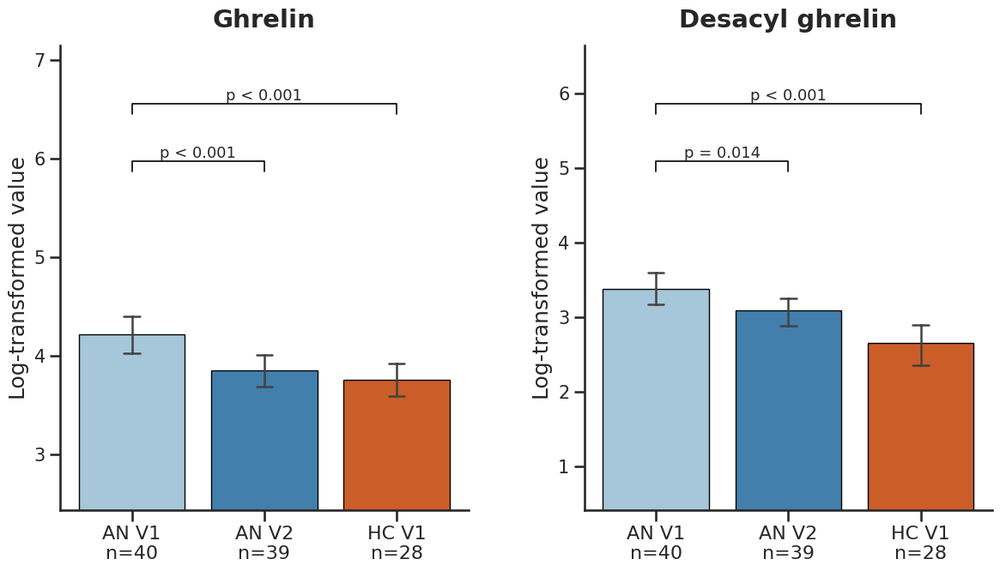

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# ============================================================
# VARIABLES TO PLOT
# ============================================================

plot_vars = [
    "ln_AG",
    "ln_DAG",
]

titles = {
    "ln_AG": "Ghrelin",
    "ln_DAG": "Desacyl ghrelin",
}

palette = {
    "AN V1": "#9ecae1",
    "AN V2": "#3182bd",
    "HC V1": "#e6550d"
}

order = [
    "AN V1",
    "AN V2",
    "HC V1"
]

# ============================================================
# DATA FOR PLOT
# ============================================================

tmp = df[
    ((df["group"] == "HC") & (df["session"] == 1)) |
    ((df["group"] == "AN") & (df["session"].isin([1, 2])))
].copy()

tmp["Group"] = np.where(
    tmp["group"] == "HC",
    "HC V1",
    "AN V" + tmp["session"].astype(int).astype(str)
)

for var in plot_vars:
    tmp[var] = pd.to_numeric(
        tmp[var],
        errors="coerce"
    )

# ============================================================
# FUNCTION TO ADD P-VALUE BRACKET
# ============================================================

def add_pvalue(ax, x1, x2, y, h, p, fontsize=13):

    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        color="black",
        linewidth=1.2
    )

    if p < 0.001:
        label = "p < 0.001"
    else:
        label = f"p = {p:.3f}"

    ax.text(
        (x1 + x2) / 2,
        y + h,
        label,
        ha="center",
        va="bottom",
        fontsize=fontsize
    )

# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 7),
    sharey=False
)

# ============================================================
# LOOP
# ============================================================

for ax, var in zip(axes, plot_vars):

    # --------------------------------------------------------
    # SAMPLE SIZES FROM PLOT DATA
    # --------------------------------------------------------

    n_by_group = {
        group: tmp.loc[
            tmp["Group"] == group,
            var
        ].notna().sum()
        for group in order
    }

    # --------------------------------------------------------
    # GET EXACT P-VALUES FROM results
    # --------------------------------------------------------

    p_v1_v2 = results.loc[
        (results["Variable"] == var)
        & (results["Comparison"] == "AN V1 vs AN V2"),
        "p"
    ].iloc[0]

    p_an_hc = results.loc[
        (results["Variable"] == var)
        & (results["Comparison"] == "AN V1 vs HC V1"),
        "p"
    ].iloc[0]

    # optional FDR values
    fdr_v1_v2 = results.loc[
        (results["Variable"] == var)
        & (results["Comparison"] == "AN V1 vs AN V2"),
        "FDR"
    ].iloc[0]

    fdr_an_hc = results.loc[
        (results["Variable"] == var)
        & (results["Comparison"] == "AN V1 vs HC V1"),
        "FDR"
    ].iloc[0]

    print(f"\n{titles[var]}")
    print(
        f"AN V1 vs AN V2: "
        f"p={p_v1_v2:.6g}, FDR={fdr_v1_v2:.6g}"
    )
    print(
        f"AN V1 vs HC V1: "
        f"p={p_an_hc:.6g}, FDR={fdr_an_hc:.6g}"
    )

    # ========================================================
    # BARPLOT WITH 95% CI
    # ========================================================

    sns.barplot(
        data=tmp,
        x="Group",
        y=var,
        hue="Group",
        order=order,
        hue_order=order,
        palette=palette,
        errorbar=("ci", 95),
        capsize=0.12,
        err_kws={
            "linewidth": 1.8
        },
        edgecolor="black",
        linewidth=1,
        legend=False,
        ax=ax
    )

    # ========================================================
    # P-VALUE BRACKET POSITIONS
    # ========================================================

    values = tmp[var].dropna()

    ymin = values.min()
    ymax = values.max()

    yrange = ymax - ymin

    if yrange == 0:
        yrange = 1

    y1 = ymax + 0.08 * yrange
    y2 = ymax + 0.27 * yrange

    h = 0.035 * yrange

    # AN V1 vs AN V2
    add_pvalue(
        ax,
        0,
        1,
        y1,
        h,
        p_v1_v2
    )

    # AN V1 vs HC V1
    add_pvalue(
        ax,
        0,
        2,
        y2,
        h,
        p_an_hc
    )

    # extra room for brackets
    ax.set_ylim(
        ymin - 0.05 * yrange,
        ymax + 0.50 * yrange
    )

    # ========================================================
    # FORMAT
    # ========================================================

    ax.set_title(
        titles[var],
        fontsize=21,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("")

    ax.set_xticks(
        range(len(order))
    )

    ax.set_xticklabels(
        [
            f"{group}\nn={n_by_group[group]}"
            for group in order
        ],
        fontsize=16
    )

    ax.set_ylabel(
        "Log-transformed value",
        fontsize=18
    )

    ax.tick_params(
        axis="y",
        labelsize=15
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ============================================================
# LAYOUT
# ============================================================

plt.tight_layout(
    w_pad=3
)

# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "Ghrelin_AG_DAG_ratio_AN_HC.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "Ghrelin_AG_DAG_ratio_AN_HC.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

#### NMH14

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

df_long = gh_leap_roi_grad_df[(gh_leap_roi_grad_df["group"] == "AN") & (gh_leap_roi_grad_df["session"].isin([1, 2]))].copy()

hormone_vars = ["ln_AG", "ln_DAG"]
gradient_cols = ["gradient_putamen_R", "gradient_putamen_L", "gradient_caudate_R", "gradient_caudate_L"]

hormone_vars = [v for v in hormone_vars if v in df_long.columns]
gradient_cols = [g for g in gradient_cols if g in df_long.columns]

df_wide = df_long.pivot_table(index="study_id", columns="session", values=hormone_vars + gradient_cols)
df_wide.columns = [f"{var}_s{int(session)}" for var, session in df_wide.columns]
df_wide = df_wide.reset_index()

for var in hormone_vars + gradient_cols:
    if f"{var}_s1" in df_wide.columns and f"{var}_s2" in df_wide.columns:
        df_wide[f"delta_{var}"] = df_wide[f"{var}_s2"] - df_wide[f"{var}_s1"]

df_cov = df_long[df_long["session"] == 1][["study_id", "age", "TIV_ml"]].drop_duplicates("study_id")
df_delta_hormone = df_wide.merge(df_cov, on="study_id", how="left")

results = []

for grad in gradient_cols:
    for hormone in hormone_vars:
        delta_grad = f"delta_{grad}"
        delta_hormone = f"delta_{hormone}"
        if delta_grad not in df_delta_hormone.columns or delta_hormone not in df_delta_hormone.columns:
            continue
        dfi = df_delta_hormone[[delta_grad, delta_hormone, "age", "TIV_ml"]].apply(pd.to_numeric, errors="coerce").dropna().copy()
        if len(dfi) < 10:
            results.append({"gradient": grad, "hormone": hormone, "n": len(dfi), "error": "Too few observations"})
            continue
        dfi["delta_gradient_z"] = (dfi[delta_grad] - dfi[delta_grad].mean()) / dfi[delta_grad].std(ddof=1)
        dfi["delta_hormone_z"] = (dfi[delta_hormone] - dfi[delta_hormone].mean()) / dfi[delta_hormone].std(ddof=1)
        try:
            X = sm.add_constant(dfi[["delta_gradient_z", "age", "TIV_ml"]].astype(float))
            model = sm.OLS(dfi["delta_hormone_z"].astype(float), X).fit()
            results.append({"gradient": grad, "hormone": hormone, "n": len(dfi), "beta_delta_gradient_z": model.params["delta_gradient_z"], "p": model.pvalues["delta_gradient_z"], "R2": model.rsquared, "adj_R2": model.rsquared_adj, "p_model": model.f_pvalue, "beta_age": model.params["age"], "p_age": model.pvalues["age"], "beta_TIV": model.params["TIV_ml"], "p_TIV": model.pvalues["TIV_ml"], "error": np.nan})
        except Exception as e:
            results.append({"gradient": grad, "hormone": hormone, "n": len(dfi), "error": str(e)})

res_grad_hormone_delta = pd.DataFrame(results).sort_values("p", na_position="last").reset_index(drop=True)

mask = res_grad_hormone_delta["p"].notna() & np.isfinite(res_grad_hormone_delta["p"])
res_grad_hormone_delta.loc[mask, "p_fdr"] = multipletests(res_grad_hormone_delta.loc[mask, "p"], method="fdr_bh")[1]

display(res_grad_hormone_delta)
display(res_grad_hormone_delta[res_grad_hormone_delta["p"] < 0.05])
display(res_grad_hormone_delta[res_grad_hormone_delta["p_fdr"] < 0.05])

,gradient,hormone,n,beta_delta_gradient_z,p,R2,adj_R2,p_model,beta_age,p_age,beta_TIV,p_TIV,error,p_fdr
0,gradient_putamen_R,ln_AG,39,0.335702,0.028692,0.253088,0.189067,0.015785,-0.005358,0.688841,0.004006,0.016618,NaN,0.179225
1,gradient_caudate_L,ln_AG,39,0.337642,0.045890,0.235565,0.170043,0.023000,-0.011354,0.426458,0.005036,0.004886,NaN,0.179225
2,gradient_putamen_L,ln_AG,39,0.284284,0.067209,0.221354,0.154613,0.030958,0.001576,0.908232,0.004181,0.014569,NaN,0.179225
3,gradient_caudate_R,ln_AG,39,0.217712,0.162987,0.189031,0.119520,0.059249,-0.003154,0.820098,0.004179,0.016574,NaN,0.325975
4,gradient_caudate_L,ln_DAG,39,0.145908,0.403510,0.144542,0.071217,0.136249,0.027004,0.079039,-0.000292,0.870132,NaN,0.486448
5,gradient_putamen_R,ln_DAG,39,-0.127201,0.425016,0.143018,0.069562,0.140014,0.032493,0.028436,-0.000681,0.692298,NaN,0.486448
6,gradient_putamen_L,ln_DAG,39,-0.127273,0.425642,0.142975,0.069516,0.140121,0.029635,0.044801,-0.000754,0.661284,NaN,0.486448
7,gradient_caudate_R,ln_DAG,39,0.018948,0.905507,0.127421,0.052629,0.184117,0.031020,0.036680,-0.000698,0.687706,NaN,0.905507


,gradient,hormone,n,beta_delta_gradient_z,p,R2,adj_R2,p_model,beta_age,p_age,beta_TIV,p_TIV,error,p_fdr
0,gradient_putamen_R,ln_AG,39,0.335702,0.028692,0.253088,0.189067,0.015785,-0.005358,0.688841,0.004006,0.016618,NaN,0.179225
1,gradient_caudate_L,ln_AG,39,0.337642,0.045890,0.235565,0.170043,0.023000,-0.011354,0.426458,0.005036,0.004886,NaN,0.179225


,gradient,hormone,n,beta_delta_gradient_z,p,R2,adj_R2,p_model,beta_age,p_age,beta_TIV,p_TIV,error,p_fdr


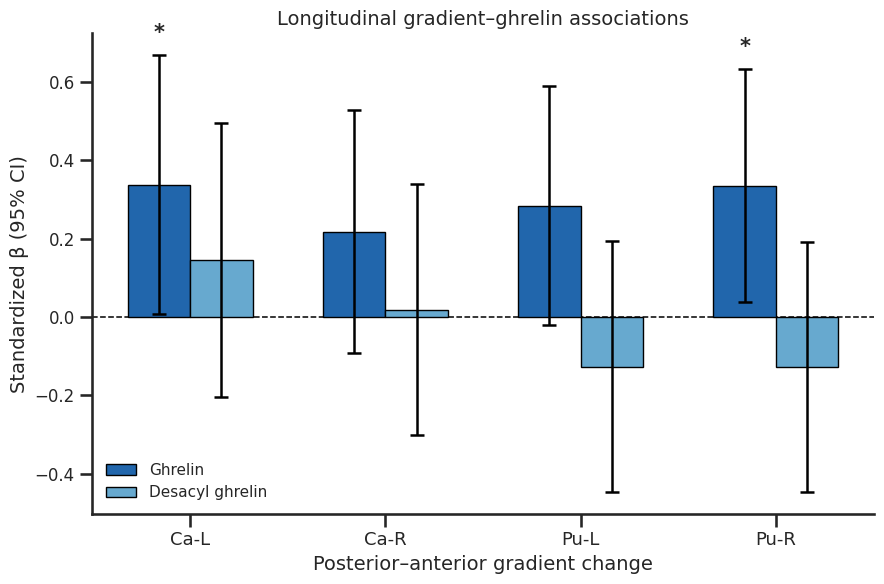

,gradient,hormone,n,beta,se,ci_low,ci_high,p,p_fdr
1,gradient_caudate_L,ln_AG,39,0.337642,0.163108,0.006515,0.668768,0.045890,0.179225
4,gradient_caudate_L,ln_DAG,39,0.145908,0.172546,-0.204379,0.496194,0.403510,0.486448
3,gradient_caudate_R,ln_AG,39,0.217712,0.152770,-0.092428,0.527852,0.162987,0.325975
7,gradient_caudate_R,ln_DAG,39,0.018948,0.158467,-0.302757,0.340653,0.905507,0.905507
2,gradient_putamen_L,ln_AG,39,0.284284,0.150499,-0.021246,0.589813,0.067209,0.179225
6,gradient_putamen_L,ln_DAG,39,-0.127273,0.157892,-0.447812,0.193265,0.425642,0.486448
0,gradient_putamen_R,ln_AG,39,0.335702,0.147120,0.037033,0.634372,0.028692,0.179225
5,gradient_putamen_R,ln_DAG,39,-0.127201,0.157588,-0.447122,0.192719,0.425016,0.486448


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

gradients = [
    "gradient_caudate_L",
    "gradient_caudate_R",
    "gradient_putamen_L",
    "gradient_putamen_R"
]

hormone_vars = ["ln_AG", "ln_DAG"]

plot_hormones = res_grad_hormone_delta[
    res_grad_hormone_delta["gradient"].isin(gradients) &
    res_grad_hormone_delta["hormone"].isin(hormone_vars)
].copy()

plot_hormones["beta"] = pd.to_numeric(
    plot_hormones["beta_delta_gradient_z"], errors="coerce"
)

plot_hormones["p"] = pd.to_numeric(plot_hormones["p"], errors="coerce")
plot_hormones["p_fdr"] = pd.to_numeric(plot_hormones["p_fdr"], errors="coerce")

plot_hormones["df_resid"] = plot_hormones["n"] - 4

plot_hormones["t_abs"] = t.isf(
    plot_hormones["p"].clip(lower=1e-300, upper=1 - 1e-12) / 2,
    plot_hormones["df_resid"]
)

plot_hormones["se"] = (
    plot_hormones["beta"].abs() / plot_hormones["t_abs"]
)

plot_hormones["t_critical"] = t.ppf(
    0.975, plot_hormones["df_resid"]
)

plot_hormones["ci_low"] = (
    plot_hormones["beta"] -
    plot_hormones["t_critical"] * plot_hormones["se"]
)

plot_hormones["ci_high"] = (
    plot_hormones["beta"] +
    plot_hormones["t_critical"] * plot_hormones["se"]
)

gradient_labels = {
    "gradient_caudate_L": "Ca-L",
    "gradient_caudate_R": "Ca-R",
    "gradient_putamen_L": "Pu-L",
    "gradient_putamen_R": "Pu-R"
}

hormone_labels = {
    "ln_AG": "Ghrelin",
    "ln_DAG": "Desacyl ghrelin"
}

plot_hormones["gradient_label"] = plot_hormones["gradient"].map(gradient_labels)
plot_hormones["hormone_label"] = plot_hormones["hormone"].map(hormone_labels)

gradient_order = ["Ca-L", "Ca-R", "Pu-L", "Pu-R"]
hormone_order = ["Ghrelin", "Desacyl ghrelin"]

colors = {
    "Ghrelin": "#2166ac",
    "Desacyl ghrelin": "#67a9cf"
}

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(gradient_order))
width = 0.32

for i, hormone in enumerate(hormone_order):

    temp = (
        plot_hormones[plot_hormones["hormone_label"] == hormone]
        .set_index("gradient_label")
        .reindex(gradient_order)
    )

    xpos = x + (i - 0.5) * width

    ax.bar(
        xpos,
        temp["beta"],
        width=width,
        color=colors[hormone],
        edgecolor="black",
        linewidth=1,
        label=hormone,
        zorder=2
    )

    lower = temp["beta"] - temp["ci_low"]
    upper = temp["ci_high"] - temp["beta"]

    ax.errorbar(
        xpos,
        temp["beta"],
        yerr=np.vstack([lower, upper]),
        fmt="none",
        ecolor="black",
        elinewidth=1.8,
        capsize=5,
        capthick=1.8,
        zorder=3
    )

    for xx, (_, row) in zip(xpos, temp.iterrows()):

        if pd.notna(row["p_fdr"]) and row["p_fdr"] < 0.05:
            sig = "**"
        elif pd.notna(row["p"]) and row["p"] < 0.05:
            sig = "*"
        else:
            sig = ""

        if sig:
            ypos = (
                row["ci_high"] + 0.03
                if row["beta"] >= 0
                else row["ci_low"] - 0.03
            )

            ax.text(
                xx,
                ypos,
                sig,
                ha="center",
                va="bottom" if row["beta"] >= 0 else "top",
                fontsize=15,
                fontweight="bold"
            )

ax.axhline(0, color="black", linewidth=1.1, linestyle="--", zorder=1)

ax.set_xticks(x)
ax.set_xticklabels(gradient_order, fontsize=13)

ax.set_ylabel("Standardized β (95% CI)", fontsize=14)
ax.set_xlabel("Posterior–anterior gradient change", fontsize=14)
ax.set_title("Longitudinal gradient–ghrelin associations", fontsize=14)

ax.tick_params(axis="y", labelsize=12)
ax.grid(False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, fontsize=11)

plt.tight_layout()

plt.savefig(
    "Ghrelin_striatal_gradient_associations_bar_CI.svg",
    format="svg",
    bbox_inches="tight"
)

plt.savefig(
    "Ghrelin_striatal_gradient_associations_bar_CI.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

display(
    plot_hormones[
        [
            "gradient",
            "hormone",
            "n",
            "beta",
            "se",
            "ci_low",
            "ci_high",
            "p",
            "p_fdr"
        ]
    ].sort_values(["gradient", "hormone"])
)

### plot 4 phases and sessions MRI

MRI–SOAT participants:
group  session
AN     1          41
       2          40
HC     1          28
Name: study_id, dtype: int64

STATISTICAL RESULTS
phase  measure     comparison  n1  n2  statistic        p    p_fdr
   P1  Block 1 AN V1 vs AN V2  40  40      240.0 0.653126 0.893310
   P1  Block 1 AN V1 vs HC V1  41  28      544.5 0.719919 0.899899
   P1  Block 2 AN V1 vs AN V2  40  40      246.5 0.543104 0.893310
   P1  Block 2 AN V1 vs HC V1  41  28      346.0 0.005001 0.014287
   P1  Block 3 AN V1 vs AN V2  40  40      289.0 0.669982 0.893310
   P1  Block 3 AN V1 vs HC V1  41  28      376.5 0.014333 0.031852
   P1  Block 4 AN V1 vs AN V2  40  40      285.5 0.318778 0.637556
   P1  Block 4 AN V1 vs HC V1  41  28      313.5 0.001030 0.005150
   P1  Block 5 AN V1 vs AN V2  40  40      209.5 0.635284 0.893310
   P1  Block 5 AN V1 vs HC V1  41  28      324.5 0.000987 0.005150
   P1  Block 6 AN V1 vs AN V2  40  40      212.5 0.485529 0.882780
   P1  Block 6 AN V1 vs HC V1  41  28      34

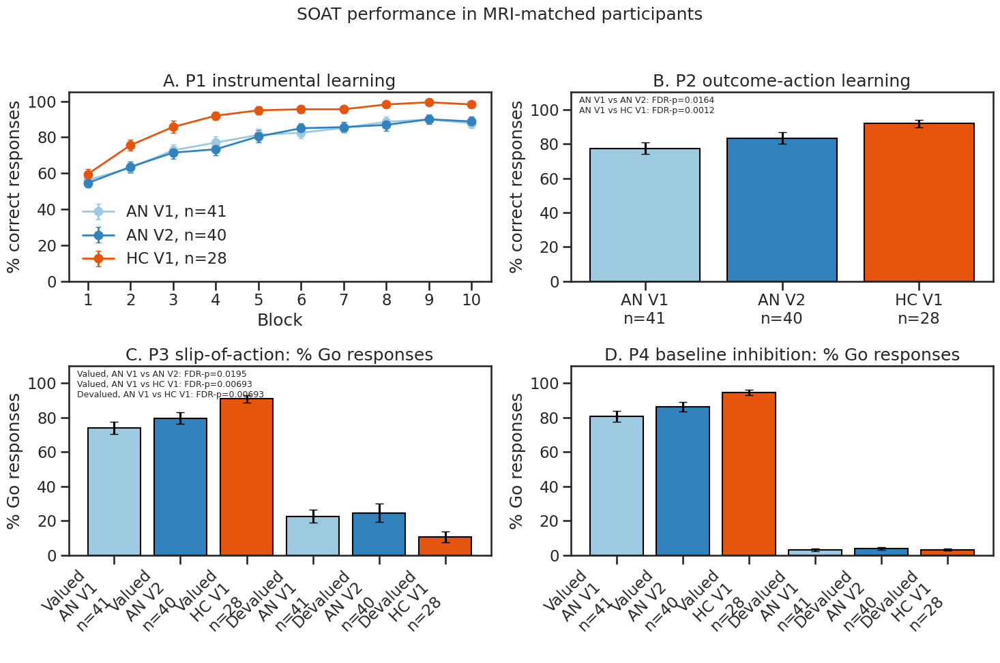

Saved figure: /mnt/POOL_IRM07/REMANO/DATA-SUJETS/SOAT_behavior_sessions_response_types_percent_MRI.png

FDR-SIGNIFICANT RESULTS


,phase,measure,comparison,statistic,p,n1,n2,p_fdr
7,P1,Block 4,AN V1 vs HC V1,313.5,0.001030,41,28,0.005150
9,P1,Block 5,AN V1 vs HC V1,324.5,0.000987,41,28,0.005150
17,P1,Block 9,AN V1 vs HC V1,369.0,0.000947,41,28,0.005150
19,P1,Block 10,AN V1 vs HC V1,319.5,0.000390,41,28,0.005150
11,P1,Block 6,AN V1 vs HC V1,343.0,0.001821,41,28,0.006071
15,P1,Block 8,AN V1 vs HC V1,363.0,0.001793,41,28,0.006071
3,P1,Block 2,AN V1 vs HC V1,346.0,0.005001,41,28,0.014287
13,P1,Block 7,AN V1 vs HC V1,369.5,0.006686,41,28,0.016716
5,P1,Block 3,AN V1 vs HC V1,376.5,0.014333,41,28,0.031852
21,P2,Accuracy,AN V1 vs HC V1,294.5,0.000601,41,28,0.001201


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.stats import wilcoxon, mannwhitneyu
from statsmodels.stats.multitest import multipletests


# ============================================================
# FILES
# ============================================================

raw_file = "/mnt/POOL_IRM07/REMANO/DATA-SUJETS/SOAT_trial_level_raw.xlsx"

out_fig = "/mnt/POOL_IRM07/REMANO/DATA-SUJETS/SOAT_behavior_sessions_response_types_percent_MRI.png"


# ============================================================
# MRI-MATCHED SOAT DATA
# ============================================================

df_plot = df_soat_grad.copy()

df_plot["group"] = df_plot["group"].replace({"VS": "HC"})

for col in ["study_id", "subject", "session"]:
    if col in df_plot.columns:
        df_plot[col] = pd.to_numeric(df_plot[col], errors="coerce")

df_plot = df_plot.drop_duplicates(
    ["study_id", "session", "group"]
)

print("MRI–SOAT participants:")

print(
    df_plot.groupby(
        ["group", "session"]
    )["study_id"].nunique()
)


# ============================================================
# GROUPS / COLORS
# ============================================================

groups = [
    g for g in ["AN", "HC"]
    if g in df_plot["group"].unique()
]

sessions_by_group = {
    g: sorted(
        df_plot.loc[
            df_plot["group"] == g,
            "session"
        ]
        .dropna()
        .astype(int)
        .unique()
    )
    for g in groups
}

colors = {
    ("AN", 1): "#9ecae1",
    ("AN", 2): "#3182bd",
    ("AN", 3): "#08519c",
    ("HC", 1): "#e6550d",
    ("HC", 2): "#fd8d3c",
    ("HC", 3): "#a63603"
}


# ============================================================
# SEM
# ============================================================

def sem(x):

    x = pd.Series(x).dropna()

    return (
        x.std(ddof=1) / np.sqrt(len(x))
        if len(x) > 1
        else np.nan
    )


# ============================================================
# RAW SOAT
# ============================================================

df_raw = pd.read_excel(
    raw_file,
    sheet_name="trial_level_raw"
)

num_cols = [
    "subject",
    "session",
    "block",
    "trial",
    "response",
    "RT",
    "score",
    "stimulus_val_deval",
    "action"
]

for col in num_cols:

    if col in df_raw.columns:

        df_raw[col] = pd.to_numeric(
            df_raw[col],
            errors="coerce"
        )

df_raw["group"] = df_raw["group"].replace(
    {"VS": "HC"}
)

df_raw = df_raw.rename(
    columns={"subject": "study_id"}
)


# ============================================================
# KEEP ONLY MRI-MATCHED PARTICIPANTS
# ============================================================

soat_keep = (
    df_plot[
        ["study_id", "session", "group"]
    ]
    .drop_duplicates()
)

df_raw = df_raw.merge(
    soat_keep,
    on=["study_id", "session", "group"],
    how="inner",
    validate="many_to_one"
)


# ============================================================
# P1
# ============================================================

p1_subject_block = (
    df_raw[
        df_raw["phase"] == "P1"
    ]
    .groupby(
        ["group", "study_id", "session", "block"],
        as_index=False
    )
    .agg(
        accuracy=(
            "response",
            lambda x: x.mean() * 100
        )
    )
)

p1_plot = (
    p1_subject_block
    .groupby(
        ["group", "session", "block"],
        as_index=False
    )
    .agg(
        mean_accuracy=("accuracy", "mean"),
        sem_accuracy=("accuracy", sem),
        n=("study_id", "nunique")
    )
)


# ============================================================
# P2
# ============================================================

p2_plot = (
    df_plot
    .dropna(
        subset=["P2_mean_accuracy"]
    )
    .groupby(
        ["group", "session"],
        as_index=False
    )
    .agg(
        mean_accuracy=(
            "P2_mean_accuracy",
            "mean"
        ),
        sem_accuracy=(
            "P2_mean_accuracy",
            sem
        ),
        n=("study_id", "nunique")
    )
)


# ============================================================
# P3 / P4 SUMMARY
# ============================================================

def prepare_summary_phase(data, phase):

    valued_col = f"{phase}_go_response_valued"
    devalued_col = f"{phase}_go_response_devalued"

    long_df = data[
        [
            "group",
            "study_id",
            "session",
            valued_col,
            devalued_col
        ]
    ].melt(
        id_vars=[
            "group",
            "study_id",
            "session"
        ],
        value_vars=[
            valued_col,
            devalued_col
        ],
        var_name="stimulus_type",
        value_name="percent"
    )

    long_df["stimulus_type"] = (
        long_df["stimulus_type"]
        .map({
            valued_col: "Valued",
            devalued_col: "Devalued"
        })
    )

    return (
        long_df
        .dropna(
            subset=["percent"]
        )
        .groupby(
            [
                "group",
                "session",
                "stimulus_type"
            ],
            as_index=False
        )
        .agg(
            mean_percent=("percent", "mean"),
            sem_percent=("percent", sem),
            n=("study_id", "nunique")
        )
    )


p3_plot = prepare_summary_phase(
    df_plot,
    "P3"
)

p4_plot = prepare_summary_phase(
    df_plot,
    "P4"
)


# ============================================================
# STATISTICAL TEST FUNCTIONS
# ============================================================

def paired_test(
    data,
    variable,
    group="AN",
    s1=1,
    s2=2
):

    tmp = (
        data[
            data["group"] == group
        ][
            ["study_id", "session", variable]
        ]
        .dropna()
        .pivot(
            index="study_id",
            columns="session",
            values=variable
        )
    )

    if s1 not in tmp.columns or s2 not in tmp.columns:
        return np.nan, np.nan, 0

    paired = (
        tmp[[s1, s2]]
        .dropna()
    )

    if len(paired) == 0:
        return np.nan, np.nan, 0

    stat, p = wilcoxon(
        paired[s1],
        paired[s2]
    )

    return stat, p, len(paired)


def independent_test(
    data,
    variable,
    session
):

    an = (
        data.loc[
            (data["group"] == "AN")
            & (data["session"] == session),
            variable
        ]
        .dropna()
    )

    hc = (
        data.loc[
            (data["group"] == "HC")
            & (data["session"] == session),
            variable
        ]
        .dropna()
    )

    if len(an) == 0 or len(hc) == 0:
        return np.nan, np.nan, len(an), len(hc)

    stat, p = mannwhitneyu(
        an,
        hc,
        alternative="two-sided"
    )

    return stat, p, len(an), len(hc)


# ============================================================
# COLLECT ALL STATS
# ============================================================

stats_results = []


# ============================================================
# P1 BLOCKWISE TESTS
# ============================================================

for block in sorted(
    p1_subject_block["block"].dropna().unique()
):

    d = p1_subject_block[
        p1_subject_block["block"] == block
    ]

    # AN V1 vs V2
    stat, p, n = paired_test(
        d,
        "accuracy"
    )

    stats_results.append({
        "phase": "P1",
        "measure": f"Block {block}",
        "comparison": "AN V1 vs AN V2",
        "statistic": stat,
        "p": p,
        "n1": n,
        "n2": n
    })

    # AN vs HC V1
    stat, p, n_an, n_hc = independent_test(
        d,
        "accuracy",
        session=1
    )

    stats_results.append({
        "phase": "P1",
        "measure": f"Block {block}",
        "comparison": "AN V1 vs HC V1",
        "statistic": stat,
        "p": p,
        "n1": n_an,
        "n2": n_hc
    })

    # AN vs HC V2 if HC V2 exists
    if 2 in sessions_by_group.get("HC", []):

        stat, p, n_an, n_hc = independent_test(
            d,
            "accuracy",
            session=2
        )

        stats_results.append({
            "phase": "P1",
            "measure": f"Block {block}",
            "comparison": "AN V2 vs HC V2",
            "statistic": stat,
            "p": p,
            "n1": n_an,
            "n2": n_hc
        })


# ============================================================
# P2 TESTS
# ============================================================

stat, p, n = paired_test(
    df_plot,
    "P2_mean_accuracy"
)

stats_results.append({
    "phase": "P2",
    "measure": "Accuracy",
    "comparison": "AN V1 vs AN V2",
    "statistic": stat,
    "p": p,
    "n1": n,
    "n2": n
})

stat, p, n_an, n_hc = independent_test(
    df_plot,
    "P2_mean_accuracy",
    session=1
)

stats_results.append({
    "phase": "P2",
    "measure": "Accuracy",
    "comparison": "AN V1 vs HC V1",
    "statistic": stat,
    "p": p,
    "n1": n_an,
    "n2": n_hc
})

if 2 in sessions_by_group.get("HC", []):

    stat, p, n_an, n_hc = independent_test(
        df_plot,
        "P2_mean_accuracy",
        session=2
    )

    stats_results.append({
        "phase": "P2",
        "measure": "Accuracy",
        "comparison": "AN V2 vs HC V2",
        "statistic": stat,
        "p": p,
        "n1": n_an,
        "n2": n_hc
    })


# ============================================================
# P3 / P4 TESTS
# ============================================================

for phase in ["P3", "P4"]:

    for stim in ["valued", "devalued"]:

        variable = f"{phase}_go_response_{stim}"

        stat, p, n = paired_test(
            df_plot,
            variable
        )

        stats_results.append({
            "phase": phase,
            "measure": stim.capitalize(),
            "comparison": "AN V1 vs AN V2",
            "statistic": stat,
            "p": p,
            "n1": n,
            "n2": n
        })

        stat, p, n_an, n_hc = independent_test(
            df_plot,
            variable,
            session=1
        )

        stats_results.append({
            "phase": phase,
            "measure": stim.capitalize(),
            "comparison": "AN V1 vs HC V1",
            "statistic": stat,
            "p": p,
            "n1": n_an,
            "n2": n_hc
        })

        if 2 in sessions_by_group.get("HC", []):

            stat, p, n_an, n_hc = independent_test(
                df_plot,
                variable,
                session=2
            )

            stats_results.append({
                "phase": phase,
                "measure": stim.capitalize(),
                "comparison": "AN V2 vs HC V2",
                "statistic": stat,
                "p": p,
                "n1": n_an,
                "n2": n_hc
            })


# ============================================================
# FDR CORRECTION WITHIN EACH PHASE
# ============================================================

stats_df = pd.DataFrame(
    stats_results
)

stats_df["p_fdr"] = np.nan

for phase in stats_df["phase"].unique():

    mask = (
        (stats_df["phase"] == phase)
        & stats_df["p"].notna()
    )

    if mask.sum() > 0:

        stats_df.loc[
            mask,
            "p_fdr"
        ] = multipletests(
            stats_df.loc[
                mask,
                "p"
            ],
            method="fdr_bh"
        )[1]


# ============================================================
# SHOW STATS
# ============================================================

print("\nSTATISTICAL RESULTS")
print(
    stats_df[
        [
            "phase",
            "measure",
            "comparison",
            "n1",
            "n2",
            "statistic",
            "p",
            "p_fdr"
        ]
    ].to_string(index=False)
)


# ============================================================
# PLOT P3 / P4 RESPONSE TYPES
# ============================================================

def plot_response_types(
    ax,
    plot_df_phase,
    title
):

    labels = []
    means = []
    errors = []
    bar_colors = []

    for stim in ["Valued", "Devalued"]:

        for group in groups:

            for session in sessions_by_group[group]:

                tmp = plot_df_phase[
                    (plot_df_phase["stimulus_type"] == stim)
                    & (plot_df_phase["group"] == group)
                    & (plot_df_phase["session"] == session)
                ]

                if tmp.empty:
                    continue

                n = int(
                    tmp["n"].iloc[0]
                )

                labels.append(
                    f"{stim}\n{group} V{session}\nn={n}"
                )

                means.append(
                    tmp["mean_percent"].iloc[0]
                )

                errors.append(
                    tmp["sem_percent"].iloc[0]
                )

                bar_colors.append(
                    colors.get(
                        (group, session),
                        "grey"
                    )
                )

    x = np.arange(
        len(labels)
    )

    ax.bar(
        x,
        means,
        yerr=errors,
        capsize=4,
        color=bar_colors,
        edgecolor="black"
    )

    ax.set_title(
        title
    )

    ax.set_ylabel(
        "% Go responses"
    )

    ax.set_xticks(
        x
    )

    ax.set_xticklabels(
        labels,
        rotation=45,
        ha="right"
    )

    ax.set_ylim(
        0,
        110
    )


# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10)
)

axA, axB, axC, axD = axes.flatten()


# ============================================================
# A. P1
# ============================================================

for group in groups:

    for session in sessions_by_group[group]:

        d = p1_plot[
            (p1_plot["group"] == group)
            & (p1_plot["session"] == session)
        ]

        if d.empty:
            continue

        n = int(
            d["n"].max()
        )

        axA.errorbar(
            d["block"],
            d["mean_accuracy"],
            yerr=d["sem_accuracy"],
            marker="o",
            linewidth=2,
            capsize=3,
            color=colors.get(
                (group, session),
                "grey"
            ),
            label=f"{group} V{session}, n={n}"
        )

axA.set_title(
    "A. P1 instrumental learning"
)

axA.set_xlabel(
    "Block"
)

axA.set_ylabel(
    "% correct responses"
)

axA.set_xticks(
    sorted(
        p1_plot["block"]
        .dropna()
        .unique()
    )
)

axA.set_ylim(
    0,
    105
)

axA.legend(
    frameon=False
)


# ============================================================
# B. P2
# ============================================================

labels = []
means = []
errors = []
bar_colors = []

for group in groups:

    for session in sessions_by_group[group]:

        tmp = p2_plot[
            (p2_plot["group"] == group)
            & (p2_plot["session"] == session)
        ]

        if tmp.empty:
            continue

        n = int(
            tmp["n"].iloc[0]
        )

        labels.append(
            f"{group} V{session}\nn={n}"
        )

        means.append(
            tmp["mean_accuracy"].iloc[0]
        )

        errors.append(
            tmp["sem_accuracy"].iloc[0]
        )

        bar_colors.append(
            colors.get(
                (group, session),
                "grey"
            )
        )

x = np.arange(
    len(labels)
)

axB.bar(
    x,
    means,
    yerr=errors,
    capsize=4,
    color=bar_colors,
    edgecolor="black"
)

axB.set_title(
    "B. P2 outcome-action learning"
)

axB.set_ylabel(
    "% correct responses"
)

axB.set_xticks(
    x
)

axB.set_xticklabels(
    labels
)

axB.set_ylim(
    0,
    110
)


# ============================================================
# ADD P2 FDR RESULTS AS TEXT
# ============================================================

p2_sig = stats_df[
    (stats_df["phase"] == "P2")
    & (stats_df["p_fdr"] < 0.05)
]

if len(p2_sig) > 0:

    txt = "\n".join(
        [
            f"{r['comparison']}: FDR-p={r['p_fdr']:.3g}"
            for _, r in p2_sig.iterrows()
        ]
    )

    axB.text(
        0.02,
        0.98,
        txt,
        transform=axB.transAxes,
        va="top",
        fontsize=9
    )


# ============================================================
# C / D
# ============================================================

plot_response_types(
    axC,
    p3_plot,
    "C. P3 slip-of-action: % Go responses"
)

plot_response_types(
    axD,
    p4_plot,
    "D. P4 baseline inhibition: % Go responses"
)


# ============================================================
# ADD P3 / P4 SIGNIFICANT RESULTS
# ============================================================

for ax, phase in [
    (axC, "P3"),
    (axD, "P4")
]:

    sig = stats_df[
        (stats_df["phase"] == phase)
        & (stats_df["p_fdr"] < 0.05)
    ]

    if len(sig) > 0:

        txt = "\n".join(
            [
                f"{r['measure']}, {r['comparison']}: FDR-p={r['p_fdr']:.3g}"
                for _, r in sig.iterrows()
            ]
        )

        ax.text(
            0.02,
            0.98,
            txt,
            transform=ax.transAxes,
            va="top",
            fontsize=9
        )


# ============================================================
# FINAL FORMAT
# ============================================================

fig.suptitle(
    "SOAT performance in MRI-matched participants",
    fontsize=18
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    out_fig,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Saved figure:",
    out_fig
)


# ============================================================
# SIGNIFICANT FDR RESULTS ONLY
# ============================================================

print("\nFDR-SIGNIFICANT RESULTS")

display(
    stats_df[
        stats_df["p_fdr"] < 0.05
    ].sort_values(
        ["phase", "p_fdr"]
    )
)

In [ ]:
from scipy.stats import shapiro, ttest_rel, wilcoxon, ttest_ind, mannwhitneyu
from statsmodels.stats.multitest import multipletests
import pandas as pd
import numpy as np

# ============================================================
# PREPARE SUBJECT-LEVEL DATA
# ============================================================

# P1: accuracy per subject and block
p1_subject_block = (
    df_raw[df_raw["phase"] == "P1"]
    .groupby(["group", "study_id", "session", "block"], as_index=False)
    .agg(
        accuracy=("response", lambda x: x.mean() * 100)
    )
)

# P2: one accuracy value per subject/session
p2_subject = (
    df_plot[
        ["study_id", "group", "session", "P2_mean_accuracy"]
    ]
    .dropna(subset=["P2_mean_accuracy"])
    .drop_duplicates(["study_id", "group", "session"])
    .copy()
)

# P3
p3_subject = (
    df_plot[
        [
            "study_id",
            "group",
            "session",
            "P3_go_response_valued",
            "P3_go_response_devalued"
        ]
    ]
    .drop_duplicates(["study_id", "group", "session"])
    .copy()
)

# P4
p4_subject = (
    df_plot[
        [
            "study_id",
            "group",
            "session",
            "P4_go_response_valued",
            "P4_go_response_devalued"
        ]
    ]
    .drop_duplicates(["study_id", "group", "session"])
    .copy()
)

# ============================================================
# TEST FUNCTIONS
# ============================================================

stats_results = []

def paired_test(data, value_col, label):

    an = data[data["group"] == "AN"].copy()

    wide = an.pivot_table(
        index="study_id",
        columns="session",
        values=value_col,
        aggfunc="first"
    )

    if 1 not in wide.columns or 2 not in wide.columns:
        return

    wide = wide[[1, 2]].dropna()

    if len(wide) < 3:
        return

    v1 = wide[1].astype(float)
    v2 = wide[2].astype(float)

    delta = v2 - v1

    sh = shapiro(delta)

    if sh.pvalue > 0.05:
        test = ttest_rel(v2, v1)
        test_name = "Paired t-test"
    else:
        try:
            test = wilcoxon(v2, v1, alternative="two-sided")
            test_name = "Wilcoxon signed-rank"
        except ValueError:
            return

    stats_results.append({
        "phase_measure": label,
        "comparison": "AN V1 vs AN V2",
        "n1": len(v1),
        "n2": len(v2),

        "mean1": v1.mean(),
        "sd1": v1.std(ddof=1),

        "mean2": v2.mean(),
        "sd2": v2.std(ddof=1),

        "delta": delta.mean(),

        "direction": (
            "increase"
            if delta.mean() > 0
            else "decrease"
            if delta.mean() < 0
            else "no change"
        ),

        "test": test_name,
        "statistic": test.statistic,
        "p": test.pvalue
    })


def independent_test(data, value_col, an_session, label):

    an = (
        data[
            (data["group"] == "AN") &
            (data["session"] == an_session)
        ][value_col]
        .dropna()
        .astype(float)
    )

    hc = (
        data[
            (data["group"] == "HC") &
            (data["session"] == 1)
        ][value_col]
        .dropna()
        .astype(float)
    )

    if len(an) < 3 or len(hc) < 3:
        return

    sh_an = shapiro(an)
    sh_hc = shapiro(hc)

    if sh_an.pvalue > 0.05 and sh_hc.pvalue > 0.05:
        test = ttest_ind(
            an,
            hc,
            equal_var=False
        )
        test_name = "Welch t-test"

    else:
        test = mannwhitneyu(
            an,
            hc,
            alternative="two-sided"
        )
        test_name = "Mann-Whitney"

    diff = an.mean() - hc.mean()

    stats_results.append({
        "phase_measure": label,
        "comparison": f"AN V{an_session} vs HC V1",
        "n1": len(an),
        "n2": len(hc),

        "mean1": an.mean(),
        "sd1": an.std(ddof=1),

        "mean2": hc.mean(),
        "sd2": hc.std(ddof=1),

        "delta": diff,

        "direction": (
            "AN higher"
            if diff > 0
            else "AN lower"
            if diff < 0
            else "equal"
        ),

        "test": test_name,
        "statistic": test.statistic,
        "p": test.pvalue
    })

# ============================================================
# P1 — INSTRUMENTAL LEARNING
# ============================================================

for block in sorted(
    p1_subject_block["block"]
    .dropna()
    .unique()
):

    d = p1_subject_block[
        p1_subject_block["block"] == block
    ].copy()

    label = f"P1 block {int(block)}"

    paired_test(
        d,
        "accuracy",
        label
    )

    independent_test(
        d,
        "accuracy",
        1,
        label
    )

    independent_test(
        d,
        "accuracy",
        2,
        label
    )

# ============================================================
# P2 — OUTCOME-ACTION LEARNING
# ============================================================

paired_test(
    p2_subject,
    "P2_mean_accuracy",
    "P2 mean accuracy"
)

independent_test(
    p2_subject,
    "P2_mean_accuracy",
    1,
    "P2 mean accuracy"
)

independent_test(
    p2_subject,
    "P2_mean_accuracy",
    2,
    "P2 mean accuracy"
)

# ============================================================
# P3 — SLIP-OF-ACTION
# ============================================================

for col, stim in [
    ("P3_go_response_valued", "Valued"),
    ("P3_go_response_devalued", "Devalued")
]:

    d = p3_subject.dropna(subset=[col]).copy()

    label = f"P3 {stim}"

    paired_test(
        d,
        col,
        label
    )

    independent_test(
        d,
        col,
        1,
        label
    )

    independent_test(
        d,
        col,
        2,
        label
    )

# ============================================================
# P4 — BASELINE INHIBITION
# ============================================================

for col, stim in [
    ("P4_go_response_valued", "Valued"),
    ("P4_go_response_devalued", "Devalued")
]:

    d = p4_subject.dropna(subset=[col]).copy()

    label = f"P4 {stim}"

    paired_test(
        d,
        col,
        label
    )

    independent_test(
        d,
        col,
        1,
        label
    )

    independent_test(
        d,
        col,
        2,
        label
    )

# ============================================================
# CREATE RESULTS TABLE
# ============================================================

stats_df = pd.DataFrame(stats_results)

stats_df["phase"] = (
    stats_df["phase_measure"]
    .str.extract(r"^(P[1-4])", expand=False)
)

# ============================================================
# FDR CORRECTION WITHIN EACH PHASE
# ============================================================

stats_df["p_fdr"] = np.nan

for phase in stats_df["phase"].dropna().unique():

    mask = stats_df["phase"] == phase

    stats_df.loc[
        mask,
        "p_fdr"
    ] = multipletests(
        stats_df.loc[
            mask,
            "p"
        ].astype(float),
        method="fdr_bh"
    )[1]

# ============================================================
# CLEAN TABLE
# ============================================================

table_soat = stats_df[
    [
        "phase",
        "phase_measure",
        "comparison",

        "n1",
        "n2",

        "mean1",
        "sd1",

        "mean2",
        "sd2",

        "delta",
        "direction",

        "test",
        "statistic",

        "p",
        "p_fdr"
    ]
].copy()

table_soat = table_soat.round({
    "mean1": 2,
    "sd1": 2,

    "mean2": 2,
    "sd2": 2,

    "delta": 2,
    "statistic": 3,

    "p": 5,
    "p_fdr": 5
})

table_soat = table_soat.sort_values(
    [
        "phase",
        "phase_measure",
        "comparison"
    ]
)

table_soat

,phase,phase_measure,comparison,n1,n2,mean1,sd1,mean2,sd2,delta,direction,test,statistic,p,p_fdr
0,P1,P1 block 1,AN V1 vs AN V2,40,40,55.83,17.01,54.58,15.44,-1.25,decrease,Paired t-test,-0.385,0.70251,0.89990
1,P1,P1 block 1,AN V1 vs HC V1,41,28,56.30,17.06,59.52,14.65,-3.22,AN lower,Mann-Whitney,544.500,0.71992,0.89990
2,P1,P1 block 1,AN V2 vs HC V1,40,28,54.58,15.44,59.52,14.65,-4.94,AN lower,Mann-Whitney,482.000,0.32710,0.51647
27,P1,P1 block 10,AN V1 vs AN V2,40,40,87.71,16.98,88.75,18.25,1.04,increase,Wilcoxon signed-rank,165.000,0.78773,0.92453
28,P1,P1 block 10,AN V1 vs HC V1,41,28,87.80,16.78,98.21,5.25,-10.41,AN lower,Mann-Whitney,319.500,0.00039,0.00386
29,P1,P1 block 10,AN V2 vs HC V1,40,28,88.75,18.25,98.21,5.25,-9.46,AN lower,Mann-Whitney,385.500,0.00798,0.01496
3,P1,P1 block 2,AN V1 vs AN V2,40,40,62.08,18.29,63.54,18.36,1.46,increase,Paired t-test,0.381,0.70555,0.89990
4,P1,P1 block 2,AN V1 vs HC V1,41,28,63.01,19.01,75.60,16.34,-12.59,AN lower,Welch t-test,-2.938,0.00460,0.01150
5,P1,P1 block 2,AN V2 vs HC V1,40,28,63.54,18.36,75.60,16.34,-12.05,AN lower,Mann-Whitney,339.000,0.00558,0.01216
6,P1,P1 block 3,AN V1 vs AN V2,40,40,72.08,21.40,71.46,21.92,-0.63,decrease,Paired t-test,-0.145,0.88510,0.92453


### plot of 4 phases remission

MRI–SOAT sample sizes:
remission_v3  session  n_study_id  n_subject
    relapsed        1          18         18
    relapsed        2          18         18
      stable        1          21         21
      stable        2          20         20


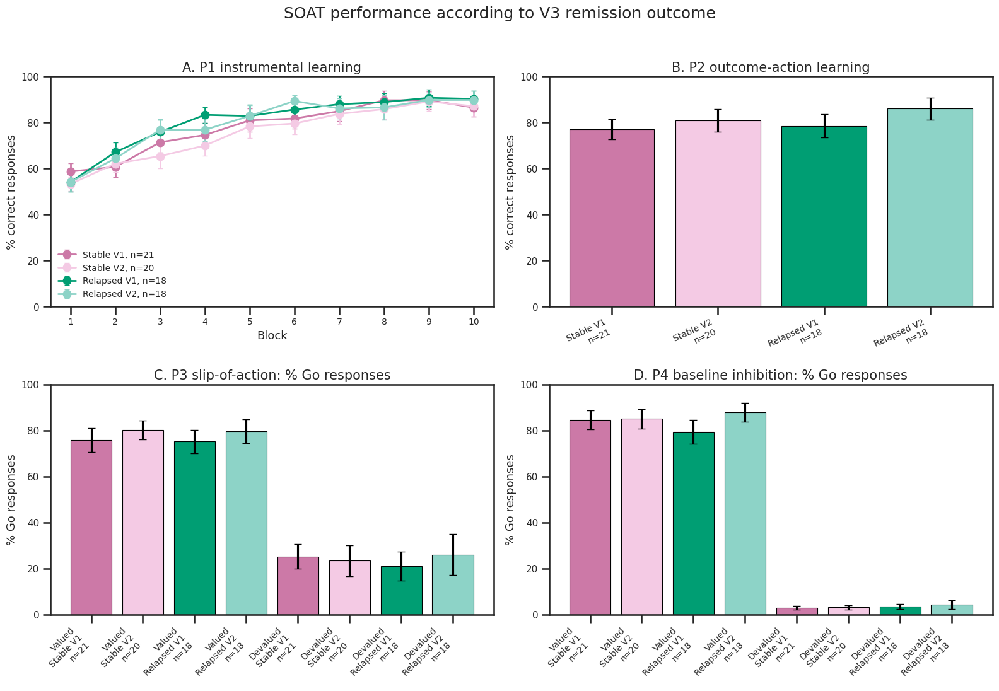

Saved figure: /mnt/POOL_IRM07/REMANO/DATA-SUJETS/SOAT_behavior_stable_relapsed_sessions_MRI.png


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

raw_file="/mnt/POOL_IRM07/REMANO/DATA-SUJETS/SOAT_trial_level_raw.xlsx"
out_fig="/mnt/POOL_IRM07/REMANO/DATA-SUJETS/SOAT_behavior_stable_relapsed_sessions_MRI.png"

df_summary=df_soat_grad.copy()
df_summary["group"]=df_summary["group"].replace({"VS":"HC"})
for col in ["study_id","subject","session"]: df_summary[col]=pd.to_numeric(df_summary[col],errors="coerce")
df_summary["remission_v3"]=df_summary["remission_v3"].astype(str).str.strip().str.lower().replace({"nan":np.nan})
df_summary=df_summary[(df_summary["group"]=="AN")&(df_summary["remission_v3"].isin(["stable","relapsed"]))&(df_summary["session"].isin([1,2]))].drop_duplicates(["study_id","session","group"]).copy()

print("MRI–SOAT sample sizes:")
print(df_summary.groupby(["remission_v3","session"]).agg(n_study_id=("study_id","nunique"),n_subject=("subject","nunique")).reset_index().to_string(index=False))

groups=["stable","relapsed"]
sessions_by_group={"stable":[1,2],"relapsed":[1,2]}
colors={("stable",1):"#CC79A7",("stable",2):"#F4CAE4",("relapsed",1):"#009E73",("relapsed",2):"#8DD3C7"}

def sem(x):
    x=pd.Series(x).dropna()
    return x.std(ddof=1)/np.sqrt(len(x)) if len(x)>1 else np.nan

df_raw=pd.read_excel(raw_file,sheet_name="trial_level_raw")
num_cols=["subject","session","block","trial","response","RT","score","stimulus_val_deval","action"]
for col in num_cols:
    if col in df_raw.columns: df_raw[col]=pd.to_numeric(df_raw[col],errors="coerce")

df_raw["group"]=df_raw["group"].replace({"VS":"HC"})
df_raw=df_raw.rename(columns={"subject":"study_id"})
keep=df_summary[["study_id","session","group","subject","remission_v3"]].drop_duplicates(["study_id","session","group"])
df_raw=df_raw.merge(keep,on=["study_id","session","group"],how="inner",validate="many_to_one")

p1_subject_block=df_raw[df_raw["phase"]=="P1"].groupby(["remission_v3","study_id","subject","session","block"],as_index=False).agg(accuracy=("response",lambda x:x.mean()*100))
p1_plot=p1_subject_block.groupby(["remission_v3","session","block"],as_index=False).agg(mean_accuracy=("accuracy","mean"),sem_accuracy=("accuracy",sem),n_subjects=("study_id","nunique"))

p2_plot=df_summary.dropna(subset=["P2_mean_accuracy"]).groupby(["remission_v3","session"],as_index=False).agg(mean_accuracy=("P2_mean_accuracy","mean"),sem_accuracy=("P2_mean_accuracy",sem),n_subjects=("study_id","nunique"))

def prepare_phase(data,phase):
    valued=f"{phase}_go_response_valued"
    devalued=f"{phase}_go_response_devalued"
    d=data[["remission_v3","study_id","subject","session",valued,devalued]].melt(id_vars=["remission_v3","study_id","subject","session"],value_vars=[valued,devalued],var_name="stimulus_type",value_name="percent")
    d["stimulus_type"]=d["stimulus_type"].map({valued:"Valued",devalued:"Devalued"})
    return d.dropna(subset=["percent"]).groupby(["remission_v3","session","stimulus_type"],as_index=False).agg(mean_percent=("percent","mean"),sem_percent=("percent",sem),n_subjects=("study_id","nunique"))

p3_plot=prepare_phase(df_summary,"P3")
p4_plot=prepare_phase(df_summary,"P4")

def plot_response_types(ax,plot_df,title):
    labels,means,errors,bar_colors=[],[],[],[]
    for stim in ["Valued","Devalued"]:
        for remission in groups:
            for session in sessions_by_group[remission]:
                tmp=plot_df[(plot_df["stimulus_type"]==stim)&(plot_df["remission_v3"]==remission)&(plot_df["session"]==session)]
                if tmp.empty: continue
                n=int(tmp["n_subjects"].iloc[0])
                labels.append(f"{stim}\n{remission.capitalize()} V{session}\nn={n}")
                means.append(tmp["mean_percent"].iloc[0])
                errors.append(tmp["sem_percent"].iloc[0])
                bar_colors.append(colors[(remission,session)])
    x=np.arange(len(labels))
    ax.bar(x,means,yerr=errors,capsize=4,color=bar_colors,edgecolor="black",linewidth=0.8)
    ax.set_title(title)
    ax.set_ylabel("% Go responses")
    ax.set_xticks(x)
    ax.set_xticklabels(labels,rotation=45,ha="right")
    ax.set_ylim(0,100)

plt.rcParams.update({"font.size":12,"axes.titlesize":15,"axes.labelsize":13,"xtick.labelsize":10,"ytick.labelsize":11,"legend.fontsize":10,"figure.titlesize":18})
fig,axes=plt.subplots(2,2,figsize=(16,11))
axA,axB,axC,axD=axes.flatten()

for remission in groups:
    for session in sessions_by_group[remission]:
        d=p1_plot[(p1_plot["remission_v3"]==remission)&(p1_plot["session"]==session)]
        if d.empty: continue
        n=int(d["n_subjects"].max())
        axA.errorbar(d["block"],d["mean_accuracy"],yerr=d["sem_accuracy"],marker="o",linewidth=2,capsize=3,color=colors[(remission,session)],label=f"{remission.capitalize()} V{session}, n={n}")

axA.set_title("A. P1 instrumental learning")
axA.set_xlabel("Block")
axA.set_ylabel("% correct responses")
axA.set_xticks(sorted(p1_plot["block"].dropna().unique()))
axA.set_ylim(0,100)
axA.legend(frameon=False)

labels,means,errors,bar_colors=[],[],[],[]
for remission in groups:
    for session in sessions_by_group[remission]:
        tmp=p2_plot[(p2_plot["remission_v3"]==remission)&(p2_plot["session"]==session)]
        if tmp.empty: continue
        n=int(tmp["n_subjects"].iloc[0])
        labels.append(f"{remission.capitalize()} V{session}\nn={n}")
        means.append(tmp["mean_accuracy"].iloc[0])
        errors.append(tmp["sem_accuracy"].iloc[0])
        bar_colors.append(colors[(remission,session)])

x=np.arange(len(labels))
axB.bar(x,means,yerr=errors,capsize=4,color=bar_colors,edgecolor="black",linewidth=0.8)
axB.set_title("B. P2 outcome-action learning")
axB.set_ylabel("% correct responses")
axB.set_xticks(x)
axB.set_xticklabels(labels,rotation=25,ha="right")
axB.set_ylim(0,100)

plot_response_types(axC,p3_plot,"C. P3 slip-of-action: % Go responses")
plot_response_types(axD,p4_plot,"D. P4 baseline inhibition: % Go responses")

fig.suptitle("SOAT performance according to V3 remission outcome",y=0.995)
plt.tight_layout(rect=[0,0,1,0.97])
plt.savefig(out_fig,dpi=300,bbox_inches="tight")
plt.show()

print("Saved figure:",out_fig)

#### NMH12

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import ttest_ind,ttest_rel
from statsmodels.stats.multitest import multipletests

soat_cols=["P1_mean_accuracy","P1_last3_accuracy","P2_mean_accuracy","P3_go_response_valued","P3_go_response_devalued","P3_goal_directed_index","P3_habit_index","P3_accuracy_index","P3_correct_inhibition_devalued","P4_go_response_valued","P4_go_response_devalued","P4_goal_directed_index","P4_habit_index","P4_accuracy_index","P4_correct_inhibition_devalued","SOAT_specific_goal_directed_index","SOAT_specific_habit_index"]
df_stats=df_soat_grad.copy()
df_stats["remission_v3"]=df_stats["remission_v3"].astype(str).str.strip().str.lower().replace({"nan":np.nan})
for col in ["subject","study_id","session"]+[c for c in soat_cols if c in df_stats.columns]: df_stats[col]=pd.to_numeric(df_stats[col],errors="coerce") if col!="remission_v3" else df_stats[col]
soat_cols_existing=[c for c in soat_cols if c in df_stats.columns]
df_stats=df_stats.drop_duplicates(["subject","session","group"])

def cohens_d_ind(x,y):
    x=pd.Series(x).dropna().astype(float); y=pd.Series(y).dropna().astype(float)
    if len(x)<2 or len(y)<2: return np.nan
    pooled=np.sqrt(((len(x)-1)*x.var(ddof=1)+(len(y)-1)*y.var(ddof=1))/(len(x)+len(y)-2))
    return (x.mean()-y.mean())/pooled if pooled>0 else np.nan

def cohens_d_paired(x,y):
    d=np.asarray(x,dtype=float)-np.asarray(y,dtype=float)
    return np.nanmean(d)/np.nanstd(d,ddof=1) if len(d)>1 and np.nanstd(d,ddof=1)>0 else np.nan

results=[]

for var in soat_cols_existing:
    an_v1=df_stats[(df_stats["group"]=="AN")&(df_stats["session"]==1)][["subject",var]].dropna()
    hc_v1=df_stats[(df_stats["group"]=="HC")&(df_stats["session"]==1)][["subject",var]].dropna()
    stat,p=ttest_ind(an_v1[var],hc_v1[var],equal_var=False,nan_policy="omit") if len(an_v1)>1 and len(hc_v1)>1 else (np.nan,np.nan)
    results.append({"variable":var,"comparison":"AN V1 vs HC V1","group_1":"AN V1","group_2":"HC V1","n_1":len(an_v1),"n_2":len(hc_v1),"mean_1":an_v1[var].mean(),"sd_1":an_v1[var].std(ddof=1),"mean_2":hc_v1[var].mean(),"sd_2":hc_v1[var].std(ddof=1),"difference":an_v1[var].mean()-hc_v1[var].mean(),"statistic":stat,"effect_size_d":cohens_d_ind(an_v1[var],hc_v1[var]),"p":p})

    an_pair=df_stats[(df_stats["group"]=="AN")&(df_stats["session"].isin([1,2]))][["subject","session",var]].dropna().pivot_table(index="subject",columns="session",values=var,aggfunc="first").dropna(subset=[1,2])
    stat,p=ttest_rel(an_pair[2],an_pair[1],nan_policy="omit") if len(an_pair)>1 else (np.nan,np.nan)
    results.append({"variable":var,"comparison":"AN V2 vs AN V1","group_1":"AN V2","group_2":"AN V1","n_1":len(an_pair),"n_2":len(an_pair),"mean_1":an_pair[2].mean(),"sd_1":an_pair[2].std(ddof=1),"mean_2":an_pair[1].mean(),"sd_2":an_pair[1].std(ddof=1),"difference":an_pair[2].mean()-an_pair[1].mean(),"statistic":stat,"effect_size_d":cohens_d_paired(an_pair[2],an_pair[1]),"p":p})

    for session in [1,2]:
        stable=df_stats[(df_stats["group"]=="AN")&(df_stats["session"]==session)&(df_stats["remission_v3"]=="stable")][["subject",var]].dropna()
        relapsed=df_stats[(df_stats["group"]=="AN")&(df_stats["session"]==session)&(df_stats["remission_v3"]=="relapsed")][["subject",var]].dropna()
        stat,p=ttest_ind(stable[var],relapsed[var],equal_var=False,nan_policy="omit") if len(stable)>1 and len(relapsed)>1 else (np.nan,np.nan)
        results.append({"variable":var,"comparison":f"Stable vs relapsed V{session}","group_1":f"Stable V{session}","group_2":f"Relapsed V{session}","n_1":len(stable),"n_2":len(relapsed),"mean_1":stable[var].mean(),"sd_1":stable[var].std(ddof=1),"mean_2":relapsed[var].mean(),"sd_2":relapsed[var].std(ddof=1),"difference":stable[var].mean()-relapsed[var].mean(),"statistic":stat,"effect_size_d":cohens_d_ind(stable[var],relapsed[var]),"p":p})

results=pd.DataFrame(results)

results["p_fdr"]=np.nan
results["significant_fdr"]=False
for comparison in results["comparison"].unique():
    idx=results.index[(results["comparison"]==comparison)&results["p"].notna()]
    if len(idx)>0:
        reject,p_fdr,_,_=multipletests(results.loc[idx,"p"],method="fdr_bh")
        results.loc[idx,"p_fdr"]=p_fdr
        results.loc[idx,"significant_fdr"]=reject

results["mean_sd_1"]=results.apply(lambda r:f'{r["mean_1"]:.2f} ± {r["sd_1"]:.2f}' if pd.notna(r["mean_1"]) else "",axis=1)
results["mean_sd_2"]=results.apply(lambda r:f'{r["mean_2"]:.2f} ± {r["sd_2"]:.2f}' if pd.notna(r["mean_2"]) else "",axis=1)
results=results[["variable","comparison","group_1","group_2","n_1","n_2","mean_sd_1","mean_sd_2","difference","statistic","effect_size_d","p","p_fdr","significant_fdr"]].sort_values(["comparison","p_fdr"])

print(results.to_string(index=False))
results.to_excel("/mnt/POOL_IRM07/REMANO/DATA-SUJETS/SOAT_group_session_pairwise_tests.xlsx",index=False)

                         variable            comparison   group_1     group_2  n_1  n_2      mean_sd_1      mean_sd_2  difference     statistic  effect_size_d        p    p_fdr  significant_fdr
                 P1_mean_accuracy        AN V1 vs HC V1     AN V1       HC V1   41   28  78.43 ± 15.07   89.46 ± 8.39  -11.029326 -3.886372e+00  -8.612430e-01 0.000242 0.001449             True
                 P2_mean_accuracy        AN V1 vs HC V1     AN V1       HC V1   41   28  77.44 ± 20.37  91.74 ± 10.69  -14.302047 -3.795174e+00  -8.344479e-01 0.000332 0.001449             True
            P3_go_response_valued        AN V1 vs HC V1     AN V1       HC V1   41   28  74.01 ± 22.96  90.95 ± 11.37  -16.940463 -4.051826e+00  -8.843782e-01 0.000144 0.001449             True
            P4_go_response_valued        AN V1 vs HC V1     AN V1       HC V1   41   28  80.76 ± 20.78   94.54 ± 8.38  -13.772434 -3.813533e+00  -8.141105e-01 0.000341 0.001449             True
                P1_last3_accur

### relation with gradients

In [ ]:
beh = "SOAT_specific_goal_directed_index"
grad = "gradient_putamen_R"

df_delta = (
    df_soat_grad[df_soat_grad.group == "AN"]
    .pivot(index="subject",
           columns="session",
           values=[beh, grad])
)

df_delta.columns = [
    f"{v}_V{s}" for v, s in df_delta.columns
]

df_delta = df_delta.dropna()

df_delta["delta_behavior"] = (
    df_delta[f"{beh}_V2"] -
    df_delta[f"{beh}_V1"]
)

df_delta["delta_gradient"] = (
    df_delta[f"{grad}_V2"] -
    df_delta[f"{grad}_V1"]
)

In [ ]:
from scipy.stats import pearsonr
r, p = pearsonr(
    df_delta["delta_behavior"],
    df_delta["delta_gradient"]
)

print(r, p)

-0.29866601780178564 0.061204902341526556


#### NMH12

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

df_bg_long=df_soat_grad.copy()
df_bg_long["subject"]=df_bg_long["subject"].astype(int)
df_bg_long["session"]=df_bg_long["session"].astype(int)

behavior_vars=["P3_goal_directed_index","P3_habit_index"]
behavior_vars=[v for v in behavior_vars if v in df_bg_long.columns]

gradient_cols=["gradient_putamen_R","gradient_putamen_L","gradient_caudate_R","gradient_caudate_L"]
gradient_cols=[g for g in gradient_cols if g in df_bg_long.columns]

df_an=df_bg_long[df_bg_long["group"]=="AN"].copy()

df_grad_wide=df_an.pivot_table(index="subject",columns="session",values=gradient_cols)
df_grad_wide.columns=[f"{grad}_s{int(sess)}" for grad,sess in df_grad_wide.columns]
df_grad_wide=df_grad_wide.reset_index()

for grad in gradient_cols:
    s1=f"{grad}_s1"
    s2=f"{grad}_s2"
    if s1 in df_grad_wide.columns and s2 in df_grad_wide.columns: df_grad_wide[f"delta_{grad}"]=df_grad_wide[s2]-df_grad_wide[s1]

delta_gradient_cols=[f"delta_{g}" for g in gradient_cols if f"delta_{g}" in df_grad_wide.columns]

df_soat_long=df_an[["subject","session","age"]+behavior_vars].copy()
df_age=df_soat_long[df_soat_long["session"]==1][["subject","age"]].drop_duplicates(subset=["subject"])

df_soat_wide=df_soat_long.pivot_table(index="subject",columns="session",values=behavior_vars)
df_soat_wide.columns=[f"{var}_s{int(sess)}" for var,sess in df_soat_wide.columns]
df_soat_wide=df_soat_wide.reset_index()

for var in behavior_vars:
    s1=f"{var}_s1"
    s2=f"{var}_s2"
    if s1 in df_soat_wide.columns and s2 in df_soat_wide.columns: df_soat_wide[f"delta_{var}"]=df_soat_wide[s2]-df_soat_wide[s1]

delta_behavior_cols=[f"delta_{v}" for v in behavior_vars if f"delta_{v}" in df_soat_wide.columns]

df_delta_soat=df_grad_wide[["subject"]+delta_gradient_cols].merge(df_soat_wide[["subject"]+delta_behavior_cols],on="subject",how="inner").merge(df_age,on="subject",how="left")

print("N subjects with V1/V2 gradient + SOAT:",len(df_delta_soat))

results=[]

for grad in gradient_cols:
    delta_grad_col=f"delta_{grad}"
    if delta_grad_col not in df_delta_soat.columns: continue
    for behavior in behavior_vars:
        delta_beh_col=f"delta_{behavior}"
        if delta_beh_col not in df_delta_soat.columns: continue
        dfi=df_delta_soat[[delta_beh_col,delta_grad_col,"age"]].dropna().copy()
        if len(dfi)<10:
            results.append({"gradient":grad,"behavior":behavior,"n":len(dfi),"error":"Too few observations"})
            continue
        dfi["delta_gradient_z"]=(dfi[delta_grad_col]-dfi[delta_grad_col].mean())/dfi[delta_grad_col].std(ddof=1)
        dfi["delta_behavior_z"]=(dfi[delta_beh_col]-dfi[delta_beh_col].mean())/dfi[delta_beh_col].std(ddof=1)
        try:
            X=sm.add_constant(dfi[["delta_gradient_z","age"]].astype(float))
            y=dfi["delta_behavior_z"].astype(float)
            model=sm.OLS(y,X).fit()
            results.append({"gradient":grad,"behavior":behavior,"n":len(dfi),"beta_delta_gradient_z":model.params["delta_gradient_z"],"p":model.pvalues["delta_gradient_z"],"R2":model.rsquared,"adj_R2":model.rsquared_adj,"p_model":model.f_pvalue,"beta_age":model.params["age"],"p_age":model.pvalues["age"],"error":np.nan})
        except Exception as e:
            results.append({"gradient":grad,"behavior":behavior,"n":len(dfi),"error":str(e)})

res_grad_soat_delta=pd.DataFrame(results).sort_values("p",na_position="last")
mask=res_grad_soat_delta["p"].notna()&np.isfinite(res_grad_soat_delta["p"])
res_grad_soat_delta.loc[mask,"p_fdr"]=multipletests(res_grad_soat_delta.loc[mask,"p"],method="fdr_bh")[1]

res_grad_soat_delta_sig=res_grad_soat_delta[res_grad_soat_delta["p"]<0.05].copy()
res_grad_soat_delta_fdr=res_grad_soat_delta[res_grad_soat_delta["p_fdr"]<0.05].copy()

print("Uncorrected significant:")
display(res_grad_soat_delta_sig)

print("FDR significant:")
display(res_grad_soat_delta_fdr)

res_grad_soat_delta.sort_values("p").head(30)

N subjects with V1/V2 gradient + SOAT: 41
Uncorrected significant:


,gradient,behavior,n,beta_delta_gradient_z,p,R2,adj_R2,p_model,beta_age,p_age,error,p_fdr
7,gradient_caudate_L,P3_habit_index,40,-0.346501,0.031383,0.212765,0.170212,0.011965,0.040259,0.006978,NaN,0.251064


FDR significant:


,gradient,behavior,n,beta_delta_gradient_z,p,R2,adj_R2,p_model,beta_age,p_age,error,p_fdr


,gradient,behavior,n,beta_delta_gradient_z,p,R2,adj_R2,p_model,beta_age,p_age,error,p_fdr
7,gradient_caudate_L,P3_habit_index,40,-0.346501,0.031383,0.212765,0.170212,0.011965,0.040259,0.006978,NaN,0.251064
1,gradient_putamen_R,P3_habit_index,40,0.241217,0.119764,0.163609,0.118399,0.036692,0.027004,0.057606,NaN,0.413077
4,gradient_caudate_R,P3_goal_directed_index,40,0.225796,0.154904,0.110268,0.062175,0.115158,-0.023726,0.101959,NaN,0.413077
5,gradient_caudate_R,P3_habit_index,40,-0.195138,0.208679,0.144146,0.097883,0.056156,0.030974,0.031729,NaN,0.416783
6,gradient_caudate_L,P3_goal_directed_index,40,0.190120,0.260490,0.091623,0.042522,0.169013,-0.028020,0.072142,NaN,0.416783
3,gradient_putamen_L,P3_habit_index,40,0.148407,0.343829,0.127948,0.080810,0.079440,0.031369,0.032060,NaN,0.458438
0,gradient_putamen_R,P3_goal_directed_index,40,-0.112131,0.486571,0.071953,0.021789,0.251213,-0.020970,0.156973,NaN,0.556082
2,gradient_putamen_L,P3_goal_directed_index,40,-0.025700,0.873784,0.060214,0.009415,0.316984,-0.022500,0.132242,NaN,0.873784


In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from IPython.display import display

df_bg_long = df_soat_grad.copy()
df_bg_long["subject"] = df_bg_long["subject"].astype(int)
df_bg_long["session"] = df_bg_long["session"].astype(int)

behavior_vars = ["P3_goal_directed_index", "P3_habit_index"]
gradient_cols = ["gradient_putamen_R", "gradient_putamen_L", "gradient_caudate_R", "gradient_caudate_L"]

behavior_vars = [v for v in behavior_vars if v in df_bg_long.columns]
gradient_cols = [g for g in gradient_cols if g in df_bg_long.columns]

df_an = df_bg_long[df_bg_long["group"] == "AN"].copy()

df_grad_wide = df_an.pivot_table(
    index="subject",
    columns="session",
    values=gradient_cols
)

df_grad_wide.columns = [f"{grad}_s{int(sess)}" for grad, sess in df_grad_wide.columns]
df_grad_wide = df_grad_wide.reset_index()

for grad in gradient_cols:
    s1 = f"{grad}_s1"
    s2 = f"{grad}_s2"
    if s1 in df_grad_wide.columns and s2 in df_grad_wide.columns:
        df_grad_wide[f"delta_{grad}"] = df_grad_wide[s2] - df_grad_wide[s1]

delta_gradient_cols = [f"delta_{g}" for g in gradient_cols if f"delta_{g}" in df_grad_wide.columns]

df_soat_long = df_an[["subject", "session"] + behavior_vars].copy()

df_soat_wide = df_soat_long.pivot_table(
    index="subject",
    columns="session",
    values=behavior_vars
)

df_soat_wide.columns = [f"{var}_s{int(sess)}" for var, sess in df_soat_wide.columns]
df_soat_wide = df_soat_wide.reset_index()

for var in behavior_vars:
    s1 = f"{var}_s1"
    s2 = f"{var}_s2"
    if s1 in df_soat_wide.columns and s2 in df_soat_wide.columns:
        df_soat_wide[f"delta_{var}"] = df_soat_wide[s2] - df_soat_wide[s1]

delta_behavior_cols = [f"delta_{v}" for v in behavior_vars if f"delta_{v}" in df_soat_wide.columns]

df_cov = df_an[df_an["session"] == 1][
    ["subject", "age", "TIV_ml"]
].drop_duplicates(subset=["subject"])

df_delta_soat = (
    df_grad_wide[["subject"] + delta_gradient_cols]
    .merge(df_soat_wide[["subject"] + delta_behavior_cols], on="subject", how="inner")
    .merge(df_cov, on="subject", how="left")
)

print("Subjects in merged dataset:", len(df_delta_soat))

complete_cols = delta_gradient_cols + delta_behavior_cols + ["age", "TIV_ml"]

print(
    "Subjects with complete longitudinal data:",
    df_delta_soat[complete_cols].dropna().shape[0]
)

results = []

for grad in gradient_cols:
    delta_grad_col = f"delta_{grad}"

    if delta_grad_col not in df_delta_soat.columns:
        continue

    for behavior in behavior_vars:
        delta_beh_col = f"delta_{behavior}"

        if delta_beh_col not in df_delta_soat.columns:
            continue

        dfi = df_delta_soat[
            [delta_beh_col, delta_grad_col, "age", "TIV_ml"]
        ].apply(pd.to_numeric, errors="coerce").dropna().copy()

        if len(dfi) < 10:
            results.append({
                "gradient": grad,
                "behavior": behavior,
                "n": len(dfi),
                "error": "Too few observations"
            })
            continue

        dfi["delta_gradient_z"] = (
            (dfi[delta_grad_col] - dfi[delta_grad_col].mean())
            / dfi[delta_grad_col].std(ddof=1)
        )

        dfi["delta_behavior_z"] = (
            (dfi[delta_beh_col] - dfi[delta_beh_col].mean())
            / dfi[delta_beh_col].std(ddof=1)
        )

        try:
            X = sm.add_constant(
                dfi[["delta_gradient_z", "age", "TIV_ml"]].astype(float)
            )

            y = dfi["delta_behavior_z"].astype(float)

            model = sm.OLS(y, X).fit()
            ci = model.conf_int().loc["delta_gradient_z"]

            results.append({
                "gradient": grad,
                "behavior": behavior,
                "n": len(dfi),
                "beta_delta_gradient_z": model.params["delta_gradient_z"],
                "se": model.bse["delta_gradient_z"],
                "ci_low": ci.iloc[0],
                "ci_high": ci.iloc[1],
                "p": model.pvalues["delta_gradient_z"],
                "R2": model.rsquared,
                "adj_R2": model.rsquared_adj,
                "p_model": model.f_pvalue,
                "beta_age": model.params["age"],
                "p_age": model.pvalues["age"],
                "beta_TIV": model.params["TIV_ml"],
                "p_TIV": model.pvalues["TIV_ml"],
                "error": np.nan
            })

        except Exception as e:
            results.append({
                "gradient": grad,
                "behavior": behavior,
                "n": len(dfi),
                "error": str(e)
            })

res_grad_soat_delta = pd.DataFrame(results).sort_values(
    "p", na_position="last"
).reset_index(drop=True)

res_grad_soat_delta["p_fdr"] = np.nan

mask = res_grad_soat_delta["p"].notna() & np.isfinite(res_grad_soat_delta["p"])

if mask.any():
    res_grad_soat_delta.loc[mask, "p_fdr"] = multipletests(
        res_grad_soat_delta.loc[mask, "p"],
        method="fdr_bh"
    )[1]

display(res_grad_soat_delta)

print("Uncorrected significant:")
display(res_grad_soat_delta[res_grad_soat_delta["p"] < 0.05])

print("FDR significant:")
display(res_grad_soat_delta[res_grad_soat_delta["p_fdr"] < 0.05])

Subjects in merged dataset: 41
Subjects with complete longitudinal data: 40


,gradient,behavior,n,beta_delta_gradient_z,se,ci_low,ci_high,p,R2,adj_R2,p_model,beta_age,p_age,beta_TIV,p_TIV,error,p_fdr
0,gradient_caudate_L,P3_habit_index,40,-0.415967,0.158136,-0.736682,-0.095251,0.012470,0.263565,0.202196,0.010887,0.040837,0.005491,-0.002588,0.123807,NaN,0.099761
1,gradient_putamen_R,P3_habit_index,40,0.243332,0.152028,-0.064995,0.551659,0.118211,0.180352,0.112048,0.064161,0.026128,0.067649,-0.001427,0.396828,NaN,0.295659
2,gradient_caudate_R,P3_goal_directed_index,40,0.232834,0.155565,-0.082667,0.548335,0.143189,0.135263,0.063201,0.150920,-0.022730,0.117510,0.001745,0.314502,NaN,0.295659
3,gradient_caudate_L,P3_goal_directed_index,40,0.253620,0.171477,-0.094151,0.601391,0.147829,0.134072,0.061912,0.154206,-0.028549,0.064824,0.002366,0.192390,NaN,0.295659
4,gradient_caudate_R,P3_habit_index,40,-0.201114,0.153126,-0.511668,0.109440,0.197362,0.162169,0.092350,0.091415,0.030129,0.037538,-0.001482,0.384681,NaN,0.315778
5,gradient_putamen_L,P3_habit_index,40,0.144043,0.155695,-0.171722,0.459808,0.361044,0.142413,0.070947,0.132450,0.030525,0.038345,-0.001327,0.440923,NaN,0.481393
6,gradient_putamen_R,P3_goal_directed_index,40,-0.114580,0.159801,-0.438672,0.209512,0.477992,0.094387,0.018919,0.305807,-0.019955,0.179477,0.001652,0.351286,NaN,0.546277
7,gradient_putamen_L,P3_goal_directed_index,40,-0.020361,0.161098,-0.347083,0.306362,0.900130,0.081862,0.005350,0.373999,-0.021468,0.152576,0.001624,0.363022,NaN,0.900130


Uncorrected significant:


,gradient,behavior,n,beta_delta_gradient_z,se,ci_low,ci_high,p,R2,adj_R2,p_model,beta_age,p_age,beta_TIV,p_TIV,error,p_fdr
0,gradient_caudate_L,P3_habit_index,40,-0.415967,0.158136,-0.736682,-0.095251,0.01247,0.263565,0.202196,0.010887,0.040837,0.005491,-0.002588,0.123807,NaN,0.099761


FDR significant:


,gradient,behavior,n,beta_delta_gradient_z,se,ci_low,ci_high,p,R2,adj_R2,p_model,beta_age,p_age,beta_TIV,p_TIV,error,p_fdr


In [ ]:
grad = "delta_gradient_caudate_L"
beh = "delta_P3_habit_index"

cols = ["subject", grad, beh, "age"]

print("Total subjects:", len(df_delta_soat))
print("Complete cases:", df_delta_soat[cols].dropna().shape[0])

print("\nSubjects excluded:")
display(df_delta_soat.loc[
    df_delta_soat[[grad, beh, "age"]].isna().any(axis=1),
    cols
])

Total subjects: 41
Complete cases: 40

Subjects excluded:


,subject,delta_gradient_caudate_L,delta_P3_habit_index,age
0,6,NaN,NaN,34.0


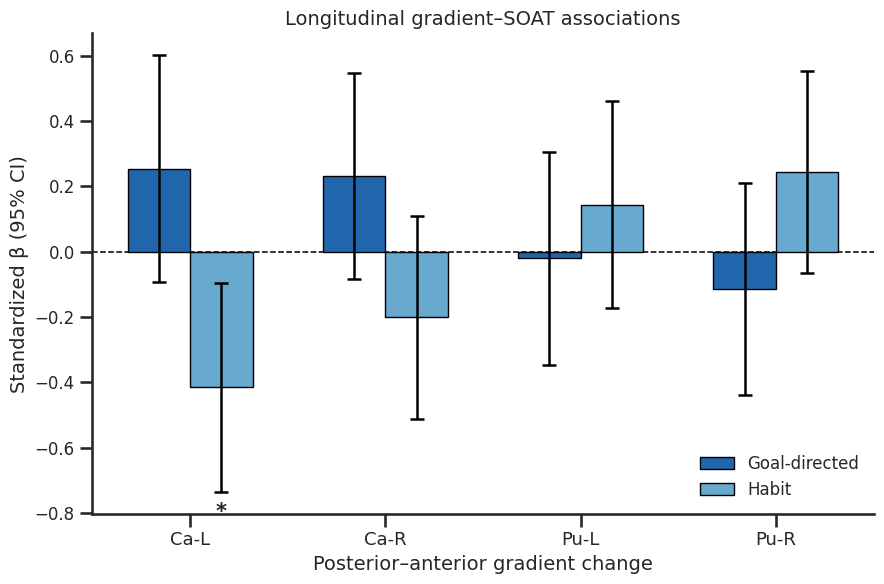

,gradient,behavior,n,beta,se,ci_low,ci_high,p,p_fdr
3,gradient_caudate_L,P3_goal_directed_index,40,0.253620,0.171579,-0.094032,0.601271,0.147829,0.295659
0,gradient_caudate_L,P3_habit_index,40,-0.415967,0.158361,-0.736837,-0.095096,0.012470,0.099761
2,gradient_caudate_R,P3_goal_directed_index,40,0.232834,0.155659,-0.082562,0.548229,0.143189,0.295659
4,gradient_caudate_R,P3_habit_index,40,-0.201114,0.153204,-0.511535,0.109307,0.197362,0.315778
7,gradient_putamen_L,P3_goal_directed_index,40,-0.020361,0.161129,-0.346839,0.306118,0.900130,0.900130
5,gradient_putamen_L,P3_habit_index,40,0.144043,0.155750,-0.171536,0.459621,0.361044,0.481393
6,gradient_putamen_R,P3_goal_directed_index,40,-0.114580,0.159847,-0.438460,0.209301,0.477992,0.546277
1,gradient_putamen_R,P3_habit_index,40,0.243332,0.152128,-0.064909,0.551573,0.118211,0.295659


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

gradients = [
    "gradient_caudate_L",
    "gradient_caudate_R",
    "gradient_putamen_L",
    "gradient_putamen_R"
]

soat_vars = [
    "P3_goal_directed_index",
    "P3_habit_index"
]

plot_soat = res_grad_soat_delta[
    res_grad_soat_delta["gradient"].isin(gradients) &
    res_grad_soat_delta["behavior"].isin(soat_vars)
].copy()

plot_soat["beta"] = pd.to_numeric(
    plot_soat["beta_delta_gradient_z"], errors="coerce"
)

plot_soat["p"] = pd.to_numeric(plot_soat["p"], errors="coerce")
plot_soat["p_fdr"] = pd.to_numeric(plot_soat["p_fdr"], errors="coerce")

plot_soat["df_resid"] = plot_soat["n"] - 3

plot_soat["t_abs"] = t.isf(
    plot_soat["p"].clip(lower=1e-300, upper=1 - 1e-12) / 2,
    plot_soat["df_resid"]
)

plot_soat["se"] = (
    plot_soat["beta"].abs() / plot_soat["t_abs"]
)

plot_soat["t_critical"] = t.ppf(
    0.975, plot_soat["df_resid"]
)

plot_soat["ci_low"] = (
    plot_soat["beta"] -
    plot_soat["t_critical"] * plot_soat["se"]
)

plot_soat["ci_high"] = (
    plot_soat["beta"] +
    plot_soat["t_critical"] * plot_soat["se"]
)

gradient_labels = {
    "gradient_caudate_L": "Ca-L",
    "gradient_caudate_R": "Ca-R",
    "gradient_putamen_L": "Pu-L",
    "gradient_putamen_R": "Pu-R"
}

soat_labels = {
    "P3_goal_directed_index": "Goal-directed",
    "P3_habit_index": "Habit"
}

plot_soat["gradient_label"] = plot_soat["gradient"].map(gradient_labels)
plot_soat["soat_label"] = plot_soat["behavior"].map(soat_labels)

gradient_order = ["Ca-L", "Ca-R", "Pu-L", "Pu-R"]
soat_order = ["Goal-directed", "Habit"]

colors = {
    "Goal-directed": "#2166ac",
    "Habit": "#67a9cf"
}

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(gradient_order))
width = 0.32

for i, soat in enumerate(soat_order):

    temp = (
        plot_soat[plot_soat["soat_label"] == soat]
        .set_index("gradient_label")
        .reindex(gradient_order)
    )

    xpos = x + (i - 0.5) * width

    ax.bar(
        xpos,
        temp["beta"],
        width=width,
        color=colors[soat],
        edgecolor="black",
        linewidth=1,
        label=soat,
        zorder=2
    )

    lower = temp["beta"] - temp["ci_low"]
    upper = temp["ci_high"] - temp["beta"]

    ax.errorbar(
        xpos,
        temp["beta"],
        yerr=np.vstack([lower, upper]),
        fmt="none",
        ecolor="black",
        elinewidth=1.8,
        capsize=5,
        capthick=1.8,
        zorder=3
    )

    for xx, (_, row) in zip(xpos, temp.iterrows()):

        if pd.notna(row["p_fdr"]) and row["p_fdr"] < 0.05:
            sig = "**"
        elif pd.notna(row["p"]) and row["p"] < 0.05:
            sig = "*"
        else:
            sig = ""

        if sig:
            ypos = (
                row["ci_high"] + 0.03
                if row["beta"] >= 0
                else row["ci_low"] - 0.03
            )

            ax.text(
                xx,
                ypos,
                sig,
                ha="center",
                va="bottom" if row["beta"] >= 0 else "top",
                fontsize=15,
                fontweight="bold"
            )

ax.axhline(0, color="black", linewidth=1.1, linestyle="--", zorder=1)

ax.set_xticks(x)
ax.set_xticklabels(gradient_order, fontsize=13)

ax.set_ylabel("Standardized β (95% CI)", fontsize=14)
ax.set_xlabel("Posterior–anterior gradient change", fontsize=14)
ax.set_title("Longitudinal gradient–SOAT associations", fontsize=14)

ax.tick_params(axis="y", labelsize=12)
ax.grid(False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, fontsize=12)

plt.tight_layout()

plt.savefig(
    "SOAT_goal_habit_gradients_bar_CI.svg",
    format="svg",
    bbox_inches="tight"
)

plt.savefig(
    "SOAT_goal_habit_gradients_bar_CI.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

display(
    plot_soat[
        [
            "gradient",
            "behavior",
            "n",
            "beta",
            "se",
            "ci_low",
            "ci_high",
            "p",
            "p_fdr"
        ]
    ].sort_values(["gradient", "behavior"])
)

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

df=df_soat_grad.copy()
df=df[df["group"]=="AN"].copy()
df["subject"]=df["subject"].astype(int)
df["session"]=df["session"].astype(int)

behavior_vars=["P3_goal_directed_index","P3_habit_index","P3_go_response_devalued","P3_correct_inhibition_devalued"]
behavior_vars=[v for v in behavior_vars if v in df.columns]

gradient_cols=["gradient_putamen_R","gradient_putamen_L","gradient_caudate_R","gradient_caudate_L"]
gradient_cols=[g for g in gradient_cols if g in df.columns]

def run_cross_sectional(df_session):
    results=[]
    for grad in gradient_cols:
        for beh in behavior_vars:
            dfi=df_session[[beh,grad,"age"]].dropna().copy()
            if len(dfi)<10:
                results.append({"gradient":grad,"behavior":beh,"n":len(dfi),"error":"Too few observations"})
                continue
            dfi["gradient_z"]=(dfi[grad]-dfi[grad].mean())/dfi[grad].std(ddof=1)
            dfi["behavior_z"]=(dfi[beh]-dfi[beh].mean())/dfi[beh].std(ddof=1)
            X=sm.add_constant(dfi[["gradient_z","age"]].astype(float))
            y=dfi["behavior_z"].astype(float)
            model=sm.OLS(y,X).fit()
            results.append({"gradient":grad,"behavior":beh,"n":len(dfi),"beta_gradient":model.params["gradient_z"],"p":model.pvalues["gradient_z"],"R2":model.rsquared,"adj_R2":model.rsquared_adj,"beta_age":model.params["age"],"p_age":model.pvalues["age"],"error":np.nan})
    res=pd.DataFrame(results)
    mask=res["p"].notna()&np.isfinite(res["p"])
    res.loc[mask,"p_fdr"]=multipletests(res.loc[mask,"p"],method="fdr_bh")[1]
    return res.sort_values("p",na_position="last")

print("SESSION 1")
res_s1=run_cross_sectional(df[df["session"]==1])
display(res_s1[res_s1["p"]<0.05])

print("SESSION 2")
res_s2=run_cross_sectional(df[df["session"]==2])
display(res_s2[res_s2["p"]<0.05])

print("Top Session 1")
display(res_s1.head(20))

print("Top Session 2")
display(res_s2.head(20))

SESSION 1


,gradient,behavior,n,beta_gradient,p,R2,adj_R2,beta_age,p_age,error,p_fdr


SESSION 2


,gradient,behavior,n,beta_gradient,p,R2,adj_R2,beta_age,p_age,error,p_fdr


Top Session 1


,gradient,behavior,n,beta_gradient,p,R2,adj_R2,beta_age,p_age,error,p_fdr
1,gradient_putamen_R,P3_habit_index,41,-0.212748,0.171816,0.139810,0.094537,0.025064,0.082076,NaN,0.914786
2,gradient_putamen_R,P3_go_response_devalued,41,-0.212748,0.171816,0.139810,0.094537,0.025064,0.082076,NaN,0.914786
3,gradient_putamen_R,P3_correct_inhibition_devalued,41,0.212748,0.171816,0.139810,0.094537,-0.025064,0.082076,NaN,0.914786
0,gradient_putamen_R,P3_goal_directed_index,41,0.130948,0.361604,0.258797,0.219786,-0.043122,0.002049,NaN,0.914786
8,gradient_caudate_R,P3_goal_directed_index,41,0.087950,0.541735,0.249650,0.210158,-0.043757,0.001914,NaN,0.914786
4,gradient_putamen_L,P3_goal_directed_index,41,-0.055007,0.700286,0.245152,0.205423,-0.045768,0.001161,NaN,0.914786
7,gradient_putamen_L,P3_correct_inhibition_devalued,41,0.050758,0.745097,0.098451,0.051001,-0.027930,0.057162,NaN,0.914786
5,gradient_putamen_L,P3_habit_index,41,-0.050758,0.745097,0.098451,0.051001,0.027930,0.057162,NaN,0.914786
6,gradient_putamen_L,P3_go_response_devalued,41,-0.050758,0.745097,0.098451,0.051001,0.027930,0.057162,NaN,0.914786
15,gradient_caudate_L,P3_correct_inhibition_devalued,41,0.051804,0.753734,0.098276,0.050816,-0.026820,0.082920,NaN,0.914786


Top Session 2


,gradient,behavior,n,beta_gradient,p,R2,adj_R2,beta_age,p_age,error,p_fdr
0,gradient_putamen_R,P3_goal_directed_index,40,0.131867,0.307764,0.398608,0.366100,-0.055974,0.000024,NaN,0.776568
4,gradient_putamen_L,P3_goal_directed_index,40,0.117413,0.374743,0.394436,0.361703,-0.053995,0.000058,NaN,0.776568
12,gradient_caudate_L,P3_goal_directed_index,40,-0.088660,0.498959,0.388925,0.355894,-0.057324,0.000022,NaN,0.776568
5,gradient_putamen_L,P3_habit_index,40,-0.089301,0.521227,0.325765,0.289320,0.049658,0.000330,NaN,0.776568
6,gradient_putamen_L,P3_go_response_devalued,40,-0.089301,0.521227,0.325765,0.289320,0.049658,0.000330,NaN,0.776568
7,gradient_putamen_L,P3_correct_inhibition_devalued,40,0.089301,0.521227,0.325765,0.289320,-0.049658,0.000330,NaN,0.776568
1,gradient_putamen_R,P3_habit_index,40,-0.077534,0.569716,0.324132,0.287598,0.051197,0.000180,NaN,0.776568
3,gradient_putamen_R,P3_correct_inhibition_devalued,40,0.077534,0.569716,0.324132,0.287598,-0.051197,0.000180,NaN,0.776568
2,gradient_putamen_R,P3_go_response_devalued,40,-0.077534,0.569716,0.324132,0.287598,0.051197,0.000180,NaN,0.776568
9,gradient_caudate_R,P3_habit_index,40,-0.075976,0.582426,0.323746,0.287192,0.050207,0.000268,NaN,0.776568


In [ ]:
clinical_gm_df=clinical_df.merge(df_roi_wide, on=["study_id", "session","group", "remission_v3","subject"], how="left")
clinical_gm_df

,group,study_id,session,ln_AG,ln_DAG,ln_AG_DAG_tot,ln_AG_DAG_ratio,ln_leap2,ln_AG_leap2_ratio,delay_hospV1_prev,...,habits_yn,BMI,remission,duree_years,age_at_onset,edi2_total,Vgm_Left_Caudate,Vgm_Left_Putamen,Vgm_Right_Caudate,Vgm_Right_Putamen
0,HC,1.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,18.7,NaN,NaN,NaN,11.0,NaN,NaN,NaN,NaN
1,HC,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN
2,AN,2.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,17.6,NaN,1.416667,16.583333,32.0,NaN,NaN,NaN,NaN
3,AN,2.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,21.9,NaN,1.416667,16.583333,10.0,NaN,NaN,NaN,NaN
4,AN,2.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,17.5,0.0,1.416667,16.583333,48.0,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
500,AN,246.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,15.2,NaN,12.166667,35.833333,125.0,NaN,NaN,NaN,NaN
501,AN,247.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,13.7,NaN,21.250000,9.750000,73.0,NaN,NaN,NaN,NaN
502,AN,248.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,14.1,NaN,4.250000,17.750000,69.0,NaN,NaN,NaN,NaN
503,AN,249.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,1.0,12.4,NaN,6.333333,11.666667,121.0,NaN,NaN,NaN,NaN


In [ ]:
clinical_gm_df.rename(columns={"Vgm_Left_Caudate":"caudate_gm_L","Vgm_Right_Caudate":"caudate_gm_R","Vgm_Left_Putamen":"putamen_gm_L","Vgm_Right_Putamen":"putamen_gm_R"}, inplace=True)

clinical_gm_df["ratio_R"]= clinical_gm_df["caudate_gm_R"] / clinical_gm_df["putamen_gm_R"]
clinical_gm_df["ratio_L"]= clinical_gm_df["caudate_gm_L"] / clinical_gm_df["putamen_gm_L"]
clinical_gm_df

/tmp/ipykernel_9402/3620381029.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  clinical_gm_df["ratio_R"]= clinical_gm_df["caudate_gm_R"] / clinical_gm_df["putamen_gm_R"]
/tmp/ipykernel_9402/3620381029.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  clinical_gm_df["ratio_L"]= clinical_gm_df["caudate_gm_L"] / clinical_gm_df["putamen_gm_L"]


,group,study_id,session,ln_AG,ln_DAG,ln_AG_DAG_tot,ln_AG_DAG_ratio,ln_leap2,ln_AG_leap2_ratio,delay_hospV1_prev,...,remission,duree_years,age_at_onset,edi2_total,caudate_gm_L,putamen_gm_L,caudate_gm_R,putamen_gm_R,ratio_R,ratio_L
0,HC,1.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,11.0,NaN,NaN,NaN,NaN,NaN,NaN
1,HC,1.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,AN,2.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.416667,16.583333,32.0,NaN,NaN,NaN,NaN,NaN,NaN
3,AN,2.0,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,1.416667,16.583333,10.0,NaN,NaN,NaN,NaN,NaN,NaN
4,AN,2.0,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,1.416667,16.583333,48.0,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
500,AN,246.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,12.166667,35.833333,125.0,NaN,NaN,NaN,NaN,NaN,NaN
501,AN,247.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,21.250000,9.750000,73.0,NaN,NaN,NaN,NaN,NaN,NaN
502,AN,248.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,4.250000,17.750000,69.0,NaN,NaN,NaN,NaN,NaN,NaN
503,AN,249.0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,6.333333,11.666667,121.0,NaN,NaN,NaN,NaN,NaN,NaN


#### NMH13

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests

df_long=clinical_gm_df[(clinical_gm_df["group"]=="AN")&(clinical_gm_df["session"].isin([1,2]))].copy()

clinical_vars=['ddt_p1_k','ddt_p1_m']
gradient_cols=["gradient_putamen_R","gradient_putamen_L","gradient_caudate_R","gradient_caudate_L"]

clinical_vars=[v for v in clinical_vars if v in df_long.columns]
gradient_cols=[g for g in gradient_cols if g in df_long.columns]

df_wide=df_long.pivot_table(index="study_id",columns="session",values=clinical_vars+gradient_cols)
df_wide.columns=[f"{var}_s{int(session)}" for var,session in df_wide.columns]
df_wide=df_wide.reset_index()

for var in clinical_vars+gradient_cols:
    if f"{var}_s1" in df_wide.columns and f"{var}_s2" in df_wide.columns: df_wide[f"delta_{var}"]=df_wide[f"{var}_s2"]-df_wide[f"{var}_s1"]

df_cov=df_long[df_long["session"]==1][["study_id","age","TIV_ml"]].drop_duplicates("study_id")
df_delta_clinical=df_wide.merge(df_cov,on="study_id",how="left")

results=[]

for grad in gradient_cols:
    for clinical in clinical_vars:
        delta_grad=f"delta_{grad}"
        delta_clinical=f"delta_{clinical}"
        if delta_grad not in df_delta_clinical.columns or delta_clinical not in df_delta_clinical.columns: continue
        dfi=df_delta_clinical[[delta_grad,delta_clinical,"age","TIV_ml"]].apply(pd.to_numeric,errors="coerce").dropna().copy()
        if len(dfi)<10:
            results.append({"gradient":grad,"clinical":clinical,"n":len(dfi),"error":"Too few observations"})
            continue
        dfi["delta_gradient_z"]=(dfi[delta_grad]-dfi[delta_grad].mean())/dfi[delta_grad].std(ddof=1)
        dfi["delta_clinical_z"]=(dfi[delta_clinical]-dfi[delta_clinical].mean())/dfi[delta_clinical].std(ddof=1)
        try:
            X=sm.add_constant(dfi[["delta_gradient_z","age","TIV_ml"]].astype(float))
            model=sm.OLS(dfi["delta_clinical_z"].astype(float),X).fit()
            results.append({"gradient":grad,"clinical":clinical,"n":len(dfi),"beta_delta_gradient_z":model.params["delta_gradient_z"],"p":model.pvalues["delta_gradient_z"],"R2":model.rsquared,"adj_R2":model.rsquared_adj,"p_model":model.f_pvalue,"beta_age":model.params["age"],"p_age":model.pvalues["age"],"beta_TIV":model.params["TIV_ml"],"p_TIV":model.pvalues["TIV_ml"],"error":np.nan})
        except Exception as e:
            results.append({"gradient":grad,"clinical":clinical,"n":len(dfi),"error":str(e)})

res_grad_clinical_delta=pd.DataFrame(results).sort_values("p",na_position="last").reset_index(drop=True)
mask=res_grad_clinical_delta["p"].notna()&np.isfinite(res_grad_clinical_delta["p"])
res_grad_clinical_delta.loc[mask,"p_fdr"]=multipletests(res_grad_clinical_delta.loc[mask,"p"],method="fdr_bh")[1]

display(res_grad_clinical_delta)
display(res_grad_clinical_delta[res_grad_clinical_delta["p"]<0.05])
display(res_grad_clinical_delta[res_grad_clinical_delta["p_fdr"]<0.05])

,gradient,clinical,n,beta_delta_gradient_z,p,R2,adj_R2,p_model,beta_age,p_age,beta_TIV,p_TIV,error,p_fdr
0,gradient_putamen_L,ddt_p1_m,40,0.395600,0.012582,0.197606,0.130740,0.045347,-0.013378,0.336498,0.000757,0.648549,NaN,0.100655
1,gradient_putamen_R,ddt_p1_m,40,0.314415,0.050825,0.141197,0.069630,0.135443,-0.021521,0.138224,0.000546,0.750564,NaN,0.203298
2,gradient_putamen_R,ddt_p1_k,40,0.129278,0.438143,0.035838,-0.044509,0.721590,-0.010491,0.489965,0.000971,0.593816,NaN,0.873545
3,gradient_caudate_R,ddt_p1_k,40,0.073940,0.657144,0.024800,-0.056466,0.821455,-0.009530,0.530604,0.001030,0.574178,NaN,0.873545
4,gradient_caudate_L,ddt_p1_m,40,0.049899,0.783200,0.045850,-0.033663,0.634108,-0.019466,0.223993,0.000746,0.692214,NaN,0.873545
5,gradient_putamen_L,ddt_p1_k,40,0.031967,0.848740,0.020378,-0.061257,0.861065,-0.008678,0.570937,0.001007,0.583620,NaN,0.873545
6,gradient_caudate_L,ddt_p1_k,40,0.034621,0.850519,0.020354,-0.061283,0.861275,-0.010053,0.532282,0.001094,0.567012,NaN,0.873545
7,gradient_caudate_R,ddt_p1_m,40,0.026212,0.873545,0.044495,-0.035131,0.645650,-0.018195,0.229923,0.000614,0.734640,NaN,0.873545


,gradient,clinical,n,beta_delta_gradient_z,p,R2,adj_R2,p_model,beta_age,p_age,beta_TIV,p_TIV,error,p_fdr
0,gradient_putamen_L,ddt_p1_m,40,0.3956,0.012582,0.197606,0.13074,0.045347,-0.013378,0.336498,0.000757,0.648549,NaN,0.100655


,gradient,clinical,n,beta_delta_gradient_z,p,R2,adj_R2,p_model,beta_age,p_age,beta_TIV,p_TIV,error,p_fdr


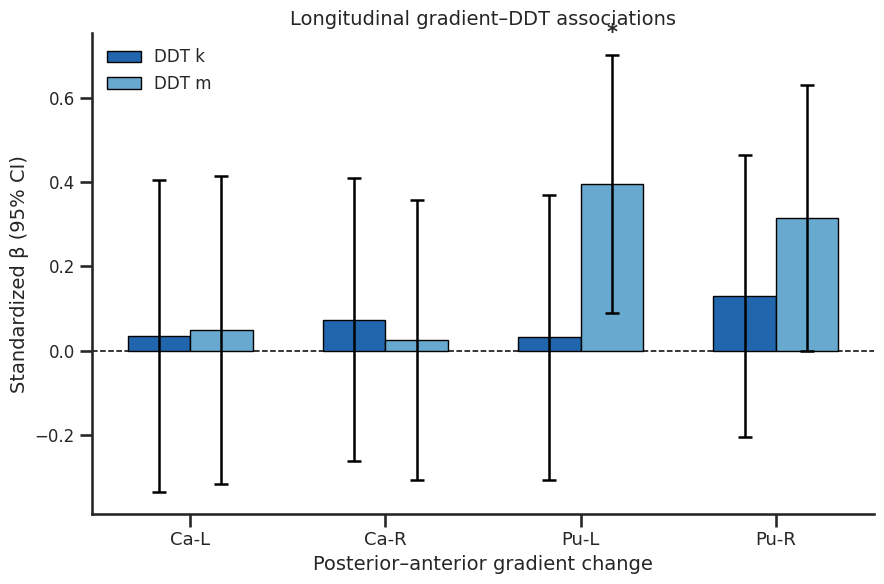

,gradient,clinical,n,beta,se,ci_low,ci_high,p,p_fdr
6,gradient_caudate_L,ddt_p1_k,40,0.034621,0.182389,-0.335282,0.404523,0.850519,0.873545
4,gradient_caudate_L,ddt_p1_m,40,0.049899,0.180000,-0.315159,0.414957,0.783200,0.873545
3,gradient_caudate_R,ddt_p1_k,40,0.073940,0.165203,-0.261107,0.408987,0.657144,0.873545
7,gradient_caudate_R,ddt_p1_m,40,0.026212,0.163526,-0.305434,0.357859,0.873545,0.873545
5,gradient_putamen_L,ddt_p1_k,40,0.031967,0.166405,-0.305517,0.369452,0.848740,0.873545
0,gradient_putamen_L,ddt_p1_m,40,0.395600,0.150602,0.090166,0.701035,0.012582,0.100655
2,gradient_putamen_R,ddt_p1_k,40,0.129278,0.164886,-0.205127,0.463683,0.438143,0.873545
1,gradient_putamen_R,ddt_p1_m,40,0.314415,0.155617,-0.001190,0.630021,0.050825,0.203298


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

gradients = [
    "gradient_caudate_L",
    "gradient_caudate_R",
    "gradient_putamen_L",
    "gradient_putamen_R"
]

ddt_vars = ["ddt_p1_k", "ddt_p1_m"]

plot_ddt = res_grad_clinical_delta[
    res_grad_clinical_delta["gradient"].isin(gradients) &
    res_grad_clinical_delta["clinical"].isin(ddt_vars)
].copy()

plot_ddt["beta"] = pd.to_numeric(
    plot_ddt["beta_delta_gradient_z"], errors="coerce"
)

plot_ddt["p"] = pd.to_numeric(plot_ddt["p"], errors="coerce")
plot_ddt["p_fdr"] = pd.to_numeric(plot_ddt["p_fdr"], errors="coerce")

plot_ddt["df_resid"] = plot_ddt["n"] - 4

plot_ddt["t_abs"] = t.isf(
    plot_ddt["p"].clip(lower=1e-300, upper=1 - 1e-12) / 2,
    plot_ddt["df_resid"]
)

plot_ddt["se"] = (
    plot_ddt["beta"].abs() / plot_ddt["t_abs"]
)

plot_ddt["t_critical"] = t.ppf(
    0.975, plot_ddt["df_resid"]
)

plot_ddt["ci_low"] = (
    plot_ddt["beta"] -
    plot_ddt["t_critical"] * plot_ddt["se"]
)

plot_ddt["ci_high"] = (
    plot_ddt["beta"] +
    plot_ddt["t_critical"] * plot_ddt["se"]
)

gradient_labels = {
    "gradient_caudate_L": "Ca-L",
    "gradient_caudate_R": "Ca-R",
    "gradient_putamen_L": "Pu-L",
    "gradient_putamen_R": "Pu-R"
}

ddt_labels = {
    "ddt_p1_k": "DDT k",
    "ddt_p1_m": "DDT m"
}

plot_ddt["gradient_label"] = plot_ddt["gradient"].map(gradient_labels)
plot_ddt["ddt_label"] = plot_ddt["clinical"].map(ddt_labels)

gradient_order = ["Ca-L", "Ca-R", "Pu-L", "Pu-R"]
ddt_order = ["DDT k", "DDT m"]

colors = {
    "DDT k": "#2166ac",
    "DDT m": "#67a9cf"
}

fig, ax = plt.subplots(figsize=(9, 6))

x = np.arange(len(gradient_order))
width = 0.32

for i, ddt in enumerate(ddt_order):

    temp = (
        plot_ddt[plot_ddt["ddt_label"] == ddt]
        .set_index("gradient_label")
        .reindex(gradient_order)
    )

    xpos = x + (i - 0.5) * width

    ax.bar(
        xpos,
        temp["beta"],
        width=width,
        color=colors[ddt],
        edgecolor="black",
        linewidth=1,
        label=ddt,
        zorder=2
    )

    lower = temp["beta"] - temp["ci_low"]
    upper = temp["ci_high"] - temp["beta"]

    ax.errorbar(
        xpos,
        temp["beta"],
        yerr=np.vstack([lower, upper]),
        fmt="none",
        ecolor="black",
        elinewidth=1.8,
        capsize=5,
        capthick=1.8,
        zorder=3
    )

    for xx, (_, row) in zip(xpos, temp.iterrows()):

        if pd.notna(row["p_fdr"]) and row["p_fdr"] < 0.05:
            sig = "**"
        elif pd.notna(row["p"]) and row["p"] < 0.05:
            sig = "*"
        else:
            sig = ""

        if sig:
            ypos = (
                row["ci_high"] + 0.03
                if row["beta"] >= 0
                else row["ci_low"] - 0.03
            )

            ax.text(
                xx,
                ypos,
                sig,
                ha="center",
                va="bottom" if row["beta"] >= 0 else "top",
                fontsize=15,
                fontweight="bold"
            )

ax.axhline(0, color="black", linewidth=1.1, linestyle="--", zorder=1)

ax.set_xticks(x)
ax.set_xticklabels(gradient_order, fontsize=13)

ax.set_ylabel("Standardized β (95% CI)", fontsize=14)
ax.set_xlabel("Posterior–anterior gradient change", fontsize=14)
ax.set_title("Longitudinal gradient–DDT associations", fontsize=14)

ax.tick_params(axis="y", labelsize=12)
ax.grid(False)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(frameon=False, fontsize=12)

plt.tight_layout()

plt.savefig(
    "DDT_k_m_striatal_gradients_delta_CI.svg",
    format="svg",
    bbox_inches="tight"
)

plt.savefig(
    "DDT_k_m_striatal_gradients_delta_CI.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

display(
    plot_ddt[
        [
            "gradient",
            "clinical",
            "n",
            "beta",
            "se",
            "ci_low",
            "ci_high",
            "p",
            "p_fdr"
        ]
    ].sort_values(["gradient", "clinical"])
)

In [ ]:
print(
    res_grad_clinical_delta[
        res_grad_clinical_delta["clinical"].str.contains(
            "goal|habit",
            case=False,
            na=False
        )
    ][
        ["gradient", "clinical", "beta_delta_gradient_z", "p", "p_fdr"]
    ]
)

               gradient                           clinical  \
6    gradient_caudate_L  SOAT_specific_goal_directed_index   
9    gradient_caudate_L                     P3_habit_index   
11   gradient_caudate_L          SOAT_specific_habit_index   
37   gradient_putamen_L  SOAT_specific_goal_directed_index   
38   gradient_putamen_R  SOAT_specific_goal_directed_index   
50     gradient_ratio_R  SOAT_specific_goal_directed_index   
59   gradient_putamen_R                     P3_habit_index   
68   gradient_putamen_R          SOAT_specific_habit_index   
73   gradient_caudate_R             P3_goal_directed_index   
74   gradient_caudate_L             P3_goal_directed_index   
76   gradient_caudate_R  SOAT_specific_goal_directed_index   
80              ratio_L  SOAT_specific_goal_directed_index   
88     gradient_ratio_R             P3_goal_directed_index   
98   gradient_caudate_R                     P3_habit_index   
100    gradient_ratio_L  SOAT_specific_goal_directed_index   
112     

In [ ]:
mri_vars = [
    "gradient_caudate_L",
    "gradient_caudate_R",
    "gradient_putamen_L",
    "gradient_putamen_R",
    "gradient_ratio_L",
    "gradient_ratio_R"
]

print(
    df_long[
        (df_long["group"] == "AN") &
        (df_long["session"].isin([1, 2]))
    ]
    .groupby("session")["subject"]
    .nunique()
)

session
1    71
2    48
Name: subject, dtype: int64


#### NMH20

MRI sample before checking DDT missing values
---------------------------------------------
AN longitudinal MRI subjects: 40
HC V1 MRI subjects: 28

Subjects retained in plot_df
group  session
AN     1          40
       2          40
HC     1          28
Name: study_id, dtype: int64

Available DDT values

P3_goal_directed_index
Group
AN V1    40
AN V2    40
HC V1    28
Name: study_id, dtype: int64

P3_habit_index
Group
AN V1    40
AN V2    40
HC V1    28
Name: study_id, dtype: int64


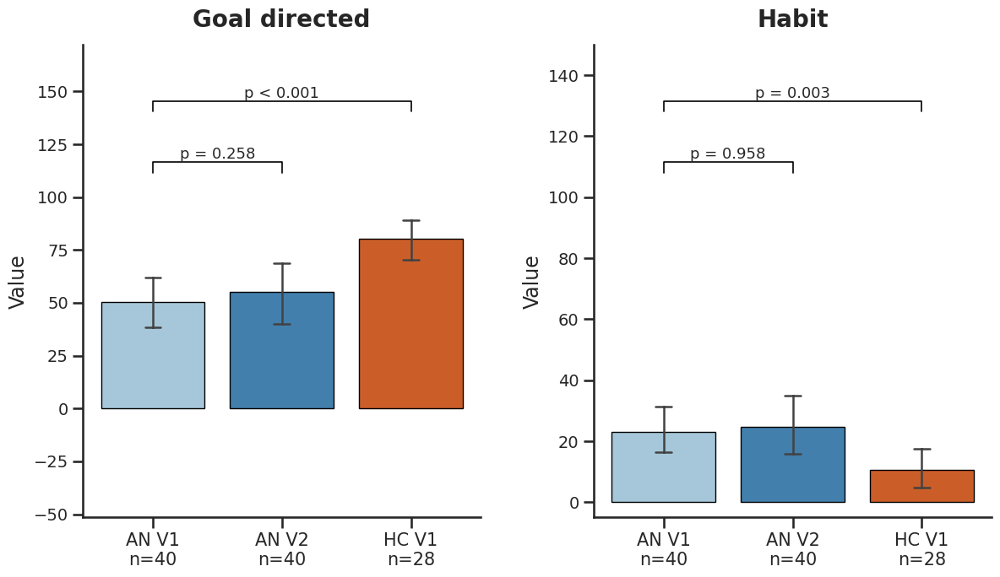

,variable,comparison,AN_V1_n,AN_V2_n,statistic,p,HC_V1_n
0,Goal directed,AN V1 vs AN V2,40,40.0,309.0,0.258321,NaN
1,Goal directed,AN V1 vs HC V1,40,NaN,294.5,0.000954,28.0
2,Habit,AN V1 vs AN V2,40,40.0,348.0,0.957889,NaN
3,Habit,AN V1 vs HC V1,40,NaN,796.5,0.003179,28.0


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, mannwhitneyu

# ============================================================
# VARIABLES
# ============================================================

ddt_vars = [
    "P3_goal_directed_index",
    "P3_habit_index"
]

gradient_cols = [
    "gradient_putamen_R",
    "gradient_putamen_L",
    "gradient_caudate_R",
    "gradient_caudate_L",
    "gradient_ratio_R",
    "gradient_ratio_L"
]

titles = {
    "P3_goal_directed_index": "Goal directed",
    "P3_habit_index": "Habit"
}

palette = {
    "AN V1": "#9ecae1",
    "AN V2": "#3182bd",
    "HC V1": "#e6550d"
}

order = [
    "AN V1",
    "AN V2",
    "HC V1"
]

# ============================================================
# DATA
# ============================================================

tmp = clinical_gm_df[
    (
        (clinical_gm_df["group"] == "AN")
        & (clinical_gm_df["session"].isin([1, 2]))
    )
    |
    (
        (clinical_gm_df["group"] == "HC")
        & (clinical_gm_df["session"] == 1)
    )
].copy()

# One row per subject/session
tmp = tmp.drop_duplicates(
    subset=["study_id", "session"],
    keep="first"
)

# Convert DDT variables to numeric
for var in ddt_vars:
    tmp[var] = pd.to_numeric(
        tmp[var],
        errors="coerce"
    )

# ============================================================
# IDENTIFY ROWS WITH MRI
# ============================================================

tmp["has_mri"] = (
    tmp[gradient_cols]
    .notna()
    .any(axis=1)
)

# ============================================================
# AN: MRI AT BOTH V1 AND V2
# ============================================================

an_mri = tmp[
    (tmp["group"] == "AN")
    & (tmp["session"].isin([1, 2]))
][
    ["study_id", "session", "has_mri"]
].copy()

an_mri_wide = (
    an_mri
    .pivot(
        index="study_id",
        columns="session",
        values="has_mri"
    )
)

# Make sure both session columns exist
if 1 not in an_mri_wide.columns:
    an_mri_wide[1] = False

if 2 not in an_mri_wide.columns:
    an_mri_wide[2] = False

an_mri_subjects = an_mri_wide[
    (an_mri_wide[1] == True)
    & (an_mri_wide[2] == True)
].index

# ============================================================
# HC: MRI AT V1
# ============================================================

hc_mri_subjects = (
    tmp.loc[
        (tmp["group"] == "HC")
        & (tmp["session"] == 1)
        & (tmp["has_mri"]),
        "study_id"
    ]
    .dropna()
    .unique()
)

# ============================================================
# CHECK MRI SAMPLE
# ============================================================

print("MRI sample before checking DDT missing values")
print("---------------------------------------------")
print("AN longitudinal MRI subjects:", len(an_mri_subjects))
print("HC V1 MRI subjects:", len(hc_mri_subjects))

# ============================================================
# KEEP ONLY MRI SUBJECTS
# ============================================================

plot_df = tmp[
    (
        (tmp["group"] == "AN")
        & (tmp["study_id"].isin(an_mri_subjects))
        & (tmp["session"].isin([1, 2]))
    )
    |
    (
        (tmp["group"] == "HC")
        & (tmp["study_id"].isin(hc_mri_subjects))
        & (tmp["session"] == 1)
    )
].copy()

# ============================================================
# GROUP LABEL
# ============================================================

plot_df["Group"] = np.where(
    plot_df["group"] == "HC",
    "HC V1",
    "AN V" + plot_df["session"].astype(int).astype(str)
)

# ============================================================
# CHECK FINAL MRI SAMPLE
# ============================================================

print("\nSubjects retained in plot_df")
print(
    plot_df.groupby(
        ["group", "session"]
    )["study_id"].nunique()
)

print("\nAvailable DDT values")

for var in ddt_vars:

    print(f"\n{var}")

    print(
        plot_df
        .dropna(subset=[var])
        .groupby("Group")["study_id"]
        .nunique()
        .reindex(order)
    )

# ============================================================
# P-VALUE BRACKET
# ============================================================

def add_pvalue(ax, x1, x2, y, h, p):

    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        color="black",
        linewidth=1.2
    )

    if p < 0.001:
        label = "p < 0.001"
    else:
        label = f"p = {p:.3f}"

    ax.text(
        (x1 + x2) / 2,
        y + h,
        label,
        ha="center",
        va="bottom",
        fontsize=13
    )

# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 7),
    sharey=False
)

stats_results = []

for ax, var in zip(axes, ddt_vars):

    # ========================================================
    # SAMPLE SIZE
    # ========================================================

    n_by_group = {
        group: plot_df.loc[
            plot_df["Group"] == group,
            var
        ].notna().sum()
        for group in order
    }

    # ========================================================
    # AN V1 vs AN V2 — PAIRED
    # ========================================================

    pair = (
        plot_df[
            (plot_df["group"] == "AN")
            & (plot_df["session"].isin([1, 2]))
        ][
            ["study_id", "session", var]
        ]
        .dropna(subset=[var])
        .pivot(
            index="study_id",
            columns="session",
            values=var
        )
    )

    if 1 in pair.columns and 2 in pair.columns:

        paired = (
            pair[[1, 2]]
            .dropna()
            .astype(float)
        )

        if len(paired) > 0:

            stat_v1_v2, p_v1_v2 = wilcoxon(
                paired[1],
                paired[2]
            )

        else:

            stat_v1_v2 = np.nan
            p_v1_v2 = np.nan

    else:

        paired = pd.DataFrame()
        stat_v1_v2 = np.nan
        p_v1_v2 = np.nan

    # ========================================================
    # AN V1 vs HC V1 — INDEPENDENT
    # ========================================================

    an_v1 = pd.to_numeric(
        plot_df.loc[
            plot_df["Group"] == "AN V1",
            var
        ],
        errors="coerce"
    ).dropna().astype(float)

    hc_v1 = pd.to_numeric(
        plot_df.loc[
            plot_df["Group"] == "HC V1",
            var
        ],
        errors="coerce"
    ).dropna().astype(float)

    if len(an_v1) > 0 and len(hc_v1) > 0:

        stat_an_hc, p_an_hc = mannwhitneyu(
            an_v1,
            hc_v1,
            alternative="two-sided"
        )

    else:

        stat_an_hc = np.nan
        p_an_hc = np.nan

    # ========================================================
    # SAVE STATS
    # ========================================================

    stats_results.append({
        "variable": titles[var],
        "comparison": "AN V1 vs AN V2",
        "AN_V1_n": len(paired),
        "AN_V2_n": len(paired),
        "statistic": stat_v1_v2,
        "p": p_v1_v2
    })

    stats_results.append({
        "variable": titles[var],
        "comparison": "AN V1 vs HC V1",
        "AN_V1_n": len(an_v1),
        "HC_V1_n": len(hc_v1),
        "statistic": stat_an_hc,
        "p": p_an_hc
    })

    # ========================================================
    # BARPLOT + 95% CI
    # ========================================================

    sns.barplot(
        data=plot_df,
        x="Group",
        y=var,
        hue="Group",
        order=order,
        hue_order=order,
        palette=palette,
        errorbar=("ci", 95),
        capsize=0.12,
        err_kws={"linewidth": 1.8},
        edgecolor="black",
        linewidth=1,
        legend=False,
        ax=ax
    )

    # ========================================================
    # P-VALUES
    # ========================================================

    values = plot_df[var].dropna()

    if len(values) > 0:

        ymin = values.min()
        ymax = values.max()

        yrange = ymax - ymin

        if yrange == 0:
            yrange = 1

        y1 = ymax + 0.08 * yrange
        y2 = ymax + 0.28 * yrange
        h = 0.035 * yrange

        if pd.notna(p_v1_v2):

            add_pvalue(
                ax,
                0,
                1,
                y1,
                h,
                p_v1_v2
            )

        if pd.notna(p_an_hc):

            add_pvalue(
                ax,
                0,
                2,
                y2,
                h,
                p_an_hc
            )

        ax.set_ylim(
            ymin - 0.05 * yrange,
            ymax + 0.50 * yrange
        )

    # ========================================================
    # FORMAT
    # ========================================================

    ax.set_title(
        titles[var],
        fontsize=20,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("")

    ax.set_xticks(
        range(len(order))
    )

    ax.set_xticklabels(
        [
            f"{group}\nn={n_by_group[group]}"
            for group in order
        ],
        fontsize=15
    )

    ax.set_ylabel(
        "Value",
        fontsize=17
    )

    ax.tick_params(
        axis="y",
        labelsize=14
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ============================================================
# SAVE FIGURE
# ============================================================

plt.tight_layout(w_pad=3)

plt.savefig(
    "goal_habit_AN_V1_V2_HC_V1_MRI_sample.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "goal_habit_AN_V1_V2_HC_V1_MRI_sample.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# STATS TABLE
# ============================================================

ddt_stats = pd.DataFrame(stats_results)

display(ddt_stats)

#### NMH21

MRI sample before checking DDT missing values
---------------------------------------------
AN longitudinal MRI subjects: 40
HC V1 MRI subjects: 28

Subjects retained in plot_df
group  session
AN     1          40
       2          40
HC     1          28
Name: study_id, dtype: int64

Available DDT values

ddt_p1_k
Group
AN V1    40
AN V2    40
HC V1    28
Name: study_id, dtype: int64

ddt_p1_m
Group
AN V1    40
AN V2    40
HC V1    28
Name: study_id, dtype: int64


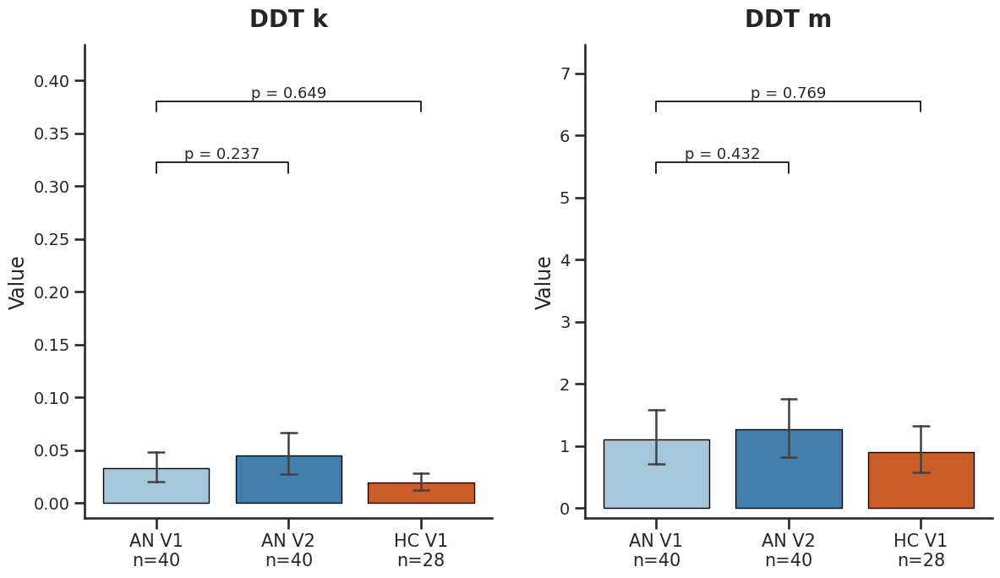

,variable,comparison,AN_V1_n,AN_V2_n,statistic,p,HC_V1_n
0,DDT k,AN V1 vs AN V2,40,40.0,321.0,0.237050,NaN
1,DDT k,AN V1 vs HC V1,40,NaN,597.0,0.649231,28.0
2,DDT m,AN V1 vs AN V2,40,40.0,222.0,0.432185,NaN
3,DDT m,AN V1 vs HC V1,40,NaN,536.0,0.768563,28.0


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon, mannwhitneyu

# ============================================================
# VARIABLES
# ============================================================

ddt_vars = [
    "ddt_p1_k",
    "ddt_p1_m"
]

gradient_cols = [
    "gradient_putamen_R",
    "gradient_putamen_L",
    "gradient_caudate_R",
    "gradient_caudate_L",
    "gradient_ratio_R",
    "gradient_ratio_L"
]

titles = {
    "ddt_p1_k": "DDT k",
    "ddt_p1_m": "DDT m"
}

palette = {
    "AN V1": "#9ecae1",
    "AN V2": "#3182bd",
    "HC V1": "#e6550d"
}

order = [
    "AN V1",
    "AN V2",
    "HC V1"
]

# ============================================================
# DATA
# ============================================================

tmp = clinical_gm_df[
    (
        (clinical_gm_df["group"] == "AN")
        & (clinical_gm_df["session"].isin([1, 2]))
    )
    |
    (
        (clinical_gm_df["group"] == "HC")
        & (clinical_gm_df["session"] == 1)
    )
].copy()

# One row per subject/session
tmp = tmp.drop_duplicates(
    subset=["study_id", "session"],
    keep="first"
)

# Convert DDT variables to numeric
for var in ddt_vars:
    tmp[var] = pd.to_numeric(
        tmp[var],
        errors="coerce"
    )

# ============================================================
# IDENTIFY ROWS WITH MRI
# ============================================================

tmp["has_mri"] = (
    tmp[gradient_cols]
    .notna()
    .any(axis=1)
)

# ============================================================
# AN: MRI AT BOTH V1 AND V2
# ============================================================

an_mri = tmp[
    (tmp["group"] == "AN")
    & (tmp["session"].isin([1, 2]))
][
    ["study_id", "session", "has_mri"]
].copy()

an_mri_wide = (
    an_mri
    .pivot(
        index="study_id",
        columns="session",
        values="has_mri"
    )
)

# Make sure both session columns exist
if 1 not in an_mri_wide.columns:
    an_mri_wide[1] = False

if 2 not in an_mri_wide.columns:
    an_mri_wide[2] = False

an_mri_subjects = an_mri_wide[
    (an_mri_wide[1] == True)
    & (an_mri_wide[2] == True)
].index

# ============================================================
# HC: MRI AT V1
# ============================================================

hc_mri_subjects = (
    tmp.loc[
        (tmp["group"] == "HC")
        & (tmp["session"] == 1)
        & (tmp["has_mri"]),
        "study_id"
    ]
    .dropna()
    .unique()
)

# ============================================================
# CHECK MRI SAMPLE
# ============================================================

print("MRI sample before checking DDT missing values")
print("---------------------------------------------")
print("AN longitudinal MRI subjects:", len(an_mri_subjects))
print("HC V1 MRI subjects:", len(hc_mri_subjects))

# ============================================================
# KEEP ONLY MRI SUBJECTS
# ============================================================

plot_df = tmp[
    (
        (tmp["group"] == "AN")
        & (tmp["study_id"].isin(an_mri_subjects))
        & (tmp["session"].isin([1, 2]))
    )
    |
    (
        (tmp["group"] == "HC")
        & (tmp["study_id"].isin(hc_mri_subjects))
        & (tmp["session"] == 1)
    )
].copy()

# ============================================================
# GROUP LABEL
# ============================================================

plot_df["Group"] = np.where(
    plot_df["group"] == "HC",
    "HC V1",
    "AN V" + plot_df["session"].astype(int).astype(str)
)

# ============================================================
# CHECK FINAL MRI SAMPLE
# ============================================================

print("\nSubjects retained in plot_df")
print(
    plot_df.groupby(
        ["group", "session"]
    )["study_id"].nunique()
)

print("\nAvailable DDT values")

for var in ddt_vars:

    print(f"\n{var}")

    print(
        plot_df
        .dropna(subset=[var])
        .groupby("Group")["study_id"]
        .nunique()
        .reindex(order)
    )

# ============================================================
# P-VALUE BRACKET
# ============================================================

def add_pvalue(ax, x1, x2, y, h, p):

    ax.plot(
        [x1, x1, x2, x2],
        [y, y + h, y + h, y],
        color="black",
        linewidth=1.2
    )

    if p < 0.001:
        label = "p < 0.001"
    else:
        label = f"p = {p:.3f}"

    ax.text(
        (x1 + x2) / 2,
        y + h,
        label,
        ha="center",
        va="bottom",
        fontsize=13
    )

# ============================================================
# FIGURE
# ============================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 7),
    sharey=False
)

stats_results = []

for ax, var in zip(axes, ddt_vars):

    # ========================================================
    # SAMPLE SIZE
    # ========================================================

    n_by_group = {
        group: plot_df.loc[
            plot_df["Group"] == group,
            var
        ].notna().sum()
        for group in order
    }

    # ========================================================
    # AN V1 vs AN V2 — PAIRED
    # ========================================================

    pair = (
        plot_df[
            (plot_df["group"] == "AN")
            & (plot_df["session"].isin([1, 2]))
        ][
            ["study_id", "session", var]
        ]
        .dropna(subset=[var])
        .pivot(
            index="study_id",
            columns="session",
            values=var
        )
    )

    if 1 in pair.columns and 2 in pair.columns:

        paired = (
            pair[[1, 2]]
            .dropna()
            .astype(float)
        )

        if len(paired) > 0:

            stat_v1_v2, p_v1_v2 = wilcoxon(
                paired[1],
                paired[2]
            )

        else:

            stat_v1_v2 = np.nan
            p_v1_v2 = np.nan

    else:

        paired = pd.DataFrame()
        stat_v1_v2 = np.nan
        p_v1_v2 = np.nan

    # ========================================================
    # AN V1 vs HC V1 — INDEPENDENT
    # ========================================================

    an_v1 = pd.to_numeric(
        plot_df.loc[
            plot_df["Group"] == "AN V1",
            var
        ],
        errors="coerce"
    ).dropna().astype(float)

    hc_v1 = pd.to_numeric(
        plot_df.loc[
            plot_df["Group"] == "HC V1",
            var
        ],
        errors="coerce"
    ).dropna().astype(float)

    if len(an_v1) > 0 and len(hc_v1) > 0:

        stat_an_hc, p_an_hc = mannwhitneyu(
            an_v1,
            hc_v1,
            alternative="two-sided"
        )

    else:

        stat_an_hc = np.nan
        p_an_hc = np.nan

    # ========================================================
    # SAVE STATS
    # ========================================================

    stats_results.append({
        "variable": titles[var],
        "comparison": "AN V1 vs AN V2",
        "AN_V1_n": len(paired),
        "AN_V2_n": len(paired),
        "statistic": stat_v1_v2,
        "p": p_v1_v2
    })

    stats_results.append({
        "variable": titles[var],
        "comparison": "AN V1 vs HC V1",
        "AN_V1_n": len(an_v1),
        "HC_V1_n": len(hc_v1),
        "statistic": stat_an_hc,
        "p": p_an_hc
    })

    # ========================================================
    # BARPLOT + 95% CI
    # ========================================================

    sns.barplot(
        data=plot_df,
        x="Group",
        y=var,
        hue="Group",
        order=order,
        hue_order=order,
        palette=palette,
        errorbar=("ci", 95),
        capsize=0.12,
        err_kws={"linewidth": 1.8},
        edgecolor="black",
        linewidth=1,
        legend=False,
        ax=ax
    )

    # ========================================================
    # P-VALUES
    # ========================================================

    values = plot_df[var].dropna()

    if len(values) > 0:

        ymin = values.min()
        ymax = values.max()

        yrange = ymax - ymin

        if yrange == 0:
            yrange = 1

        y1 = ymax + 0.08 * yrange
        y2 = ymax + 0.28 * yrange
        h = 0.035 * yrange

        if pd.notna(p_v1_v2):

            add_pvalue(
                ax,
                0,
                1,
                y1,
                h,
                p_v1_v2
            )

        if pd.notna(p_an_hc):

            add_pvalue(
                ax,
                0,
                2,
                y2,
                h,
                p_an_hc
            )

        ax.set_ylim(
            ymin - 0.05 * yrange,
            ymax + 0.50 * yrange
        )

    # ========================================================
    # FORMAT
    # ========================================================

    ax.set_title(
        titles[var],
        fontsize=20,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("")

    ax.set_xticks(
        range(len(order))
    )

    ax.set_xticklabels(
        [
            f"{group}\nn={n_by_group[group]}"
            for group in order
        ],
        fontsize=15
    )

    ax.set_ylabel(
        "Value",
        fontsize=17
    )

    ax.tick_params(
        axis="y",
        labelsize=14
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# ============================================================
# SAVE FIGURE
# ============================================================

plt.tight_layout(w_pad=3)

plt.savefig(
    "DDT_k_m_AN_V1_V2_HC_V1_MRI_sample.png",
    dpi=600,
    bbox_inches="tight"
)

plt.savefig(
    "DDT_k_m_AN_V1_V2_HC_V1_MRI_sample.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()

# ============================================================
# STATS TABLE
# ============================================================

ddt_stats = pd.DataFrame(stats_results)

display(ddt_stats)

#### NMH15

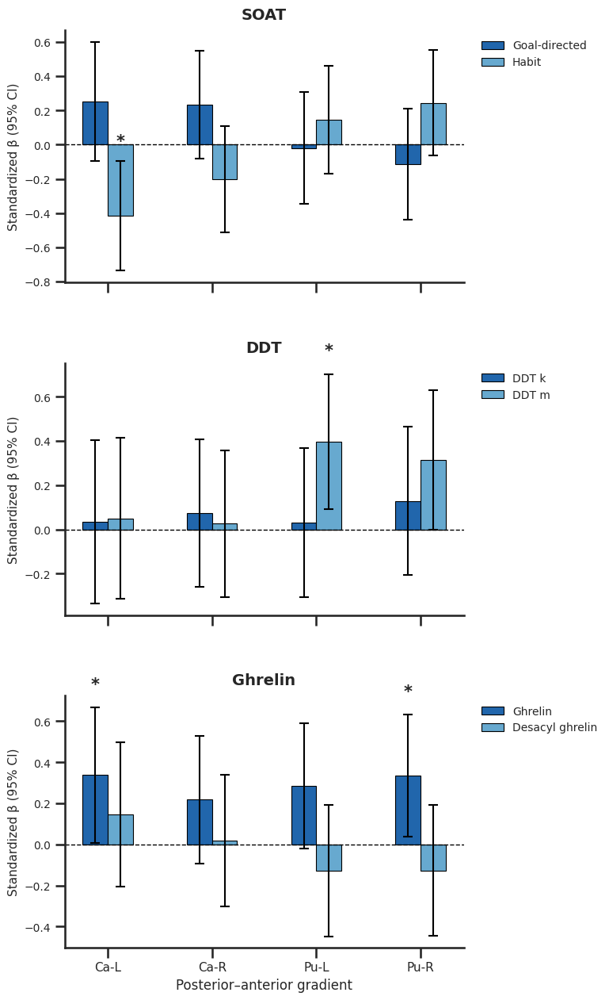

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

gradient_order = [
    "gradient_caudate_L",
    "gradient_caudate_R",
    "gradient_putamen_L",
    "gradient_putamen_R"
]

gradient_labels = ["Ca-L", "Ca-R", "Pu-L", "Pu-R"]

colors = ["#2166ac", "#67a9cf"]

def prepare_results(df, outcome_col, outcomes, n_covariates):
    d = df[
        df["gradient"].isin(gradient_order) &
        df[outcome_col].isin(outcomes)
    ].copy()

    d["beta"] = pd.to_numeric(d["beta_delta_gradient_z"], errors="coerce")
    d["p"] = pd.to_numeric(d["p"], errors="coerce")
    d["p_fdr"] = pd.to_numeric(d["p_fdr"], errors="coerce")

    if {"ci_low", "ci_high"}.issubset(d.columns):
        d["ci_low"] = pd.to_numeric(d["ci_low"], errors="coerce")
        d["ci_high"] = pd.to_numeric(d["ci_high"], errors="coerce")
    else:
        df_resid = d["n"] - n_covariates - 2
        t_abs = t.isf(d["p"].clip(1e-300, 1 - 1e-12) / 2, df_resid)
        se = d["beta"].abs() / t_abs
        t_critical = t.ppf(0.975, df_resid)
        d["ci_low"] = d["beta"] - t_critical * se
        d["ci_high"] = d["beta"] + t_critical * se

    return d



plot_soat = prepare_results(
    res_grad_soat_delta,
    "behavior",
    ["P3_goal_directed_index", "P3_habit_index"],
    n_covariates=1
)
plot_ddt = prepare_results(
    res_grad_clinical_delta,
    "clinical",
    ["ddt_p1_k", "ddt_p1_m"],
    n_covariates=2
)


plot_hormones = prepare_results(
    res_grad_hormone_delta,
    "hormone",
    ["ln_AG", "ln_DAG"],
    n_covariates=2
)


def plot_panel(ax, data, outcome_col, outcomes, labels, title):
    x = np.arange(len(gradient_order))
    width = 0.24

    for i, (outcome, label) in enumerate(zip(outcomes, labels)):
        temp = (
            data[data[outcome_col] == outcome]
            .set_index("gradient")
            .reindex(gradient_order)
        )

        xpos = x + (i - 0.5) * width

        ax.bar(
            xpos,
            temp["beta"],
            width=width,
            color=colors[i],
            edgecolor="black",
            linewidth=0.8,
            label=label,
            zorder=2
        )

        ax.errorbar(
            xpos,
            temp["beta"],
            yerr=np.vstack([
                (temp["beta"] - temp["ci_low"]).to_numpy(),
                (temp["ci_high"] - temp["beta"]).to_numpy()
            ]),
            fmt="none",
            ecolor="black",
            elinewidth=1.5,
            capsize=4,
            capthick=1.5,
            zorder=3
        )

        for xx, (_, row) in zip(xpos, temp.iterrows()):
            if pd.notna(row["p_fdr"]) and row["p_fdr"] < 0.05:
                sig = "**"
            elif pd.notna(row["p"]) and row["p"] < 0.05:
                sig = "*"
            else:
                sig = ""

            if sig:
                ypos = row["ci_high"] + 0.07

                ax.text(
        xx,
        ypos,
        sig,
        ha="center",
        va="bottom",
        fontsize=15,
        fontweight="bold",
        clip_on=False
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=1)

    ax.set_title(title, fontsize=14, fontweight="bold", pad=10)
    ax.set_ylabel("Standardized β (95% CI)", fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(gradient_labels, fontsize=11)
    ax.tick_params(axis="y", labelsize=10)
    ax.grid(False)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        loc="upper left",
        bbox_to_anchor=(1.02, 1),
        frameon=False,
        fontsize=10
    )


fig, axes = plt.subplots(
    3, 1,
    figsize=(8, 13),
    sharex=True,
    gridspec_kw={"hspace": 0.32}
)
plot_panel(axes[0], plot_soat, "behavior",
           ["P3_goal_directed_index", "P3_habit_index"],
           ["Goal-directed", "Habit"], "SOAT")

plot_panel(axes[1], plot_ddt, "clinical",
           ["ddt_p1_k", "ddt_p1_m"],
           ["DDT k", "DDT m"], "DDT")

plot_panel(axes[2], plot_hormones, "hormone",
           ["ln_AG", "ln_DAG"],
           ["Ghrelin", "Desacyl ghrelin"], "Ghrelin")

for ax in axes:
    ax.tick_params(axis="x", labelbottom=False)

axes[-1].tick_params(axis="x", labelbottom=True)
axes[-1].set_xlabel("Posterior–anterior gradient", fontsize=12)

fig.subplots_adjust(
    left=0.14,
    right=0.77,
    top=0.96,
    bottom=0.07,
    hspace=0.32
)

plt.savefig(
    "DDT_SOAT_Ghrelin_combined.svg",
    format="svg",
    bbox_inches="tight"
)

plt.savefig(
    "DDT_SOAT_Ghrelin_combined.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()